# Modeling Work-Disability Onset in Systemic Lupus Erythematosus — update v12

**A dynamic LSTM that gives patients who go on to work disability higher risk scores than those who stay at work,
higher the closer they are to the onset, and low scores to patients who stay at work and look healthy.**

| | |
|---|---|
| **Main model** | **Dynamic LSTM** (DYN): the 6-month calendar grid of the last 2 years, with the patient's current status and its change from the patient's own baseline; **one hazard** fitted on the intervals between visits (update_v10's DYN had a hazard per 6-month band; kept as DYN-bands); each visit scored on its own |
| **Primary metric** | **Time-matched patient AUROC**: each patient's mean 12-month risk over the 12 months before their onset, against every patient still working on the onset date, scored over the same calendar window |
| **Primary comparison** | DYN − **Baseline** (index-visit age, SDI and SLEDAI-2K; current age, education, race, calendar year) |
| **Secondary comparison** | DYN − **LogReg** (logistic regression of the 12-month label on the same inputs as DYN) |
| **Other models** | DYN-bands (update_v10's main model); a band-hazard regression on DYN's inputs; update_v8's main LSTM; a two-part model; update_v7's regression; the average of DYN and its regression; update_v9's design steps |
| **Clinical output** | **Risk tiers** of the 12-month risk (< 1 %, 1-2 %, 2-5 %, ≥ 5 %); the < 1 % tier as a rule-out (Section 13.5) |
| **Validation** | 5 × 5-fold patient-grouped CV (the same folds as update_v2-v11); temporal hold-out (develop before 2012, evaluate from 2012; Section 19.6) |

**Objectives.** (1) Patients who go on to work disability score higher than patients still working on the same
dates. (2) The risk is higher the closer the onset. (3) Patients who stay at work, especially healthy-looking ones,
score low. (4) What drives the LSTM's risk (SHAP).

**Contents.** 1 Motivation · 2-3 Cohort, outcome, competing events · 4 Landmarks, target, horizons · 5 Variables ·
6 Models · 7 Calibration · 8 Validation, objectives and hypotheses · 9 Patient-level evaluation · 10 Limitations ·
11 Code · 12 The models · 13-16 Objectives 1-4 · 17 Summary · 18 Secondary analyses · 19 TRIPOD+AI reporting

**New in update_v12: Section 19, TRIPOD+AI reporting** (no model changes; every fit is update_v11's): dates and
participant flow, Table 1 and missing data, sample size (Riley criteria), fairness (discrimination, calibration and
alarms by sex, race, age and education), performance by length of history, a **temporal hold-out** (develop before
2012 with follow-up truncated there, evaluate from 2012, no recalibration), and the filled-in checklist.

**Changes in update_v11 from update_v10** (post hoc, informed by update_v10's results on the same patients; label
them so):
1. **Main model: one hazard instead of 6-month bands.** In update_v10, S1 (one hazard) had the highest time-matched
   AUROC (0.735 vs DYN-bands 0.726) and adding bands lowered the risk-set C (−0.013, CI −0.023 to −0.003), while the
   change-from-baseline inputs raised the within-patient C (0.643 vs 0.616). The new DYN keeps the change inputs and
   drops the bands. DYN-bands stays as a reference; DYN − DYN-bands is reported (Section 13).
2. **Patient-level thresholds chosen on the time-matched rule.** The time-matched sensitivity and specificity used
   the visit-level threshold; each fold now picks its threshold on the training patients' time-matched pairs (out-of-
   fold risks, max Youden), for every model.
3. **Risk tiers as the clinical output** (Section 13.5): tiers by visit, by patient on the time-matched dates,
   rule-out performance of the lowest tier, movement between tiers, and the recent era.
4. SHAP (Section 16): calendar year reported as a separate adjustment line; a recent-era pass (from update_v10).

The model fits are update_v11's (read from `cv_state_update_v11.pkl`, same folds, checked row by row); only the
temporal hold-out fits are new. `SLE_SMOKE=1` runs a quick test version.

## 1. Motivation

A clinic needs the risk score to do three things for each patient: be **higher in patients who will stop working**
than in those who will not, **rise as the onset approaches**, and **stay low in patients who are well**.
update_v9 built a model aimed at near-term risk (no pooling of scores over 24 months, a hazard per 6-month band,
inputs that describe change from the patient's own baseline). This version evaluates that model against those three
requirements at the patient level, with a patient-level metric that compares patients **on the same dates**, so that
the falling risk over the calendar years (earlier patients had more onsets) cannot inflate it, and explains the
model with SHAP.

## 2. Cohort, data and outcome · 3. Competing events and censoring

Unchanged from update_v7-v9: patients of the lupus clinic with an employed visit before age 65. **Outcome**:
disability benefits, or a sick-leave spell without return to work lasting ≥ 6 months (dated at the spell's start);
re-entry after a return to work. Other exits from work are **competing events**; follow-up is censored at the last
recorded status or age 65; deaths are censored. Visit-level metrics use **inverse-probability-of-censoring weights**.

## 4. Landmarks, training target and horizons

* **Landmarks**: every employed visit before age 65 that is not the patient's last visit.
* **One-hazard target** (DYN, S0, S1, the Baseline, update_v7's regression): an onset and a competing-exit
  log-hazard per landmark, fitted on the interval from the landmark to the next landmark (or the end of follow-up);
  loss d₁η₁ + d₂η₂ − (e^η₁ + e^η₂)Δ; the 12-month risk is the cumulative incidence at a constant hazard.
* **Band-hazard target** (DYN-bands and the band regression): from each landmark, its follow-up to 48 months in eight
  6-month bands, a log-hazard of onset and of competing exit per band; loss Σ_b [d₁ᵦη₁ᵦ + d₂ᵦη₂ᵦ − (e^η₁ᵦ + e^η₂ᵦ)Δᵦ].
* **LogReg**: the complete-case 12-month label (onset within 12 months = 1; followed 12 months without onset, or a
  competing exit first = 0; unresolved landmarks left out).
* **Primary horizon: 12 months** (the risk of an onset in the next 12 months); 6-48 months in the secondary analyses.

## 5. Variables

update_v2's 27 variables and the calendar year on the 6-month grid, plus **change from the patient's own baseline**
(earlier visits only): for SLEDAI-2K, SDI, prednisone, treatment step, visit rate, tender points, fatigue,
arthralgia, dyspnoea, fibromyalgia and acute visits, the value now minus the patient's usual value and the change
over 12 months; the visit gap against the usual gap; new damage in 24 months; months since the last flare; acute
visits in the last 12 months. LogReg and the band regression read the same variables at the landmark visit. The
Baseline reads index-visit age, SDI and SLEDAI-2K, current age, education, race and the calendar year.

## 6. Models

| Model | Input | Target | Role |
|---|---|---|---|
| **DYN** | grid, last 2 years, current + change | one hazard | **main model** (new) |
| DYN-bands | grid, last 2 years, current + change | band hazards | update_v10's main model |
| **Baseline** | index visit + demographics + calendar year | one hazard | **primary comparison** |
| **LogReg** | DYN's inputs at the landmark visit | 12-month binary | **secondary comparison** |
| Reg-DYN | DYN's inputs at the landmark visit | band hazards | same target as DYN, linear |
| S0 v8-main | grid, all history, current status | one hazard, 24-month pool | update_v8's main model |
| Two-part | Baseline offset + LSTM on change only | band hazards | trait and change separated |
| Reg-v7 | visit + last year | one hazard, 24-month pool | update_v7's regression |
| S1, S2 | update_v9's design steps | | secondary (Section 18) |
| Average | DYN + Reg-DYN | | descriptive |

## 7. Calibration

Each model's raw 12-month risk is recalibrated (logistic, intercept + slope) on the training patients' out-of-fold
risks, inside each training fold.

## 8. Validation, objectives and hypotheses

**5 × 5-fold patient-grouped CV**, stratified by ever having an onset; 3 inner folds give the out-of-fold scores for
recalibration and thresholds. 95 % CIs from a patient-cluster bootstrap (1,000 resamples, the same for every model,
so differences are paired). Verdicts for model contrasts: **superior** if the lower 95 % bound > 0, **inferior** if
the upper bound < 0, **equivalent** if the CI lies within ±0.02, otherwise inconclusive.

**Objective 1 — patients who go on to work disability score higher.**

| | Hypothesis | Estimand | Criterion |
|---|---|---|---|
| **H1a (primary)** | DYN separates patients better than the Baseline | DYN − Baseline, time-matched patient AUROC | lower bound > 0 |
| **H1b** | DYN separates patients better than a logistic regression on the same inputs | DYN − LogReg, time-matched patient AUROC | lower bound > 0 |
| **H1c** | The risks match what happened | visit calibration slope and intercept (12 months) | slope 0.8-1.2; intercept CI includes 0 |
| H1d (post hoc) | Dropping the bands does not lose discrimination | DYN − DYN-bands, time-matched patient AUROC | reported (equivalence ±0.02) |

**Objective 2 — the risk is higher the closer the onset.**

| | Hypothesis | Estimand | Criterion |
|---|---|---|---|
| **H2a** | Patients are separated better close to the onset | DYN: time-matched AUROC 0-12 months before onset − 24-36 months before | lower bound > 0 |
| **H2b** | The risk rises within patients before the onset, more than in stayers | DYN: mixed model, extra slope per year in onset patients (year-centred logit) | lower bound > 0 |
| **H2c** | Alarms come early enough to act | DYN: median lead time | lower bound ≥ 3 months |

**Objective 3 — patients who stay at work, especially healthy-looking ones, score low.**

| | Hypothesis | Estimand | Criterion |
|---|---|---|---|
| **H3a** | Healthy-looking stayers are flagged less than other stayers | DYN: share flagged, healthy − other stayers | upper bound < 0 |
| **H3b** | DYN separates onset patients from healthy-looking stayers better than the Baseline | DYN − Baseline, time-matched AUROC vs healthy-looking controls | lower bound > 0 |
| **H3c** | ... and better than LogReg | DYN − LogReg, the same | lower bound > 0 |

**Objective 4 — what drives the LSTM's risk** (descriptive): SHAP by input, domain, grid point, and time before
the onset; stability across folds. Calendar year is an adjustment: its share is reported separately and left out of
the rankings. A second pass explains recent-era landmarks (2012 on) against a recent-era background.

## 9. Patient-level evaluation

* **Time-matched patient AUROC (primary)**: for each onset (date *E*), the patient's mean 12-month risk logit over
  their landmarks in the 12 months before *E*; the controls are every other patient at risk on *E*, each scored by
  their mean over their own landmarks in the same 12 calendar months (or their latest landmark before *E* if none in
  the window). Pairs pooled over onsets. Moving the case window back (0-6 ... 36-48 months before *E*) gives
  Objective 2's curve.
* **Patient sensitivity / specificity**: case or control above the fold's **time-matched threshold**: max Youden over
  the training patients' time-matched pairs, scored with their out-of-fold risks (new in update_v11; update_v10 used
  the visit-level threshold); each onset's controls weighted equally.
* **Risk tiers**: the recalibrated 12-month risk in four fixed tiers (< 1 %, 1-2 %, 2-5 %, ≥ 5 %), at each visit and
  for each patient's mean risk on the time-matched dates.
* **Healthy-looking** at a visit: modified LLDAS, SDI 0, prednisone ≤ 5 mg/day, and none of fatigue, arthralgia,
  dyspnoea or fibromyalgia.
* update_v7/v8's patient windows (24/12 months before the onset vs the last months of event-free follow-up) are
  reported for continuity; they compare different calendar times.

## 10. Known limitations

* About 150 patients with an onset: differences of about 0.03 AUROC are the smallest the design can detect.
* The design was developed on the same patients over many versions (more than 40 notebooks; update_v11's main model
  was chosen after seeing update_v10's results); CV estimates are optimistic by an unknown amount. The temporal
  hold-out (Section 19.6) is the least optimistic estimate, but its evaluation years were also seen in earlier CVs.
* Single centre; no external validation.
* Race and education are model inputs. They capture social determinants of leaving work, but a model that uses them
  can carry existing inequalities into decisions; performance and calibration by group are in Section 19.4.
* An earlier onset-timing screen found that few measured variables move before the onset (damage accrual and visit
  gaps did; laboratory values did not), which limits how much the risk can rise before the onset.
* "Healthy-looking" uses the recorded items only (no patient-reported outcomes, occupation or job demands).
* SHAP uses one CV repeat's refits (the same procedure as the CV, re-run with the networks kept) and attributes the
  12-month onset log-hazard against a background of training landmarks; attributions describe the model, not causes.
  Leaving the calendar year out of the rankings does not remove its interactions with the clinical inputs inside the
  network; the recent-era pass shows the drivers with the era held almost fixed.

---
# 11. Code

## 11.1 Configuration

In [1]:
"""Configuration and shared settings (Sections 2-9). Everything the analysis can change is set here."""
import os, time, pickle, random, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, sparse
from scipy.optimize import brentq
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, message="Mean of empty slice")
pd.set_option("display.width", 200, "display.max_columns", 60, "display.max_rows", 200)

TAG = "update_v12"
SMOKE = os.environ.get("SLE_SMOKE") == "1"          # quick end-to-end test only (not for results)
RAW_PATH = "lupus_merged_visit_level.csv"
OUT_DIR = "figs"
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 240
random.seed(SEED); np.random.seed(SEED)
MONTH_DAYS = 365.25 / 12

# ---------------------------------------------------------------- cohort and outcome (unchanged from update_v7)
SICK_LEAVE_MIN_MONTHS = 6          # a sick-leave spell without return to work is an onset once it lasts this long
ONSET_DATING = "spell_start"       # the onset is dated at the start of that spell
EXTRA_EVENT_EXITS = ()             # no other exit is counted as work disability
EARLY_RETIREMENT_AGE = 60
UNEMPLOYED_STATES = {"looking for work"}
LANDMARKS_AFTER_DISABILITY = True  # a patient who returns to paid work after a disability onset re-enters at the next
                                   # employed visit; a second onset is an event (update_v6)
DEATH_AS_COMPETING_EVENT = False   # a death is censored at the last recorded employment status
DEATH_LINK_DAYS = 365
AGE_CAP_YEARS = 65                 # follow-up ends at age 65; no landmark at >= 65
WORKING_STATES = {"employed"}
SICK_STATES = {"sick leave"}
DISABLED_STATES = {"disabled"}
OTHER_EXIT_STATES = {"retired", "homemaker", "student", "looking for work", "other"}
CAUSE_NAMES = {0: "censored", 1: "work disability", 2: "other exit", 3: "death"}

# ---------------------------------------------------------------- horizons (Section 4)
PRIMARY_HORIZON_MONTHS = 12
HORIZON_DAYS = round(PRIMARY_HORIZON_MONTHS * MONTH_DAYS)
HORIZON_YEARS = HORIZON_DAYS / 365.25
HORIZONS = [6, 12, 18, 24, 30, 36, 42, 48]        # cumulative horizons (months), one fit gives all of them
INTERVALS = [(0, 12), (12, 24), (24, 36), (36, 48)]  # exclusive 12-month intervals (H2c)
H = PRIMARY_HORIZON_MONTHS

# ---------------------------------------------------------------- variables (Section 5): update_v2's 27
V1_VARS = ["age_at_record", "disease_duration_yrs", "SLEDAI2_I", "score_n", "STERAVER_0", "FATIGUE",
           "FIBROMYALGIA", "RACE_BLACK", "RACE_ASIAN", "RACE_OTHER_UNKNOWN", "ARTHRALGIA", "DYSPNOEA",
           "ACUTE_VISIT", "TREAT_STEP", "VISIT_RATE_1Y", "YRS_IN_CLINIC"]
DOMAINS = {
    "Era of care": ["AM_CLASS", "IS_CLASS", "ADV_CLASS", "GC_ERA_PCTL"],
    "Mood / cognition (proxy)": ["SDI_NP"],
    "Pain": ["TENDER_POINTS"],
    "Function": ["MSK_DAMAGE"],
    "Work": ["SICK_MONTHS_PRIOR", "YRS_CONT_EMPLOYED", "EDU_HIGHER"],
    "Smoking": ["SMOKER"],
}
NEW_VARS = [c for cols in DOMAINS.values() for c in cols]
V2_VARS = V1_VARS + NEW_VARS                     # update_v2's 27 (every model except the Baseline)
DERIVED_DOMAINS = {                              # update_v4's derived variables: computed by the shared data code,
    "Disease course": ["LLDAS_NOW", "LLDAS_SHARE", "REMISSION_SHARE", "FLARE_RATE", "MONTHS_SINCE_FLARE"],
    "Damage accrual": ["SDI_RATE", "SDI_NEW_24M"],    # not read by any model (they added nothing in update_v4)
    "Symptom burden": ["SYMPTOM_BURDEN", "TYPE2_DISCORDANT"],
    "Care use": ["GAP_RATIO"],
    "Steroid exposure": ["PRED_GRAMS_CUM", "YRS_PRED_GT75"],
    "Comorbidity": ["BMI", "INFECT_12M", "HYPOTHYROID", "APL_POS"],
}
DERIVED_VARS = [c for cols in DERIVED_DOMAINS.values() for c in cols]
YEAR_COLS = ["CAL_YEAR", "CAL_YEAR_NL"]          # calendar-year adjustment (linear + spline)
VIS_EXTRA = ["LOG_GAP"]                          # log(1 + months since the previous visit)
NUMERIC_TV = ["SLEDAI2_I", "score_n", "STERAVER_0", "TREAT_STEP", "VISIT_RATE_1Y", "GC_ERA_PCTL", "TENDER_POINTS"]
BINARY_TV = ["FATIGUE", "FIBROMYALGIA", "ARTHRALGIA", "DYSPNOEA", "ACUTE_VISIT", "AM_CLASS", "IS_CLASS", "ADV_CLASS"]
SUMMARY_STATS_NUM = ["MIN", "MAX", "MEAN", "SLOPE"]
SUMMARY_STATS_BIN = ["MEAN", "MAX"]


def seq_cols(current):
    """What the LSTM reads at every visit (and the regression at the landmark visit)."""
    return list(current) + YEAR_COLS + VIS_EXTRA


BASELINE_VARS = ["age_at_record", "AGE_INDEX", "SDI_INDEX", "SLEDAI_INDEX", "EDU_HIGHER", "RACE_BLACK",
                 "RACE_ASIAN", "RACE_OTHER_UNKNOWN"] + YEAR_COLS
CAL_YEAR_KNOT_PCTS = (10, 50, 90)

# the regression's window summaries: the last year (update_v4's most robust visit LogReg)
LOOKBACKS = {"12": 12}
LOOKBACK_LABELS = {"12": "last year"}
REG_LOOKBACK = "12"


def visit_summary_cols(current, lb):
    keep = set(current)
    return ([f"{c}__{s}__V{lb}" for c in NUMERIC_TV if c in keep for s in SUMMARY_STATS_NUM]
            + [f"{c}__{s}__V{lb}" for c in BINARY_TV if c in keep for s in SUMMARY_STATS_BIN] + [f"N_VISITS__V{lb}"])


_LOGSUM = ["SLEDAI2_I", "score_n", "STERAVER_0", "VISIT_RATE_1Y", "TENDER_POINTS"]
LOG1P_VARS = ({"STERAVER_0", "score_n", "SLEDAI2_I", "disease_duration_yrs", "VISIT_RATE_1Y", "YRS_IN_CLINIC",
               "SDI_INDEX", "SLEDAI_INDEX", "TENDER_POINTS", "SDI_NP", "MSK_DAMAGE", "SICK_MONTHS_PRIOR",
               "YRS_CONT_EMPLOYED"}
              | {f"{c}__{s}__V{lb}" for c in _LOGSUM for s in ["MIN", "MAX", "MEAN"] for lb in LOOKBACKS}
              | {f"N_VISITS__V{lb}" for lb in LOOKBACKS})
CLIP_Z = 5.0
SLOPE_CLIP = 20.0

# ---------------------------------------------------------------- personal-baseline (change) variables (Section 5)
# For each item: the value now minus the patient's own usual value (the mean of all their EARLIER visits), and minus
# the value 12 months ago (the latest visit at least 12 months before). Earlier visits only.
DEV_ITEMS = ["SLEDAI2_I", "score_n", "STERAVER_0", "TREAT_STEP", "VISIT_RATE_1Y", "TENDER_POINTS", "FATIGUE",
             "ARTHRALGIA", "DYSPNOEA", "FIBROMYALGIA", "ACUTE_VISIT"]
DEV_VARS = ([f"{c}__DEV" for c in DEV_ITEMS] + [f"{c}__CHG12" for c in DEV_ITEMS]
            + ["GAP_RATIO", "SDI_NEW_24M", "MONTHS_SINCE_FLARE", "ACUTE_12M"])
LOG1P_VARS |= {"MONTHS_SINCE_FLARE", "GAP_RATIO", "ACUTE_12M"}

# ---------------------------------------------------------------- the 6-month calendar grid (Section 5)
GRID_STEP_MONTHS = 6
GRID_STEP_DAYS = GRID_STEP_MONTHS * MONTH_DAYS
GRID_MAX_POINTS = 81                             # 40 years of history at most
GRID_INTERP = {"age_at_record", "disease_duration_yrs", "YRS_IN_CLINIC", "CAL_YEAR", "SLEDAI2_I", "STERAVER_0",
               "FATIGUE", "ARTHRALGIA", "DYSPNOEA", "VISIT_RATE_1Y", "GC_ERA_PCTL", "TENDER_POINTS"}
GRID_ANY_IN_BIN = {"ACUTE_VISIT"}
GRID_EXTRA = ["GRID_N_VISITS", "GRID_STALE_MONTHS"]
GRID_COLS = V2_VARS + DEV_VARS + YEAR_COLS + GRID_EXTRA     # every channel the grid holds
GRID_LOOKBACKS = {"ALL": None, "24": 24}         # months of history read (None = all)
GRID_LOOKBACK_LABELS = {"ALL": "all history", "24": "last 2 years"}
LOG1P_VARS |= {"GRID_N_VISITS", "GRID_STALE_MONTHS"}
CUR_COLS = V2_VARS + YEAR_COLS + GRID_EXTRA                # current status (v8's channels)
DYN_COLS = V2_VARS + DEV_VARS + YEAR_COLS + GRID_EXTRA     # + change from the patient's own baseline
CHANGE_COLS = DEV_VARS + GRID_EXTRA                        # change only (the two-part model's dynamic part)

# ---------------------------------------------------------------- the 6-month risk bands (Section 4)
BAND_MONTHS = 6
N_BANDS = 8                                      # 0-6, 6-12, ..., 42-48 months after the landmark

# ---------------------------------------------------------------- models (Section 6)
# Each new model changes ONE thing from the previous one (S0 -> S3), then two alternatives to the main model.
#   input     cur = current status on the grid; dyn = + change from the patient's own baseline; chg = change only
#   hazard    const = one hazard per landmark (v5-v8), fitted on the intervals between landmarks
#             band  = a separate hazard for every 6-month band after the landmark, fitted on the landmark's whole
#                     follow-up to 48 months (landmark supermodel)
#   pool      months of the patient's landmarks averaged into the score (24 = v7/v8's patient-level training)
#   offset    trait = the Baseline's log-hazard (index-visit and demographic risk) added as a fixed offset
MODEL_SPEC = {
    "LSTM_GALL": dict(family="LSTM", input="cur", lookback="ALL", hazard="const", pool=24, offset=None,
                      source="update_v11"),                                   # S0: v8's main model
    "S1_P0":     dict(family="LSTM", input="cur", lookback="24", hazard="const", pool=0, offset=None,
                      source="update_v11"),
    "S2_BAND":   dict(family="LSTM", input="cur", lookback="24", hazard="band", pool=0, offset=None,
                      source="update_v11"),
    "DYN":       dict(family="LSTM", input="dyn", lookback="24", hazard="band", pool=0, offset=None,
                      source="update_v11"),                                  # update_v10's main (DYN-bands)
    "DYN1":      dict(family="LSTM", input="dyn", lookback="24", hazard="const", pool=0, offset=None,
                      source="update_v11"),                                  # MAIN
    "DYN_2PART": dict(family="LSTM", input="chg", lookback="24", hazard="band", pool=0, offset="trait",
                      source="update_v11"),
    "REG_DYN":   dict(family="Reg", input="dyn", lookback=None, hazard="band", pool=0, offset=None,
                      source="update_v11"),
    "LOGREG":    dict(family="Reg", input="dyn", lookback=None, hazard="bin", pool=0, offset=None, target="BIN",
                      source="update_v11"),
    "Reg_TTE_P24": dict(family="Reg", input="reg", lookback=None, hazard="const", pool=24, offset=None,
                        source="update_v11"),
    "Base_TTE_P0": dict(family="Base", input="base", lookback=None, hazard="const", pool=0, offset=None,
                        source="update_v11"),
}
MAIN_MODEL = "DYN1"
DYN_BANDS = "DYN"                     # update_v10's main model (band hazards)
V8_MAIN = "LSTM_GALL"                 # update_v8's main (trait) model
LOGREG = "LOGREG"                     # secondary comparison: logistic regression of the 12-month label, DYN's inputs
REG_DYN = "REG_DYN"
TWO_PART = "DYN_2PART"
REG_MODEL = "Reg_TTE_P24"             # update_v7's regression
BASELINE = "Base_TTE_P0"
ABLATION_CHAIN = [V8_MAIN, "S1_P0", MAIN_MODEL]
REF_MODELS = [m for m, s_ in MODEL_SPEC.items() if s_.get("source")]
NEW_MODELS = [m for m in MODEL_SPEC if m not in REF_MODELS]
FIT_MODELS = list(MODEL_SPEC)
AVG_MODEL = "AVG"
AVG_PARTS = [MAIN_MODEL, REG_DYN]
ALL_MODELS = FIT_MODELS + [AVG_MODEL]
FIG_MODELS = [MAIN_MODEL, BASELINE, LOGREG, DYN_BANDS, REG_DYN, V8_MAIN, TWO_PART]
KEY_MODELS = [MAIN_MODEL, BASELINE, LOGREG]       # the primary and secondary comparisons
TRAIT_ALPHA = 1e-3                    # ridge penalty of the trait offset (the Baseline's variables; few inputs)
V7_STATE_PATH = f"cv_state_update_v7{'_smoke' if SMOKE else ''}.pkl"
V8_STATE_PATH = f"cv_state_update_v8{'_smoke' if SMOKE else ''}.pkl"
V9_STATE_PATH = f"cv_state_update_v9{'_smoke' if SMOKE else ''}.pkl"
V10_STATE_PATH = f"cv_state_update_v10{'_smoke' if SMOKE else ''}.pkl"
V11_STATE_PATH = f"cv_state_update_v11{'_smoke' if SMOKE else ''}.pkl"


def parse_model(m):
    if m == AVG_MODEL:
        return {"family": "AVG", "input": "mixed", "lookback": None, "hazard": "band", "pool": 0, "offset": None,
                "target": "TTE"}
    return {"target": "TTE", **MODEL_SPEC[m]}


def is_grid(m):
    return parse_model(m)["family"] == "LSTM"


def is_seq(m):
    return False                                 # no visit-sequence LSTM in this version


def is_reg(m):
    return parse_model(m)["family"] in ("Reg", "Base")


def is_pooled(m):
    return parse_model(m)["pool"] > 0


def is_band(m):
    return parse_model(m)["hazard"] == "band"


def grid_cols_of(m):
    return {"cur": CUR_COLS, "dyn": DYN_COLS, "chg": CHANGE_COLS}[parse_model(m)["input"]]


_LABELS = {V8_MAIN: "S0: v8's main LSTM (grid, all history, one hazard, 24-month pool)",
           "S1_P0": "S1: S0 without the pool (grid, last 2 years, one hazard, each visit's own score)",
           "S2_BAND": "S2: S1 + a hazard per 6-month band",
           MAIN_MODEL: "Dynamic LSTM: S1 + change from the patient's own baseline, one hazard [MAIN]",
           DYN_BANDS: "DYN-bands: S2 + change from the patient's own baseline (update_v10's main model)",
           TWO_PART: "Two-part: trait offset (Baseline) + LSTM on change only, band hazards",
           REG_DYN: "Regression on the main model's inputs (landmark visit), band hazards",
           REG_MODEL: "update_v7's regression (visit + last year, one hazard, 24-month pool)",
           BASELINE: "Baseline (index visit + demographics), one hazard",
           AVG_MODEL: "Average: dynamic LSTM + dynamic regression",
           LOGREG: "Logistic regression of the 12-month label on the main model's inputs (landmark visit)"}
_SHORT = {V8_MAIN: "S0 v8-main", "S1_P0": "S1 no-pool", "S2_BAND": "S2 bands", MAIN_MODEL: "DYN", DYN_BANDS: "DYN-bands",
          TWO_PART: "Two-part", REG_DYN: "Reg-DYN", REG_MODEL: "Reg-v7", BASELINE: "Baseline", AVG_MODEL: "Average",
          LOGREG: "LogReg"}


def model_label(m):
    return _LABELS.get(m, m)


def short_label(m):
    return _SHORT.get(m, m)


_COLORS = {V8_MAIN: "#7f5a83", "S1_P0": "#c06c84", "S2_BAND": "#e09f3e", MAIN_MODEL: "#d62828", DYN_BANDS: "#f4a261", TWO_PART: "#2a9d8f",
           REG_DYN: "#013a63", REG_MODEL: "#61a5c2", BASELINE: "#7f8c8d", AVG_MODEL: "#000000", LOGREG: "#2a6f97"}


def model_color(m):
    return _COLORS.get(m, "#7f8c8d")


def model_ls(m):
    return "-" if is_band(m) else "--"


LOGREG_C_GRID = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1.0]
POISSON_ALPHA_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]
SEQ_CFG = dict(hidden=32, dropout=0.3, weight_decay=1e-2)
SEQ_TRAIN = dict(lr=2e-3, batch_patients=32, max_epochs=8 if SMOKE else 150, patience=3 if SMOKE else 15,
                 val_share=0.15)
SEQ_SEEDS_INNER = 1
SEQ_SEEDS_FINAL = 1 if SMOKE else 5
SEQ_N_JOBS = int(os.environ.get("SLE_SEQ_JOBS", min(6, max(1, (os.cpu_count() or 2) - 2))))

# ---------------------------------------------------------------- validation (Section 8): same folds as update_v2-v8
CV_N_SPLITS = 3 if SMOKE else 5
CV_N_REPEATS = 1 if SMOKE else 5
CV_INNER_SPLITS = 3
BOOT_N = 100 if SMOKE else 1000
N_CAL_BOOT = min(BOOT_N, 200)
CV_STATE_PATH = f"cv_state_{TAG}{'_smoke' if SMOKE else ''}.pkl"

# ---------------------------------------------------------------- the prespecified protocol (Section 8.1)
EQUIV_MARGIN = 0.02
LEAD_TIME_MIN_MONTHS = 3                         # H1c (12-month horizon)
CAL_SLOPE_RANGE = (0.8, 1.2)
H1D_RANGE = (0.01, 0.05)                         # H1d: thresholds of 12-month risk
NB_GRID = np.round(np.arange(0.005, 0.0801, 0.0025), 4)
FIXED_RISKS = [0.02, 0.05]
RISK_TIERS = [(0.0, 0.01, "< 1 %"), (0.01, 0.02, "1-2 %"), (0.02, 0.05, "2-5 %"), (0.05, 1.01, ">= 5 %")]
RULE_OUT_TIERS = [(0.0, 0.01, "below 1 %"), (0.0, 0.02, "below 2 %")]   # cumulative: the rule-out use
TIER_RECENT_FROM = 2012                          # the recent era (the period closest to use)

# ---------------------------------------------------------------- decisions and alarms (Section 9)
THRESHOLD_RULES = ["cost", "ppv"]
THRESHOLD_LABELS = {"cost": "Max Youden (cost-weighted, R = (1 - pi) / pi)", "ppv": "Max PPV (sensitivity >= 25%)"}
MAIN_THRESHOLD = "cost"
PPV_MIN_SENS = 0.25
PATIENT_RULES = ["meanlogit", "run2"]
PATIENT_RULE_LABELS = {"meanlogit": "mean logit over the window", "run2": "2 consecutive alarms"}
MAIN_PATIENT_RULE = "meanlogit"
PATIENT_WINDOW_MONTHS = 24                       # window length (at the 12-month horizon: 12 months)
ASSESS_SCHEDULES = {"visit": 0, "6 months": 6, "12 months": 12}
ALARM_RULE_LABELS = {"level": "risk above the threshold", "confirmed": "above the threshold twice in a row",
                     "rise": "rise above the patient's own usual risk", "level_or_rise": "level or rise"}
EWMA_LAMBDA = 0.3                                # the patient's usual risk: EWMA of their earlier scores
WITHIN_NEAR_MONTHS, WITHIN_FAR_MONTHS = 12, 24   # within-patient C: <= 12 months before onset vs > 24 months before
CAL_WINDOW_YEARS, CAL_WINDOW_STEP = 4, 1
CAL_WINDOW_MIN_ONSETS = 10
ERA_BANDS = [(1900, 2000, "< 2000"), (2000, 2006, "2000-05"), (2006, 2012, "2006-11"), (2012, 2100, ">= 2012")]
AGE_BANDS = [(0, 40, "< 40"), (40, 50, "40-49"), (50, 60, "50-59"), (60, 200, ">= 60")]
H2D_MIN_PRIOR_VISITS = 18
H2D_MIN_YEARS_IN_CLINIC = 10
H2D_GAP_VISITS = 8
H2D_FLARE_MONTHS = 12

# ---------------------------------------------------------------- patient-level objectives (Sections 9 and 13-16)
TM_WINDOW_MONTHS = 12                            # time-matched patient AUROC: the 12 months before each onset
TTO_BINS = [(0, 6), (6, 12), (12, 24), (24, 36), (36, 48)]   # months before the onset (Objective 2)
H2A_NEAR, H2A_FAR = (0, 12), (24, 36)            # H2a: AUROC 0-12 months before onset minus 24-36 months before
TRAJ_MAX_MONTHS = 48
# "healthy-looking": low disease activity (modified LLDAS), no damage, prednisone <= 5 mg/day, and no fatigue,
# arthralgia, dyspnoea or fibromyalgia recorded at the visit
HEALTHY_PRED_MAX = 5.0
FP_PROFILE_VARS = ["age_at_record", "SLEDAI2_I", "score_n", "STERAVER_0", "FATIGUE", "FIBROMYALGIA", "ARTHRALGIA",
                   "DYSPNOEA", "TENDER_POINTS", "VISIT_RATE_1Y", "ACUTE_12M", "EDU_HIGHER", "YRS_IN_CLINIC", "CAL_YEAR"]
# SHAP (Objective 4): the main model refitted on the outer folds of CV repeat 1 with its networks kept
SHAP_REPEAT = 0
SHAP_N_EXPLAIN = 300 if SMOKE else 1500          # test landmarks explained per fold (all near-onset ones + a sample)
SHAP_N_BACKGROUND = 50 if SMOKE else 200
SHAP_SAMPLES = 50 if SMOKE else 200
SHAP_PATH = f"shap_{TAG}{'_smoke' if SMOKE else ''}.pkl"

print(f"{TAG}{' | SMOKE TEST' if SMOKE else ''} | main: {model_label(MAIN_MODEL)} | primary horizon {H} months | "
      f"CV {CV_N_REPEATS} x {CV_N_SPLITS}-fold | {len(NEW_MODELS)} new models + {len(REF_MODELS)} references + average")

update_v12 | main: Dynamic LSTM: S1 + change from the patient's own baseline, one hazard [MAIN] | primary horizon 12 months | CV 5 x 5-fold | 0 new models + 10 references + average


## 11.2 Data: visits, outcome and landmarks

The cohort, the outcome, the competing events and the landmarks are built exactly as in update_v7 (the code is
copied from it, including re-entry after a disability onset); the 12-month label as update_v2. (update_v4's derived variables and update_v6's composites are still computed by this shared code, but no
model reads them.)

In [2]:
"""Visit-level variables, competing-risk outcome, landmarks and the 12-month label (Sections 2 and 4)."""
STALE_MONTHS = 12
STALE_CONT = ["LOG_ESR", "LOG_HS_CRP", "C3", "C4", "BP_SYSTOLIC", "BP_DIASTOLIC", "WEIGHT_KG", "EGFR", "BMI"]
CHANGE_SYMPTOMS = ["FATIGUE", "ARTHRALGIA", "DYSPNOEA", "HEADACHE", "CHEST_PAIN", "WEIGHT_LOSS", "ALOPECIA"]
FLARE_MILD_INCREASE, FLARE_SEVERE_INCREASE = 3, 10
ACUTE_STEROID_INCREASE = 5
TREATMENT_DOSE_MAP = {"STERAVER": "STERAVER_0", "STPULSE": "STPULSE_0", "AMDOSE": "AMDOSE_0",
                      "IS_IMURAN_DOSE": "IS_IMURAN_DOSE_0", "IS_MYCOPHENOLATE_DOSE": "IS_MYCOPHENOLATE_DOSE_0",
                      "IS_METHOTREXATE_DOSE": "IS_METHOTREXATE_DOSE_0"}

COMPOSITE_LABELS = {
    "AE_GC_DAMAGE": "Glucocorticoid-attributable damage (cataract, AVN, osteoporotic fracture, diabetes; SDI points)",
    "AE_OTHER_TX_DAMAGE": "Other treatment-attributable damage (gonadal failure, malignancy, retinal; SDI points)",
    "AE_NEW_12M": "Treatment adverse events, last 12 months (new damage item, new AVN, fracture, infection)",
    "SDI_NON_TX": "SDI damage not attributable to treatment",
    "LAB_COMPLEMENT_LOW": "Low C3, C4 or CH50", "LAB_DSDNA": "Raised anti-dsDNA",
    "LAB_INFLAM": "Raised CRP, hs-CRP or ESR > 30",
    "LAB_RENAL": "Renal laboratory abnormality (creatinine, CrCl, proteinuria, casts, haematuria, pyuria)",
    "LAB_CYTOPENIA": "Leukopenia or thrombocytopenia", "LAB_ABN_COUNT": "Abnormal laboratory domains (0-5)",
    "LAB_ABN_12M": "Share of the last 12 months' visits with an abnormal laboratory domain",
    "IMMUNOSUPPRESSED": "Any immunosuppressant (conventional or advanced)",
    "YRS_AM": "Years on an antimalarial", "YRS_IS": "Years on a conventional immunosuppressant",
    "YRS_ADV": "Years on an advanced therapy", "TX_ERA_PCTL": "Treatment step, percentile within its calendar year"}
DISPLAY_NAMES = {
    "age_at_record": "Age", "disease_duration_yrs": "Disease duration (yrs)", "SLEDAI2_I": "SLEDAI-2K",
    "score_n": "SDI damage score", "STERAVER_0": "Prednisone, average dose since last visit (mg/day)",
    "FATIGUE": "Fatigue", "FIBROMYALGIA": "Fibromyalgia", "RACE_BLACK": "Race: Black",
    "RACE_ASIAN": "Race: Asian (Chinese, Filipino)", "RACE_OTHER_UNKNOWN": "Race: other / mixed / not recorded",
    "ARTHRALGIA": "Arthralgia", "DYSPNOEA": "Dyspnoea",
    "ACUTE_VISIT": "Acute visit (pulse, steroid increase or new immunosuppressant)",
    "TREAT_STEP": "EULAR treatment step (0-4)", "VISIT_RATE_1Y": "Clinic visits per year, last 12 mo",
    "YRS_IN_CLINIC": "Years since the first clinic visit", "CAL_YEAR": "Calendar year (adjustment)",
    "CAL_YEAR_NL": "Calendar year, spline term (adjustment)", "N_PRIOR_VISITS": "Clinic visits so far",
    "AGE_INDEX": "Age at index visit", "SDI_INDEX": "SDI at index visit", "SLEDAI_INDEX": "SLEDAI-2K at index visit",
    "EDU_HIGHER": "Education: higher", "GAP": "Visit gap",
    "AM_CLASS": "Antimalarial (HCQ; chloroquine in earlier years)",
    "IS_CLASS": "Conventional immunosuppressant (AZA, MTX, MMF)",
    "ADV_CLASS": "Advanced therapy (IV CYC; later biologics)",
    "GC_ERA_PCTL": "Prednisone dose, percentile within its calendar year",
    "SDI_NP": "SDI neuropsychiatric damage", "TENDER_POINTS": "Fibromyalgia tender points (0-18)",
    "MSK_DAMAGE": "SDI musculoskeletal damage", "SICK_MONTHS_PRIOR": "Months on sick leave before",
    "YRS_CONT_EMPLOYED": "Years continuously employed", "SMOKER": "Current smoker",
    "LOG_GAP": "Months since the previous visit (log)",
    "LLDAS_NOW": "In low disease activity state (modified LLDAS) now",
    "LLDAS_SHARE": "Share of visits so far in modified LLDAS",
    "REMISSION_SHARE": "Share of visits so far in clinical remission",
    "FLARE_RATE": "Flares per year in clinic so far", "MONTHS_SINCE_FLARE": "Months since the last flare",
    "SDI_RATE": "SDI accrual per year in clinic", "SDI_NEW_24M": "New damage in the last 24 months",
    "SYMPTOM_BURDEN": "Non-inflammatory symptom count (0-7)",
    "TYPE2_DISCORDANT": "Symptoms with low activity (>= 2 symptoms, clinical SLEDAI <= 2)",
    "GAP_RATIO": "Visit gap / the patient's usual gap", "PRED_GRAMS_CUM": "Cumulative prednisone (g)",
    "YRS_PRED_GT75": "Years on prednisone > 7.5 mg/day", "BMI": "Body-mass index",
    "INFECT_12M": "Infection recorded in the last 12 months", "HYPOTHYROID": "Hypothyroidism (ever)",
    "APL_POS": "Antiphospholipid antibody positive (ever; LA or aCL)",
}
DISPLAY_NAMES.update(COMPOSITE_LABELS)
DISPLAY_NAMES["ACUTE_12M"] = "Acute visits, last 12 months"
_STAT_NAMES = {"MIN": "minimum", "MAX": "maximum", "MEAN": "mean", "SLOPE": "slope per year"}
_BIN_NAMES = {"MEAN": "share of visits", "MAX": "ever"}
SHORT_NAMES = {"STERAVER_0": "Prednisone", "VISIT_RATE_1Y": "Visit rate", "TREAT_STEP": "EULAR step",
               "score_n": "SDI", "SLEDAI2_I": "SLEDAI-2K", "ACUTE_VISIT": "Acute visit",
               "GC_ERA_PCTL": "Prednisone era-percentile", "TENDER_POINTS": "Tender points",
               "AM_CLASS": "Antimalarial", "IS_CLASS": "Conventional immunosuppressant",
               "ADV_CLASS": "Advanced therapy"}
for lb in LOOKBACKS:
    for c in NUMERIC_TV:
        for s in SUMMARY_STATS_NUM:
            DISPLAY_NAMES[f"{c}__{s}__V{lb}"] = (f"{SHORT_NAMES.get(c, DISPLAY_NAMES[c])}, {_STAT_NAMES[s]}, "
                                                 f"{LOOKBACK_LABELS[lb]}")
    for c in BINARY_TV:
        for s in SUMMARY_STATS_BIN:
            DISPLAY_NAMES[f"{c}__{s}__V{lb}"] = (f"{SHORT_NAMES.get(c, DISPLAY_NAMES[c])}, {_BIN_NAMES[s]}, "
                                                 f"{LOOKBACK_LABELS[lb]}")
    DISPLAY_NAMES[f"N_VISITS__V{lb}"] = f"Visits, {LOOKBACK_LABELS[lb]}"
FEATURE_GROUP = {"age_at_record": "Demographics", "RACE_BLACK": "Demographics", "RACE_ASIAN": "Demographics",
                 "RACE_OTHER_UNKNOWN": "Demographics", "disease_duration_yrs": "Disease course",
                 "SLEDAI2_I": "Disease activity", "score_n": "Damage", "STERAVER_0": "Treatment",
                 "TREAT_STEP": "Treatment", "ACUTE_VISIT": "Treatment", "FATIGUE": "Symptoms",
                 "FIBROMYALGIA": "Symptoms", "ARTHRALGIA": "Symptoms", "DYSPNOEA": "Symptoms",
                 "VISIT_RATE_1Y": "Care pattern", "YRS_IN_CLINIC": "Care pattern", "GAP": "Care pattern",
                 "CAL_YEAR": "Calendar year", "CAL_YEAR_NL": "Calendar year"}
FEATURE_GROUP.update({c: k for k, cols in DOMAINS.items() for c in cols})
FEATURE_GROUP.update({c: k for k, cols in DERIVED_DOMAINS.items() for c in cols})
FEATURE_GROUP["LOG_GAP"] = "Care pattern"
for _c in DEV_ITEMS:
    DISPLAY_NAMES[f"{_c}__DEV"] = f"{SHORT_NAMES.get(_c, DISPLAY_NAMES[_c])}: now minus own usual"
    DISPLAY_NAMES[f"{_c}__CHG12"] = f"{SHORT_NAMES.get(_c, DISPLAY_NAMES[_c])}: change over 12 months"
for _c in DEV_VARS:
    FEATURE_GROUP[_c] = "Change from own baseline"
for _c in GRID_EXTRA:
    FEATURE_GROUP[_c] = "Care pattern"
DISPLAY_NAMES.update({"GRID_N_VISITS": "Visits in the last 6 months", "GRID_STALE_MONTHS": "Months since the last visit"})


def _rolling_by_patient(df, col, window, how):
    s = df.set_index("ASSDT").groupby("PTNO", sort=False)[col].rolling(window, min_periods=1)
    return pd.Series(getattr(s, how)().values, index=df.index)


def cal_year_nl(year, knots):
    """Nonlinear term of a 3-knot restricted cubic spline of the calendar year (Harrell)."""
    k1, k2, k3 = knots
    p3 = lambda u: np.maximum(u, 0.0) ** 3
    x = np.asarray(year, float)
    return (p3(x - k1) - p3(x - k2) * (k3 - k1) / (k3 - k2) + p3(x - k3) * (k2 - k1) / (k3 - k2)) / (k3 - k1) ** 2


def load_visits(path=RAW_PATH):
    """The visit-level variables of revised_v31 that the models read (this and earlier visits only)."""
    df = pd.read_csv(path, low_memory=False)
    audit = {"raw_rows": len(df), "raw_patients": df["PTNO"].nunique(dropna=True)}
    for c in ["ASSDT", "DATEOFDX", "DEATHDT", "BIRTHDT"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    df = df.dropna(subset=["PTNO", "ASSDT"]).drop_duplicates(["PTNO", "ASSDT"], keep="first")
    df = df.sort_values(["PTNO", "ASSDT"]).reset_index(drop=True)
    df["EMP"] = df["EMP"].astype(str).str.strip().str.lower()
    audit["usable_rows"], audit["usable_patients"] = len(df), df["PTNO"].nunique()
    g = df.groupby("PTNO", sort=False)

    df["age_at_record"] = df["AGE_AT_VISIT_YEARS"]
    df["score_n"] = df["SDI_TOTAL"]
    df["disease_duration_yrs"] = (df["ASSDT"] - df["DATEOFDX"]).dt.days / 365.25
    df["CAL_YEAR"] = df["ASSDT"].dt.year + (df["ASSDT"].dt.dayofyear - 1) / 365.25
    for src, dst in TREATMENT_DOSE_MAP.items():                      # empty dose = not on the drug
        df[dst] = pd.to_numeric(df[src], errors="coerce").fillna(0.0)
    df["ON_STEROID"] = (df["STERAVER_0"] > 0).astype(float)
    df["ON_ANTIMALARIAL"] = (df["AMDOSE_0"] > 0).astype(float)
    df["ON_AZA"] = (df["IS_IMURAN_DOSE_0"] > 0).astype(float)
    df["ON_MMF"] = (df["IS_MYCOPHENOLATE_DOSE_0"] > 0).astype(float)
    df["ON_CYC"] = df[["IS_CYCLOPHOSPHAMIDE_METH", "IS_CYCLOPHOSPHAMIDE_DATE", "IS_CYCLOPHOSPHAMIDE_DOSE",
                       "IS_CYCLOPHOSPHAMIDE_AVER"]].notna().any(axis=1).astype(float)
    df["ON_MTX"] = (df["IS_METHOTREXATE_DOSE_0"] > 0).astype(float)
    df["ON_BIOLOGIC"] = pd.to_numeric(df["HAS_BIOLOGIC_REC"], errors="coerce").fillna(0.0).clip(0, 1)
    for name, cols in [("RIT_NOW", ["RIT", "BIOG_RIT"]), ("BEL_NOW", ["BEL", "BIOG_BEL"])]:
        df[name] = np.column_stack([pd.to_numeric(df[c], errors="coerce").eq(1) for c in cols]).any(axis=1).astype(float)

    # sociodemographics (patient-constant)
    race = df["RACE_LABEL"]
    df["SEX_FEMALE"] = np.where(df["SEX"].isna(), np.nan, (df["SEX"] == "F").astype(float))
    for col, lab in [("RACE_BLACK", ["Black"]), ("RACE_CHINESE", ["Chinese"]), ("RACE_FILIPINO", ["Filipino"]),
                     ("RACE_OTHER", ["Other", "Mixed", "Native North American"])]:
        df[col] = np.where(race.isna(), np.nan, race.isin(lab).astype(float))
    df["EDU_HIGHER"] = df["DS_MAX_EDU"].astype(float)
    demo = ["SEX_FEMALE", "RACE_BLACK", "RACE_CHINESE", "RACE_FILIPINO", "RACE_OTHER", "EDU_HIGHER"]
    df[demo] = g[demo].transform(lambda s: s.ffill().bfill())
    known = df["RACE_BLACK"].notna()
    df["RACE_BLACK"] = df["RACE_BLACK"].fillna(0.0)
    df["RACE_ASIAN"] = (df["RACE_CHINESE"].fillna(0.0) + df["RACE_FILIPINO"].fillna(0.0)).clip(0, 1)
    df["RACE_OTHER_UNKNOWN"] = np.where(known, df["RACE_OTHER"], 1.0)
    df["RACE_GROUP"] = np.select([df["RACE_BLACK"] == 1, df["RACE_ASIAN"] == 1, df["RACE_OTHER_UNKNOWN"] == 1],
                                 ["Black", "Asian", "Other / not recorded"], "White")

    # clinic items: last observation carried forward
    sledai_recorded = df["SLEDAI2_I"].notna()
    locf = ["SLEDAI2_I", "FATIGUE", "FIBROMYA", "ARTHRALG", "DYSPNEA"]
    for c in locf:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[locf] = g[locf].ffill()
    df["SDI_TOTAL"] = g["SDI_TOTAL"].ffill()
    df["score_n"] = df["SDI_TOTAL"]
    df["FATIGUE"] = (df["FATIGUE"] > 0).astype(float).where(df["FATIGUE"].notna())
    df["FIBROMYALGIA"] = (df["FIBROMYA"] > 0).astype(float).where(df["FIBROMYA"].notna())
    df["ARTHRALGIA"] = (df["ARTHRALG"] > 0).astype(float).where(df["ARTHRALG"].notna())
    df["DYSPNOEA"] = (df["DYSPNEA"] > 0).astype(float).where(df["DYSPNEA"].notna())

    # care pattern
    gap_days = g["ASSDT"].diff().dt.days
    df["DAYS_SINCE_LAST_VISIT"] = gap_days
    df["YRS_IN_CLINIC"] = (df["ASSDT"] - g["ASSDT"].transform("min")).dt.days / 365.25
    tmp = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "one": 1.0})
    n1y = _rolling_by_patient(tmp, "one", "365D", "sum")
    obs_days = (df["ASSDT"] - g["ASSDT"].transform("min")).dt.days.clip(lower=90, upper=365)
    df["VISIT_RATE_1Y"] = n1y * 365.0 / obs_days                 # visits per year of OBSERVED time, last 12 months

    # flares (description only) and acute care at the visit
    sled = df["SLEDAI2_I"].fillna(0.0)
    delta = sled - sled.groupby(df["PTNO"]).shift(1)
    df["FLARE_AT_VISIT"] = (sledai_recorded & (delta > FLARE_MILD_INCREASE)).astype(float)
    prev_dose = g["STERAVER_0"].shift(1).fillna(0.0)
    df["STEROID_DELTA"] = df["STERAVER_0"] - prev_dose
    acute = (df["STPULSE_0"] > 0).astype(float) + (df["STEROID_DELTA"] >= ACUTE_STEROID_INCREASE).astype(float)
    for c in ["ON_AZA", "ON_MMF", "ON_MTX", "ON_BIOLOGIC"]:
        acute += ((df[c] == 1) & (g[c].shift(1) == 0)).astype(float)
    df["ACUTE_VISIT"] = (acute > 0).astype(float)

    # EULAR 2023 treatment step: 0 none; 1 antimalarial and/or GC <= 5; 2 conventional IS or GC > 5-7.5;
    # 3 GC > 7.5-30; 4 biologic, cyclophosphamide, GC > 30 or a pulse
    gc = df["STERAVER_0"].astype(float)
    pulse = df["STPULSE_0"] > 0
    conv = ((df["ON_AZA"] > 0) | (df["ON_MMF"] > 0) | (df["ON_MTX"] > 0)
            | (pd.to_numeric(df["IS_CYCLOSPORIN_DOSE"], errors="coerce").fillna(0.0) > 0) | df["IS_OTHER_DATE"].notna())
    bio = (df["ON_BIOLOGIC"] > 0) | (df["RIT_NOW"] > 0) | (df["BEL_NOW"] > 0)
    df["TREAT_STEP"] = np.select([(df["ON_CYC"] > 0) | bio | (gc > 30) | pulse, gc > 7.5, conv | (gc > 5),
                                  (df["ON_ANTIMALARIAL"] > 0) | (gc > 0)], [4, 3, 2, 1], 0).astype(float)

    # ---- new in update_v2 (Section 3.1); this and earlier visits only
    # era of care: drug classes whose standard drug changed over the years, so the variable means the same in every era
    #   antimalarial: hydroxychloroquine, or chloroquine where it was used (the majority of antimalarial visits
    #   before 1995, ~2 % after 2015); conventional immunosuppressant: azathioprine, methotrexate, mycophenolate
    #   (MMF replaced AZA from ~2000); advanced therapy: IV cyclophosphamide, later biologics (rituximab, belimumab,
    #   others); prednisone: the dose as a percentile of all clinic visits' doses in the same calendar year (the
    #   median dose fell from 5 mg/day to 0 after 2010)
    df["AM_CLASS"] = df["ON_ANTIMALARIAL"]
    df["IS_CLASS"] = ((df["ON_AZA"] + df["ON_MMF"] + df["ON_MTX"]
                       + (pd.to_numeric(df["IS_CYCLOSPORIN_DOSE"], errors="coerce").fillna(0.0) > 0)) > 0).astype(float)
    df["ADV_CLASS"] = ((df["ON_CYC"] + df["ON_BIOLOGIC"] + df["RIT_NOW"] + df["BEL_NOW"]) > 0).astype(float)
    df["GC_ERA_PCTL"] = df.groupby(df["ASSDT"].dt.year)["STERAVER_0"].rank(pct=True)
    # mood / cognition (no depression, anxiety or PRO field in the data): SDI neuropsychiatric damage domain
    # (cognitive impairment, psychosis, seizures, stroke, neuropathy, myelitis); pain: fibromyalgia tender points
    # (0-18); function: SDI musculoskeletal damage domain (atrophy, deforming arthritis, osteoporotic fracture,
    # avascular necrosis, osteomyelitis, tendon rupture); smoking: current smoker. Carried forward.
    for src, dst in [("SDI_DOM_NEUROPSYCHIATRIC", "SDI_NP"), ("TPCOUNT", "TENDER_POINTS"),
                     ("SDI_DOM_MUSCULOSKELETAL", "MSK_DAMAGE"), ("CIGSMOK", "SMOKER")]:
        df[dst] = pd.to_numeric(df[src], errors="coerce")
    df[["SDI_NP", "TENDER_POINTS", "MSK_DAMAGE", "SMOKER"]] = g[["SDI_NP", "TENDER_POINTS", "MSK_DAMAGE",
                                                                  "SMOKER"]].ffill()
    df["SMOKER"] = (df["SMOKER"] > 0).astype(float).where(df["SMOKER"].notna())
    # work history from the recorded employment status at the visits before this one
    nxt = g["ASSDT"].shift(-1)
    sick = (df["EMP"].isin(SICK_STATES)).astype(float)
    sick_mo = sick * ((nxt - df["ASSDT"]).dt.days / MONTH_DAYS).clip(upper=12).fillna(0.0)
    df["SICK_MONTHS_PRIOR"] = sick_mo.groupby(df["PTNO"]).cumsum() - sick_mo     # months on sick leave before
    working = df["EMP"].isin(WORKING_STATES)
    block = (~working).astype(int).groupby(df["PTNO"]).cumsum()
    run_start = df["ASSDT"].where(working).groupby([df["PTNO"], block]).transform("min")
    df["YRS_CONT_EMPLOYED"] = ((df["ASSDT"] - run_start).dt.days / 365.25).where(working, 0.0)

    # ---- derived variables, new in update_v4 (Section 3.1); this and earlier visits only
    df["LOG_GAP"] = np.log1p(gap_days.fillna(0.0) / MONTH_DAYS)
    num = lambda c: pd.to_numeric(df[c], errors="coerce")
    first_visit = g.cumcount() == 0
    yrs_obs = df["YRS_IN_CLINIC"].clip(lower=1.0)                   # rates per year, at least 1 year of follow-up
    # disease course: modified LLDAS (no physician global in the data): SLEDAI-2K <= 4, no renal / CNS / vasculitis /
    # serositis / fever activity, no new activity (SLEDAI rise > 3), prednisone <= 7.5 mg/day; clinical remission:
    # SLEDAI-2K without the serology items = 0 and prednisone <= 5 mg/day. Shares are over the visits so far.
    major = sum(num(c).fillna(0.0) for c in ["SLEDAI_DOM_RENAL_ANY", "SLEDAI_DOM_CNS_ANY", "SLEDAI_DOM_VASCULAR_ANY",
                                             "SLEDAI_DOM_SEROSITIS_ANY", "SLEDAI_FEVER"]) > 0
    clin_sledai = (df["SLEDAI2_I"].fillna(0.0) - 2 * num("SLEDAI_LOW_COMPLEMENT").fillna(0.0)
                   - 2 * num("SLEDAI_INCREASED_DNA_BINDING").fillna(0.0)).clip(lower=0.0)
    df["LLDAS_NOW"] = ((df["SLEDAI2_I"].fillna(0.0) <= 4) & ~major & (df["FLARE_AT_VISIT"] == 0)
                       & (df["STERAVER_0"] <= 7.5)).astype(float)
    remission = ((clin_sledai == 0) & (df["STERAVER_0"] <= 5)).astype(float)
    df["LLDAS_SHARE"] = df["LLDAS_NOW"].groupby(df["PTNO"]).cumsum() / (g.cumcount() + 1)
    df["REMISSION_SHARE"] = remission.groupby(df["PTNO"]).cumsum() / (g.cumcount() + 1)
    # flares: SLEDAI rise > 3 or prednisone increase >= 5 mg/day (not at the first visit)
    flare = (((df["FLARE_AT_VISIT"] == 1) | (df["STEROID_DELTA"] >= ACUTE_STEROID_INCREASE)) & ~first_visit)
    df["FLARE_RATE"] = flare.astype(float).groupby(df["PTNO"]).cumsum() / yrs_obs
    last_flare = df["ASSDT"].where(flare).groupby(df["PTNO"]).ffill()
    since_first = df["YRS_IN_CLINIC"] * 12                          # no flare yet: the flare-free time observed
    df["MONTHS_SINCE_FLARE"] = ((df["ASSDT"] - last_flare).dt.days / MONTH_DAYS).fillna(since_first)
    # damage accrual
    df["SDI_RATE"] = (df["score_n"] - g["score_n"].transform("first")).clip(lower=0) / yrs_obs
    tmp_sdi = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "sdi": df["score_n"]})
    df["SDI_NEW_24M"] = (df["score_n"] - _rolling_by_patient(tmp_sdi, "sdi", "730D", "min") > 0).astype(float)
    # non-inflammatory symptom burden ("type 2 SLE"): fatigue, arthralgia, dyspnoea, headache, chest pain, proximal
    # muscle weakness, weight loss (each carried forward); discordance = >= 2 symptoms with clinical SLEDAI <= 2
    extra = [f"_{c}" for c in ["HEADACHE", "CHEST_PAIN", "PMWEAK", "WTLOSS"]]
    for c in extra:
        df[c] = num(c[1:])
    df[extra] = g[extra].ffill()
    symp = (df[["FATIGUE", "ARTHRALGIA", "DYSPNOEA"]].fillna(0.0) > 0).sum(1) + (df[extra].fillna(0.0) > 0).sum(1)
    df["SYMPTOM_BURDEN"] = symp.astype(float)
    df["TYPE2_DISCORDANT"] = ((symp >= 2) & (clin_sledai <= 2)).astype(float)
    # care use: this gap against the patient's median earlier gap (1 when there is no earlier gap)
    usual = gap_days.groupby(df["PTNO"]).transform(lambda s: s.expanding().median().shift(1))
    df["GAP_RATIO"] = (gap_days / usual.where(usual > 0)).fillna(1.0).clip(upper=20.0)
    # steroid exposure: average dose since the last visit x the interval (capped at 1 year)
    span = gap_days.fillna(0.0).clip(upper=365.0)
    df["PRED_GRAMS_CUM"] = (df["STERAVER_0"] * span).groupby(df["PTNO"]).cumsum() / 1000.0
    df["YRS_PRED_GT75"] = ((df["STERAVER_0"] > 7.5) * span).groupby(df["PTNO"]).cumsum() / 365.25
    # comorbidity: BMI (adult height is stable, so a patient's recorded height is carried both ways; weight carried
    # forward; implausible values removed), infection in the last 12 months, hypothyroidism ever, antiphospholipid
    # antibody ever positive (missing until first tested)
    h = num("HEIGHT").where(lambda x: x.between(120, 210)).groupby(df["PTNO"]).transform(lambda s: s.ffill().bfill())
    w = num("WEIGHT").where(lambda x: x.between(30, 250)).groupby(df["PTNO"]).ffill()
    df["BMI"] = (w / (h / 100) ** 2).clip(12, 70)
    tmp_inf = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"],
                            "inf": (num("INFECT").fillna(0.0) > 0).astype(float)})
    df["INFECT_12M"] = _rolling_by_patient(tmp_inf, "inf", "365D", "max")
    df["HYPOTHYROID"] = (num("HYPOTHYR").fillna(0.0) > 0).astype(float).groupby(df["PTNO"]).cummax()
    tested = num("LA").notna() | num("ACL_N").notna()
    pos = ((num("LA") == 1) | (num("ACL_N") == 1)).astype(float).where(tested)
    df["APL_POS"] = pos.groupby(df["PTNO"]).cummax()
    df["APL_POS"] = df["APL_POS"].groupby(df["PTNO"]).ffill()

    # ---- change from the patient's own baseline, new in update_v9 (Section 5); this and earlier visits only
    df = df.copy()
    g = df.groupby("PTNO", sort=False)
    tmp12 = pd.DataFrame({"PTNO": df["PTNO"].values, "key": df["ASSDT"] - pd.Timedelta(days=365), "_i": np.arange(len(df))})
    right = df[["PTNO", "ASSDT"] + DEV_ITEMS].rename(columns={"ASSDT": "key"}).astype({c: float for c in DEV_ITEMS})
    ago = pd.merge_asof(tmp12.sort_values("key"), right.sort_values("key"), on="key", by="PTNO",
                        direction="backward").sort_values("_i")
    for c in DEV_ITEMS:
        x = df[c].astype(float)
        usual = x.groupby(df["PTNO"]).transform(lambda s_: s_.expanding().mean().shift(1))
        df[f"{c}__DEV"] = (x - usual).fillna(0.0)                  # no earlier visit: no change
        df[f"{c}__CHG12"] = (x - ago[c].values).fillna(0.0)        # no visit >= 12 months earlier: no change
    tmp_ac = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "ac": df["ACUTE_VISIT"].astype(float)})
    df["ACUTE_12M"] = _rolling_by_patient(tmp_ac, "ac", "365D", "sum")

    # ---- composite variables, new in update_v6 (Section 3.1); this and earlier visits only. Exploratory arms only.
    # Treatment adverse events: the data have no adverse-event table, so these are the recorded complications that are
    # known effects of a drug class. SDI items are cumulative (carried forward, never decreasing); a new event is a
    # 0 -> 1 rise after the first visit.
    #   glucocorticoid: cataract, avascular necrosis (1-2), osteoporosis with fracture, diabetes
    #   other treatment: premature gonadal failure (cyclophosphamide), malignancy (immunosuppression; 1-2), retinal
    #   change or optic atrophy (antimalarial; can also be lupus)
    df = df.copy()                                                  # defragment before adding columns
    g = df.groupby("PTNO", sort=False)
    gc_items, oth_items = ["ACATARACT", "AVASCNEC", "OSTEOPOR", "DIABETES"], ["GONADALF", "MALIGNAN", "RETOPT"]
    items = [f"_SDI_{c}" for c in gc_items + oth_items]
    for c in gc_items + oth_items:
        df[f"_SDI_{c}"] = num(c)
    df[items] = g[items].ffill()
    df[items] = df[items].groupby(df["PTNO"]).cummax().fillna(0.0)
    df["AE_GC_DAMAGE"] = df[[f"_SDI_{c}" for c in gc_items]].sum(1)
    df["AE_OTHER_TX_DAMAGE"] = df[[f"_SDI_{c}" for c in oth_items]].sum(1)
    df["SDI_NON_TX"] = (df["score_n"] - df["AE_GC_DAMAGE"] - df["AE_OTHER_TX_DAMAGE"]).clip(lower=0)
    prev = df[items].groupby(df["PTNO"]).shift(1)
    rise = (df[items] - prev.fillna(df[items])).clip(lower=0).sum(1).where(~first_visit, 0.0)
    ae = rise + (num("AVNNEW").fillna(0) > 0) + (num("FRACTUR").fillna(0) > 0) + (num("INFECT").fillna(0) > 0)
    tmp_ae = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "ae": ae.astype(float)})
    df["AE_NEW_12M"] = _rolling_by_patient(tmp_ae, "ae", "365D", "sum")
    # Laboratory domains, from each test's own normal-range flag (-1 low, 0 normal, 1 high), so a change of assay
    # across eras (CRP -> hs-CRP; CH50 in some years only) keeps the same meaning. Each result is carried forward for
    # up to 12 months; a domain is missing only when none of its tests is available.
    lab_src = ["C3_N", "C4_N", "CH50_N", "CRP_N", "HS_CRP_N", "SCR_N", "CRCL_N", "ESR", "SLEDAI_INCREASED_DNA_BINDING",
               "SLEDAI_PROTEINURIA", "SLEDAI_URINARY_CASTS", "SLEDAI_HEMATURIA", "SLEDAI_PYURIA", "SLEDAI_LEUKOPENIA",
               "SLEDAI_THROMBOCYTOPENIA"]
    L = {}
    for c in lab_src:
        x = num(c)
        seen = df["ASSDT"].where(x.notna()).groupby(df["PTNO"]).ffill()
        L[c] = x.groupby(df["PTNO"]).ffill().where((df["ASSDT"] - seen).dt.days <= 365)

    def lab_domain(hits, tests):
        avail = pd.concat([L[t] for t in tests], axis=1).notna().any(axis=1)
        return pd.concat([h.fillna(False) for h in hits], axis=1).any(axis=1).astype(float).where(avail)

    df["LAB_COMPLEMENT_LOW"] = lab_domain([L["C3_N"] == -1, L["C4_N"] == -1, L["CH50_N"] == -1],
                                          ["C3_N", "C4_N", "CH50_N"])
    df["LAB_DSDNA"] = lab_domain([L["SLEDAI_INCREASED_DNA_BINDING"] > 0], ["SLEDAI_INCREASED_DNA_BINDING"])
    df["LAB_INFLAM"] = lab_domain([L["CRP_N"] == 1, L["HS_CRP_N"] == 1, L["ESR"] > 30], ["CRP_N", "HS_CRP_N", "ESR"])
    df["LAB_RENAL"] = lab_domain([L["SCR_N"] == 1, L["CRCL_N"] == -1, L["SLEDAI_PROTEINURIA"] > 0,
                                  L["SLEDAI_URINARY_CASTS"] > 0, L["SLEDAI_HEMATURIA"] > 0, L["SLEDAI_PYURIA"] > 0],
                                 ["SCR_N", "CRCL_N", "SLEDAI_PROTEINURIA"])
    df["LAB_CYTOPENIA"] = lab_domain([L["SLEDAI_LEUKOPENIA"] > 0, L["SLEDAI_THROMBOCYTOPENIA"] > 0],
                                     ["SLEDAI_LEUKOPENIA", "SLEDAI_THROMBOCYTOPENIA"])
    lab_doms = ["LAB_COMPLEMENT_LOW", "LAB_DSDNA", "LAB_INFLAM", "LAB_RENAL", "LAB_CYTOPENIA"]
    df["LAB_ABN_COUNT"] = df[lab_doms].fillna(0.0).sum(1)
    tmp_lab = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "lab": (df["LAB_ABN_COUNT"] > 0).astype(float)})
    df["LAB_ABN_12M"] = _rolling_by_patient(tmp_lab, "lab", "365D", "mean")
    # Treatment classes across eras: drugs that do the same job form one class whatever the era's standard drug
    # (AM_CLASS, IS_CLASS, ADV_CLASS, GC_ERA_PCTL above); added: any immunosuppression, years of exposure per class
    # (interval since the last visit, capped at 1 year) and the overall treatment step ranked against the same
    # calendar year's visits ("intensive for its era")
    df["IMMUNOSUPPRESSED"] = ((df["IS_CLASS"] + df["ADV_CLASS"]) > 0).astype(float)
    for cls, dst in [("AM_CLASS", "YRS_AM"), ("IS_CLASS", "YRS_IS"), ("ADV_CLASS", "YRS_ADV")]:
        df[dst] = (df[cls] * span / 365.25).groupby(df["PTNO"]).cumsum()
    df["TX_ERA_PCTL"] = df.groupby(df["ASSDT"].dt.year)["TREAT_STEP"].rank(pct=True)
    df.drop(columns=items, inplace=True)

    # index visit (first employed visit before 65) and the Baseline's index-visit values
    at_work = df["EMP"].isin(WORKING_STATES) & ~(df["age_at_record"] >= AGE_CAP_YEARS)
    index_date = df["ASSDT"].where(at_work).groupby(df["PTNO"]).transform("min")
    is_index = at_work & (df["ASSDT"] == index_date)
    for src, dst in [("age_at_record", "AGE_INDEX"), ("score_n", "SDI_INDEX"), ("SLEDAI2_I", "SLEDAI_INDEX")]:
        df[dst] = df[src].where(is_index).groupby(df["PTNO"]).transform("first")
    return df.copy(), audit


# ============================================================================ OUTCOME / LANDMARKS (revised_v31)
def _exit_kind(emp, age):
    if emp in DISABLED_STATES:
        return "disability"
    if "early_retirement" in EXTRA_EVENT_EXITS and emp == "retired" and age < EARLY_RETIREMENT_AGE:
        return "disability"
    if "unemployment" in EXTRA_EVENT_EXITS and emp in UNEMPLOYED_STATES:
        return "disability"
    return "other_exit"


SICK_MIN_DAYS = SICK_LEAVE_MIN_MONTHS * MONTH_DAYS


def _resolve_nonworking(states, emps, ages, dates, j, n):
    """Outcome of the non-working spell starting at visit j: (kind, date, next_index)."""
    s = states[j]
    if s in ("D", "O"):
        return _exit_kind(emps[j], ages[j]), dates[j], None
    if s != "S":
        return "skip", None, j + 1
    r = j
    while r + 1 < n and states[r + 1] == "S":
        r += 1
    nxt = r + 1 if r + 1 < n else None
    if nxt is not None and states[nxt] in ("W", "U"):
        return None, None, nxt                        # back to work: still at risk
    start = dates[j]
    spell = list(range(j, r + 1)) + ([nxt] if nxt is not None else [])
    long_enough = [q for q in spell if (dates[q] - start).days >= SICK_MIN_DAYS]
    if long_enough:                                   # a sick-leave spell without return lasting >= 6 months
        return "disability", (start if ONSET_DATING == "spell_start" else dates[long_enough[0]]), None
    if nxt is None:                                   # open and shorter than the threshold: censored
        return "censored_sick", (start if ONSET_DATING == "spell_start" else dates[r]), None
    if emps[nxt] in DISABLED_STATES:                  # benefits after a short spell: dated at the disabled visit
        return "disability", dates[nxt], None
    kind = _exit_kind(emps[nxt], ages[nxt])
    return kind, (start if ONSET_DATING == "spell_start" else dates[nxt]), None


def _follow_up_from(i, states, emps, ages, dates, last_date, cap_date, death_date):
    """(end date, cause, exit type) of follow-up from visit i: 1 work disability, 2 other exit, 3 death, 0 censored."""
    n = len(states)
    j = i + 1
    while j < n:
        if states[j] == "W":
            j += 1
            continue
        kind, d, nxt = _resolve_nonworking(states, emps, ages, dates, j, n)
        if kind in ("disability", "other_exit", "censored_sick"):
            if d > cap_date:
                return cap_date, 0, "age_cap"
            return d, {"disability": 1, "other_exit": 2}.get(kind, 0), \
                {"censored_sick": "unresolved_sick_leave"}.get(kind, kind)
        j = nxt
    if death_date is not None:
        return (death_date, 3, "death") if death_date <= cap_date else (cap_date, 0, "age_cap")
    if cap_date < last_date:
        return cap_date, 0, "age_cap"
    return last_date, 0, "end_of_follow_up"


def _state_of(emp):
    if emp in WORKING_STATES:
        return "W"
    if emp in SICK_STATES:
        return "S"
    if emp in DISABLED_STATES:
        return "D"
    if emp in OTHER_EXIT_STATES:
        return "O"
    return "U"


def build_landmarks(visits):
    """Every employed visit before age 65 and the first onset (never the last observed visit) is a landmark."""
    rows, patients = [], []
    for pid, idx in visits.groupby("PTNO", sort=False).indices.items():
        p = visits.iloc[idx]
        states_all = [_state_of(e) for e in p["EMP"].values]
        known = [j for j, s in enumerate(states_all) if s != "U"]
        n_known = known[-1] + 1 if known else 0
        states, dates = states_all[:n_known], list(p["ASSDT"])[:n_known]
        emps = list(p["EMP"].values)[:n_known]
        ages = p["age_at_record"].values
        dead = (p["STATUS"].iloc[-1] == "D")
        birth = p["BIRTHDT"].dropna()
        cap_date = birth.iloc[0] + pd.DateOffset(years=AGE_CAP_YEARS) if len(birth) else pd.Timestamp.max
        ddt = p["DEATHDT"].dropna()
        death_date = None
        if DEATH_AS_COMPETING_EVENT and dead and dates and len(ddt) and (ddt.iloc[0] - dates[-1]).days <= DEATH_LINK_DAYS:
            death_date = max(ddt.iloc[0], dates[-1])
        work = [i for i, s in enumerate(states) if s == "W" and (np.isnan(ages[i]) or ages[i] < AGE_CAP_YEARS)]
        rec = {"pid": pid, "ever_employed": bool(work), "dead": dead,
               "final_emp": emps[-1] if emps else "unknown"}
        for i in work:
            if i == len(states) - 1:
                continue
            d_end, cause, typ = _follow_up_from(i, states, emps, ages, dates, dates[-1], cap_date, death_date)
            t = (d_end - dates[i]).days
            if t <= 0:
                continue
            rows.append({"pid": pid, "visit_row": int(idx[i]), "visit_date": dates[i], "time_days": t,
                         "event": int(cause == 1), "cause": cause, "exit_type": typ,
                         "event_date": d_end if cause == 1 else pd.NaT})
        patients.append(rec)
    land = pd.DataFrame(rows)
    pts = pd.DataFrame(patients).set_index("pid")
    if not LANDMARKS_AFTER_DISABILITY:
        first_onset = land.loc[land["cause"] == 1].groupby("pid")["event_date"].min()
        land = land[~(land["visit_date"] >= land["pid"].map(first_onset))]
    land = land.reset_index(drop=True)
    pts["n_landmarks"] = land.groupby("pid").size().reindex(pts.index).fillna(0).astype(int)
    return land, pts


visits, load_audit = load_visits()
land, patients_df = build_landmarks(visits)

# calendar-year spline (knots at percentiles of the landmark dates; no outcome used)
CAL_YEAR_KNOTS = np.percentile(visits.loc[land["visit_row"], "CAL_YEAR"].values, CAL_YEAR_KNOT_PCTS)
visits["CAL_YEAR_NL"] = cal_year_nl(visits["CAL_YEAR"].values, CAL_YEAR_KNOTS)

# ---- the 12-month label, WITHOUT weights (Section 4). 1 = onset within 12 months; 0 = followed beyond 12 months
# without onset, or a competing exit within 12 months (cumulative-incidence target); NaN = unresolved (censored before
# 12 months). A landmark whose POTENTIAL follow-up (to the end of the extract and to age 65) is shorter than 12 months
# is unresolved whatever happened, so recent and older-age landmarks are not enriched with cases.
DATA_END_DATE = visits["ASSDT"].max()
_age = visits.loc[land["visit_row"], "age_at_record"].values.astype(float)
land["admin_days"] = np.minimum((DATA_END_DATE - land["visit_date"]).dt.days.values.astype(float),
                                (AGE_CAP_YEARS - _age) * 365.25)
_h = land["time_days"] <= HORIZON_DAYS
land["label30"] = np.where((land["cause"] == 1) & _h, 1.0, np.where(~_h | (land["cause"] >= 2), 0.0, np.nan))
land.loc[land["admin_days"] < HORIZON_DAYS, "label30"] = np.nan
land["labelled"] = land["label30"].notna()
land["pt_event"] = land.groupby("pid")["event"].transform("max").astype(int)   # ever an onset (CV strata)
for c in ["age_at_record", "CAL_YEAR", "SEX_FEMALE", "RACE_GROUP", "YRS_IN_CLINIC"]:
    land[c] = visits.loc[land["visit_row"], c].values
_first_onset = land.loc[land["cause"] == 1].groupby("pid")["event_date"].min()
land["after_return"] = (land["visit_date"] >= land["pid"].map(_first_onset)).values   # back at work after an onset

print("=" * 100)
print(f"Patients in the extract: {load_audit['raw_patients']:,} | usable: {load_audit['usable_patients']:,} | "
      f"ever employed before {AGE_CAP_YEARS}: {int(patients_df['ever_employed'].sum()):,} | "
      f"with >= 1 landmark: {int((patients_df['n_landmarks'] > 0).sum()):,}")
print(f"Landmark visits: {len(land):,} from {land['pid'].nunique():,} patients "
      f"(median {land.groupby('pid').size().median():.0f} per patient)")
for c in range(4):
    d = land[land["cause"] == c]
    print(f"  follow-up ends in cause {c} ({CAUSE_NAMES[c]}): {len(d):,} landmarks, {d['pid'].nunique():,} patients")
lab = land["label30"]
print(f"12-month label: onset {int((lab == 1).sum()):,} | no onset {int((lab == 0).sum()):,} (of which a competing exit "
      f"within 12 months {int(((lab == 0) & (land['cause'] >= 2) & (land['time_days'] <= HORIZON_DAYS)).sum()):,}) | "
      f"unresolved {int(lab.isna().sum()):,} (potential follow-up < 12 months: "
      f"{int((land['admin_days'] < HORIZON_DAYS).sum()):,})")
_ar = land["after_return"]
print(f"After a return to paid work from disability (re-entry): {int(_ar.sum()):,} landmarks, "
      f"{land.loc[_ar, 'pid'].nunique()} patients, {int((lab[_ar] == 1).sum())} onset landmarks, "
      f"{land.loc[_ar & (land['event'] == 1), 'pid'].nunique()} patients with a second onset")
print(f"Onset rate among resolved landmarks: {np.nanmean(lab):.3f} | patients with an onset: "
      f"{land.loc[land['event'] == 1, 'pid'].nunique()} | patients with a resolved landmark: "
      f"{land.loc[land['labelled'], 'pid'].nunique()}")

Patients in the extract: 1,898 | usable: 1,898 | ever employed before 65: 1,112 | with >= 1 landmark: 1,059
Landmark visits: 17,338 from 1,059 patients (median 11 per patient)
  follow-up ends in cause 0 (censored): 13,188 landmarks, 798 patients
  follow-up ends in cause 1 (work disability): 1,753 landmarks, 150 patients
  follow-up ends in cause 2 (other exit): 2,397 landmarks, 203 patients
  follow-up ends in cause 3 (death): 0 landmarks, 0 patients
12-month label: onset 299 | no onset 15,875 (of which a competing exit within 12 months 372) | unresolved 1,164 (potential follow-up < 12 months: 417)
After a return to paid work from disability (re-entry): 487 landmarks, 30 patients, 12 onset landmarks, 8 patients with a second onset
Onset rate among resolved landmarks: 0.018 | patients with an onset: 150 | patients with a resolved landmark: 988


## 11.3 Model inputs, at-risk intervals, patient-level pools, horizons, patient windows and risk sets

* **Inputs.** The grid LSTMs read the 6-month grid (Section 11.3b). The reference regression reads the landmark
  visit's values plus, over the last year's visits, the minimum, maximum, mean and slope per year of each numeric
  item, the share and "ever" of each binary item and the number of visits (update_v4's LogReg-V12); update_v7's
  LSTM reads every visit from the first clinic visit; the Baseline the index-visit values, age, education, race and
  the calendar year.
* **At-risk intervals** (time-to-event target): a patient's follow-up is cut at the landmarks; interval *j* runs
  from landmark *j* to the next landmark, or to the end of follow-up from landmark *j*, and ends in an onset, a
  competing exit or nothing.
* **Patient-level pools**: for each landmark, the same patient's landmarks of the last *k* months up to and
  including it (k = 6, 12, 24, 48).
* **Horizons**: at each horizon *h* (6-48 months) a censoring-weighted label on every landmark (onset within *h* =
  1; followed beyond *h*, or a competing exit first = 0; weights 1 / G) and a complete-case label (for recalibration
  and thresholds); the exclusive 12-month intervals among the landmarks still at risk at the interval's start.
* **Patient windows** (Section 9.2): per horizon, the landmarks of each patient that are compared.
* **Risk sets**: for each onset, every other patient at risk on the onset date (robustness metric).

In [3]:
"""Inputs, intervals, pools, horizon labels and weights, patient windows, risk sets, subgroups, LSTM sequences."""
Y_ALL = land["label30"].values                     # NaN = unresolved
LABELLED = land["labelled"].values
PID_ALL = land["pid"].values
T_ALL = land["time_days"].values.astype(float)
C_ALL = land["cause"].values.astype(int)
ROWS_LAB = np.flatnonzero(LABELLED)
N_LAND = len(land)
_VDAYS = ((visits["ASSDT"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
_VIDX = visits.groupby("PTNO", sort=False).indices
LAND_VROW = land["visit_row"].values
_LAND_T = _VDAYS[LAND_VROW]
VISIT_DATE = land["visit_date"].values
assert (np.diff(_LAND_T)[PID_ALL[1:] == PID_ALL[:-1]] > 0).all(), "landmarks must be in date order within a patient"
assert pd.Series(PID_ALL).ne(pd.Series(PID_ALL).shift()).sum() == land["pid"].nunique(), "patients must be contiguous"


def window_slices(lb):
    mo = LOOKBACKS[lb]
    st = np.empty(N_LAND, np.int64)
    for pid, li in land.groupby("pid", sort=False).indices.items():
        vr = _VIDX[pid]
        st[li] = vr[0] + np.searchsorted(_VDAYS[vr], _LAND_T[li] - mo * MONTH_DAYS - 1e-9, side="left")
    return st, LAND_VROW - st + 1


def visit_window_summaries(lb):
    """Min / max / mean / slope per year (numeric) and share / ever (binary) over the window's visits; visit count."""
    st, ln = window_slices(lb)
    gid = np.repeat(np.arange(N_LAND), ln)
    rows = np.concatenate([np.arange(s, s + l) for s, l in zip(st, ln)])
    tpos = (_VDAYS[rows] - _LAND_T[gid]) / 365.25
    out = {}
    for c in NUMERIC_TV + BINARY_TV:
        x = pd.Series(visits[c].values[rows].astype(float))
        g_ = x.groupby(gid)
        out[f"{c}__MEAN__V{lb}"] = g_.mean().reindex(range(N_LAND)).values
        out[f"{c}__MAX__V{lb}"] = g_.max().reindex(range(N_LAND)).values
        if c in NUMERIC_TV:
            out[f"{c}__MIN__V{lb}"] = g_.min().reindex(range(N_LAND)).values
            ok = x.notna().values
            df_ = pd.DataFrame({"g": gid[ok], "t": tpos[ok], "x": x.values[ok]})
            df_["tt"], df_["tx"] = df_["t"] ** 2, df_["t"] * df_["x"]
            s_ = df_.groupby("g").agg(n=("x", "size"), st=("t", "sum"), sx=("x", "sum"), stt=("tt", "sum"),
                                      stx=("tx", "sum")).reindex(range(N_LAND))
            den = s_["n"] * s_["stt"] - s_["st"] ** 2
            slope = (s_["n"] * s_["stx"] - s_["st"] * s_["sx"]) / den.where(den > 1e-9)
            out[f"{c}__SLOPE__V{lb}"] = slope.fillna(0.0).where(s_["n"] > 0).clip(-SLOPE_CLIP, SLOPE_CLIP).values
    out[f"N_VISITS__V{lb}"] = ln.astype(float)
    return pd.DataFrame(out)


SEQ_ALL_COLS = seq_cols(V2_VARS)
LAND_X = visits.loc[LAND_VROW, list(dict.fromkeys(SEQ_ALL_COLS + BASELINE_VARS + DEV_VARS))].reset_index(drop=True)
LAND_X = pd.concat([LAND_X, visit_window_summaries(REG_LOOKBACK)], axis=1)
REG_COLS = seq_cols(V2_VARS) + visit_summary_cols(V2_VARS, REG_LOOKBACK)
REG_DYN_COLS = V2_VARS + DEV_VARS + YEAR_COLS + VIS_EXTRA        # the regression on the main model's inputs
VIS_RAW = visits[SEQ_ALL_COLS].astype(np.float32).values


def seq_cols_of(m):
    return seq_cols(V2_VARS)


def reg_cols_of(m):
    inp = parse_model(m)["input"]
    return BASELINE_VARS if inp == "base" else REG_DYN_COLS if inp == "dyn" else REG_COLS


print(f"Regression: {len(REG_COLS)} columns (landmark visit + last-year summaries) | LSTM: {len(SEQ_ALL_COLS)} per "
      f"visit | Baseline: {len(BASELINE_VARS)}")

# ---- at-risk intervals between landmarks (time-to-event target)
_END = _LAND_T + T_ALL                                         # end of follow-up from each landmark (days)
_same_next = np.r_[PID_ALL[1:] == PID_ALL[:-1], False]
_next = np.r_[_LAND_T[1:], np.inf]
_cont = _same_next & (_next < _END)                            # still at risk at the next landmark
INT_START = _LAND_T
INT_END = np.where(_cont, _next, _END)
INT_YRS = ((INT_END - INT_START) / 365.25).astype(np.float32)
D_ONSET = (~_cont & (C_ALL == 1)).astype(np.float32)
D_COMP = (~_cont & (C_ALL >= 2)).astype(np.float32)
# ---- 6-month risk bands after each landmark (band-hazard target): exposure and events in each band, to 48 months
_bs = np.arange(N_BANDS) * BAND_MONTHS * MONTH_DAYS
_be = _bs + BAND_MONTHS * MONTH_DAYS
BAND_DT = ((np.clip(T_ALL[:, None], _bs, _be) - _bs) / 365.25).astype(np.float32)
_inb = (T_ALL[:, None] > _bs) & (T_ALL[:, None] <= _be)
BAND_D1 = (_inb & (C_ALL == 1)[:, None]).astype(np.float32)
BAND_D2 = (_inb & (C_ALL >= 2)[:, None]).astype(np.float32)
print(f"Risk bands (6 months, to 48): onsets per band {BAND_D1.sum(0).astype(int).tolist()}, person-years "
      f"{BAND_DT.sum():,.0f} (landmark follow-up overlaps: each landmark contributes its own follow-up)")
print(f"At-risk intervals: {N_LAND:,} ({INT_YRS.sum():,.0f} person-years) | onsets {int(D_ONSET.sum())} (patients "
      f"{land.loc[land['event'] == 1, 'pid'].nunique()}) | competing exits {int(D_COMP.sum())} | crude onset rate "
      f"{100 * D_ONSET.sum() / INT_YRS.sum():.2f} per 100 person-years")

# ---- patient-level pools: for each landmark, the same patient's landmarks in (t - k months, t]
PT_ROWS = {pid: np.sort(li) for pid, li in land.groupby("pid", sort=False).indices.items()}


def pool_matrix(months):
    pi_, pk_ = [], []
    for pid, li in PT_ROWS.items():
        t = _LAND_T[li]
        lo = np.searchsorted(t, t - months * MONTH_DAYS, side="right")
        for j in range(len(li)):
            pi_.append(np.full(j + 1 - lo[j], li[j])); pk_.append(li[lo[j]:j + 1])
    pi_, pk_ = np.concatenate(pi_), np.concatenate(pk_)
    P1 = sparse.csr_matrix((np.ones(len(pi_), np.float32), (pi_, pk_)), shape=(N_LAND, N_LAND))
    n = np.asarray(P1.sum(1)).ravel()
    return P1, sparse.diags(1.0 / n) @ P1, (pi_, pk_, n)


POOL1, POOLS, _POOL_PAIRS = {}, {}, {}
for k in sorted(set(parse_model(m)["pool"] for m in FIT_MODELS + [AVG_MODEL]) | {24}):
    if k > 0:
        POOL1[k], POOLS[k], _POOL_PAIRS[k] = pool_matrix(k)
        print(f"{k:>2}-month pool: landmarks per pool median {np.median(_POOL_PAIRS[k][2]):.0f} "
              f"(max {_POOL_PAIRS[k][2].max():.0f})")


def pooled_logit(z, months=24):
    """Running mean over the patient's last `months` of logits z (NaN-aware)."""
    ok = ~np.isnan(z)
    num = POOL1[months] @ np.where(ok, z, 0.0)
    den = POOL1[months] @ ok.astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan)


# ---- censoring weights (Kaplan-Meier of censoring) and labels at every horizon
def km_censoring(t, censored):
    """Kaplan-Meier of the censoring distribution; returns G(s-) (probability uncensored just before s)."""
    ut = np.unique(t[censored])
    at_risk = np.array([(t >= u).sum() for u in ut], float)
    n_c = np.array([((t == u) & censored).sum() for u in ut], float)
    surv = np.cumprod(1.0 - n_c / at_risk)

    def G_minus(s):
        idx = np.searchsorted(ut, s, side="left") - 1
        return np.where(idx >= 0, surv[np.clip(idx, 0, None)], 1.0)
    return G_minus


G_CENS = km_censoring(T_ALL, C_ALL == 0)
_ADMIN = land["admin_days"].values


def hdays(months):
    return round(months * MONTH_DAYS)


def ipcw_at(lo_m, hi_m):
    """Censoring-weighted label for an onset in (lo, hi] months among landmarks still at risk at lo: rows, y, w."""
    lo, hi = hdays(lo_m), hdays(hi_m)
    risk = T_ALL > lo
    on = risk & (C_ALL == 1) & (T_ALL <= hi)
    cmp = risk & (C_ALL >= 2) & (T_ALL <= hi)
    surv = T_ALL > hi
    w = np.zeros(N_LAND)
    w[on | cmp] = 1.0 / G_CENS(T_ALL[on | cmp])
    w[surv] = 1.0 / G_CENS(np.array([hi + 0.5]))[0]
    rows = np.flatnonzero(w > 0)
    return rows, on[rows].astype(int), w[rows].astype(np.float32)


def label_at(months):
    """Complete-case label at the horizon (as update_v2's 12-month label): 1 onset within h; 0 followed beyond h or a
    competing exit within h; NaN unresolved, including every landmark whose potential follow-up is shorter than h."""
    hd = hdays(months)
    within = T_ALL <= hd
    lab = np.where((C_ALL == 1) & within, 1.0, np.where(~within | (C_ALL >= 2), 0.0, np.nan))
    lab[_ADMIN < hd] = np.nan
    return lab


IPCW_H = {h: ipcw_at(0, h) for h in HORIZONS}
LABEL_H = {h: label_at(h) for h in HORIZONS}
IPCW_INT = {iv: ipcw_at(*iv) for iv in INTERVALS}
assert np.array_equal(np.isnan(LABEL_H[H]), np.isnan(Y_ALL)) and np.allclose(np.nan_to_num(LABEL_H[H]),
                                                                            np.nan_to_num(Y_ALL))
ROWS_IPCW, Y_IPCW, WI_IPCW = IPCW_H[H]
CIF_IPCW = {h: float(np.sum(IPCW_H[h][2] * IPCW_H[h][1]) / N_LAND) for h in HORIZONS}
print("Landmarks with a known status / observed cumulative onset risk (IPCW) by horizon: " + ", ".join(
    f"{h} mo {len(IPCW_H[h][0]):,} / {CIF_IPCW[h]:.3f}" for h in HORIZONS))
print("Exclusive intervals, landmarks at risk with a known status / onsets: " + ", ".join(
    f"{a}-{b} mo {len(IPCW_INT[(a, b)][0]):,} / {int(IPCW_INT[(a, b)][1].sum())}" for a, b in INTERVALS))

# ---- patient windows per horizon (Section 9.2)
FIRST_ONSET = land.loc[land["event"] == 1].groupby("pid")["event_date"].min()
EVER_ONSET = set(FIRST_ONSET.index)


def build_patient_windows(h):
    """Event patients: the landmarks with a known h-month status in the W months before the first onset; event-free
    patients (never an onset): those in the last W months of their landmarks with a known h-month status;
    W = min(24, h) months, the same for both groups."""
    W = pd.Timedelta(days=round(min(PATIENT_WINDOW_MONTHS, h) * MONTH_DAYS))
    ok = ~np.isnan(LABEL_H[h])
    sub = land.loc[ok, ["pid", "visit_date"]]
    pids, rows, ev, edate = [], [], [], []
    for pid, d in sub.groupby("pid", sort=False):
        if pid in EVER_ONSET:
            e = FIRST_ONSET[pid]
            w = d[(d["visit_date"] < e) & (d["visit_date"] >= e - W)]
            ev_, ed_ = 1, e
        else:
            last = d["visit_date"].max()
            w = d[d["visit_date"] > last - W]
            ev_, ed_ = 0, pd.NaT
        if len(w):
            pids.append(pid); rows.append(w.index.values); ev.append(ev_); edate.append(ed_)
    n = np.array([len(r) for r in rows])
    mat = sparse.csr_matrix((np.concatenate([np.full(len(r), 1.0 / len(r)) for r in rows]),
                             (np.repeat(np.arange(len(rows)), n), np.concatenate(rows))), shape=(len(rows), N_LAND))
    last_row = np.array([r[-1] for r in rows])
    return {"pids": np.array(pids), "rows": rows, "event": np.array(ev), "event_date":
            pd.to_datetime(pd.Series(edate)).values.astype("datetime64[ns]"), "mat": mat, "last_row": last_row, "n": n}


PTW = {h: build_patient_windows(h) for h in HORIZONS}
print("Patient windows (patients / with an onset): " + ", ".join(
    f"{h} mo {len(PTW[h]['pids'])} / {int(PTW[h]['event'].sum())}" for h in HORIZONS))

# ---- risk sets on calendar time (robustness metric): each onset vs every other patient at risk on its date
RS_EVENTS = np.flatnonzero(D_ONSET == 1)
_case, _ctrl = [], []
for e in RS_EVENTS:
    E = INT_END[e]
    k = np.flatnonzero((INT_START <= E) & (INT_END > E) & (PID_ALL != PID_ALL[e]))
    _case.append(np.full(len(k), e)); _ctrl.append(k)
RS_CASE, RS_CTRL = np.concatenate(_case), np.concatenate(_ctrl)
print(f"Risk sets: {len(RS_EVENTS)} onsets, {len(RS_CASE):,} case-control pairs")

# ---- subgroups (Sections 13.8 and 14.9)
_vg = visits.groupby("PTNO", sort=False)
_nprior = _vg.cumcount().values
_lgap = np.log1p(visits["DAYS_SINCE_LAST_VISIT"].values / MONTH_DAYS)
_gsd = pd.Series(_lgap).groupby(visits["PTNO"].values).transform(
    lambda s: s.rolling(H2D_GAP_VISITS, min_periods=3).std()).values
_tmp = pd.DataFrame({"PTNO": visits["PTNO"], "ASSDT": visits["ASSDT"], "fl": visits["FLARE_AT_VISIT"].astype(float)})
_fl12 = _rolling_by_patient(_tmp, "fl", f"{round(H2D_FLARE_MONTHS * MONTH_DAYS)}D", "max").values
LAND_SUB = pd.DataFrame({"n_prior": _nprior[LAND_VROW], "gap_sd": _gsd[LAND_VROW], "flare12": _fl12[LAND_VROW],
                         "sex": np.where(land["SEX_FEMALE"].values == 0, "Male", "Female"),
                         "race": land["RACE_GROUP"].values, "age": land["age_at_record"].values,
                         "year": land["CAL_YEAR"].values})
_gq = np.nanpercentile(LAND_SUB["gap_sd"], 75)


def _band(x, bands):
    out = np.full(len(x), None, object)
    for lo, hi, name in bands:
        out[(x >= lo) & (x < hi)] = name
    return out


LAND_SUB["age_band"] = _band(LAND_SUB["age"].values, AGE_BANDS)
LAND_SUB["era"] = _band(LAND_SUB["year"].values, ERA_BANDS)
SUBGROUPS = {}
for v_ in ["Female", "Male"]:
    SUBGROUPS[f"Sex: {v_}"] = LAND_SUB["sex"].values == v_
for v_ in ["White", "Black", "Asian", "Other / not recorded"]:
    SUBGROUPS[f"Race: {v_}"] = LAND_SUB["race"].values == v_
for _, _, v_ in AGE_BANDS:
    SUBGROUPS[f"Age: {v_}"] = LAND_SUB["age_band"].values == v_
for _, _, v_ in ERA_BANDS:
    SUBGROUPS[f"Era: {v_}"] = LAND_SUB["era"].values == v_
H2D_GROUPS = {f">= {H2D_MIN_PRIOR_VISITS} prior clinic visits": LAND_SUB["n_prior"].values >= H2D_MIN_PRIOR_VISITS,
              f">= {H2D_MIN_YEARS_IN_CLINIC} years in clinic": land["YRS_IN_CLINIC"].values >= H2D_MIN_YEARS_IN_CLINIC,
              "Irregular visits (top quarter, SD of log gaps, last 8 visits)": LAND_SUB["gap_sd"].values >= _gq,
              f"SLEDAI-2K flare at or in the {H2D_FLARE_MONTHS} months before": LAND_SUB["flare12"].values > 0}
SUBGROUPS.update(H2D_GROUPS)
print("Subgroups (landmarks): " + ", ".join(f"{k} {int(v.sum()):,}" for k, v in SUBGROUPS.items()))

# ---- the LSTM's per-patient sequences: every visit from the first clinic visit to the last landmark
SEQ_VROWS, SEQ_LPOS = {}, {}
for pid, li in PT_ROWS.items():
    vr = _VIDX[pid]
    SEQ_VROWS[pid] = vr[vr <= LAND_VROW[li].max()]
    SEQ_LPOS[pid] = np.searchsorted(SEQ_VROWS[pid], LAND_VROW[li])
    assert (SEQ_VROWS[pid][SEQ_LPOS[pid]] == LAND_VROW[li]).all()
_loc = np.empty(N_LAND, np.int64)
for pid, li in PT_ROWS.items():
    _loc[li] = np.arange(len(li))
_pi, _pk, _pn = _POOL_PAIRS[24]
PT_POOL = {}
_pp = pd.DataFrame({"pid": PID_ALL[_pi], "i": _loc[_pi], "k": _loc[_pk], "w": 1.0 / _pn[_pi]})
for pid, d in _pp.groupby("pid", sort=False):
    PT_POOL[pid] = (d["i"].values, d["k"].values, d["w"].values.astype(np.float32))
print(f"LSTM sequences: {len(SEQ_VROWS)} patients")

Regression: 75 columns (landmark visit + last-year summaries) | LSTM: 30 per visit | Baseline: 10
Risk bands (6 months, to 48): onsets per band [138, 163, 142, 121, 105, 88, 92, 90], person-years 56,666 (landmark follow-up overlaps: each landmark contributes its own follow-up)
At-risk intervals: 17,338 (8,626 person-years) | onsets 158 (patients 150) | competing exits 237 | crude onset rate 1.83 per 100 person-years
24-month pool: landmarks per pool median 5 (max 10)
Landmarks with a known status / observed cumulative onset risk (IPCW) by horizon: 6 mo 16,836 / 0.008, 12 mo 16,180 / 0.018, 18 mo 15,619 / 0.027, 24 mo 15,179 / 0.035, 30 mo 14,796 / 0.042, 36 mo 14,471 / 0.048, 42 mo 14,122 / 0.054, 48 mo 13,609 / 0.061
Exclusive intervals, landmarks at risk with a known status / onsets: 0-12 mo 16,180 / 301, 12-24 mo 14,502 / 263, 24-36 mo 13,218 / 193, 36-48 mo 11,885 / 182
Patient windows (patients / with an onset): 6 mo 986 / 110, 12 mo 970 / 131, 18 mo 943 / 136, 24 mo 904 / 136, 30

## 11.3b The 6-month calendar grid

For every landmark, grid points every 6 months back from the landmark date to the first clinic visit (at most 40
years), built from the visits on or before the landmark only (Section 5): linear interpolation between the visits
around each point for the continuous and symptom items, "any in the 6 months up to the point" for acute visits, the
last value carried forward for the rest, plus the number of visits in those 6 months and the months since the last
visit. The point at the landmark is the landmark visit. A lookback of 5 years / 1 year / 6 months reads the last
11 / 3 / 2 points of the landmark's grid.

In [4]:
"""The 6-month calendar grid of every landmark."""
_g_cols = GRID_COLS[:-len(GRID_EXTRA)]
_interp_mask = np.array([c in GRID_INTERP for c in _g_cols])
_anybin_idx = [i for i, c in enumerate(_g_cols) if c in GRID_ANY_IN_BIN]
_cal_idx, _calnl_idx = _g_cols.index("CAL_YEAR"), _g_cols.index("CAL_YEAR_NL")
_VVALS = visits[_g_cols].astype(float).values


def grid_values(vrows, G):
    """Raw grid values (len(G), len(GRID_COLS)) of one patient's visit rows `vrows` (date order, none after max(G))
    at the times G (days)."""
    d, V = _VDAYS[vrows], _VVALS[vrows]
    j = np.searchsorted(d, G, side="right") - 1
    jn = np.minimum(j + 1, len(d) - 1)
    w = np.where(jn > j, (G - d[j]) / np.maximum(d[jn] - d[j], 1e-9), 0.0)[:, None]
    lo, hi = V[j], V[jn]
    hi = np.where(np.isnan(hi), lo, hi)
    out = np.where(_interp_mask[None, :], lo + w * (hi - lo), lo)
    lo_bin = np.searchsorted(d, G - GRID_STEP_DAYS, side="right")
    nvis = (j + 1 - lo_bin).astype(float)
    for i in _anybin_idx:
        cs = np.r_[0.0, np.cumsum(np.nan_to_num(V[:, i]))]
        out[:, i] = (cs[j + 1] - cs[lo_bin] > 0).astype(float)
    out[:, _calnl_idx] = cal_year_nl(out[:, _cal_idx], CAL_YEAR_KNOTS)
    stale = (G - d[j]) / MONTH_DAYS
    return np.hstack([out, nvis[:, None], stale[:, None]]).astype(np.float32)


def build_landmark_grids():
    """GRID_RAW stacked over landmarks (chronological, the landmark point last); start / length per landmark."""
    blocks, start, length = [], np.zeros(N_LAND, np.int64), np.zeros(N_LAND, np.int64)
    pos = 0
    for pid, li in PT_ROWS.items():
        vrows = _VIDX[pid]
        d0 = _VDAYS[vrows[0]]
        for i in li:
            t = _LAND_T[i]
            K = min(int(np.floor((t - d0) / GRID_STEP_DAYS + 1e-9)), GRID_MAX_POINTS - 1)
            G = t - GRID_STEP_DAYS * np.arange(K, -1, -1)
            g = grid_values(vrows[_VDAYS[vrows] <= t], G)
            blocks.append(g); start[i] = pos; length[i] = len(G); pos += len(G)
    return np.vstack(blocks), start, length


t0_ = time.time()
GRID_RAW, LG_START, LG_LEN = build_landmark_grids()
_chk = [c for c in V2_VARS if c not in GRID_ANY_IN_BIN]          # the landmark point is the landmark visit
assert np.allclose(np.nan_to_num(GRID_RAW[LG_START + LG_LEN - 1][:, [GRID_COLS.index(c) for c in _chk]]),
                   np.nan_to_num(LAND_X[_chk].values.astype(np.float32)), atol=1e-3), "landmark point != landmark visit"


def lookback_points(lb):
    """Number of grid points a lookback reads (None = all)."""
    mo = GRID_LOOKBACKS[lb]
    return None if mo is None else mo // GRID_STEP_MONTHS + 1


def grid_window(lb):
    """(start, length) of each landmark's window of grid points for lookback lb."""
    n = lookback_points(lb)
    ln = LG_LEN if n is None else np.minimum(LG_LEN, n)
    return LG_START + LG_LEN - ln, ln


print(f"Grid: {len(GRID_RAW):,} points for {N_LAND:,} landmarks (per landmark: median {np.median(LG_LEN):.0f}, IQR "
      f"{np.percentile(LG_LEN, 25):.0f}-{np.percentile(LG_LEN, 75):.0f}, max {LG_LEN.max()}; {GRID_RAW.shape[1]} "
      f"channels) | {time.time() - t0_:.0f} s")
for lb in GRID_LOOKBACKS:
    n = lookback_points(lb)
    if n:
        print(f"  {GRID_LOOKBACK_LABELS[lb]:<14}: {n} points; landmarks with the full window {np.mean(LG_LEN >= n):.0%}")
_stale = GRID_RAW[:, GRID_COLS.index("GRID_STALE_MONTHS")]
print(f"  months since the last visit at a grid point: median {np.median(_stale):.1f}, 90th percentile "
      f"{np.percentile(_stale, 90):.1f}; points with no visit in their 6 months: "
      f"{np.mean(GRID_RAW[:, GRID_COLS.index('GRID_N_VISITS')] == 0):.0%}")

Grid: 263,954 points for 17,338 landmarks (per landmark: median 12, IQR 5-23, max 70; 57 channels) | 2 s
  last 2 years  : 5 points; landmarks with the full window 77%
  months since the last visit at a grid point: median 2.2, 90th percentile 7.9; points with no visit in their 6 months: 14%


## 11.4 Preprocessing and the models

Fitted on the training patients of each fold only. Tabular inputs: signed log1p of skewed variables, the calendar
year clipped to the training years, median imputation with a missing-value indicator, standardisation. Visit
inputs: the same at every visit.

* **Grid LSTM**: a one-layer LSTM over the landmark's window of grid points (the last 2 years; v8's main model: all
  history); its last hidden state plus a skip connection of the landmark point's inputs give the log-hazards.
  **One hazard** (S0, S1): two log-hazards (onset, competing exit), fitted on the intervals between landmarks, pooled
  over 24 months in S0. **Band hazards** (S2, main, two-part): sixteen log-hazards (2 causes × eight 6-month bands
  after the landmark), fitted on each landmark's whole follow-up to 48 months: Σ_b [d₁ᵦη₁ᵦ + d₂ᵦη₂ᵦ −
  (e^η₁ᵦ + e^η₂ᵦ)Δᵦ]. **Two-part**: the Baseline's log-hazards (fitted on the same training patients) are added as a
  fixed offset, and the LSTM reads only the change channels. 32 units, dropout 0.3, weight decay 0.01, AdamW 0.002,
  batches of 32 patients, early stopping on 15 % of the training patients, 5 seeds.
* **Regression on the main model's inputs** (REG-DYN): ridge Poisson regressions of the band events with the band
  exposure, a baseline per band and common covariate effects (proportional hazards across bands), on the landmark
  visit's current and change variables.
* Risk at horizon *h*: $F(h) = \sum_b S(t_b)\,\frac{\lambda_{1b}}{\lambda_{1b}+\lambda_{2b}}\,(1 - e^{-(\lambda_{1b}+\lambda_{2b})\Delta_b})$
  over the bands before *h* (one band for the one-hazard models); an exclusive interval (a, b] uses the bands in it,
  starting from the patients still at risk at *a*.

In [5]:
"""Preprocessing, the cumulative incidence at any horizon, recalibration, thresholds and the model fit functions."""
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pack_sequence
from joblib import Parallel, delayed

torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))


def _expit(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, float)))


def _logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _slog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def cif(eta, months):
    """Cumulative incidence of onset by `months` under constant cause-specific hazards exp(eta[:, 0]), exp(eta[:, 1])
    (per year)."""
    l1, l2 = np.exp(np.clip(eta[:, 0], -30, 5)), np.exp(np.clip(eta[:, 1], -30, 5))
    tot = l1 + l2
    return l1 / tot * -np.expm1(-tot * months / 12.0)


def cif_band(eta, a, b):
    """Cumulative incidence of onset in (a, b] months among those at risk at a, piecewise-constant hazards per 6-month
    band: eta[:, :N_BANDS] onset, eta[:, N_BANDS:] competing exit (log per year)."""
    l1 = np.exp(np.clip(eta[:, :N_BANDS], -30, 5)); l2 = np.exp(np.clip(eta[:, N_BANDS:], -30, 5))
    tot = l1 + l2
    out, S = np.zeros(len(eta)), np.ones(len(eta))
    for k in range(N_BANDS):
        dt = (min((k + 1) * BAND_MONTHS, b) - max(k * BAND_MONTHS, a)) / 12.0
        if dt <= 0:
            continue
        out += S * l1[:, k] / tot[:, k] * -np.expm1(-tot[:, k] * dt)
        S *= np.exp(-tot[:, k] * dt)
    return out


def raw_logit(eta, months):
    """Logit of a model's uncalibrated risk at `months` (cumulative incidence)."""
    if eta.shape[1] == 2 * N_BANDS:
        return _logit(cif_band(eta, 0, months))
    return _logit(cif(eta, months)) if eta.shape[1] == 2 else eta[:, 0].astype(float)


def raw_logit_iv(eta, a, b):
    """Logit of the uncalibrated risk of onset in (a, b] months among those at risk at a."""
    if eta.shape[1] == 2 * N_BANDS:
        return _logit(cif_band(eta, a, b))
    return raw_logit(eta, b - a)


class TabPrep:
    """Training-fold preprocessing of the landmark matrix for `cols`."""

    def __init__(self, cols):
        self.cols = list(cols)

    def _raw(self, X):
        Z = X[self.cols].astype(float).copy()
        for c in self.cols:
            if c in LOG1P_VARS:
                Z[c] = _slog1p(Z[c])
        return Z

    def fit(self, X):
        Z = self._raw(X)
        self.clip = {c: (Z[c].min(), Z[c].max()) for c in YEAR_COLS if c in self.cols}
        self.ind = [c for c in self.cols if LAND_X[c].isna().any()]
        self.med = Z.median()
        Zf = self._fill(Z)
        self.mu, self.sd = Zf.mean(), Zf.std().replace(0, 1.0).fillna(1.0)
        return self

    def _fill(self, Z):
        for c, (lo, hi) in self.clip.items():
            Z[c] = Z[c].clip(lo, hi)
        return Z.fillna(self.med)

    def transform(self, X):
        Z = self._raw(X)
        miss = Z[self.ind].isna().astype(float).values
        Z = ((self._fill(Z) - self.mu) / self.sd).clip(-CLIP_Z, CLIP_Z).values
        return np.hstack([Z, miss]).astype(np.float32)

    @property
    def names(self):
        return self.cols + [f"{c}__MISSING" for c in self.ind]


class VisPrep:
    """Training-fold preprocessing of the visit table (fitted on the training patients' visits)."""

    def __init__(self, cols):
        self.cols = list(cols)
        self.ci = [SEQ_ALL_COLS.index(c) for c in self.cols]
        self.log = np.array([c in LOG1P_VARS for c in self.cols])
        self.miss = [k for k, c in enumerate(self.cols) if np.isnan(VIS_RAW[:, self.ci[k]]).any()]

    def _raw(self, A):
        Z = A[:, self.ci].astype(np.float32)
        Z[:, self.log] = _slog1p(Z[:, self.log])
        return Z

    def fit(self, pids, max_day=None):
        rows = np.concatenate([_VIDX[p] for p in pids])
        if max_day is not None:
            rows = rows[_VDAYS[rows] < max_day]
        Z = self._raw(VIS_RAW[rows])
        self.yr = {k: (np.nanmin(Z[:, k]), np.nanmax(Z[:, k])) for k, c in enumerate(self.cols) if c in YEAR_COLS}
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        self.med = np.nan_to_num(np.nanmedian(Z, 0))
        Zf = np.where(np.isnan(Z), self.med, Z)
        self.mu, self.sd = Zf.mean(0), Zf.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def transform(self, A):
        Z = self._raw(A)
        miss = np.isnan(Z[:, self.miss]).astype(np.float32)
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        Z = np.where(np.isnan(Z), self.med, Z)
        Z = np.clip((Z - self.mu) / self.sd, -CLIP_Z, CLIP_Z)
        return np.hstack([Z, miss]).astype(np.float32)


class Recalibrator:
    """Logistic recalibration (intercept + slope on the logit)."""

    def fit(self, z, y, w=None):
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(np.asarray(z, float)[:, None], np.asarray(y).astype(int),
                                                          sample_weight=w)
        self.a, self.b = float(lr.intercept_[0]), float(lr.coef_[0, 0])
        return self

    def transform_logit(self, z):
        return self.a + self.b * np.asarray(z, float)


def threshold_candidates(y, p):
    o = np.argsort(-p, kind="stable")
    ps, ys = p[o], y[o]
    tp, fp = np.cumsum(ys == 1), np.cumsum(ys == 0)
    last = np.r_[ps[1:] != ps[:-1], True]
    return np.r_[np.inf, ps[last]], np.r_[0, tp[last]], np.r_[0, fp[last]]


def choose_thresholds(y, p):
    """cost: max cost-weighted net benefit TP - FP / R with R = (1 - pi) / pi, which is the maximum of Youden's J
    (sensitivity + specificity - 1); ppv: the highest PPV among thresholds with sensitivity >= PPV_MIN_SENS."""
    y, p = np.asarray(y, int), np.asarray(p, float)
    cut, tp, fp = threshold_candidates(y, p)
    P, N = max(tp[-1], 1), max(fp[-1], 1)
    R = N / P
    out = {"cost": float(cut[int(np.argmax(tp - fp / R))])}
    sens = tp / P
    ppv = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0)
    ok = np.flatnonzero(sens >= PPV_MIN_SENS)
    out["ppv"] = float(cut[ok[np.argmax(ppv[ok])]]) if len(ok) else float(cut[-1])
    return out


# ---------------------------------------------------------------- the LSTM
class PatNet(nn.Module):
    """LSTM over a patient's visits; outputs at the landmark visits. n_out = 1 (binary logit) or 2 (log-hazards)."""

    def __init__(self, n_in, hidden, dropout, n_out):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, n_out)

    def forward(self, x_pad, lengths, pos_b, pos_t):
        packed = pack_padded_sequence(x_pad, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x_pad.shape[1])
        return self.head(torch.cat([self.drop(out[pos_b, pos_t]), x_pad[pos_b, pos_t]], -1))


def _patient_batch(pids, VX):
    """Padded visit tensors of `pids`, landmark positions, landmark rows and the batch's 24-month pooling matrix."""
    lens = [len(SEQ_VROWS[p]) for p in pids]
    T = max(lens)
    x = np.zeros((len(pids), T, VX.shape[1]), np.float32)
    pos_b, pos_t, rows, pi, pk, pw = [], [], [], [], [], []
    off = 0
    for b, p in enumerate(pids):
        x[b, :lens[b]] = VX[SEQ_VROWS[p]]
        lp = SEQ_LPOS[p]
        pos_b.append(np.full(len(lp), b)); pos_t.append(lp); rows.append(PT_ROWS[p])
        i_, k_, w_ = PT_POOL[p]
        pi.append(i_ + off); pk.append(k_ + off); pw.append(w_)
        off += len(lp)
    pool = torch.sparse_coo_tensor(np.vstack([np.concatenate(pi), np.concatenate(pk)]),
                                   np.concatenate(pw), (off, off)).coalesce()
    return (torch.from_numpy(x), torch.tensor(lens), torch.from_numpy(np.concatenate(pos_b)),
            torch.from_numpy(np.concatenate(pos_t)), np.concatenate(rows), pool)


def _split_patients(pids, ev, share, rng):
    pick = np.zeros(len(pids), bool)
    for g in (True, False):
        ix = np.flatnonzero(ev == g)
        if len(ix):
            pick[rng.choice(ix, max(1, int(round(share * len(ix)))), replace=False)] = True
    return pick


def default_arrays():
    """The training targets; temporal validation passes versions truncated at the end of development."""
    return {"D1": D_ONSET, "D2": D_COMP, "DT": INT_YRS, "Y": Y_ALL, "LAB": LABELLED, "USE": np.ones(N_LAND, bool)}


def fit_seq(cfg, VX, target, pooled, fit_pids, seed, pred_pids, arrs=None):
    """Train one LSTM on the patients `fit_pids`; return (landmark rows, raw scores) for `pred_pids` (scores: the two
    log-hazards for TTE, the logit for BIN; pooled over 24 months if `pooled`). Only rows with arrs['USE'] carry loss."""
    A = arrs or default_arrays()
    torch.set_num_threads(1)
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    fit_pids = np.asarray(fit_pids)
    has = (lambda p: (A["USE"][PT_ROWS[p]] & A["LAB"][PT_ROWS[p]]).any()) if target == "BIN" else \
        (lambda p: A["USE"][PT_ROWS[p]].any())
    fit_pids = np.array([p for p in fit_pids if has(p)])
    ev = np.array([(A["D1"][PT_ROWS[p]] * A["USE"][PT_ROWS[p]]).sum() > 0 for p in fit_pids])
    va_mask = _split_patients(fit_pids, ev, SEQ_TRAIN["val_share"], rng)
    tr_pts, va_pts = fit_pids[~va_mask], fit_pids[va_mask]
    n_out = 2 if target == "TTE" else 1
    net = PatNet(VX.shape[1], cfg["hidden"], cfg["dropout"], n_out)
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_pts])
    tr_rows = tr_rows[A["USE"][tr_rows]]
    with torch.no_grad():                      # start at the training patients' crude rates / onset share
        if target == "TTE":
            yrs = A["DT"][tr_rows].sum()
            net.head.bias[:] = torch.tensor([np.log(max(A["D1"][tr_rows].sum(), 1) / yrs),
                                             np.log(max(A["D2"][tr_rows].sum(), 1) / yrs)])
        else:
            net.head.bias[:] = float(_logit(np.nanmean(A["Y"][tr_rows])))
    opt = torch.optim.AdamW(net.parameters(), lr=SEQ_TRAIN["lr"], weight_decay=cfg["weight_decay"])
    use_t = torch.from_numpy(A["USE"])

    def scores(pids_b):
        x, lens, pb, pt, rows, pool = _patient_batch(pids_b, VX)
        z = net(x, lens, pb, pt)
        if pooled:
            z = torch.sparse.mm(pool, z)
        return z, rows

    def loss_of(pids_b):
        z, rows = scores(pids_b)
        use = use_t[rows]
        if target == "TTE":
            eta = z.clamp(-20, 5)
            d1, d2 = torch.from_numpy(A["D1"][rows]), torch.from_numpy(A["D2"][rows])
            dt = torch.from_numpy(A["DT"][rows])
            nll = -(d1 * eta[:, 0] + d2 * eta[:, 1] - (torch.exp(eta[:, 0]) + torch.exp(eta[:, 1])) * dt)
            return nll[use].sum(), float(use.sum())
        lab = torch.from_numpy(A["LAB"][rows]) & use
        y = torch.from_numpy(np.nan_to_num(A["Y"][rows]).astype(np.float32))
        bce = nn.functional.binary_cross_entropy_with_logits(z[:, 0][lab], y[lab], reduction="sum")
        return bce, float(lab.sum())

    def val_loss():
        l_, n_ = 0.0, 0.0
        with torch.no_grad():
            for i in range(0, len(va_pts), 128):
                l, n = loss_of(va_pts[i:i + 128]); l_ += float(l); n_ += n
        return l_ / max(n_, 1.0)

    best, best_state, bad = np.inf, None, 0
    bp = SEQ_TRAIN["batch_patients"]
    for ep in range(SEQ_TRAIN["max_epochs"]):
        net.train()
        perm = rng.permutation(tr_pts)
        for i in range(0, len(perm), bp):
            l, n = loss_of(perm[i:i + bp])
            if n == 0:
                continue
            opt.zero_grad(); (l / n).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        vl = val_loss()
        if vl < best - 1e-6:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= SEQ_TRAIN["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    rows_out, z_out = [], []
    with torch.no_grad():
        pred_pids = np.asarray(pred_pids)
        for i in range(0, len(pred_pids), 128):
            z, rows = scores(pred_pids[i:i + 128])
            z_out.append(z.numpy().astype(float)); rows_out.append(rows)
    if return_net:
        return np.concatenate(rows_out), np.concatenate(z_out), {k: v.clone() for k, v in net.state_dict().items()}
    return np.concatenate(rows_out), np.concatenate(z_out)


# ---------------------------------------------------------------- the grid LSTM (main model)
class GridPrep:
    """Training-fold preprocessing of the grid points: signed log1p, calendar year clipped to the training years,
    median imputation + missing-value indicator, standardisation; fitted on the grid points of the training landmarks."""

    def __init__(self, cols=GRID_COLS):
        self.cols = list(cols)
        self.ci = [GRID_COLS.index(c) for c in self.cols]
        self.log = np.array([c in LOG1P_VARS for c in self.cols])
        self.miss = [k for k, c in enumerate(self.cols) if np.isnan(GRID_RAW[:, self.ci[k]]).any()]

    def _raw(self, A):
        Z = A[:, self.ci].astype(np.float32)
        Z[:, self.log] = _slog1p(Z[:, self.log])
        return Z

    def fit(self, land_rows, max_points=150_000, seed=SEED):
        pts = np.concatenate([np.arange(LG_START[i], LG_START[i] + LG_LEN[i]) for i in land_rows])
        if len(pts) > max_points:
            pts = np.random.RandomState(seed).choice(pts, max_points, replace=False)
        Z = self._raw(GRID_RAW[pts])
        self.yr = {k: (np.nanmin(Z[:, k]), np.nanmax(Z[:, k])) for k, c in enumerate(self.cols) if c in YEAR_COLS}
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        self.med = np.nan_to_num(np.nanmedian(Z, 0))
        Zf = np.where(np.isnan(Z), self.med, Z)
        self.mu, self.sd = Zf.mean(0), Zf.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def transform(self, A):
        Z = self._raw(A)
        miss = np.isnan(Z[:, self.miss]).astype(np.float32)
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        Z = np.where(np.isnan(Z), self.med, Z)
        Z = np.clip((Z - self.mu) / self.sd, -CLIP_Z, CLIP_Z)
        return np.hstack([Z, miss]).astype(np.float32)

    @property
    def names(self):
        return self.cols + [f"{self.cols[k]}__MISSING" for k in self.miss]


class GridNet(nn.Module):
    """LSTM over a landmark's window of grid points; two log-hazards from its last hidden state + the landmark point."""

    def __init__(self, n_in, hidden, dropout, n_out=2):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, n_out)

    def forward(self, packed, x_last):
        _, (h, _) = self.rnn(packed)
        return self.head(torch.cat([self.drop(h[-1]), x_last], -1))


def _grid_batch(pids, VX, st, ln):
    """Packed grid windows of every landmark of `pids`, the landmark points, the landmark rows and the batch's
    24-month pooling matrix."""
    rows, pi, pk, pw = [], [], [], []
    off = 0
    for p in pids:
        r = PT_ROWS[p]
        i_, k_, w_ = PT_POOL[p]
        rows.append(r); pi.append(i_ + off); pk.append(k_ + off); pw.append(w_)
        off += len(r)
    rows = np.concatenate(rows)
    seqs = [torch.from_numpy(np.array(VX[st[i]:st[i] + ln[i]])) for i in rows]
    x_last = torch.from_numpy(np.array(VX[st[rows] + ln[rows] - 1]))
    pool = torch.sparse_coo_tensor(np.vstack([np.concatenate(pi), np.concatenate(pk)]),
                                   np.concatenate(pw), (off, off)).coalesce()
    return pack_sequence(seqs, enforce_sorted=False), x_last, rows, pool


def fit_grid(cfg, VX, st, ln, fit_pids, seed, pred_pids, hazard="band", pooled=False, offset=None, return_net=False,
             arrs=None):
    """Train one grid LSTM on the patients `fit_pids`, reading the window (st, ln) of each landmark; return (landmark
    rows, log-hazards incl. the offset) for `pred_pids`. hazard 'const': 2 log-hazards on the intervals between
    landmarks (pooled over 24 months if `pooled`); 'band': 2 x N_BANDS log-hazards on the landmark's follow-up to
    48 months. offset: (N_LAND, 2) fixed log-hazards added to every band (two-part model). arrs: one-hazard targets
    truncated at the end of development (temporal hold-out; only rows with arrs['USE'] carry loss)."""
    torch.set_num_threads(1)
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    A = arrs or default_arrays()
    assert arrs is None or hazard == "const", "truncated targets are implemented for the one-hazard models only"
    fit_pids = np.asarray(fit_pids)
    fit_pids = np.array([p for p in fit_pids if A["USE"][PT_ROWS[p]].any()])
    ev = np.array([(A["D1"][PT_ROWS[p]] * A["USE"][PT_ROWS[p]]).sum() > 0 for p in fit_pids])
    va_mask = _split_patients(fit_pids, ev, SEQ_TRAIN["val_share"], rng)
    tr_pts, va_pts = fit_pids[~va_mask], fit_pids[va_mask]
    band = hazard == "band"
    nb = N_BANDS if band else 1
    net = GridNet(VX.shape[1], cfg["hidden"], cfg["dropout"], n_out=2 * nb)
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_pts])
    tr_rows = tr_rows[A["USE"][tr_rows]]
    off_t = torch.from_numpy(np.zeros((N_LAND, 2), np.float32) if offset is None else offset.astype(np.float32))
    with torch.no_grad():                      # start at the training patients' crude rates (net of the offset)
        if band:
            yrs = np.maximum(BAND_DT[tr_rows].sum(0), 1e-6)
            r1 = np.log(np.maximum(BAND_D1[tr_rows].sum(0), 1) / yrs); r2 = np.log(np.maximum(BAND_D2[tr_rows].sum(0), 1) / yrs)
        else:
            yrs = A["DT"][tr_rows].sum()
            r1 = np.log([max(A["D1"][tr_rows].sum(), 1) / yrs]); r2 = np.log([max(A["D2"][tr_rows].sum(), 1) / yrs])
        if offset is not None:
            r1 = r1 - offset[tr_rows, 0].mean(); r2 = r2 - offset[tr_rows, 1].mean()
        net.head.bias[:] = torch.tensor(np.r_[r1, r2], dtype=torch.float32)
    opt = torch.optim.AdamW(net.parameters(), lr=SEQ_TRAIN["lr"], weight_decay=cfg["weight_decay"])

    def scores(pids_b):
        packed, x_last, rows, pool = _grid_batch(pids_b, VX, st, ln)
        z = net(packed, x_last)
        if pooled:
            z = torch.sparse.mm(pool, z)
        o = off_t[rows]
        z = torch.cat([z[:, :nb] + o[:, :1], z[:, nb:] + o[:, 1:]], 1)
        return z, rows

    def loss_of(pids_b):
        z, rows = scores(pids_b)
        eta = z.clamp(-20, 5)
        if band:
            d1, d2, dt = (torch.from_numpy(a_[rows]) for a_ in (BAND_D1, BAND_D2, BAND_DT))
            nll = -(d1 * eta[:, :nb] + d2 * eta[:, nb:] - (torch.exp(eta[:, :nb]) + torch.exp(eta[:, nb:])) * dt)
            return nll.sum(), float(len(rows))
        d1, d2, dt = (torch.from_numpy(np.asarray(a_[rows], np.float32)) for a_ in (A["D1"], A["D2"], A["DT"]))
        u = torch.from_numpy(A["USE"][rows].astype(np.float32))
        nll = -(d1 * eta[:, 0] + d2 * eta[:, 1] - (torch.exp(eta[:, 0]) + torch.exp(eta[:, 1])) * dt) * u
        return nll.sum(), float(u.sum())

    def val_loss():
        l_, n_ = 0.0, 0.0
        with torch.no_grad():
            for i in range(0, len(va_pts), 128):
                l, n = loss_of(va_pts[i:i + 128]); l_ += float(l); n_ += n
        return l_ / max(n_, 1.0)

    best, best_state, bad = np.inf, None, 0
    bp = SEQ_TRAIN["batch_patients"]
    for ep in range(SEQ_TRAIN["max_epochs"]):
        net.train()
        perm = rng.permutation(tr_pts)
        for i in range(0, len(perm), bp):
            l, n = loss_of(perm[i:i + bp])
            opt.zero_grad(); (l / n).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        vl = val_loss()
        if vl < best - 1e-6:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= SEQ_TRAIN["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    rows_out, z_out = [], []
    with torch.no_grad():
        pred_pids = np.asarray(pred_pids)
        for i in range(0, len(pred_pids), 128):
            z, rows = scores(pred_pids[i:i + 128])
            z_out.append(z.numpy().astype(float)); rows_out.append(rows)
    if return_net:
        return np.concatenate(rows_out), np.concatenate(z_out), {k: v.clone() for k, v in net.state_dict().items()}
    return np.concatenate(rows_out), np.concatenate(z_out)


# ---------------------------------------------------------------- the regressions
def reg_design(model, prep, rows):
    """Standardised regression inputs at `rows` (whole patients); Pk: their k-month running mean."""
    X = prep.transform(LAND_X.iloc[rows])
    k = parse_model(model)["pool"]
    if k > 0:
        X = np.asarray(POOLS[k][rows][:, rows] @ X, np.float32)
    return X


def fit_reg(model, cfg, prep_rows, fit_rows, pred_rows, arrs=None):
    """Fit a regression on the (whole-patient) rows fit_rows; loss on the rows with arrs['USE']. Returns the raw scores
    at pred_rows (n x 2 log-hazards for TTE, n x 1 logit for BIN) and (prep, fitted models)."""
    A = arrs or default_arrays()
    t = parse_model(model)["target"]
    prep = TabPrep(reg_cols_of(model)).fit(LAND_X.iloc[prep_rows])
    X, Xp = reg_design(model, prep, fit_rows), reg_design(model, prep, pred_rows)
    use = A["USE"][fit_rows]
    if t == "BIN":
        k = use & A["LAB"][fit_rows]
        m = LogisticRegression(C=cfg["C"], max_iter=3000).fit(X[k], A["Y"][fit_rows][k].astype(int))
        return m.decision_function(Xp)[:, None], (prep, [m])
    if is_band(model):
        return _fit_reg_band(cfg, prep, X[use], Xp, fit_rows[use])
    dt = A["DT"][fit_rows].astype(float)
    fits = [PoissonRegressor(alpha=cfg["alpha"], max_iter=3000).fit(X[use], (d[fit_rows] / np.maximum(dt, 1e-9))[use],
                                                                    sample_weight=dt[use])
            for d in (A["D1"], A["D2"])]
    eta = np.column_stack([np.log(np.maximum(f_.predict(Xp), 1e-12)) for f_ in fits])
    return eta, (prep, fits)


BAND_SCALE = 10.0                              # band indicators scaled up so the ridge penalty barely touches them


def _fit_reg_band(cfg, prep, X, Xp, fit_rows):
    """Band-hazard ridge Poisson regressions: one row per (landmark, band) with exposure; band indicators + inputs."""
    dt = BAND_DT[fit_rows]
    li, bi = np.nonzero(dt > 0)
    E = np.eye(N_BANDS, dtype=np.float32)[bi] * BAND_SCALE
    Xe = np.hstack([X[li], E])
    w = dt[li, bi].astype(float)
    fits = []
    for D in (BAND_D1, BAND_D2):
        y = D[fit_rows][li, bi] / np.maximum(w, 1e-9)
        fits.append(PoissonRegressor(alpha=cfg["alpha"], max_iter=3000).fit(Xe, y, sample_weight=w))
    eta = np.hstack([(Xp @ f_.coef_[:-N_BANDS] + f_.intercept_)[:, None] + BAND_SCALE * f_.coef_[-N_BANDS:][None, :]
                     for f_ in fits])
    return eta, (prep, fits)


def model_grid(model):
    if is_reg(model):
        if parse_model(model)["target"] == "BIN":
            return {f"C{c:g}": {"C": c} for c in LOGREG_C_GRID}
        return {f"a{a:g}": {"alpha": a} for a in POISSON_ALPHA_GRID}
    return {"fixed": SEQ_CFG}

## 11.5 Repeated cross-validation

5 × 5-fold, patient-grouped, stratified by whether the patient ever has an onset: **the same patients in each fold
as update_v2-v7**. Inside each training fold, 3 patient-grouped inner folds give out-of-fold (OOF) scores at every
landmark of every training patient; they are kept for the recalibration and thresholds of Section 11.6, which are
learned per horizon on the training fold only. The grid LSTMs have one fixed configuration (nothing is tuned);
each is refitted on the whole training fold (5 seeds) and scores the test fold. Every fit is checkpointed in
`cv_state_update_v12.pkl`, so an interrupted run resumes.

**References.** Every model is read from update_v11's fits (`cv_state_update_v11.pkl`) when its test and training
rows match this run's folds exactly (they do when the data and the folds are unchanged); any fit that is missing or
does not match is refitted here.

In [6]:
"""The cross-validation engine; update_v11's reference fits."""
ALL_PIDS = np.array(sorted(land["pid"].unique()))
PID_EVENT = land.groupby("pid")["pt_event"].max().reindex(ALL_PIDS).values
PID_INDEX = {p: i for i, p in enumerate(ALL_PIDS)}
ROW_PIDX = np.array([PID_INDEX[p] for p in PID_ALL])


def patient_folds(pids, n_splits, seed):
    from sklearn.model_selection import StratifiedKFold
    ev = PID_EVENT[[PID_INDEX[p] for p in pids]]
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return [(pids[a], pids[b]) for a, b in skf.split(np.zeros(len(pids)), ev)]


OUTER = {r: patient_folds(ALL_PIDS, CV_N_SPLITS, SEED + 1000 * r) for r in range(CV_N_REPEATS)}


def rows_of(pids):
    return np.flatnonzero(np.isin(PID_ALL, pids))


def _load(path, empty):
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    return empty


def _save(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f)
    os.replace(tmp, path)


cv_state = _load(CV_STATE_PATH, {"folds": {}})


def fit_and_score(model, r, f, tr_p, te_p, tr_rows, tr_lab, te_rows, inner):
    """Tune (regression) on inner OOF scores, refit on the whole training fold and score te_rows. Returns the raw
    scores of the test rows and the OOF raw scores of the training rows."""
    t0 = time.time()
    grid = model_grid(model)
    d = parse_model(model)
    k_out = 2 * N_BANDS if d["hazard"] == "band" else 1 if d["target"] == "BIN" else 2
    oofs, coef = {}, None
    if is_grid(model):
        sets = [(a_p, b_p) for a_p, b_p in inner] + [(tr_p, te_p)]
        st, ln = grid_window(d["lookback"])
        VXs = [GridPrep(grid_cols_of(model)).fit(rows_of(a_p)).transform(GRID_RAW) for a_p, _ in sets]
        offs = [None] * len(sets)
        if d["offset"] == "trait":              # the Baseline fitted on each set's training patients
            for j, (a_p, b_p) in enumerate(sets):
                a_r, all_r = rows_of(a_p), rows_of(np.r_[a_p, b_p])
                o = np.zeros((N_LAND, 2), np.float32)
                o[all_r] = fit_reg(BASELINE, {"alpha": TRAIT_ALPHA}, a_r, a_r, all_r)[0]
                offs[j] = o
        k_out = 2 * N_BANDS if d["hazard"] == "band" else 2
        tasks = []
        for j, (a_p, b_p) in enumerate(sets):
            n = SEQ_SEEDS_FINAL if j == len(sets) - 1 else SEQ_SEEDS_INNER
            for s in range(n):
                tasks.append((j, delayed(fit_grid)(grid["fixed"], VXs[j], st, ln, a_p,
                                                   SEED + 1000 * j + 31 * s + 7 * r + f, b_p, d["hazard"],
                                                   d["pool"] > 0, offs[j])))
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")([t_[1] for t_ in tasks])
        z = [np.zeros((N_LAND, k_out)) for _ in sets]; cnt = [np.zeros(N_LAND) for _ in sets]
        for (j, _), (rows, zz) in zip(tasks, res):
            z[j][rows] += zz; cnt[j][rows] += 1
        oof = np.full((N_LAND, k_out), np.nan)
        for j in range(len(inner)):
            k = cnt[j] > 0
            oof[k] = z[j][k] / cnt[j][k][:, None]
        oofs["fixed"] = oof
        best = "fixed"
        eta_te = z[-1][te_rows] / np.maximum(cnt[-1][te_rows], 1)[:, None]
    elif is_seq(model):
        sets = [(a_p, b_p) for a_p, b_p in inner] + [(tr_p, te_p)]
        VXs = [VisPrep(seq_cols_of(model)).fit(a_p).transform(VIS_RAW) for a_p, _ in sets]
        tasks = []
        for j, (a_p, b_p) in enumerate(sets):
            n = SEQ_SEEDS_FINAL if j == len(sets) - 1 else SEQ_SEEDS_INNER
            for s in range(n):
                tasks.append((j, delayed(fit_seq)(grid["fixed"], VXs[j], d["target"], d["pool"] > 0, a_p,
                                                  SEED + 1000 * j + 31 * s + 7 * r + f, b_p)))
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")([t_[1] for t_ in tasks])
        z = [np.zeros((N_LAND, k_out)) for _ in sets]; cnt = [np.zeros(N_LAND) for _ in sets]
        for (j, _), (rows, zz) in zip(tasks, res):
            z[j][rows] += zz; cnt[j][rows] += 1
        oof = np.full((N_LAND, k_out), np.nan)
        for j in range(len(inner)):
            k = cnt[j] > 0
            oof[k] = z[j][k] / cnt[j][k][:, None]
        oofs["fixed"] = oof
        best = "fixed"
        eta_te = z[-1][te_rows] / np.maximum(cnt[-1][te_rows], 1)[:, None]
    else:
        prep_rows_of = (lambda rows: rows[LABELLED[rows]]) if d["target"] == "BIN" else (lambda rows: rows)
        for name, cfg in grid.items():
            oof = np.full((N_LAND, k_out), np.nan)
            for a_p, b_p in inner:
                a, b = rows_of(a_p), rows_of(b_p)
                oof[b] = fit_reg(model, cfg, prep_rows_of(a), a, b)[0]
            oofs[name] = oof
        scores = {name: roc_auc_score(Y_ALL[tr_lab], raw_logit(o[tr_lab], H)) for name, o in oofs.items()}
        best = max(scores, key=scores.get)
        eta_te, (prep, fits) = fit_reg(model, grid[best], prep_rows_of(tr_rows), tr_rows, te_rows)
        coef = {"names": prep.names, "coef": np.vstack([f_.coef_.ravel() for f_ in fits])}
    return {"model": model, "best": best, "te_rows": te_rows, "eta_te": eta_te.astype(np.float32),
            "tr_rows": tr_rows, "eta_oof": oofs[best][tr_rows].astype(np.float32), "coef": coef,
            "seconds": time.time() - t0}


def run_fold(model, r, f):
    tr_p, te_p = OUTER[r][f]
    tr_rows, te_rows = rows_of(tr_p), rows_of(te_p)
    tr_lab = tr_rows[LABELLED[tr_rows]]
    inner = patient_folds(tr_p, CV_INNER_SPLITS, SEED + 7 * r + 13 * f)
    res = fit_and_score(model, r, f, tr_p, te_p, tr_rows, tr_lab, te_rows, inner)
    res.update({"r": r, "f": f})
    return res


def run_cv(models=tuple(FIT_MODELS)):
    for model in models:
        for r in range(CV_N_REPEATS):
            for f in range(CV_N_SPLITS):
                key = (model, r, f)
                if key in cv_state["folds"]:
                    continue
                res = run_fold(model, r, f)
                cv_state["folds"][key] = res
                _save(cv_state, CV_STATE_PATH)
                print(f"  {short_label(model):<14} repeat {r + 1} fold {f + 1}: {res['best']:<8} | "
                      f"{res['seconds'] / 60:.1f} min", flush=True)


# ---- reference fits of update_v11 (same folds; test and training rows checked)
for path, src in [(V11_STATE_PATH, "update_v11")]:
    want = [m for m in REF_MODELS if MODEL_SPEC[m]["source"] == src]
    if not os.path.exists(path):
        print(f"{path} not found: {want} are refitted here.")
        continue
    with open(path, "rb") as f_:
        _old = pickle.load(f_)["folds"]
    n_ = 0
    for (m, r, f), res_ in _old.items():
        if m in want and r < CV_N_REPEATS and f < CV_N_SPLITS and (m, r, f) not in cv_state["folds"]:
            tr_p, te_p = OUTER[r][f]
            if np.array_equal(res_["te_rows"], rows_of(te_p)) and np.array_equal(res_["tr_rows"], rows_of(tr_p)):
                cv_state["folds"][(m, r, f)] = dict(res_, source=src)
                n_ += 1
    del _old
    _save(cv_state, CV_STATE_PATH)
    print(f"{src} fits read for {want}: {n_}")

# Anything still missing: the regressions first, then the main model, then the other LSTMs
t_cv = time.time()
run_cv([m for m in FIT_MODELS if is_reg(m)] + [MAIN_MODEL] + [m for m in FIT_MODELS if is_grid(m) and m != MAIN_MODEL])
print(f"Cross-validation complete: {len(cv_state['folds'])} fits ({(time.time() - t_cv) / 60:.1f} min this session)")
for m in NEW_MODELS:
    sec = [cv_state["folds"][(m, r, f)]["seconds"] for r in range(CV_N_REPEATS) for f in range(CV_N_SPLITS)
           if (m, r, f) in cv_state["folds"]]
    if sec:
        print(f"  {short_label(m):<11} {len(sec)} folds, median {np.median(sec) / 60:.1f} min per fold")

update_v11 fits read for ['LSTM_GALL', 'S1_P0', 'S2_BAND', 'DYN', 'DYN1', 'DYN_2PART', 'REG_DYN', 'LOGREG', 'Reg_TTE_P24', 'Base_TTE_P0']: 0
Cross-validation complete: 250 fits (0.0 min this session)


## 11.6 Recalibration, thresholds and patient scores at every horizon

For each fit and each horizon *h* (6-48 months), **inside the training fold**:

1. the model's raw *h*-month risk (the cumulative incidence for TTE models; the 12-month logit for BIN models) is
   recalibrated by a logistic regression of the complete-case *h*-month label on its logit, fitted on the training
   patients' OOF scores, and the same map is applied to the test fold;
2. the **visit alarm threshold** is chosen on the training patients' recalibrated OOF risks (max Youden, Section
   9.1; max PPV as an alternative);
3. each training patient's **patient score** (the mean logit of the recalibrated risk over the patient's window,
   Section 9.2) gives the **patient threshold** and a logistic map from patient score to the probability of being
   an event patient (patient-level calibration).

Exclusive intervals (a, b]: the raw risk of an onset in (a, b] among those at risk at *a* (from the bands in the
interval; for the one-hazard models the same ranking in every interval) is recalibrated on the training landmarks
still at risk at *a*. The **Average** is the mean of the recalibrated logits
of the dynamic LSTM and the dynamic regression, with its own thresholds from the averaged OOF risks.

In [7]:
"""Per-fold recalibration and thresholds at every horizon; pooled test-fold predictions."""
ALL_FOLDS = dict(cv_state["folds"])
COMPLETE = {m: [r for r in range(CV_N_REPEATS) if all((m, r, f) in ALL_FOLDS for f in range(CV_N_SPLITS))]
            for m in FIT_MODELS}
MODELS_RUN = [m for m in FIT_MODELS if COMPLETE[m]]
REPEATS = sorted(set.intersection(*[set(COMPLETE[m]) for m in MODELS_RUN]))
if all(m in MODELS_RUN for m in AVG_PARTS):
    MODELS_RUN.append(AVG_MODEL)
BEST_CFG = {m: [ALL_FOLDS[(m, r, f)]["best"] for r in REPEATS for f in range(CV_N_SPLITS)] for m in FIT_MODELS
            if m in MODELS_RUN}
print(f"Models with complete repeats: {len(MODELS_RUN)} | repeats used: {len(REPEATS)}")
for m in [m for m in MODELS_RUN if m != AVG_MODEL and is_reg(m)]:
    print(f"  {short_label(m):<14} penalty chosen: " + ", ".join(
        f"{k} x{v}" for k, v in pd.Series(BEST_CFG[m]).value_counts().items()))


def label_interval(a, b):
    """Complete-case label for an onset in (a, b] among landmarks at risk at a (NaN: not at risk or unresolved)."""
    lo, hi = hdays(a), hdays(b)
    lab = np.where((C_ALL == 1) & (T_ALL <= hi), 1.0, np.where((T_ALL > hi) | (C_ALL >= 2), 0.0, np.nan))
    lab[T_ALL <= lo] = np.nan
    lab[_ADMIN < hi] = np.nan
    return lab


LABEL_INT = {iv: label_interval(*iv) for iv in INTERVALS}
TARGETS_ = [("h", h) for h in HORIZONS] + [("iv",) + iv for iv in INTERVALS]


def _target_label(tg):
    return LABEL_H[tg[1]] if tg[0] == "h" else LABEL_INT[(tg[1], tg[2])]


def _target_months(tg):
    return tg[1] if tg[0] == "h" else tg[2] - tg[1]


_FOLD_CAL = {}


def fold_cal(m, r, f, tg):
    """(training rows, recalibrated OOF logits there, test rows, recalibrated test logits) for target tg."""
    key = (m, r, f, tg)
    if key in _FOLD_CAL:
        return _FOLD_CAL[key]
    if m == AVG_MODEL:
        parts = [fold_cal(p, r, f, tg) for p in AVG_PARTS]
        out = (parts[0][0], np.mean([p_[1] for p_ in parts], 0), parts[0][2], np.mean([p_[3] for p_ in parts], 0))
    else:
        res = ALL_FOLDS[(m, r, f)]
        eo, et = res["eta_oof"].astype(float), res["eta_te"].astype(float)
        if tg[0] == "h":
            zo, zt = raw_logit(eo, tg[1]), raw_logit(et, tg[1])
        else:
            zo, zt = raw_logit_iv(eo, tg[1], tg[2]), raw_logit_iv(et, tg[1], tg[2])
        lab = _target_label(tg)[res["tr_rows"]]
        k = ~np.isnan(lab) & ~np.isnan(zo)
        cal = Recalibrator().fit(zo[k], lab[k])
        out = (res["tr_rows"], cal.transform_logit(zo), res["te_rows"], cal.transform_logit(zt))
    _FOLD_CAL[key] = out
    return out


def run2_score(z, rows_list):
    """Highest logit reached at 2 consecutive landmarks of each window (the single landmark if only one)."""
    return np.array([z[r][0] if len(r) == 1 else np.minimum(z[r][1:], z[r][:-1]).max() for r in rows_list])


PRED, THR_V, THR_P, PCAL, THR_RUN2, OOF_H = {}, {}, {}, {}, {}, {}
t0 = time.time()
for m in MODELS_RUN:
    for r in REPEATS:
        for tg in TARGETS_:
            z_full = np.full(N_LAND, np.nan)
            tv = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            tp = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            pa, pb = np.full(N_LAND, np.nan), np.full(N_LAND, np.nan)
            t2 = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            for f in range(CV_N_SPLITS):
                tr, zo, te, zt = fold_cal(m, r, f, tg)
                z_full[te] = zt
                if tg == ("h", H):
                    OOF_H[(m, r, f)] = (tr, zo)
                if tg[0] != "h":
                    continue
                h = tg[1]
                lab = LABEL_H[h][tr]
                k = ~np.isnan(lab)
                thr = choose_thresholds(lab[k], zo[k])
                for c in THRESHOLD_RULES:
                    tv[c][te] = thr[c]
                # patient level: the training patients' windows, scored with their OOF risks
                W = PTW[h]
                oof = np.full(N_LAND, np.nan); oof[tr] = zo
                in_tr = np.isin(W["pids"], OUTER[r][f][0])
                s = np.asarray(W["mat"][in_tr] @ np.nan_to_num(oof)).ravel()
                ev = W["event"][in_tr]
                thr_p = choose_thresholds(ev, s)
                pc = Recalibrator().fit(s, ev)
                for c in THRESHOLD_RULES:
                    tp[c][te] = thr_p[c]
                pa[te], pb[te] = pc.a, pc.b
                if h == H:
                    s2 = run2_score(oof, [W["rows"][i] for i in np.flatnonzero(in_tr)])
                    thr2 = choose_thresholds(ev, s2)
                    for c in THRESHOLD_RULES:
                        t2[c][te] = thr2[c]
            PRED.setdefault(m, {}).setdefault(r, {})[tg] = z_full
            if tg[0] == "h":
                THR_V.setdefault(m, {}).setdefault(r, {})[tg[1]] = tv
                THR_P.setdefault(m, {}).setdefault(r, {})[tg[1]] = tp
                PCAL.setdefault(m, {}).setdefault(r, {})[tg[1]] = (pa, pb)
                if tg[1] == H:
                    THR_RUN2.setdefault(m, {})[r] = t2
_FOLD_CAL.clear()
print(f"Recalibration and thresholds at {len(HORIZONS)} horizons and {len(INTERVALS)} intervals: "
      f"{(time.time() - t0) / 60:.1f} min")


def zpred(m, r, h=H):
    return PRED[m][r][("h", h)]


def mean_z(m, h=H):
    return np.nanmean(np.vstack([zpred(m, r, h) for r in REPEATS]), 0)


def patient_score_rs(m, z):
    """Risk-set score at every landmark: the model's own score (pooled models already average 24 months; the others
    are NOT averaged, so a recent change can count)."""
    return z

Models with complete repeats: 11 | repeats used: 5
  Reg-DYN        penalty chosen: a0.1 x14, a0.03 x6, a0.3 x3, a0.003 x1, a0.01 x1
  LogReg         penalty chosen: C0.001 x12, C0.003 x10, C0.01 x3
  Reg-v7         penalty chosen: a0.1 x10, a0.03 x10, a0.01 x4, a0.003 x1
  Baseline       penalty chosen: a0.1 x8, a0.0001 x8, a0.03 x4, a0.001 x4, a0.0003 x1
Recalibration and thresholds at 8 horizons and 4 intervals: 0.8 min


## 11.7 The metric engine

Within each repeat the 5 test folds cover every landmark once; each metric is computed on that pooled set and
averaged over the repeats. **95 % CIs: patient-cluster bootstrap**, 1,000 resamples of patients (all their landmarks
together), the **same resamples for every model, repeat and horizon**, so every difference is paired.

* **Visit level** (every landmark with a known *h*-month status, censoring weights 1/G): AUROC; calibration slope
  and intercept; O/E (IPCW observed cumulative incidence over the mean predicted risk); sensitivity, specificity,
  PPV, NPV, balanced accuracy and share flagged at the fold's threshold; net benefit; risk tiers.
* **Patient level** (the windows of Section 9.2): **AUROC of the patient score (primary patient metric)**;
  sensitivity, specificity, PPV, NPV, balanced accuracy at the fold's patient threshold; lead time; patient-level
  calibration slope, intercept and O/E. Also the 2-consecutive-alarms rule.
* **Risk-set C** (robustness): each onset against every patient at risk on the onset date.

In [8]:
"""Bootstrap weights and every metric of every model."""
P_ = len(ALL_PIDS)
_rng = np.random.RandomState(SEED + 99)
W_BOOT = _rng.multinomial(P_, np.full(P_, 1 / P_), size=BOOT_N).astype(np.float32)
_BOTH = np.vstack([np.ones((1, P_), np.float32), W_BOOT])
_W_ALL = _BOTH[:, ROW_PIDX]
RS_PC, RS_PK = ROW_PIDX[RS_CASE], ROW_PIDX[RS_CTRL]


def _pair_sum_fast(Wp, M):
    return ((Wp @ M.astype(np.float32)) * Wp).sum(1)


_RS_A = sparse.coo_matrix((np.ones(len(RS_CASE)), (RS_PC, RS_PK)), shape=(P_, P_)).toarray()
_RS_DEN = _pair_sum_fast(_BOTH, _RS_A)
PTW_PIDX = {h: np.array([PID_INDEX[p] for p in PTW[h]["pids"]]) for h in HORIZONS}
_STAYED = set(patients_df.index[(patients_df["final_emp"] == "employed")]) - EVER_ONSET \
    - set(land.loc[land["cause"] >= 2, "pid"])
STAYED_ROWS = np.isin(PID_ALL, list(_STAYED))
PT_SUB = {}                                        # patient subgroups at the window's last landmark (12 months)
for name, mask in SUBGROUPS.items():
    if name.split(":")[0] in ("Sex", "Race", "Age", "Era"):
        PT_SUB[name] = mask[PTW[H]["last_row"]]


def _chunks(n, size=250):
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]


def wauc(y, p, Wr):
    """Weighted AUROC for every row of the weight matrix Wr (B, n); ties count 1/2."""
    o = np.argsort(p, kind="mergesort")
    ps, ys = p[o], y[o]
    starts = np.r_[0, np.flatnonzero(np.diff(ps)) + 1]
    out = np.empty(Wr.shape[0])
    for sl in _chunks(Wr.shape[0]):
        Ws = Wr[sl][:, o]
        pos = np.add.reduceat(Ws * (ys == 1), starts, axis=1)
        neg = np.add.reduceat(Ws * (ys == 0), starts, axis=1)
        cneg = np.cumsum(neg, 1) - neg
        with np.errstate(invalid="ignore", divide="ignore"):
            out[sl] = (pos * (cneg + 0.5 * neg)).sum(1) / (pos.sum(1) * neg.sum(1))
    return out


def wcalibration(y, z, w):
    """Calibration slope and intercept (offset logistic, calibration-in-the-large) of logits z, weights w."""
    k = w > 0
    if len(np.unique(y[k])) < 2:
        return np.nan, np.nan
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(z[k, None], y[k], sample_weight=w[k]).coef_[0, 0]
    f = lambda a: np.average(_expit(a + z[k]), weights=w[k]) - np.average(y[k], weights=w[k])
    try:
        icpt = brentq(f, -20, 20)
    except ValueError:
        icpt = np.nan
    return float(slope), float(icpt)


def _ratio(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(b > 0, a / b, np.nan)


def confusion_stats(y, a, Wr):
    y1, a1 = (y == 1).astype(np.float32), np.asarray(a, bool).astype(np.float32)
    tp, fn = Wr @ (y1 * a1), Wr @ (y1 * (1 - a1))
    fp, tn = Wr @ ((1 - y1) * a1), Wr @ ((1 - y1) * (1 - a1))
    sens, spec = _ratio(tp, tp + fn), _ratio(tn, tn + fp)
    return {"sensitivity": sens, "specificity": spec, "ppv": _ratio(tp, tp + fp), "npv": _ratio(tn, tn + fn),
            "balanced_accuracy": (sens + spec) / 2, "flagged": _ratio(tp + fp, tp + fp + fn + tn)}


def wmedian(x, Wr):
    if len(x) == 0:
        return np.full(Wr.shape[0], np.nan)
    o = np.argsort(x)
    cw = np.cumsum(Wr[:, o], 1)
    tot = cw[:, -1:]
    idx = (cw < 0.5 * tot).sum(1)
    out = x[o][np.minimum(idx, len(x) - 1)].astype(float)
    out[tot[:, 0] == 0] = np.nan
    return out


def fire_dates(z, thr_row, W):
    """Date at which each window's running mean logit first reaches the patient threshold (NaT if never)."""
    out = np.full(len(W["rows"]), np.datetime64("NaT"), dtype="datetime64[ns]")
    for k, r in enumerate(W["rows"]):
        run = np.cumsum(z[r]) / np.arange(1, len(r) + 1)
        hit = np.flatnonzero(run >= thr_row[r[-1]])
        if len(hit):
            out[k] = VISIT_DATE[r[hit[0]]]
    return out


CONF_METRICS = ["sensitivity", "specificity", "ppv", "npv", "balanced_accuracy", "flagged"]
METRIC_LABELS = {"auroc": "AUROC", "riskset_c": "Risk-set C", "cal_slope": "Calibration slope",
                 "cal_intercept": "Calibration intercept", "oe": "O/E", "sensitivity": "Sensitivity",
                 "specificity": "Specificity", "ppv": "PPV", "npv": "NPV", "balanced_accuracy": "Balanced accuracy",
                 "flagged": "Share flagged", "lead_median": "Median lead time (months)",
                 "lead_ge6": f"Onsets flagged >= {LEAD_TIME_MIN_MONTHS} months ahead", "nb": "Net benefit"}


def stats_one_repeat(m, r):
    """{key: (point, bootstrap array or None)} for model m, repeat r."""
    out = {}
    put = lambda key, a: out.__setitem__(key, (float(a[0]), np.asarray(a[1:], float)))
    point = lambda key, v: out.__setitem__(key, (float(v), None))
    for h in HORIZONS:
        z_all = zpred(m, r, h)
        rows, y, w = IPCW_H[h]
        z = z_all[rows]
        Wr = _BOTH[:, ROW_PIDX[rows]] * w[None, :]
        put(("visit", h, "auroc"), wauc(y, z, Wr))
        w_full = np.zeros(N_LAND); w_full[rows] = w
        y_full = np.zeros(N_LAND); y_full[rows] = y
        put(("visit", h, "oe"), (_W_ALL @ (w_full * y_full)) / (_W_ALL @ _expit(z_all)))
        nb_ = N_CAL_BOOT if h == H else 0
        cal = [wcalibration(y, z, (Wr[b] if b else w)) for b in range(nb_ + 1)]
        out[("visit", h, "cal_slope")] = (cal[0][0], np.array([c[0] for c in cal[1:]]) if nb_ else None)
        out[("visit", h, "cal_intercept")] = (cal[0][1], np.array([c[1] for c in cal[1:]]) if nb_ else None)
        for c in (THRESHOLD_RULES if h == H else [MAIN_THRESHOLD]):
            thr = THR_V[m][r][h][c]
            for k_, v_ in confusion_stats(y, z >= thr[rows], Wr).items():
                put(("visit", h, c, k_), v_)
            point(("visit", h, c, "threshold"), np.nanmedian(_expit(np.unique(thr[~np.isnan(thr)]))))
        # patient level
        W = PTW[h]
        s = np.asarray(W["mat"] @ np.nan_to_num(z_all)).ravel()
        ev = W["event"]
        Wp = _BOTH[:, PTW_PIDX[h]]
        put(("patient", h, "auroc"), wauc(ev, s, Wp))
        for c in (THRESHOLD_RULES if h == H else [MAIN_THRESHOLD]):
            thr_pt = THR_P[m][r][h][c][W["last_row"]]
            for k_, v_ in confusion_stats(ev, s >= thr_pt, Wp).items():
                put(("patient", h, c, k_), v_)
        if h != H:
            continue
        # ---- 12 months only
        y1 = (y == 1).astype(np.float32)
        for t in FIXED_RISKS:
            for k_, v_ in confusion_stats(y, z >= _logit(t), Wr).items():
                put(("visit", h, "fixed", t, k_), v_)
        p = _expit(z)
        tot = Wr.sum(1)
        for t in NB_GRID:
            a = (p >= t).astype(np.float32)
            put(("visit", h, "nb", t), (Wr @ (y1 * a) - Wr @ ((1 - y1) * a) * t / (1 - t)) / tot)
            put(("visit", h, "nb_all", t), (Wr @ y1 - Wr @ (1 - y1) * t / (1 - t)) / tot)
        rec = (land["CAL_YEAR"].values >= TIER_RECENT_FROM)
        for lo, hi, name in RISK_TIERS + RULE_OUT_TIERS:
            inn = ((p >= lo) & (p < hi)).astype(np.float32)
            put(("visit", h, "tier", name, "observed"), _ratio(Wr @ (y1 * inn), Wr @ inn))
            put(("visit", h, "tier", name, "share_onsets"), _ratio(Wr @ (y1 * inn), Wr @ y1))
            inr, y1r = inn * rec[rows], y1 * rec[rows]                 # recent era only
            put(("visit", h, "tier_recent", name, "observed"), _ratio(Wr @ (y1r * inr), Wr @ inr))
            put(("visit", h, "tier_recent", name, "share_onsets"), _ratio(Wr @ (y1r * inr), Wr @ y1r))
            put(("visit", h, "tier_recent", name, "share_visits"), _ratio(Wr @ inr, Wr @ rec[rows].astype(np.float32)))
            inn_all = (_expit(z_all) >= lo) & (_expit(z_all) < hi)
            point(("visit", h, "tier", name, "share_visits"), inn_all.mean())
            point(("visit", h, "tier", name, "share_patients"), np.mean(
                pd.Series(inn_all).groupby(PID_ALL).max().values))
            point(("visit", h, "tier", name, "mean_pred"), _expit(z_all)[inn_all].mean() if inn_all.any() else np.nan)
        alarm = z_all >= THR_V[m][r][h][MAIN_THRESHOLD]
        point(("visit", h, "alerts_per_100"), 100 * alarm.mean())
        point(("visit", h, "alerts_per_py"), alarm.sum() / INT_YRS.sum())
        never = pd.Series(alarm[STAYED_ROWS]).groupby(PID_ALL[STAYED_ROWS]).max()
        point(("visit", h, "stayed_never_alerted"), 1 - never.mean())
        point(("visit", h, "stayed_alerts_per_py"), alarm[STAYED_ROWS].sum() / INT_YRS[STAYED_ROWS].sum())
        for name, mask in SUBGROUPS.items():
            k = mask[rows]
            if y[k].sum() >= 3 and (1 - y[k]).sum() >= 3:
                put(("visit", h, "sub", name, "auroc"), wauc(y[k], z[k], Wr[:, k]))
                point(("visit", h, "sub", name, "oe"), np.sum(w[k] * y[k]) / np.sum(w[k] * p[k]))
        # patient level, 12 months: run2, lead time, calibration, subgroups
        s2 = run2_score(z_all, W["rows"])
        put(("patient", h, "run2", "auroc"), wauc(ev, s2, Wp))
        for k_, v_ in confusion_stats(ev, s2 >= THR_RUN2[m][r][MAIN_THRESHOLD][W["last_row"]], Wp).items():
            put(("patient", h, "run2", k_), v_)
        thr_row = THR_P[m][r][h][MAIN_THRESHOLD]
        fire = fire_dates(z_all, thr_row, W)
        ok = (ev == 1) & ~np.isnat(fire)
        lead = ((W["event_date"][ok] - fire[ok]) / np.timedelta64(1, "D")).astype(float) / MONTH_DAYS
        put(("patient", h, "lead_median"), wmedian(lead, Wp[:, ok]))
        ge6 = np.zeros(len(ev)); ge6[np.flatnonzero(ok)[lead >= LEAD_TIME_MIN_MONTHS]] = 1
        put(("patient", h, "lead_ge6"), _ratio(Wp @ ge6, Wp @ ev.astype(float)))
        out[("patient", h, "lead_values")] = (lead, None)
        a_, b_ = PCAL[m][r][h]
        zp = a_[W["last_row"]] + b_[W["last_row"]] * s
        put(("patient", h, "oe"), (Wp @ ev.astype(float)) / (Wp @ _expit(zp)))
        cal = [wcalibration(ev, zp, (Wp[b] if b else np.ones(len(ev)))) for b in range(N_CAL_BOOT + 1)]
        out[("patient", h, "cal_slope")] = (cal[0][0], np.array([c[0] for c in cal[1:]]))
        out[("patient", h, "cal_intercept")] = (cal[0][1], np.array([c[1] for c in cal[1:]]))
        for name, mask in PT_SUB.items():
            if ev[mask].sum() >= 3 and (1 - ev[mask]).sum() >= 3:
                put(("patient", h, "sub", name, "auroc"), wauc(ev[mask], s[mask], Wp[:, mask]))
        # risk-set C
        ps = patient_score_rs(m, z_all)
        a, b = ps[RS_CASE], ps[RS_CTRL]
        K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (RS_PC, RS_PK)), shape=(P_, P_)).toarray()
        put(("riskset", "riskset_c"), _pair_sum_fast(_BOTH, K) / _RS_DEN)
    for iv in INTERVALS:
        rows, y, w = IPCW_INT[iv]
        Wr = _BOTH[:, ROW_PIDX[rows]] * w[None, :]
        put(("interval", iv, "auroc"), wauc(y, PRED[m][r][("iv",) + iv][rows], Wr))
    return out


STATS_CACHE_PATH = f"stats_cache_{TAG}{'_smoke' if SMOKE else ''}.pkl"
_stats_cache = _load(STATS_CACHE_PATH, {})
_METRIC_VERSION = "v11.1"


def _signature(m):
    return (_METRIC_VERSION, tuple(REPEATS), BOOT_N,
            float(np.nansum([np.nansum(zpred(m, r)) for r in REPEATS])),
            float(np.nansum([np.nansum(THR_V[m][r][H]["cost"]) for r in REPEATS])))


STATS = {}
for m in MODELS_RUN:
    t0 = time.time()
    sig = _signature(m)
    if m in _stats_cache and _stats_cache[m][0] == sig:
        STATS.update(_stats_cache[m][1])
        continue
    per = [stats_one_repeat(m, r) for r in REPEATS]
    res = {}
    for key in per[0]:
        if key[-1] == "lead_values":
            res[(m,) + key] = (np.concatenate([d[key][0] for d in per if key in d]), None)
            continue
        pts = [d[key][0] for d in per if key in d]
        bts = [d[key][1] for d in per if key in d]
        res[(m,) + key] = (float(np.nanmean(pts)), None if bts[0] is None else np.nanmean(np.vstack(bts), 0))
    _stats_cache[m] = (sig, res)
    _save(_stats_cache, STATS_CACHE_PATH)
    STATS.update(res)
    print(f"  metrics of {short_label(m)} ({time.time() - t0:.0f} s)", flush=True)


def ci(key):
    if key not in STATS:
        return np.nan, np.nan, np.nan
    pt, bt = STATS[key]
    if bt is None:
        return pt, np.nan, np.nan
    return pt, float(np.nanpercentile(bt, 2.5)), float(np.nanpercentile(bt, 97.5))


def _diff_summary(pt, d, n_comp=1):
    a = 2.5 / n_comp
    pval = 2 * min(np.nanmean(d <= 0), np.nanmean(d >= 0))
    return pt, float(np.nanpercentile(d, a)), float(np.nanpercentile(d, 100 - a)), min(1.0, pval)


def diff(m1, m2, key, n_comp=1):
    """Paired difference m1 - m2: point, 95 % CI (Bonferroni-widened for n_comp), two-sided bootstrap p."""
    if (m1,) + key not in STATS or (m2,) + key not in STATS or STATS[(m1,) + key][1] is None:
        return np.nan, np.nan, np.nan, np.nan
    p1, b1 = STATS[(m1,) + key]; p2, b2 = STATS[(m2,) + key]
    return _diff_summary(p1 - p2, b1 - b2, n_comp)


def fmt(pt, lo=np.nan, hi=np.nan, nd=3):
    if pt is None or np.isnan(pt):
        return "-"
    if np.isnan(lo):
        return f"{pt:.{nd}f}"
    return f"{pt:.{nd}f} ({lo:.{nd}f} to {hi:.{nd}f})"


def fmtk(key, nd=3):
    return fmt(*ci(key), nd=nd)


def verdict_superiority(lo, hi, margin=None):
    if lo > 0:
        return "superior"
    if hi < 0:
        return "inferior"
    if margin is not None and lo > -margin and hi < margin:
        return "equivalent"
    return "inconclusive"


K_VIS = ("visit", H, "auroc")
K_PT = ("patient", H, "auroc")
K_RS = ("riskset", "riskset_c")
OBJ_CONCLUSIONS, HYP_ROWS = {}, []
print(f"Main model {short_label(MAIN_MODEL)}: patient AUROC {fmtk((MAIN_MODEL,) + K_PT)} | visit AUROC "
      f"{fmtk((MAIN_MODEL,) + K_VIS)} | risk-set C {fmtk((MAIN_MODEL,) + K_RS)}")

Main model DYN: patient AUROC 0.836 (0.800 to 0.871) | visit AUROC 0.737 (0.696 to 0.778) | risk-set C 0.748 (0.707 to 0.787)


## 11.8 Time-matched patient-level metrics (the primary metric)

For each onset (on date *E*), the **case** is the patient's mean 12-month risk logit over their landmarks in a
window before *E*; the **controls** are every other patient at risk on *E* (still working and followed), each scored
over their own landmarks **in the same calendar window** (if a patient has no landmark in the window, their latest
landmark before the window's end). AUROC = the share of case-control pairs in which the case scores higher (ties
1/2), pooled over onsets; 95 % CI from the same patient-cluster bootstrap as everything else.

* **Primary**: the window is the 12 months before the onset.
* **Objective 2**: windows 0-6, 6-12, 12-24, 24-36 and 36-48 months before the onset (the same controls, the same
  calendar window): discrimination by time before the onset. Here the case must have a landmark inside the window
  (no fallback), so each window uses only the onsets observed at that distance.
* Patient-level sensitivity (cases whose window score is above their fold's **time-matched threshold**), specificity
  (the same for controls, each onset's controls weighted equally) and balanced accuracy. The threshold of each fold
  is the max-Youden cut-off over the training patients' time-matched pairs, scored with their out-of-fold risks
  (update_v11; update_v10 used the visit-level threshold).

In [9]:
"""Time-matched patient AUROC: entities, pairs and metrics for every model."""
_PT_T = {pid: _LAND_T[li] for pid, li in PT_ROWS.items()}


def _window_rows(pid, lo_day, hi_day, fallback=True):
    """The patient's landmark rows with lo_day <= date < hi_day; else (fallback) the latest before hi_day; else empty."""
    li, t = PT_ROWS[pid], _PT_T[pid]
    a, b = np.searchsorted(t, lo_day, side="left"), np.searchsorted(t, hi_day, side="left")
    if b > a:
        return li[a:b]
    return li[b - 1:b] if (b > 0 and fallback) else li[:0]


def build_tm(lo_m, hi_m, case_fallback=True):
    """Entities (rows to average) and case-control pairs for the window [E - hi, E - lo) months before each onset."""
    ent_rows, ent_pid = [], []
    case_ent, pairs_c, pairs_k, pairs_w = {}, [], [], []
    for e in RS_EVENTS:
        E = INT_END[e]
        lo_day, hi_day = E - hi_m * MONTH_DAYS, E - lo_m * MONTH_DAYS
        pc = PID_ALL[e]
        rc = _window_rows(pc, lo_day, min(hi_day, E), case_fallback)
        if len(rc) == 0:
            continue
        ci_ = len(ent_rows); ent_rows.append(rc); ent_pid.append(PID_INDEX[pc])
        ctrl = np.unique(PID_ALL[RS_CTRL[RS_CASE == e]])
        ks = []
        for pk in ctrl:
            rk = _window_rows(pk, lo_day, hi_day)
            if len(rk):
                ks.append(len(ent_rows)); ent_rows.append(rk); ent_pid.append(PID_INDEX[pk])
        if ks:
            pairs_c += [ci_] * len(ks); pairs_k += ks; pairs_w += [1.0 / len(ks)] * len(ks)
            case_ent[e] = ci_
    n = np.array([len(r) for r in ent_rows])
    mat = sparse.csr_matrix((np.concatenate([np.full(len(r), 1.0 / len(r)) for r in ent_rows]),
                             (np.repeat(np.arange(len(ent_rows)), n), np.concatenate(ent_rows))),
                            shape=(len(ent_rows), N_LAND))
    last = np.array([r[-1] for r in ent_rows])
    pc, pk = np.array(pairs_c), np.array(pairs_k)
    ep = np.array(ent_pid)
    cases = np.array(sorted(set(pairs_c)))
    return {"mat": mat, "last": last, "pc": pc, "pk": pk, "w": np.array(pairs_w), "ppc": ep[pc], "ppk": ep[pk],
            "cases": cases, "case_pid": ep[cases], "n_onsets": len(cases), "ent_pid": ep}


TM_WINDOWS = {"main": (0, TM_WINDOW_MONTHS)} | {f"{a}-{b}": (a, b) for a, b in TTO_BINS}
TM = {k: build_tm(*v, case_fallback=(k == "main")) for k, v in TM_WINDOWS.items()}
for k, d in TM.items():
    d["den"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(len(d["pc"])), (d["ppc"], d["ppk"])),
                                                         shape=(P_, P_)).toarray())
    d["wden"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((d["w"], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray())
print("Time-matched pairs: " + ", ".join(f"{k}: {d['n_onsets']} onsets, {len(d['pc']):,} pairs" for k, d in TM.items()))


TEST_FOLD = {r: np.zeros(len(ALL_PIDS), int) for r in REPEATS}     # each patient's test fold in each repeat
for r in REPEATS:
    for f in range(CV_N_SPLITS):
        TEST_FOLD[r][[PID_INDEX[p] for p in OUTER[r][f][1]]] = f
_THR_TM = {}


def tm_fold_thresholds(m, r):
    """One time-matched threshold per fold: max Youden over the TRAINING patients' time-matched pairs (main 12-month
    window), each scored with its out-of-fold recalibrated logits; each onset's training controls weighted equally."""
    if (m, r) in _THR_TM:
        return _THR_TM[(m, r)]
    d = TM["main"]
    out = np.full(CV_N_SPLITS, np.nan)
    for f in range(CV_N_SPLITS):
        tr, zo = OOF_H[(m, r, f)]
        oof = np.full(N_LAND, np.nan); oof[tr] = zo
        s = np.asarray(d["mat"] @ np.nan_to_num(oof)).ravel()
        in_tr = TEST_FOLD[r][d["ent_pid"]] != f
        k = in_tr[d["pc"]] & in_tr[d["pk"]]
        pc, pk = d["pc"][k], d["pk"][k]
        if len(pc) == 0:
            continue
        cases, inv, n_per = np.unique(pc, return_inverse=True, return_counts=True)
        w = 1.0 / n_per[inv]
        sc, order = np.sort(s[cases]), np.argsort(s[pk])
        sk, cw = s[pk][order], np.r_[0.0, np.cumsum(w[order])]
        cand = np.unique(sc)
        sens = 1.0 - np.searchsorted(sc, cand, side="left") / len(sc)
        spec = cw[np.searchsorted(sk, cand, side="left")] / cw[-1]
        out[f] = cand[np.argmax(sens + spec)]
    _THR_TM[(m, r)] = out
    return out


def tm_stats_one(m, r, d):
    z = zpred(m, r)
    s = np.asarray(d["mat"] @ np.nan_to_num(z)).ravel()
    a, b = s[d["pc"]], s[d["pk"]]
    K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
    out = {"auroc": _pair_sum_fast(_BOTH, K) / d["den"]}
    thr = tm_fold_thresholds(m, r)[TEST_FOLD[r][d["ent_pid"]]]       # the entity's test fold's threshold
    flag = s >= thr
    Wc = _BOTH[:, d["case_pid"]]
    out["sensitivity"] = (Wc @ flag[d["cases"]].astype(np.float32)) / Wc.sum(1)
    Ks = sparse.coo_matrix((d["w"] * ~flag[d["pk"]], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
    out["specificity"] = _pair_sum_fast(_BOTH, Ks) / d["wden"]
    out["balanced_accuracy"] = (out["sensitivity"] + out["specificity"]) / 2
    return out


TM_CACHE_KEY = ("tm", _METRIC_VERSION, tuple(REPEATS), BOOT_N)
for m in MODELS_RUN:
    sig = _signature(m)
    hit = m in _stats_cache and len(_stats_cache[m]) > 2 and _stats_cache[m][2][0] == sig
    if hit:
        STATS.update(_stats_cache[m][2][1]); continue
    res = {}
    for k, d in TM.items():
        per = [tm_stats_one(m, r, d) for r in REPEATS]
        for met in per[0]:
            v = np.mean([p_[met] for p_ in per], 0)
            res[(m, "tm", k, met)] = (float(v[0]), v[1:])
    _stats_cache[m] = (_stats_cache[m][0], _stats_cache[m][1], (sig, res))
    _save(_stats_cache, STATS_CACHE_PATH)
    STATS.update(res)
K_TM = ("tm", "main", "auroc")
print(f"Main model {short_label(MAIN_MODEL)}: time-matched patient AUROC {fmtk((MAIN_MODEL,) + K_TM)} | "
      f"Baseline {fmtk((BASELINE,) + K_TM)} | LogReg {fmtk((LOGREG,) + K_TM)}")

Time-matched pairs: main: 158 onsets, 44,009 pairs, 0-6: 115 onsets, 32,231 pairs, 6-12: 111 onsets, 29,349 pairs, 12-24: 104 onsets, 26,797 pairs, 24-36: 86 onsets, 19,426 pairs, 36-48: 77 onsets, 16,520 pairs
Main model DYN: time-matched patient AUROC 0.742 (0.702 to 0.783) | Baseline 0.582 (0.531 to 0.633) | LogReg 0.734 (0.694 to 0.773)


---
# 12. The models

Each model's table at the visit level (12-month risk, every landmark with a known status, censoring
weights) and the patient level (24-month windows, patient score = mean logit), then six panels: (a) visit ROC,
(b) visit calibration (deciles; central 95 % of the predictions), (c) visit decision curve against alarming at
every visit and at none, (d) patient ROC, (e) patient calibration (quintiles of the patient probability),
(f) patient probability by group. Values: mean over the CV repeats of the pooled test folds, 95 % patient-cluster
bootstrap CI.

## 12.1 Main model: the dynamic LSTM (grid, last 2 years, change from own baseline, 6-month band hazards, no pool)

Dynamic LSTM: S1 + change from the patient's own baseline, one hazard [MAIN]


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.742 (0.702 to 0.783)
Time-matched patient sensitivity / specificity,-,0.620 / 0.690
Concordance (AUROC; patient: windows),0.737 (0.696 to 0.778),0.836 (0.800 to 0.871)
Risk-set C (calendar-time risk sets),-,0.748 (0.707 to 0.787)
Calibration slope,1.056 (0.878 to 1.257),1.042 (0.908 to 1.216)
Calibration intercept,0.011 (-0.188 to 0.201),0.052 (-0.182 to 0.265)
Observed / expected,1.037 (0.849 to 1.230),1.036 (0.887 to 1.196)
"Threshold (12-month risk, median over folds)",1.8 %,fold patient threshold
Sensitivity,0.678 (0.609 to 0.747),0.740 (0.676 to 0.802)


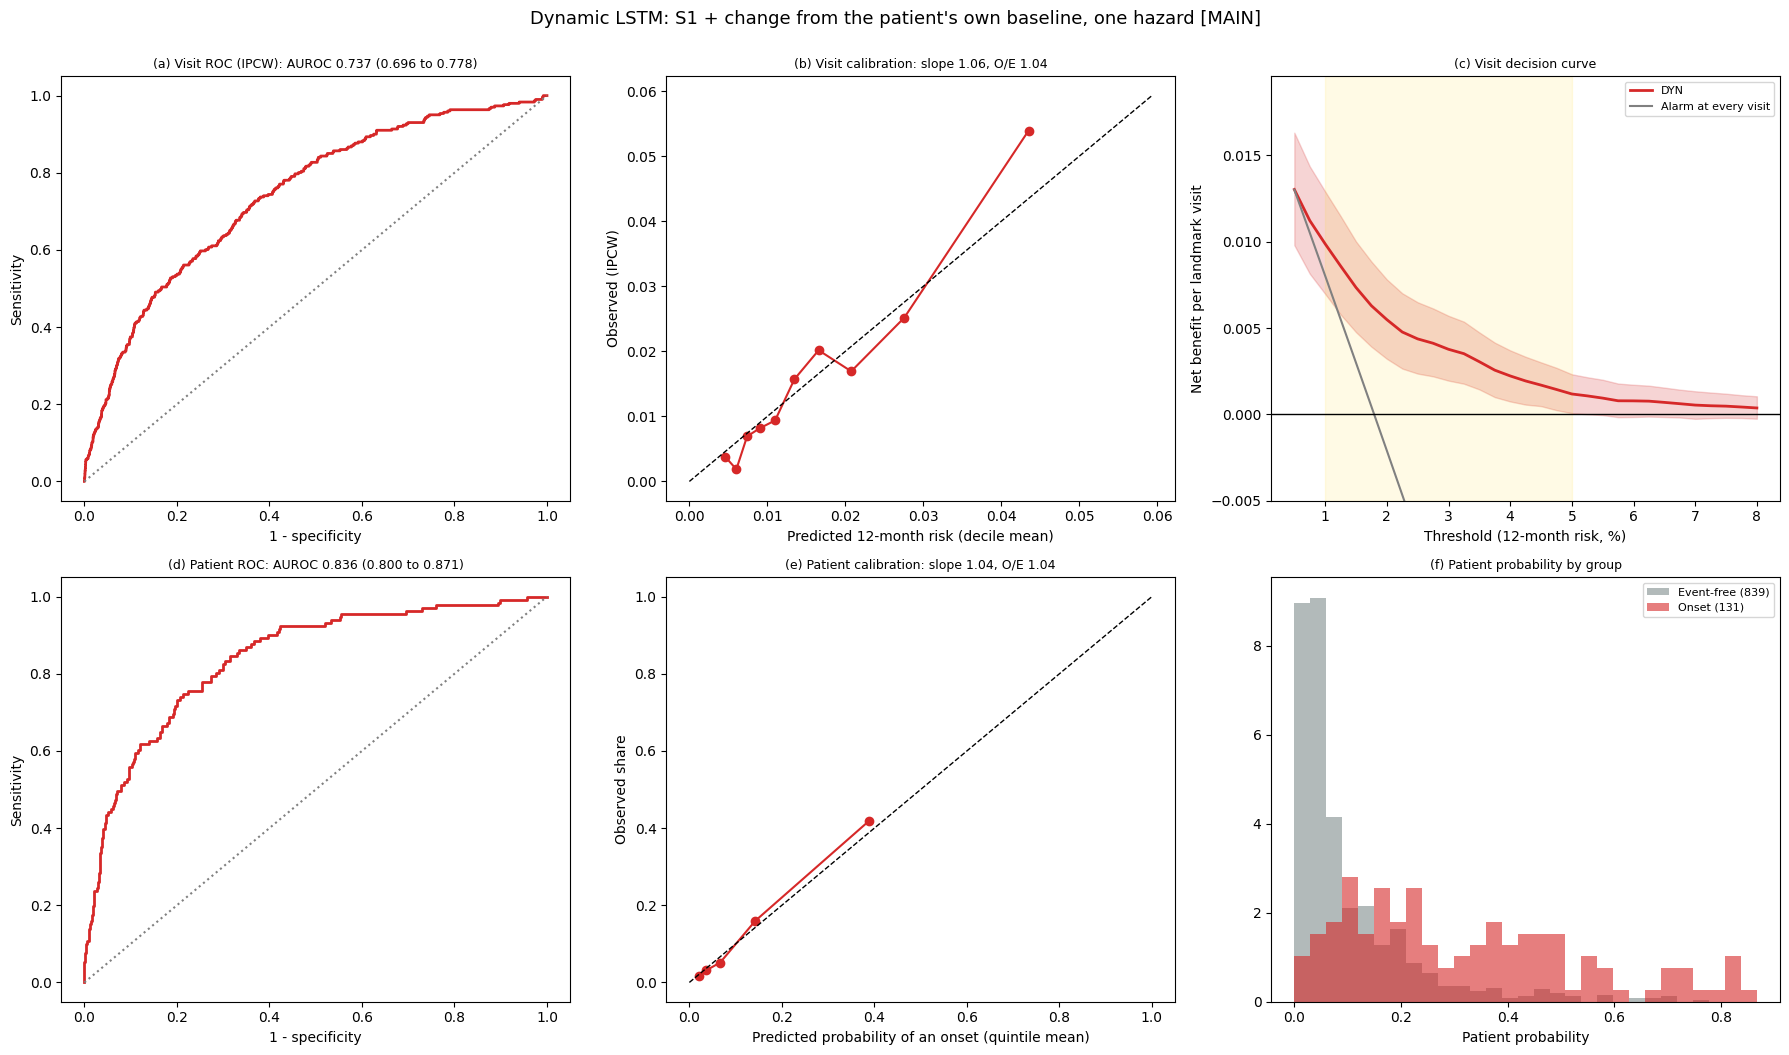

In [10]:
"""Per-model tables and figures (helpers), then the main model."""


def patient_z(m, r, h=H):
    return np.asarray(PTW[h]["mat"] @ np.nan_to_num(zpred(m, r, h))).ravel()


def patient_prob(m, r):
    a, b = PCAL[m][r][H]
    lr = PTW[H]["last_row"]
    return _expit(a[lr] + b[lr] * patient_z(m, r))


def model_table(m):
    """Section 9.3: one row per metric, visit level and patient level."""
    v, p = ("visit", H), ("patient", H)
    c = MAIN_THRESHOLD
    pct = lambda key: fmt(*[x * 100 for x in ci((m,) + key)], nd=1)
    rows = [("Time-matched patient AUROC (primary)", "-", fmtk((m,) + K_TM)),
            ("Time-matched patient sensitivity / specificity", "-",
             f"{ci((m, 'tm', 'main', 'sensitivity'))[0]:.3f} / {ci((m, 'tm', 'main', 'specificity'))[0]:.3f}"),
            ("Concordance (AUROC; patient: windows)", fmtk((m,) + v + ("auroc",)), fmtk((m,) + p + ("auroc",))),
            ("Risk-set C (calendar-time risk sets)", "-", fmtk((m,) + K_RS)),
            ("Calibration slope", fmtk((m,) + v + ("cal_slope",)), fmtk((m,) + p + ("cal_slope",))),
            ("Calibration intercept", fmtk((m,) + v + ("cal_intercept",)), fmtk((m,) + p + ("cal_intercept",))),
            ("Observed / expected", fmtk((m,) + v + ("oe",)), fmtk((m,) + p + ("oe",))),
            ("Threshold (12-month risk, median over folds)", f"{100 * ci((m,) + v + (c, 'threshold'))[0]:.1f} %",
             "fold patient threshold")]
    for x in CONF_METRICS:
        rows.append((METRIC_LABELS[x], fmtk((m,) + v + (c, x)), fmtk((m,) + p + (c, x))))
    rows += [("Median lead time (months), flagged event patients", "-", fmtk((m,) + p + ("lead_median",), 1)),
             (METRIC_LABELS["lead_ge6"] + " (share of event patients)", "-", fmtk((m,) + p + ("lead_ge6",))),
             ("Alerts per 100 landmark visits", f"{ci((m,) + v + ('alerts_per_100',))[0]:.1f}", "-"),
             ("Alerts per patient-year of employed follow-up", f"{ci((m,) + v + ('alerts_per_py',))[0]:.2f}", "-"),
             ("Stayed employed: never alerted / alerts per patient-year",
              f"{ci((m,) + v + ('stayed_never_alerted',))[0]:.2f} / {ci((m,) + v + ('stayed_alerts_per_py',))[0]:.2f}",
              "-"),
             ("Patient rule: 2 consecutive alarms, AUROC / sensitivity / specificity", "-",
              f"{ci((m,) + p + ('run2', 'auroc'))[0]:.3f} / {ci((m,) + p + ('run2', 'sensitivity'))[0]:.3f} / "
              f"{ci((m,) + p + ('run2', 'specificity'))[0]:.3f}")]
    return pd.DataFrame(rows, columns=["Metric", "Visit level", "Patient level"]).set_index("Metric")


def calib_bins(y, p, w, n_bins, central=True):
    k = np.ones(len(p), bool)
    if central:
        lo, hi = np.percentile(p, [2.5, 97.5]); k = (p >= lo) & (p <= hi)
    y, p, w = y[k], p[k], w[k]
    q = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    b = np.clip(np.searchsorted(q, p, side="right") - 1, 0, n_bins - 1)
    xs = np.array([np.average(p[b == j], weights=w[b == j]) for j in range(n_bins) if (b == j).any()])
    ys = np.array([np.average(y[b == j], weights=w[b == j]) for j in range(n_bins) if (b == j).any()])
    return xs, ys


def model_figure(m):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))
    col = model_color(m)
    zm = mean_z(m)
    pv = _expit(zm[ROWS_IPCW])
    fpr, tpr, _ = roc_curve(Y_IPCW, pv, sample_weight=WI_IPCW)
    ax = axes[0, 0]; ax.plot(fpr, tpr, color=col, lw=2); ax.plot([0, 1], [0, 1], ":", color="grey")
    ax.set_title(f"(a) Visit ROC (IPCW): AUROC {fmtk((m,) + K_VIS)}", fontsize=9)
    ax.set_xlabel("1 - specificity"); ax.set_ylabel("Sensitivity")
    ax = axes[0, 1]
    xs, ys = calib_bins(Y_IPCW, pv, WI_IPCW, 10)
    ax.plot(xs, ys, "o-", color=col); top = max(xs.max(), ys.max()) * 1.1
    ax.plot([0, top], [0, top], "k--", lw=1)
    ax.set_title(f"(b) Visit calibration: slope {ci((m, 'visit', H, 'cal_slope'))[0]:.2f}, O/E "
                 f"{ci((m, 'visit', H, 'oe'))[0]:.2f}", fontsize=9)
    ax.set_xlabel("Predicted 12-month risk (decile mean)"); ax.set_ylabel("Observed (IPCW)")
    ax = axes[0, 2]
    nb = np.array([ci((m, "visit", H, "nb", t)) for t in NB_GRID])
    nba = np.array([ci((m, "visit", H, "nb_all", t))[0] for t in NB_GRID])
    ax.plot(NB_GRID * 100, nb[:, 0], color=col, lw=2, label=short_label(m))
    ax.fill_between(NB_GRID * 100, nb[:, 1], nb[:, 2], color=col, alpha=0.2)
    ax.plot(NB_GRID * 100, nba, color="grey", label="Alarm at every visit"); ax.axhline(0, color="k", lw=1)
    ax.axvspan(H1D_RANGE[0] * 100, H1D_RANGE[1] * 100, color="gold", alpha=0.1)
    ax.set_ylim(min(-0.005, nb[:, 1].min()), max(nb[:, 2].max(), nba.max()) * 1.2)
    ax.set_xlabel("Threshold (12-month risk, %)"); ax.set_ylabel("Net benefit per landmark visit")
    ax.set_title("(c) Visit decision curve", fontsize=9); ax.legend(fontsize=8)
    ev = PTW[H]["event"]
    pz = np.mean([patient_z(m, r) for r in REPEATS], 0)
    pp = np.mean([patient_prob(m, r) for r in REPEATS], 0)
    fpr, tpr, _ = roc_curve(ev, pz)
    ax = axes[1, 0]; ax.plot(fpr, tpr, color=col, lw=2); ax.plot([0, 1], [0, 1], ":", color="grey")
    ax.set_title(f"(d) Patient ROC: AUROC {fmtk((m,) + K_PT)}", fontsize=9)
    ax.set_xlabel("1 - specificity"); ax.set_ylabel("Sensitivity")
    ax = axes[1, 1]
    xs, ys = calib_bins(ev.astype(float), pp, np.ones(len(pp)), 5, central=False)
    ax.plot(xs, ys, "o-", color=col); ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"(e) Patient calibration: slope {ci((m, 'patient', H, 'cal_slope'))[0]:.2f}, O/E "
                 f"{ci((m, 'patient', H, 'oe'))[0]:.2f}", fontsize=9)
    ax.set_xlabel("Predicted probability of an onset (quintile mean)"); ax.set_ylabel("Observed share")
    ax = axes[1, 2]
    bins = np.linspace(0, max(pp.max(), 0.05), 30)
    ax.hist(pp[ev == 0], bins=bins, color="#7f8c8d", alpha=0.6, density=True, label=f"Event-free ({(ev == 0).sum()})")
    ax.hist(pp[ev == 1], bins=bins, color=col, alpha=0.6, density=True, label=f"Onset ({(ev == 1).sum()})")
    ax.set_xlabel("Patient probability"); ax.set_title("(f) Patient probability by group", fontsize=9)
    ax.legend(fontsize=8)
    fig.suptitle(model_label(m), y=1.0, fontsize=13)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_model_{short_label(m)}.png", dpi=130, bbox_inches="tight")
    plt.show()


def model_section(m):
    if m not in MODELS_RUN:
        print(f"{m} was not fitted."); return
    print(model_label(m))
    display(model_table(m))
    model_figure(m)


MODEL_TABLES = {}
for m in MODELS_RUN:
    t_ = model_table(m)
    MODEL_TABLES[m] = t_
pd.concat({short_label(m): t_ for m, t_ in MODEL_TABLES.items()}).to_csv(f"metric_tables_model_{TAG}.csv")
model_section(MAIN_MODEL)

## 12.2 Baseline (index visit and demographics; primary comparison)

Baseline (index visit + demographics), one hazard


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.582 (0.531 to 0.633)
Time-matched patient sensitivity / specificity,-,0.442 / 0.620
Concordance (AUROC; patient: windows),0.626 (0.580 to 0.676),0.787 (0.750 to 0.824)
Risk-set C (calendar-time risk sets),-,0.583 (0.532 to 0.635)
Calibration slope,0.948 (0.625 to 1.239),1.032 (0.863 to 1.213)
Calibration intercept,-0.031 (-0.231 to 0.141),0.005 (-0.189 to 0.196)
Observed / expected,0.995 (0.814 to 1.181),1.004 (0.844 to 1.156)
"Threshold (12-month risk, median over folds)",1.8 %,fold patient threshold
Sensitivity,0.599 (0.524 to 0.673),0.763 (0.699 to 0.827)


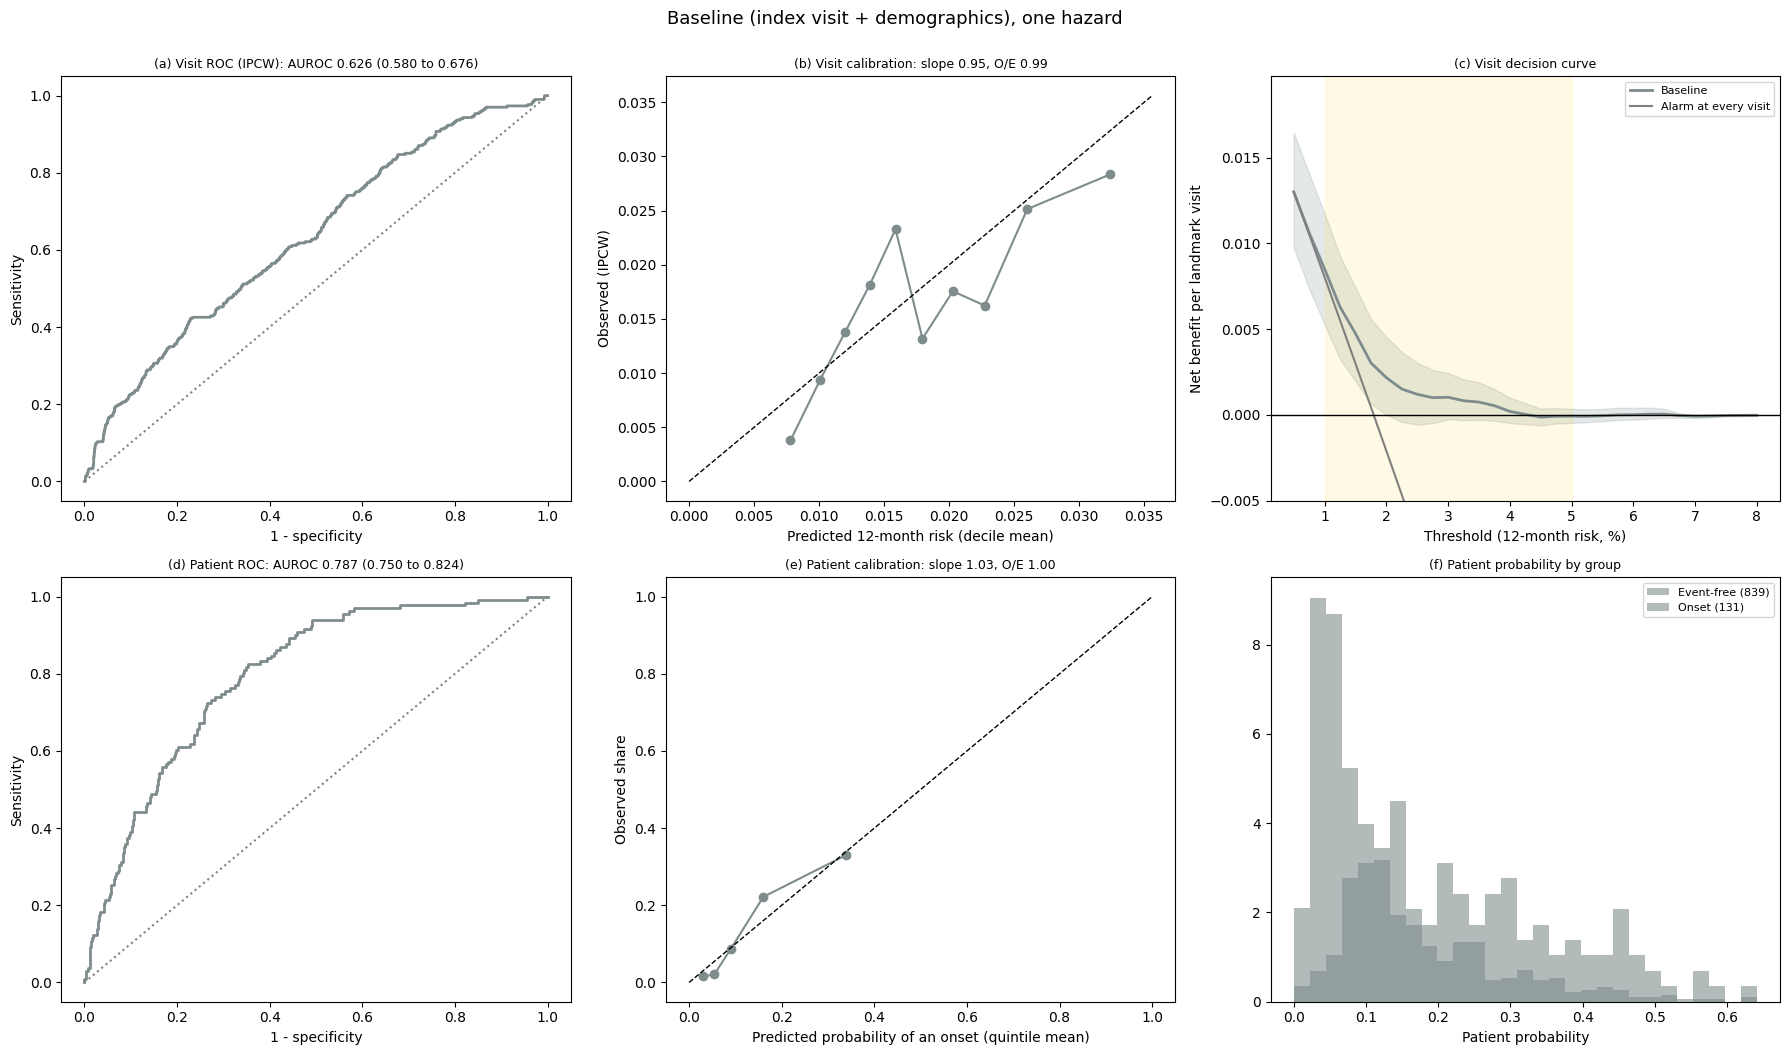

In [11]:
model_section(BASELINE)

## 12.3 Logistic regression on the main model's inputs (secondary comparison)

Logistic regression of the 12-month label on the main model's inputs (landmark visit)


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.734 (0.694 to 0.773)
Time-matched patient sensitivity / specificity,-,0.633 / 0.684
Concordance (AUROC; patient: windows),0.723 (0.682 to 0.765),0.818 (0.781 to 0.855)
Risk-set C (calendar-time risk sets),-,0.729 (0.688 to 0.769)
Calibration slope,0.909 (0.727 to 1.075),0.885 (0.761 to 1.038)
Calibration intercept,-0.050 (-0.258 to 0.135),0.005 (-0.241 to 0.235)
Observed / expected,0.974 (0.802 to 1.152),1.003 (0.857 to 1.159)
"Threshold (12-month risk, median over folds)",1.7 %,fold patient threshold
Sensitivity,0.629 (0.562 to 0.697),0.711 (0.645 to 0.779)


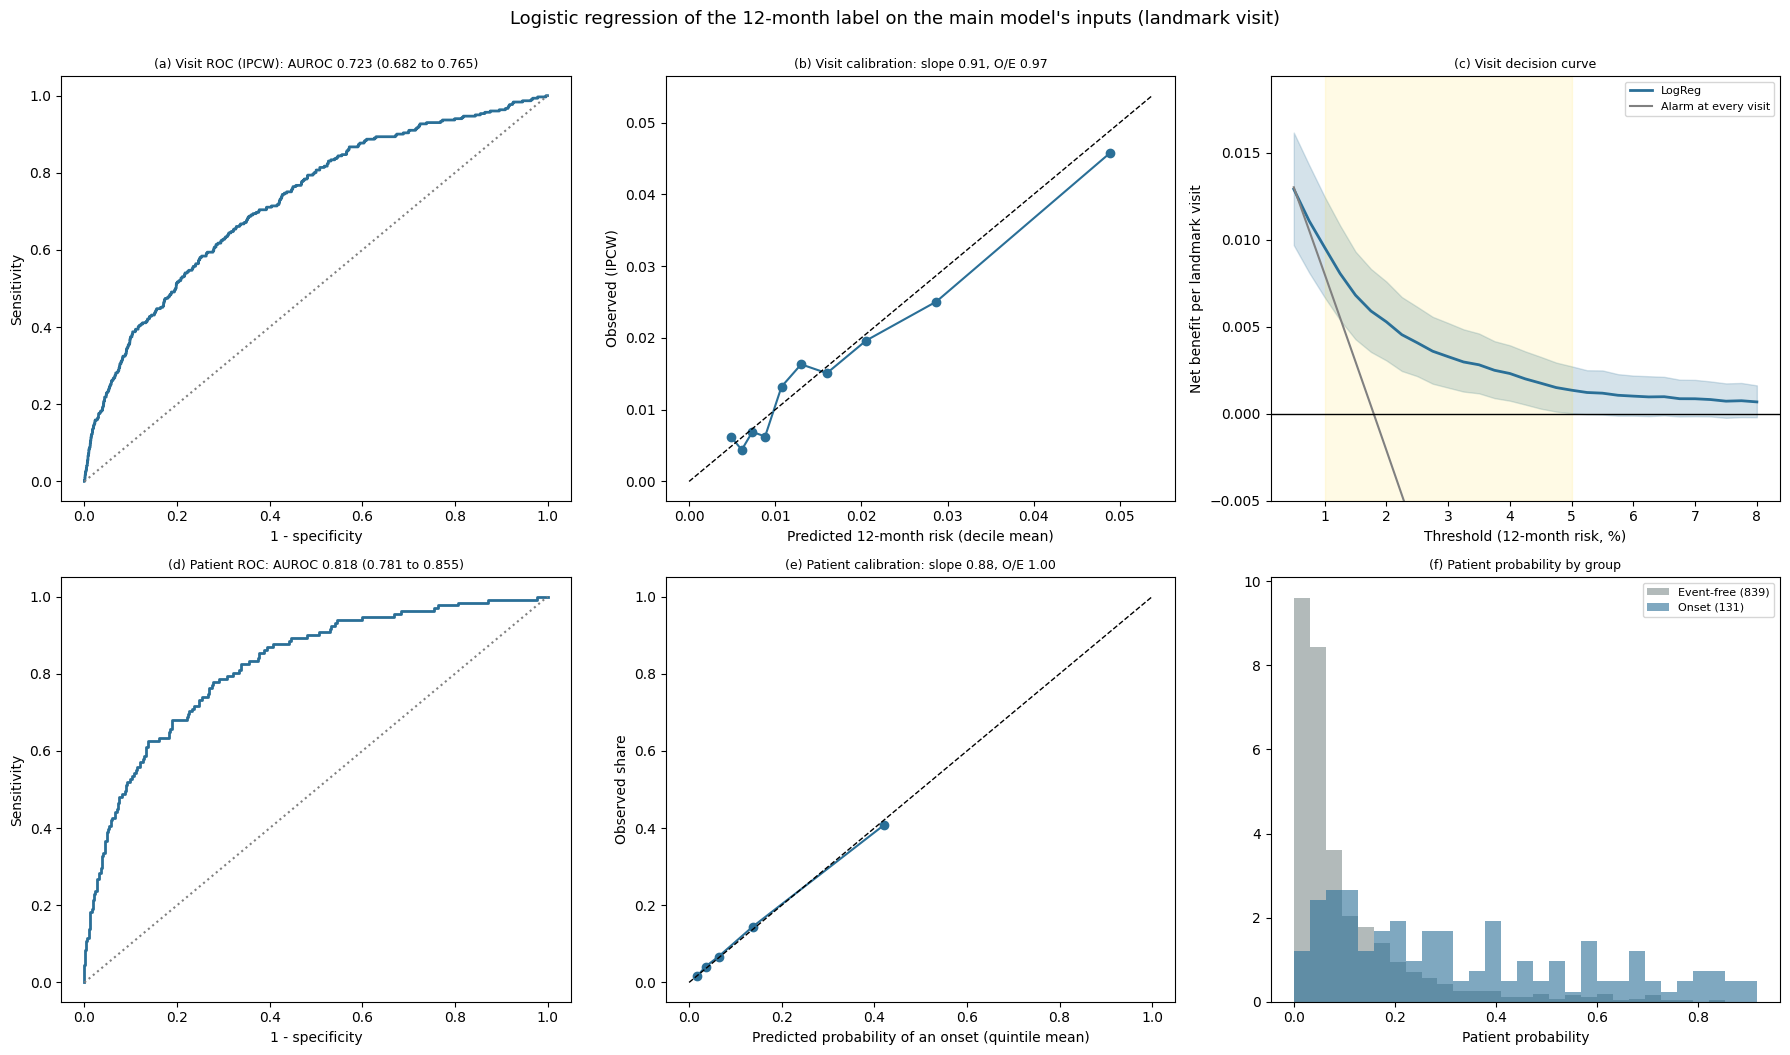

In [12]:
model_section(LOGREG)

## 12.4 Band-hazard regression on the main model's inputs

Regression on the main model's inputs (landmark visit), band hazards


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.729 (0.687 to 0.770)
Time-matched patient sensitivity / specificity,-,0.604 / 0.671
Concordance (AUROC; patient: windows),0.722 (0.680 to 0.768),0.820 (0.780 to 0.858)
Risk-set C (calendar-time risk sets),-,0.729 (0.686 to 0.772)
Calibration slope,1.032 (0.812 to 1.238),1.026 (0.871 to 1.204)
Calibration intercept,-0.019 (-0.224 to 0.168),-0.005 (-0.233 to 0.211)
Observed / expected,1.003 (0.826 to 1.194),0.996 (0.853 to 1.150)
"Threshold (12-month risk, median over folds)",1.9 %,fold patient threshold
Sensitivity,0.617 (0.548 to 0.688),0.715 (0.649 to 0.781)


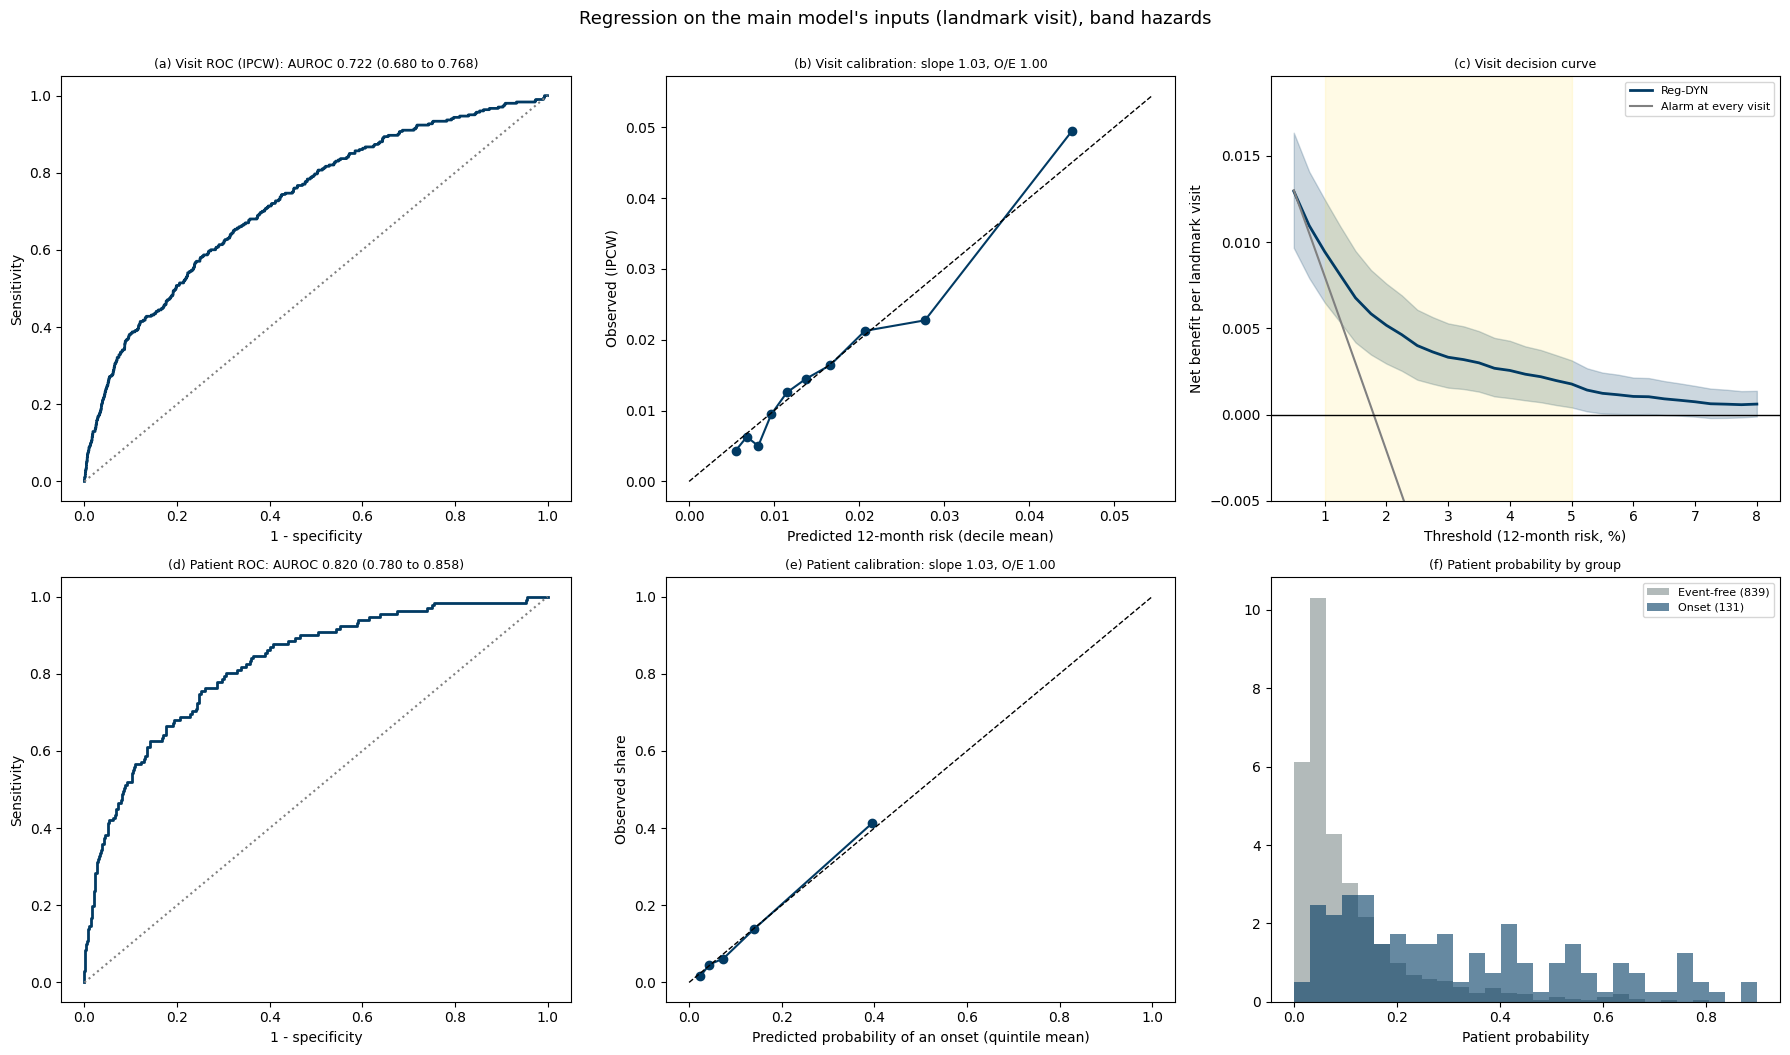

In [13]:
model_section(REG_DYN)

## 12.5 update_v8's main LSTM (S0)

S0: v8's main LSTM (grid, all history, one hazard, 24-month pool)


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.719 (0.678 to 0.760)
Time-matched patient sensitivity / specificity,-,0.604 / 0.695
Concordance (AUROC; patient: windows),0.725 (0.683 to 0.770),0.825 (0.789 to 0.863)
Risk-set C (calendar-time risk sets),-,0.726 (0.686 to 0.768)
Calibration slope,1.057 (0.829 to 1.288),1.054 (0.910 to 1.236)
Calibration intercept,-0.012 (-0.201 to 0.174),0.032 (-0.182 to 0.233)
Observed / expected,1.015 (0.837 to 1.212),1.022 (0.877 to 1.175)
"Threshold (12-month risk, median over folds)",2.1 %,fold patient threshold
Sensitivity,0.630 (0.553 to 0.709),0.731 (0.667 to 0.798)


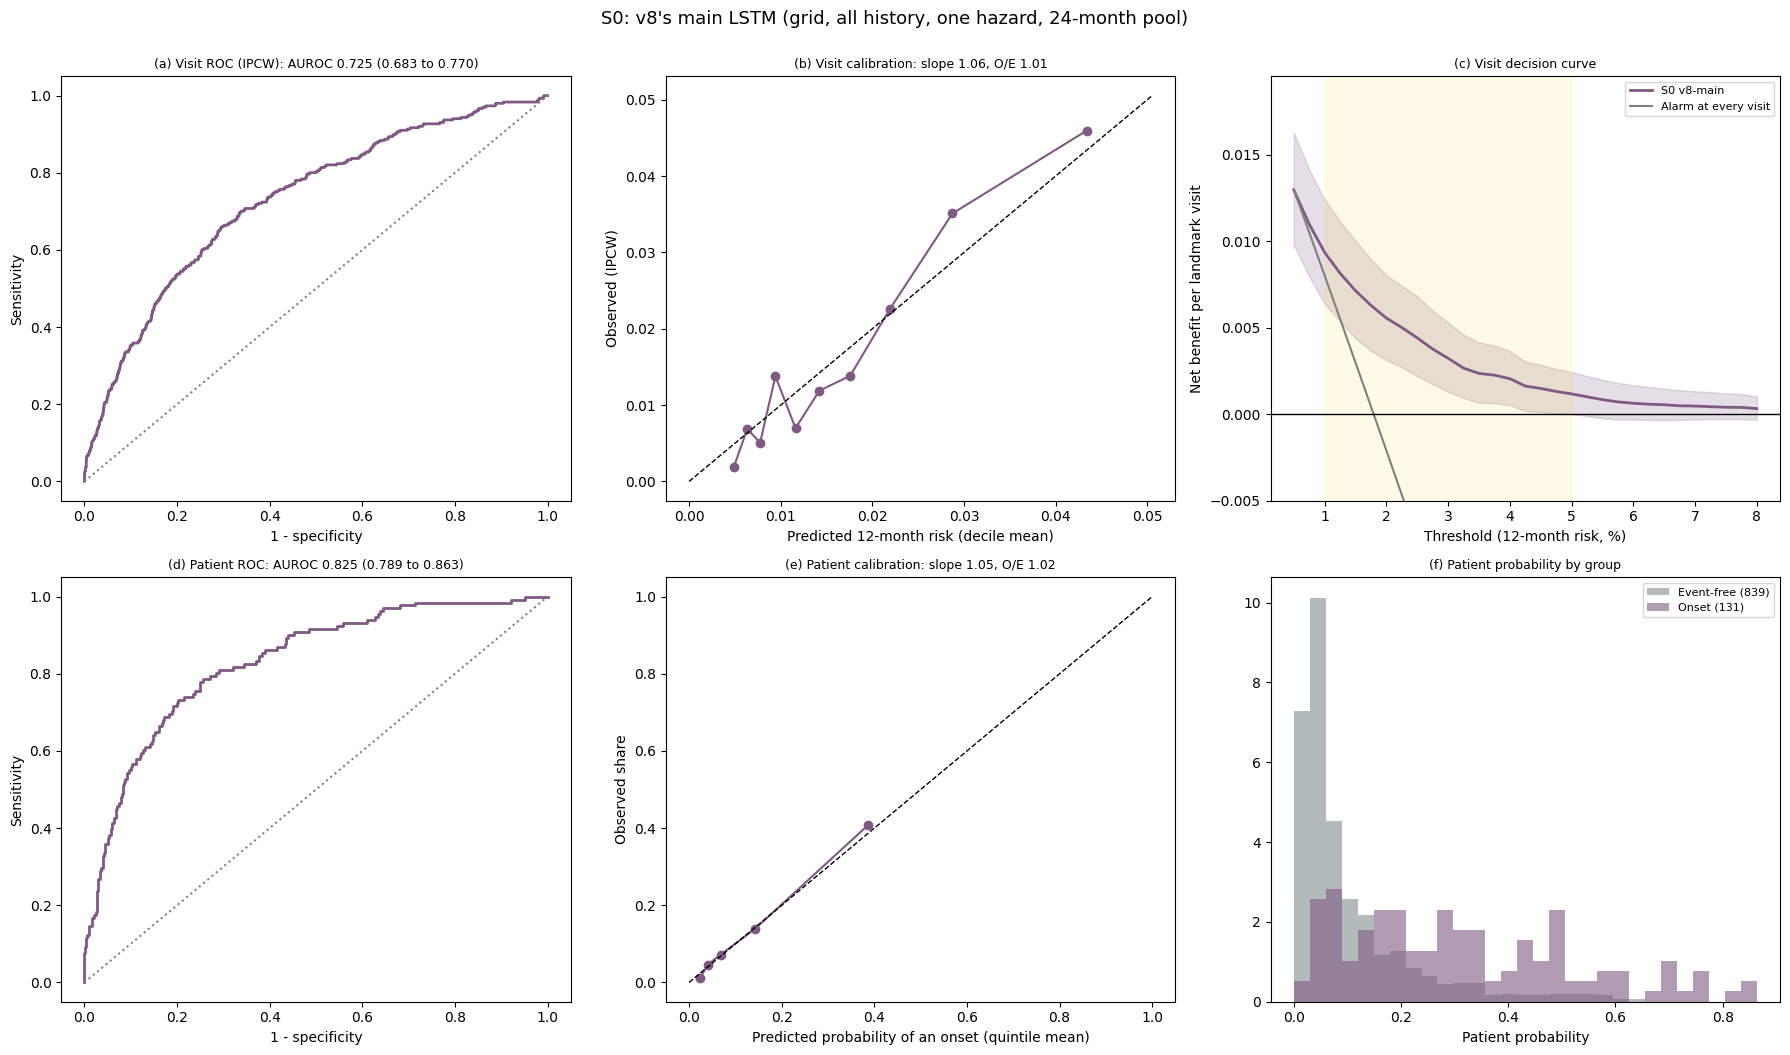

In [14]:
model_section(V8_MAIN)

## 12.6 Two-part model: trait offset + LSTM on change only

Two-part: trait offset (Baseline) + LSTM on change only, band hazards


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.694 (0.652 to 0.738)
Time-matched patient sensitivity / specificity,-,0.570 / 0.645
Concordance (AUROC; patient: windows),0.702 (0.657 to 0.748),0.827 (0.791 to 0.862)
Risk-set C (calendar-time risk sets),-,0.699 (0.659 to 0.743)
Calibration slope,1.116 (0.855 to 1.337),1.102 (0.947 to 1.282)
Calibration intercept,0.018 (-0.161 to 0.193),0.064 (-0.151 to 0.259)
Observed / expected,1.043 (0.858 to 1.238),1.047 (0.887 to 1.199)
"Threshold (12-month risk, median over folds)",1.8 %,fold patient threshold
Sensitivity,0.628 (0.558 to 0.699),0.759 (0.697 to 0.820)


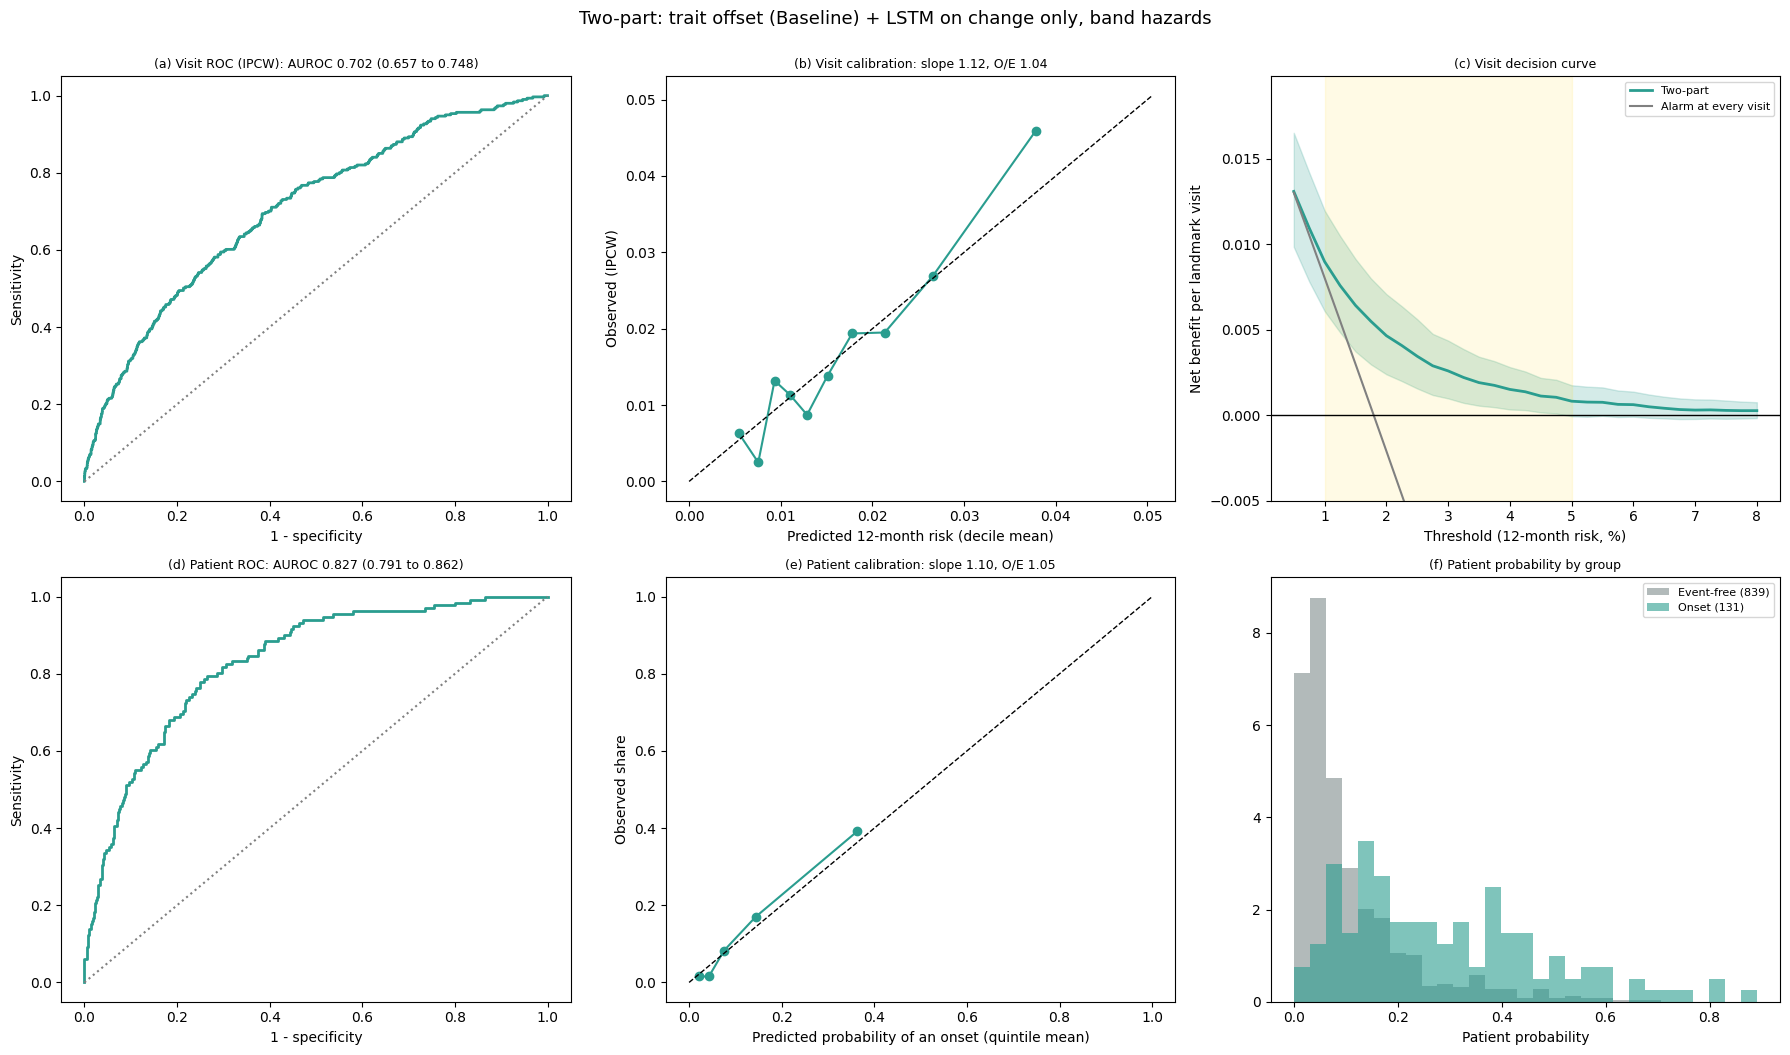

In [15]:
model_section(TWO_PART)

## 12.7 Average of the dynamic LSTM and the dynamic regression

Average: dynamic LSTM + dynamic regression


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.742 (0.700 to 0.784)
Time-matched patient sensitivity / specificity,-,0.616 / 0.700
Concordance (AUROC; patient: windows),0.734 (0.693 to 0.777),0.833 (0.796 to 0.870)
Risk-set C (calendar-time risk sets),-,0.745 (0.703 to 0.787)
Calibration slope,1.103 (0.893 to 1.316),1.009 (0.868 to 1.181)
Calibration intercept,0.013 (-0.188 to 0.201),0.016 (-0.220 to 0.246)
Observed / expected,1.037 (0.855 to 1.230),1.011 (0.868 to 1.164)
"Threshold (12-month risk, median over folds)",2.0 %,fold patient threshold
Sensitivity,0.610 (0.542 to 0.681),0.754 (0.693 to 0.815)


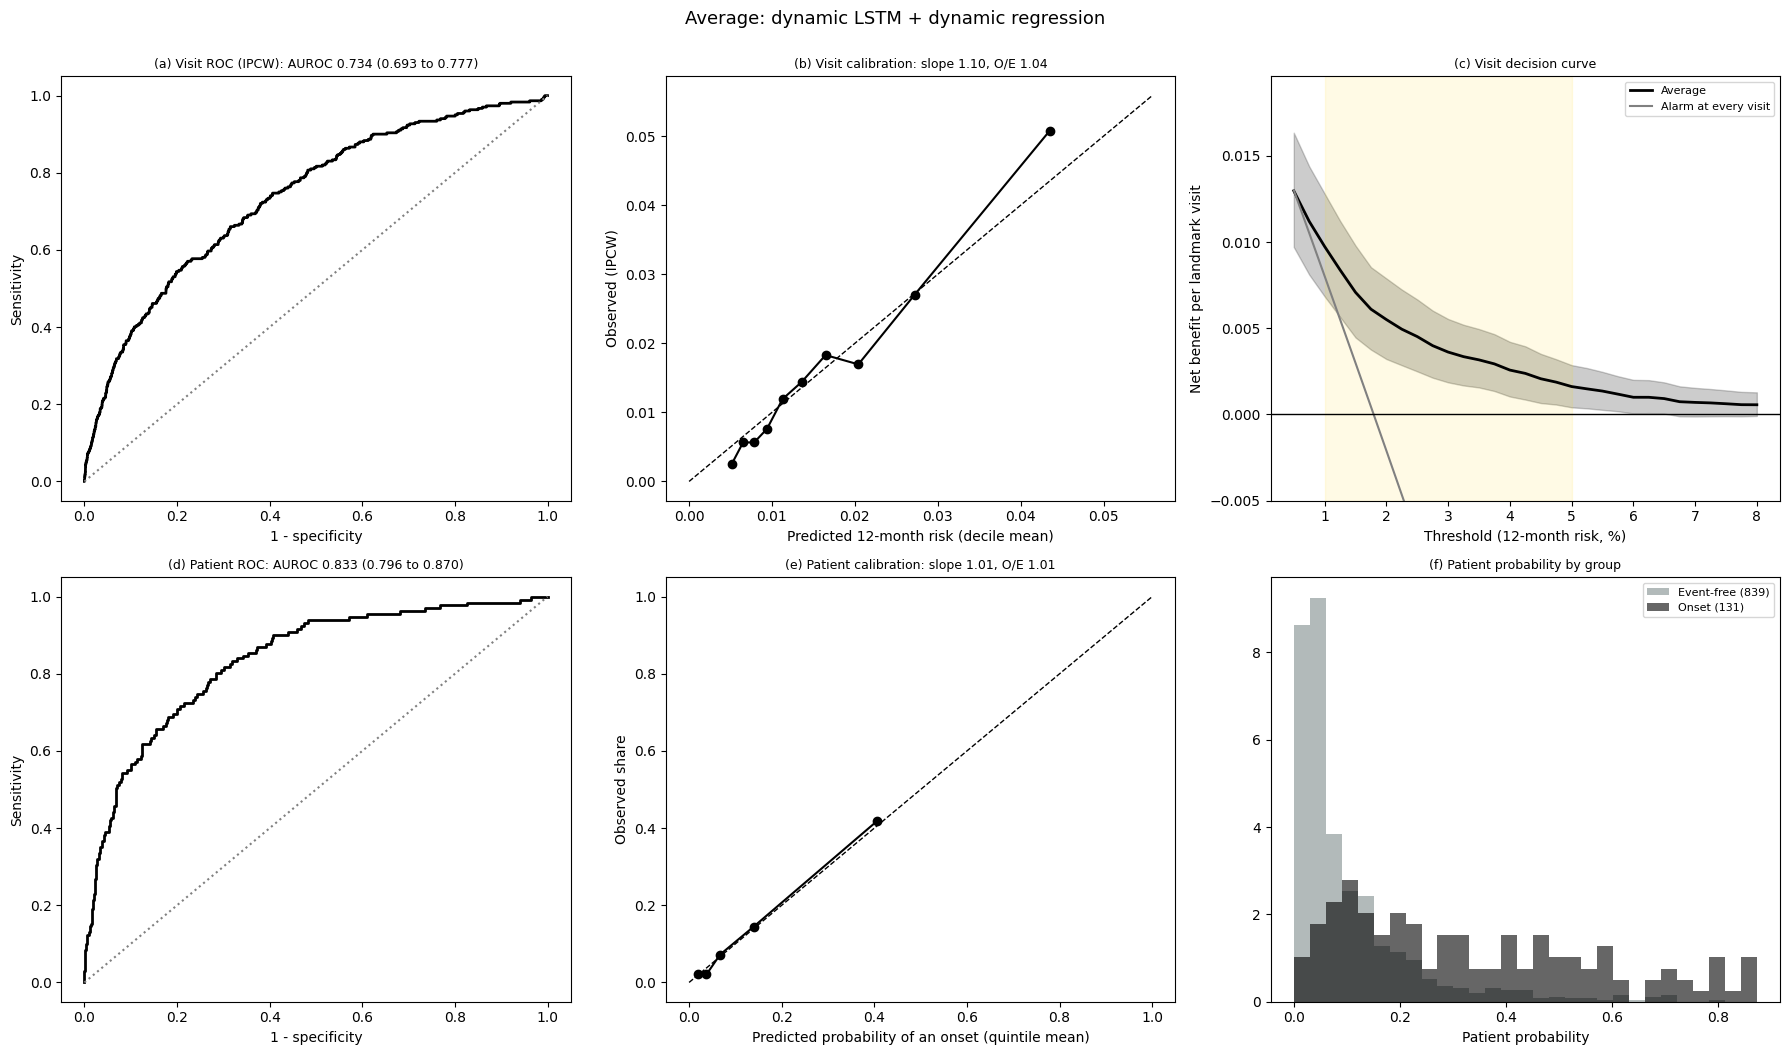

In [16]:
model_section(AVG_MODEL)

## 12.8 Every model: the main metrics

One row per model; the 12-month risk at the patient level (time-matched) and the visit level, value (95 % CI), ranked by the
primary metric. The ranking is descriptive: only the prespecified contrasts (Section 8) are tested.

,Time-matched patient AUROC (primary),"Visit AUROC, 12 months",Risk-set C,Patient AUROC (windows),Visit calibration slope,Visit O/E,Patient sensitivity,Patient specificity,Patient PPV,Visit sensitivity,Visit specificity,Visit PPV
Model,,,,,,,,,,,,
DYN,0.742 (0.702 to 0.783),0.737 (0.696 to 0.778),0.748 (0.707 to 0.787),0.836 (0.800 to 0.871),1.056 (0.878 to 1.257),1.037 (0.849 to 1.230),0.740 (0.676 to 0.802),0.766 (0.739 to 0.791),0.332 (0.280 to 0.383),0.678 (0.609 to 0.747),0.673 (0.649 to 0.698),0.037 (0.030 to 0.044)
Average,0.742 (0.700 to 0.784),0.734 (0.693 to 0.777),0.745 (0.703 to 0.787),0.833 (0.796 to 0.870),1.103 (0.893 to 1.316),1.037 (0.855 to 1.230),0.754 (0.693 to 0.815),0.751 (0.723 to 0.776),0.323 (0.273 to 0.374),0.610 (0.542 to 0.681),0.718 (0.694 to 0.741),0.038 (0.030 to 0.046)
S1 no-pool,0.735 (0.695 to 0.778),0.738 (0.695 to 0.780),0.742 (0.702 to 0.785),0.833 (0.797 to 0.869),1.061 (0.853 to 1.265),1.029 (0.845 to 1.227),0.710 (0.641 to 0.775),0.799 (0.773 to 0.824),0.356 (0.299 to 0.412),0.645 (0.576 to 0.720),0.700 (0.674 to 0.726),0.038 (0.030 to 0.046)
LogReg,0.734 (0.694 to 0.773),0.723 (0.682 to 0.765),0.729 (0.688 to 0.769),0.818 (0.781 to 0.855),0.909 (0.727 to 1.075),0.974 (0.802 to 1.152),0.711 (0.645 to 0.779),0.766 (0.739 to 0.792),0.323 (0.273 to 0.375),0.629 (0.562 to 0.697),0.689 (0.666 to 0.711),0.036 (0.029 to 0.044)
Reg-DYN,0.729 (0.687 to 0.770),0.722 (0.680 to 0.768),0.729 (0.686 to 0.772),0.820 (0.780 to 0.858),1.032 (0.812 to 1.238),1.003 (0.826 to 1.194),0.715 (0.649 to 0.781),0.751 (0.724 to 0.777),0.310 (0.261 to 0.360),0.617 (0.548 to 0.688),0.693 (0.668 to 0.718),0.036 (0.028 to 0.043)
Reg-v7,0.726 (0.685 to 0.768),0.727 (0.684 to 0.770),0.735 (0.693 to 0.776),0.808 (0.769 to 0.847),1.028 (0.828 to 1.235),0.999 (0.826 to 1.194),0.708 (0.639 to 0.778),0.763 (0.737 to 0.787),0.319 (0.270 to 0.371),0.669 (0.596 to 0.741),0.683 (0.657 to 0.710),0.037 (0.030 to 0.045)
DYN-bands,0.726 (0.688 to 0.769),0.729 (0.687 to 0.774),0.733 (0.692 to 0.774),0.827 (0.790 to 0.865),1.067 (0.870 to 1.289),1.054 (0.866 to 1.257),0.739 (0.672 to 0.801),0.747 (0.719 to 0.771),0.319 (0.269 to 0.368),0.644 (0.576 to 0.713),0.682 (0.659 to 0.705),0.036 (0.029 to 0.044)
S2 bands,0.722 (0.683 to 0.765),0.732 (0.690 to 0.777),0.729 (0.688 to 0.773),0.827 (0.788 to 0.865),1.050 (0.842 to 1.255),1.047 (0.864 to 1.251),0.725 (0.657 to 0.790),0.772 (0.744 to 0.796),0.334 (0.283 to 0.388),0.612 (0.542 to 0.689),0.721 (0.697 to 0.747),0.039 (0.031 to 0.048)
S0 v8-main,0.719 (0.678 to 0.760),0.725 (0.683 to 0.770),0.726 (0.686 to 0.768),0.825 (0.789 to 0.863),1.057 (0.829 to 1.288),1.015 (0.837 to 1.212),0.731 (0.667 to 0.798),0.774 (0.747 to 0.800),0.337 (0.286 to 0.390),0.630 (0.553 to 0.709),0.708 (0.682 to 0.735),0.038 (0.030 to 0.047)


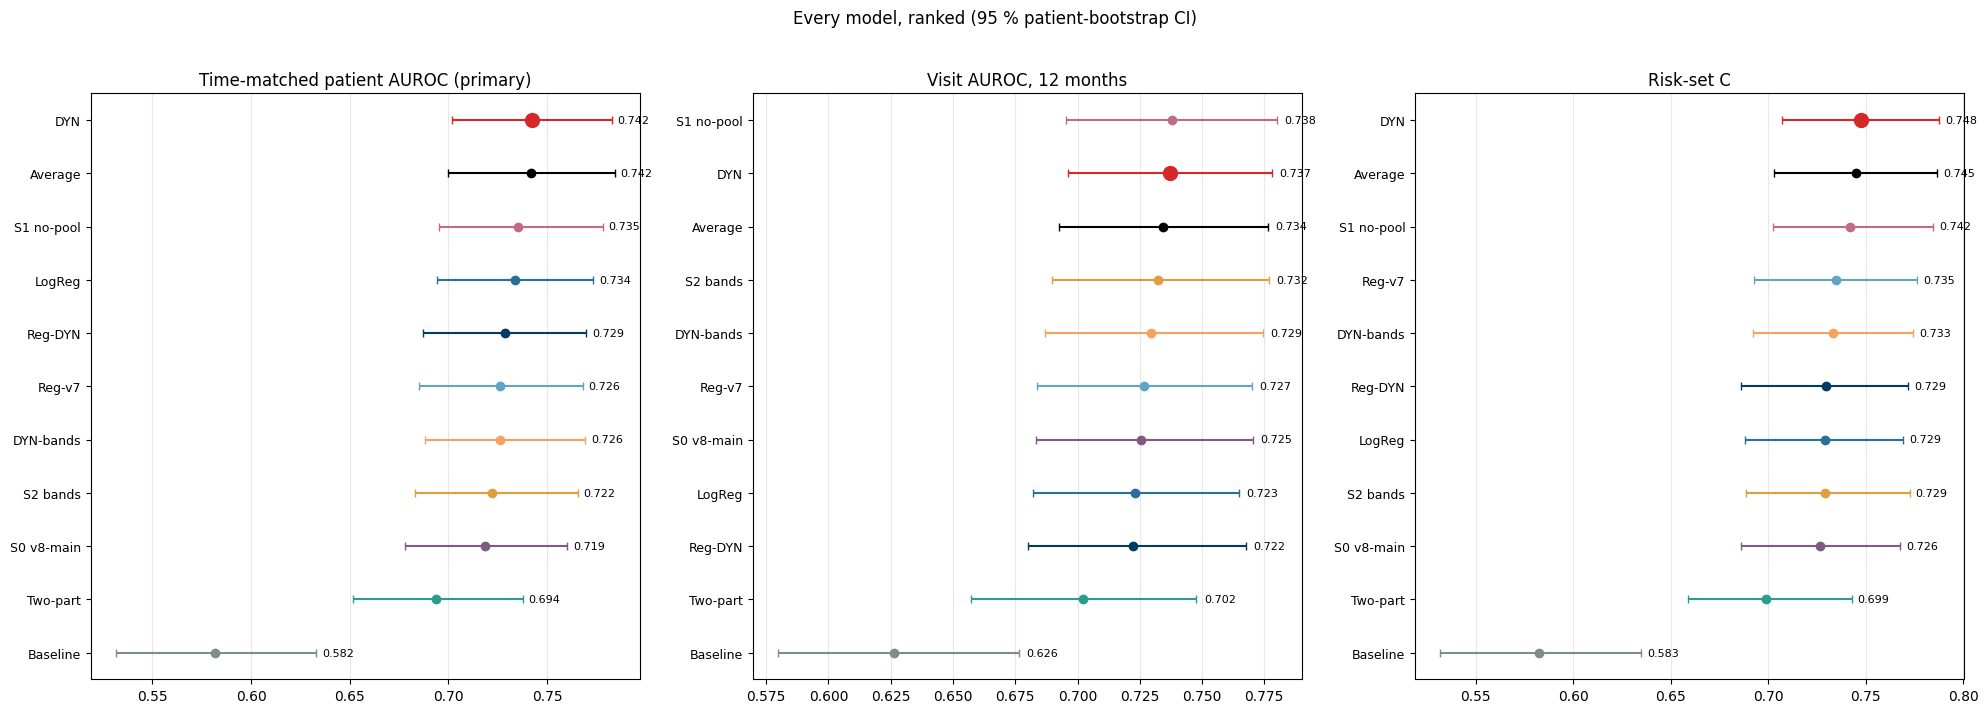

In [17]:
"""Every model on the main metrics (12 months)."""
SUM_KEYS = [("Time-matched patient AUROC (primary)", K_TM), ("Visit AUROC, 12 months", K_VIS), ("Risk-set C", K_RS),
            ("Patient AUROC (windows)", K_PT),
            ("Visit calibration slope", ("visit", H, "cal_slope")), ("Visit O/E", ("visit", H, "oe")),
            ("Patient sensitivity", ("patient", H, MAIN_THRESHOLD, "sensitivity")),
            ("Patient specificity", ("patient", H, MAIN_THRESHOLD, "specificity")),
            ("Patient PPV", ("patient", H, MAIN_THRESHOLD, "ppv")),
            ("Visit sensitivity", ("visit", H, MAIN_THRESHOLD, "sensitivity")),
            ("Visit specificity", ("visit", H, MAIN_THRESHOLD, "specificity")),
            ("Visit PPV", ("visit", H, MAIN_THRESHOLD, "ppv"))]
ALL_TABLE = pd.DataFrame([{"Model": short_label(m), **{lab_: fmtk((m,) + k) for lab_, k in SUM_KEYS}}
                          for m in sorted(MODELS_RUN, key=lambda m: -ci((m,) + K_TM)[0])]).set_index("Model")
display(ALL_TABLE)
ALL_TABLE.to_csv(f"all_models_{TAG}.csv")
fig, axes = plt.subplots(1, 3, figsize=(20, 0.45 * len(MODELS_RUN) + 2))
for ax, (lab_, key) in zip(axes, SUM_KEYS[:3]):
    order = sorted(MODELS_RUN, key=lambda m: ci((m,) + key)[0])
    for y_, m in enumerate(order):
        a = ci((m,) + key)
        ax.errorbar(a[0], y_, xerr=[[a[0] - a[1]], [a[2] - a[0]]], fmt="o", color=model_color(m), capsize=3,
                    ms=10 if m == MAIN_MODEL else 6)
        ax.text(a[2] + 0.003, y_, f"{a[0]:.3f}", va="center", fontsize=8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([short_label(m) for m in order], fontsize=9)
    ax.set_title(lab_); ax.grid(axis="x", alpha=0.3)
fig.suptitle("Every model, ranked (95 % patient-bootstrap CI)", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_ranking.png", dpi=150, bbox_inches="tight"); plt.show()

---
# 13. Objective 1 — Patients who go on to work disability score higher than those who do not

## 13.1 Primary and secondary tests (time-matched patient AUROC)

**H1a (primary)**: the dynamic LSTM separates the patients who go on to an onset from those still working on the
same date better than the Baseline (index-visit age, SDI and SLEDAI-2K; current age, education, race, calendar year).
Estimand: DYN − Baseline, time-matched patient AUROC (12-month window before each onset; Section 11.8).
**H1b (secondary)**: DYN − LogReg (logistic regression of the 12-month label on the same inputs). Verdicts:
**superior** if the lower 95 % bound > 0; **inferior** if the upper bound < 0; **equivalent** if the CI lies within
±0.02; otherwise inconclusive. The same contrasts on the patient sensitivity / specificity, the visit AUROC, the
risk-set C and the patient-window AUROC are shown alongside, with the difference in each CV repeat.
**H1d (post hoc)**: DYN − DYN-bands (update_v10's main model): does dropping the 6-month bands lose anything?

H1a (primary) per CV repeat (DYN - Baseline): +0.160, +0.163, +0.157, +0.149, +0.175
H1b per CV repeat (DYN - LogReg): +0.012, +0.010, +0.006, +0.007, +0.006
H1d (post hoc) per CV repeat (DYN - DYN-bands): +0.014, +0.018, +0.011, +0.027, +0.009


DYN                        Comparator       Difference (95% CI)  p (bootstrap)       Verdict
Hypothesis     Metric                                                                                                                                         
H1a (primary)  Time-matched patient AUROC      0.742 (0.702 to 0.783)   Baseline 0.582 (0.531 to 0.633)    0.161 (0.109 to 0.214)          0.000      superior
               Time-matched balanced accuracy  0.655 (0.626 to 0.684)   Baseline 0.531 (0.501 to 0.561)    0.124 (0.090 to 0.158)          0.000      superior
               Visit AUROC 12 mo               0.737 (0.696 to 0.778)   Baseline 0.626 (0.580 to 0.676)    0.111 (0.071 to 0.156)          0.000      superior
               Risk-set C                      0.748 (0.707 to 0.787)   Baseline 0.583 (0.532 to 0.635)    0.165 (0.113 to 0.218)          0.000      superior
               Patient AUROC (windows)         0.836 (0.800 to 0.871)   Baseline 0.787 (0.750 to 0.824)    0.049 (0.016 to 0.082)          0.002      superior
H1b            Time-matched patient AUROC      0.742 (0.702 to 0.783)     LogReg 0.734 (0.694 to 0.773)   0.009 (-0.006 to 0.024)          0.264  inconclusive
               Time-matched balanced accuracy  0.655 (0.626 to 0.684)     LogReg 0.658 (0.630 to 0.689)  -0.003 (-0.020 to 0.015)          0.734  inconclusive
               Visit AUROC 12 mo               0.737 (0.696 to 0.778)     LogReg 0.723 (0.682 to 0.765)    0.014 (0.002 to 0.026)          0.022      superior
               Risk-set C                      0.748 (0.707 to 0.787)     LogReg 0.729 (0.688 to 0.769)    0.019 (0.005 to 0.034)          0.014      superior
               Patient AUROC (windows)         0.836 (0.800 to 0.871)     LogReg 0.818 (0.781 to 0.855)    0.017 (0.006 to 0.029)          0.004      superior
H1d (post hoc) Time-matched patient AUROC      0.742 (0.702 to 0.783)  DYN-bands 0.726 (0.688 to 0.769)    0.016 (0.002 to 0.029)          0.028      superior
               Time-matched balanced accuracy  0.655 (0.626 to 0.684)  DYN-bands 0.649 (0.619 to 0.680)   0.006 (-0.009 to 0.022)          0.444  inconclusive
               Visit AUROC 12 mo               0.737 (0.696 to 0.778)  DYN-bands 0.729 (0.687 to 0.774)   0.008 (-0.004 to 0.020)          0.244  inconclusive
               Risk-set C                      0.748 (0.707 to 0.787)  DYN-bands 0.733 (0.692 to 0.774)    0.015 (0.001 to 0.028)          0.032      superior
               Patient AUROC (windows)         0.836 (0.800 to 0.871)  DYN-bands 0.827 (0.790 to 0.865)   0.008 (-0.002 to 0.019)          0.140    equivalent

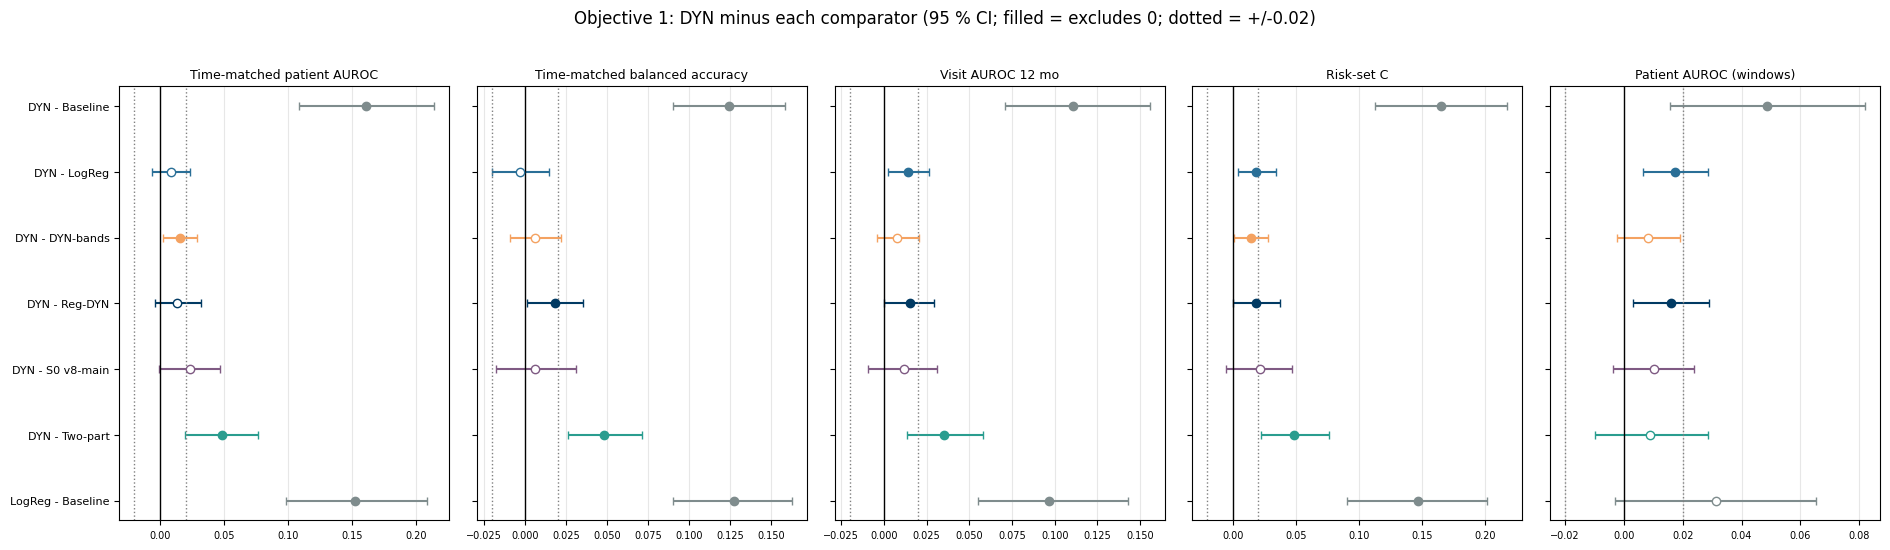

In [18]:
"""H1a (primary) and H1b: DYN - Baseline and DYN - LogReg."""


def forest(D, ycol, metrics, title, fname, color_of=None, ref=0.0, margin=None):
    """Forest plot of paired differences (filled = CI excludes 0), one panel per metric."""
    labs = list(dict.fromkeys(D[ycol]))
    yy = np.arange(len(labs))[::-1]
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.8 * len(metrics), 0.45 * len(labs) + 2.2), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, met in zip(axes, metrics):
        d = D[D["Metric"] == met].set_index(ycol).reindex(labs)
        for y_, (lab_, r_) in zip(yy, d.iterrows()):
            if np.isnan(r_["Difference"]):
                continue
            col = color_of(lab_) if color_of else "k"
            sig = r_["Lower"] > ref or r_["Upper"] < ref
            ax.errorbar(r_["Difference"], y_, xerr=[[r_["Difference"] - r_["Lower"]], [r_["Upper"] - r_["Difference"]]],
                        fmt="o", color=col, mfc=col if sig else "white", capsize=3)
        ax.axvline(ref, color="k", lw=1)
        if margin:
            for s_ in (-margin, margin):
                ax.axvline(s_, color="grey", ls=":", lw=1)
        ax.grid(axis="x", alpha=0.3); ax.set_yticks(yy); ax.set_yticklabels(labs, fontsize=8)
        ax.set_title(met, fontsize=9); ax.tick_params(axis="x", labelsize=7)
    fig.suptitle(title, y=1.02, fontsize=12)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_{fname}.png", dpi=150, bbox_inches="tight"); plt.show()


CMP_KEYS = [("Patient AUROC", K_PT), ("Visit AUROC", K_VIS), ("Risk-set C", K_RS),
            ("Patient balanced accuracy", ("patient", H, MAIN_THRESHOLD, "balanced_accuracy")),
            ("Visit balanced accuracy", ("visit", H, MAIN_THRESHOLD, "balanced_accuracy"))]


def compare(pairs, keys=CMP_KEYS, n_comp=1):
    rows = []
    for a, b in pairs:
        if a not in MODELS_RUN or b not in MODELS_RUN:
            continue
        for lab_, key in keys:
            d = diff(a, b, key, n_comp)
            rows.append({"Comparison": f"{short_label(a)} - {short_label(b)}", "Metric": lab_,
                         "First": ci((a,) + key)[0], "Second": ci((b,) + key)[0], "Difference": d[0],
                         "Lower": d[1], "Upper": d[2], "p (bootstrap)": d[3]})
    return pd.DataFrame(rows)


def show_cmp(D):
    s = D.copy()
    s["Difference (95% CI)"] = [fmt(a, b, c) for a, b, c in zip(s["Difference"], s["Lower"], s["Upper"])]
    display(s.pivot(index="Comparison", columns="Metric", values="Difference (95% CI)")
            .reindex(list(dict.fromkeys(s["Comparison"])))[list(dict.fromkeys(s["Metric"]))])



def repeat_tm(a, b, key=K_TM):
    """a - b in each CV repeat (time-matched patient AUROC, point estimate)."""
    d = TM[key[1]]
    return [tm_stats_one(a, r, d)["auroc"][0] - tm_stats_one(b, r, d)["auroc"][0] for r in REPEATS]


OBJ1_KEYS = [("Time-matched patient AUROC", K_TM),
             ("Time-matched balanced accuracy", ("tm", "main", "balanced_accuracy")),
             ("Visit AUROC 12 mo", K_VIS), ("Risk-set C", K_RS), ("Patient AUROC (windows)", K_PT)]
rows = []
for hyp, (a, b_) in [("H1a (primary)", (MAIN_MODEL, BASELINE)), ("H1b", (MAIN_MODEL, LOGREG)),
                     ("H1d (post hoc)", (MAIN_MODEL, DYN_BANDS))]:
    for lab_, key in OBJ1_KEYS:
        d = diff(a, b_, key)
        rows.append({"Hypothesis": hyp, "Metric": lab_, short_label(a): fmtk((a,) + key),
                     "Comparator": f"{short_label(b_)} {fmtk((b_,) + key)}", "Difference (95% CI)": fmt(*d[:3]),
                     "p (bootstrap)": round(d[3], 3), "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})
    d = diff(a, b_, K_TM)
    HYP_ROWS.append({"Hypothesis": hyp, "Estimand": f"{short_label(a)} - {short_label(b_)}, time-matched patient AUROC",
                     "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0 (equivalence +/-0.02)",
                     "Met": d[1] > 0, "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})
    print(f"{hyp} per CV repeat ({short_label(a)} - {short_label(b_)}): " +
          ", ".join(f"{x:+.3f}" for x in repeat_tm(a, b_)))
PRIMARY = pd.DataFrame(rows).set_index(["Hypothesis", "Metric"])
display(PRIMARY)
PRIMARY.to_csv(f"primary_tests_{TAG}.csv")
_H1_PAIRS = [(MAIN_MODEL, BASELINE), (MAIN_MODEL, LOGREG), (MAIN_MODEL, DYN_BANDS), (MAIN_MODEL, REG_DYN),
             (MAIN_MODEL, V8_MAIN), (MAIN_MODEL, TWO_PART), (LOGREG, BASELINE)]
H1 = compare(_H1_PAIRS, keys=OBJ1_KEYS)
_col = {f"{short_label(a)} - {short_label(b_)}": model_color(b_) for a, b_ in _H1_PAIRS}
forest(H1, "Comparison", [k for k, _ in OBJ1_KEYS], "Objective 1: DYN minus each comparator (95 % CI; filled = "
       "excludes 0; dotted = +/-0.02)", "objective1_forest", color_of=_col.get, margin=EQUIV_MARGIN)
H1.to_csv(f"objective1_contrasts_{TAG}.csv", index=False)

## 13.2 The time-matched patient AUROC of every model, and the ROC of the key models

Every model's time-matched patient AUROC, sensitivity and specificity (fold thresholds), with the ROC curves of
the main model, the Baseline and LogReg (case-control pairs pooled over the onsets, each onset's controls weighted
equally; first CV repeat).

,Time-matched AUROC,Sensitivity,Specificity,Balanced accuracy,Visit AUROC 12 mo
Model,,,,,
DYN,0.742 (0.702 to 0.783),0.620 (0.557 to 0.687),0.690 (0.655 to 0.727),0.655 (0.626 to 0.684),0.737 (0.696 to 0.778)
Average,0.742 (0.700 to 0.784),0.616 (0.552 to 0.687),0.700 (0.663 to 0.738),0.658 (0.627 to 0.688),0.734 (0.693 to 0.777)
S1 no-pool,0.735 (0.695 to 0.778),0.648 (0.583 to 0.709),0.667 (0.629 to 0.705),0.657 (0.627 to 0.686),0.738 (0.695 to 0.780)
LogReg,0.734 (0.694 to 0.773),0.633 (0.569 to 0.695),0.684 (0.649 to 0.718),0.658 (0.630 to 0.689),0.723 (0.682 to 0.765)
Reg-DYN,0.729 (0.687 to 0.770),0.604 (0.541 to 0.670),0.671 (0.630 to 0.711),0.637 (0.607 to 0.666),0.722 (0.680 to 0.768)
Reg-v7,0.726 (0.685 to 0.768),0.647 (0.578 to 0.714),0.673 (0.637 to 0.710),0.660 (0.626 to 0.693),0.727 (0.684 to 0.770)
DYN-bands,0.726 (0.688 to 0.769),0.589 (0.519 to 0.659),0.710 (0.674 to 0.748),0.649 (0.619 to 0.680),0.729 (0.687 to 0.774)
S2 bands,0.722 (0.683 to 0.765),0.589 (0.518 to 0.656),0.692 (0.654 to 0.731),0.640 (0.609 to 0.671),0.732 (0.690 to 0.777)
S0 v8-main,0.719 (0.678 to 0.760),0.604 (0.530 to 0.676),0.695 (0.658 to 0.731),0.649 (0.615 to 0.684),0.725 (0.683 to 0.770)


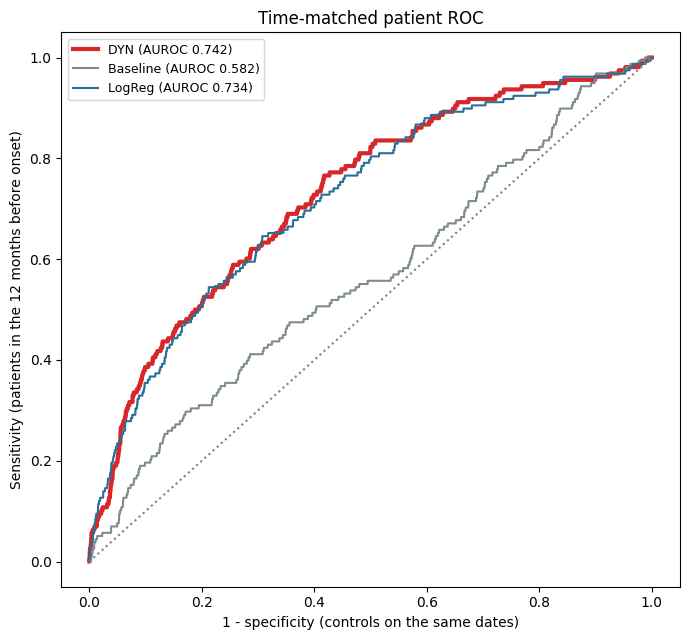

In [19]:
"""Time-matched patient metrics of every model; ROC curves."""
rows = [{"Model": short_label(m), "Time-matched AUROC": fmtk((m,) + K_TM),
          "Sensitivity": fmtk((m, "tm", "main", "sensitivity")), "Specificity": fmtk((m, "tm", "main", "specificity")),
          "Balanced accuracy": fmtk((m, "tm", "main", "balanced_accuracy")), "Visit AUROC 12 mo": fmtk((m,) + K_VIS)}
        for m in sorted(MODELS_RUN, key=lambda m: -ci((m,) + K_TM)[0])]
TM_TABLE = pd.DataFrame(rows).set_index("Model")
display(TM_TABLE)
TM_TABLE.to_csv(f"objective1_time_matched_{TAG}.csv")
fig, ax = plt.subplots(figsize=(7, 6.5))
d = TM["main"]
for m in KEY_MODELS:
    z = zpred(m, REPEATS[0])
    s = np.asarray(d["mat"] @ np.nan_to_num(z)).ravel()
    sc = np.r_[s[d["cases"]], s[d["pk"]]]
    yy = np.r_[np.ones(len(d["cases"])), np.zeros(len(d["pk"]))]
    ww = np.r_[np.ones(len(d["cases"])) / len(d["cases"]), d["w"] / d["w"].sum()]
    fpr, tpr, _ = roc_curve(yy, sc, sample_weight=ww)
    ax.plot(fpr, tpr, color=model_color(m), lw=3 if m == MAIN_MODEL else 1.5,
            label=f"{short_label(m)} (AUROC {ci((m,) + K_TM)[0]:.3f})")
ax.plot([0, 1], [0, 1], ":", color="grey"); ax.set_xlabel("1 - specificity (controls on the same dates)")
ax.set_ylabel("Sensitivity (patients in the 12 months before onset)"); ax.legend(fontsize=9)
ax.set_title("Time-matched patient ROC")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_tm_roc.png", dpi=150, bbox_inches="tight"); plt.show()

## 13.3 H1c: calibration — every model

Calibration slope and intercept of the 12-month risk (visit level, IPCW) and of the patient probability; O/E at
both levels. Criterion (H1c, visit level): slope in [0.8, 1.2] and the intercept's 95 % CI containing 0. The risks
are recalibrated inside each training fold, so this checks that the recalibration transports to held-out patients.

,Visit slope,Visit intercept,Visit O/E,H1b met,Patient slope,Patient intercept,Patient O/E
Model,,,,,,,
S0 v8-main,1.057 (0.829 to 1.288),-0.012 (-0.201 to 0.174),1.015 (0.837 to 1.212),True,1.054 (0.910 to 1.236),0.032 (-0.182 to 0.233),1.022 (0.877 to 1.175)
S1 no-pool,1.061 (0.853 to 1.265),0.004 (-0.185 to 0.194),1.029 (0.845 to 1.227),True,1.043 (0.903 to 1.222),0.037 (-0.181 to 0.244),1.026 (0.876 to 1.182)
S2 bands,1.050 (0.842 to 1.255),0.022 (-0.166 to 0.216),1.047 (0.864 to 1.251),True,1.006 (0.862 to 1.180),0.073 (-0.149 to 0.277),1.051 (0.899 to 1.208)
DYN-bands,1.067 (0.870 to 1.289),0.029 (-0.169 to 0.213),1.054 (0.866 to 1.257),True,1.018 (0.876 to 1.201),0.089 (-0.134 to 0.294),1.063 (0.907 to 1.216)
DYN,1.056 (0.878 to 1.257),0.011 (-0.188 to 0.201),1.037 (0.849 to 1.230),True,1.042 (0.908 to 1.216),0.052 (-0.182 to 0.265),1.036 (0.887 to 1.196)
Two-part,1.116 (0.855 to 1.337),0.018 (-0.161 to 0.193),1.043 (0.858 to 1.238),True,1.102 (0.947 to 1.282),0.064 (-0.151 to 0.259),1.047 (0.887 to 1.199)
Reg-DYN,1.032 (0.812 to 1.238),-0.019 (-0.224 to 0.168),1.003 (0.826 to 1.194),True,1.026 (0.871 to 1.204),-0.005 (-0.233 to 0.211),0.996 (0.853 to 1.150)
LogReg,0.909 (0.727 to 1.075),-0.050 (-0.258 to 0.135),0.974 (0.802 to 1.152),True,0.885 (0.761 to 1.038),0.005 (-0.241 to 0.235),1.003 (0.857 to 1.159)
Reg-v7,1.028 (0.828 to 1.235),-0.023 (-0.209 to 0.158),0.999 (0.826 to 1.194),True,1.031 (0.887 to 1.202),-0.004 (-0.220 to 0.200),0.997 (0.854 to 1.146)


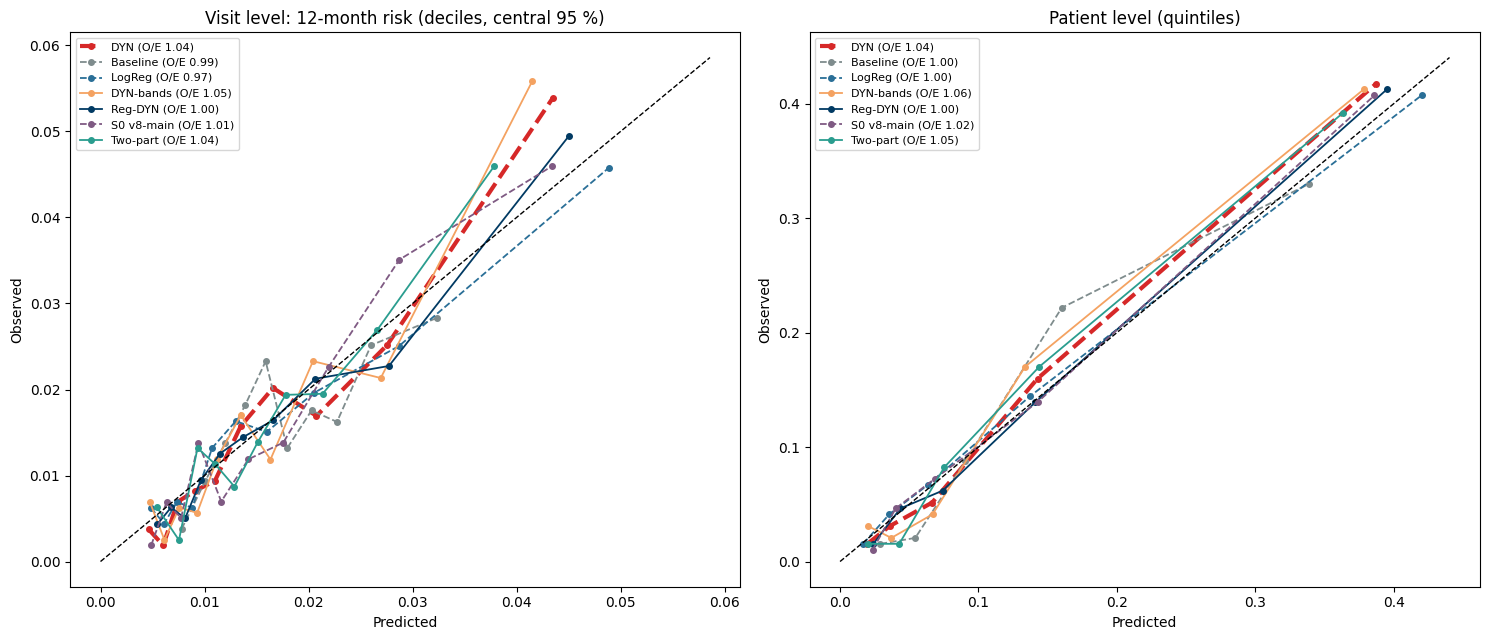

In [20]:
"""H1b: calibration of every model; calibration plots."""
rows = []
for m in MODELS_RUN:
    sl, ic = ci((m, "visit", H, "cal_slope")), ci((m, "visit", H, "cal_intercept"))
    met = CAL_SLOPE_RANGE[0] <= sl[0] <= CAL_SLOPE_RANGE[1] and ic[1] <= 0 <= ic[2]
    rows.append({"Model": short_label(m), "Visit slope": fmt(*sl), "Visit intercept": fmt(*ic),
                 "Visit O/E": fmtk((m, "visit", H, "oe")), "H1b met": met,
                 "Patient slope": fmtk((m, "patient", H, "cal_slope")),
                 "Patient intercept": fmtk((m, "patient", H, "cal_intercept")),
                 "Patient O/E": fmtk((m, "patient", H, "oe"))})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H1c", "Estimand": "Main: visit calibration slope / intercept",
                         "Estimate (95% CI)": f"{fmt(*sl)} / {fmt(*ic)}",
                         "Criterion": "slope in [0.8, 1.2], intercept CI includes 0", "Met": met})
CAL_TABLE = pd.DataFrame(rows).set_index("Model")
display(CAL_TABLE)
CAL_TABLE.to_csv(f"objective1_calibration_{TAG}.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for m in FIG_MODELS:
    if m not in MODELS_RUN:
        continue
    xs, ys = calib_bins(Y_IPCW, _expit(mean_z(m)[ROWS_IPCW]), WI_IPCW, 10)
    axes[0].plot(xs, ys, "o-", color=model_color(m), ls=model_ls(m), lw=3 if m == MAIN_MODEL else 1.3, ms=4,
                 label=f"{short_label(m)} (O/E {ci((m, 'visit', H, 'oe'))[0]:.2f})")
    pp = np.mean([patient_prob(m, r) for r in REPEATS], 0)
    xs, ys = calib_bins(PTW[H]["event"].astype(float), pp, np.ones(len(pp)), 5, central=False)
    axes[1].plot(xs, ys, "o-", color=model_color(m), ls=model_ls(m), lw=3 if m == MAIN_MODEL else 1.3, ms=4,
                 label=f"{short_label(m)} (O/E {ci((m, 'patient', H, 'oe'))[0]:.2f})")
for ax, ttl in zip(axes, ["Visit level: 12-month risk (deciles, central 95 %)", "Patient level (quintiles)"]):
    top = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, top], [0, top], "k--", lw=1)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Observed"); ax.set_title(ttl); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_calibration_all.png", dpi=150, bbox_inches="tight"); plt.show()

## 13.4 Decision curves and fixed risk thresholds (descriptive)

Visit-level net benefit per landmark visit (IPCW) of alarming when the 12-month risk ≥ *t*, against alarming at
every visit and at none. Criterion (H1d): the main model's net benefit above both at every threshold from 2 % to
10 % (point estimate; the share of thresholds where the lower 95 % bound is also above is reported). Then
sensitivity, specificity, PPV and NPV at fixed 12-month risks of 5 % and 10 %.

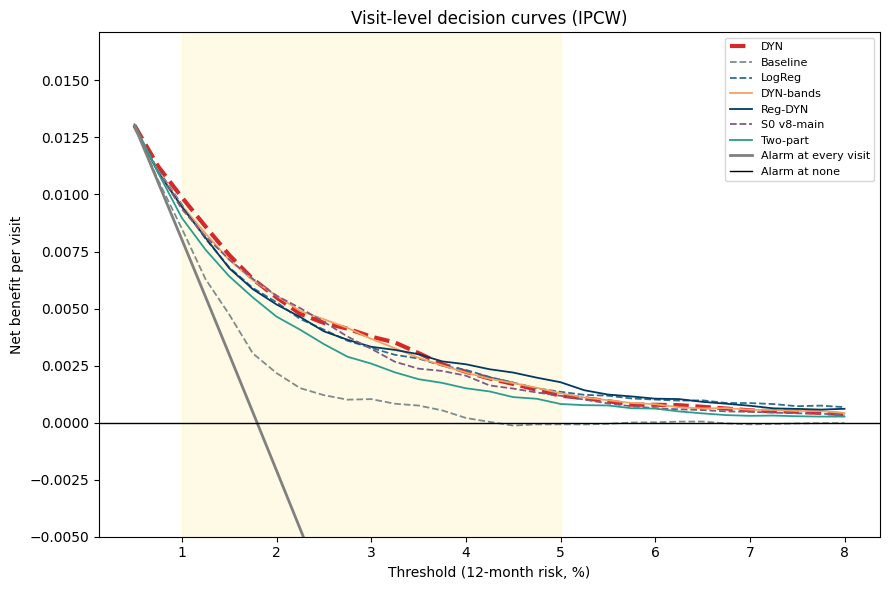

,Thresholds 2-10 % with NB above both (point),... (lower 95 % bound),NB at 2%,NB at 4%,NB at 6%,NB at 10%
Model,,,,,,
S0 v8-main,17/17,15/17,0.0056 (0.0031 to 0.0081),0.0021 (0.0005 to 0.0037),0.0006 (-0.0003 to 0.0017),-
S1 no-pool,17/17,15/17,0.0058 (0.0035 to 0.0083),0.0023 (0.0007 to 0.0039),0.0005 (-0.0004 to 0.0015),-
S2 bands,17/17,16/17,0.0056 (0.0032 to 0.0081),0.0023 (0.0007 to 0.0039),0.0008 (-0.0001 to 0.0018),-
DYN-bands,17/17,16/17,0.0056 (0.0032 to 0.0080),0.0022 (0.0007 to 0.0037),0.0008 (-0.0001 to 0.0018),-
DYN,17/17,16/17,0.0055 (0.0032 to 0.0078),0.0022 (0.0007 to 0.0037),0.0008 (-0.0002 to 0.0017),-
Two-part,17/17,14/17,0.0046 (0.0024 to 0.0071),0.0015 (0.0003 to 0.0028),0.0006 (-0.0001 to 0.0014),-
Reg-DYN,17/17,15/17,0.0052 (0.0030 to 0.0076),0.0026 (0.0010 to 0.0043),0.0011 (0.0000 to 0.0021),-
LogReg,17/17,15/17,0.0053 (0.0031 to 0.0076),0.0023 (0.0007 to 0.0039),0.0010 (-0.0001 to 0.0022),-
Reg-v7,17/17,11/17,0.0059 (0.0035 to 0.0084),0.0018 (0.0002 to 0.0034),0.0009 (-0.0002 to 0.0020),-


,Model,12-month risk >=,Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,S0 v8-main,2%,0.642 (0.566 to 0.721),0.703 (0.675 to 0.729),0.038 (0.030 to 0.047),0.991 (0.988 to 0.993),0.672 (0.635 to 0.712),0.304 (0.277 to 0.331)
1,S0 v8-main,5%,0.196 (0.138 to 0.262),0.955 (0.942 to 0.965),0.074 (0.050 to 0.104),0.985 (0.982 to 0.988),0.575 (0.548 to 0.609),0.048 (0.037 to 0.061)
2,S1 no-pool,2%,0.634 (0.563 to 0.712),0.722 (0.696 to 0.748),0.040 (0.032 to 0.049),0.991 (0.988 to 0.993),0.678 (0.642 to 0.715),0.284 (0.258 to 0.310)
3,S1 no-pool,5%,0.201 (0.143 to 0.262),0.951 (0.940 to 0.961),0.070 (0.049 to 0.094),0.985 (0.982 to 0.988),0.576 (0.548 to 0.605),0.052 (0.042 to 0.063)
4,S2 bands,2%,0.616 (0.540 to 0.695),0.726 (0.703 to 0.752),0.040 (0.031 to 0.048),0.990 (0.988 to 0.993),0.671 (0.634 to 0.709),0.280 (0.255 to 0.303)
5,S2 bands,5%,0.203 (0.146 to 0.268),0.954 (0.941 to 0.964),0.074 (0.052 to 0.101),0.985 (0.982 to 0.988),0.578 (0.550 to 0.610),0.049 (0.039 to 0.062)
6,DYN-bands,2%,0.613 (0.539 to 0.689),0.729 (0.707 to 0.752),0.040 (0.032 to 0.048),0.990 (0.988 to 0.993),0.671 (0.634 to 0.710),0.277 (0.255 to 0.299)
7,DYN-bands,5%,0.188 (0.136 to 0.247),0.960 (0.949 to 0.968),0.080 (0.055 to 0.109),0.985 (0.982 to 0.988),0.574 (0.549 to 0.602),0.043 (0.034 to 0.054)
8,DYN,2%,0.613 (0.542 to 0.689),0.725 (0.702 to 0.748),0.039 (0.031 to 0.047),0.990 (0.988 to 0.993),0.669 (0.632 to 0.706),0.281 (0.258 to 0.305)
9,DYN,5%,0.200 (0.150 to 0.255),0.953 (0.944 to 0.962),0.074 (0.052 to 0.098),0.985 (0.982 to 0.988),0.577 (0.552 to 0.604),0.049 (0.041 to 0.059)


In [21]:
"""H1d: decision curves; fixed risk thresholds."""
fig, ax = plt.subplots(figsize=(9, 6))
for m in FIG_MODELS:
    if m in MODELS_RUN:
        ax.plot(NB_GRID * 100, [ci((m, "visit", H, "nb", t))[0] for t in NB_GRID], color=model_color(m),
                ls=model_ls(m), lw=3 if m == MAIN_MODEL else 1.3, label=short_label(m))
ax.plot(NB_GRID * 100, [ci((MAIN_MODEL, "visit", H, "nb_all", t))[0] for t in NB_GRID], color="grey", lw=2,
        label="Alarm at every visit")
ax.axhline(0, color="k", lw=1, label="Alarm at none")
ax.axvspan(H1D_RANGE[0] * 100, H1D_RANGE[1] * 100, color="gold", alpha=0.1)
ax.set_ylim(-0.005, None); ax.set_xlabel("Threshold (12-month risk, %)"); ax.set_ylabel("Net benefit per visit")
ax.set_title("Visit-level decision curves (IPCW)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_decision_curves.png", dpi=150, bbox_inches="tight"); plt.show()

_ts = [t for t in NB_GRID if H1D_RANGE[0] - 1e-9 <= t <= H1D_RANGE[1] + 1e-9]
rows = []
for m in MODELS_RUN:
    above, above_lo = 0, 0
    for t in _ts:
        nb = ci((m, "visit", H, "nb", t)); nba = ci((m, "visit", H, "nb_all", t))[0]
        above += nb[0] > max(nba, 0); above_lo += nb[1] > max(nba, 0)
    rows.append({"Model": short_label(m), "Thresholds 2-10 % with NB above both (point)": f"{above}/{len(_ts)}",
                 "... (lower 95 % bound)": f"{above_lo}/{len(_ts)}",
                 **{f"NB at {t:.0%}": fmtk((m, "visit", H, "nb", t), 4) for t in [0.02, 0.04, 0.06, 0.10]}})
NB_TABLE = pd.DataFrame(rows).set_index("Model")
display(NB_TABLE)
NB_TABLE.to_csv(f"objective1_h1d_net_benefit_{TAG}.csv")
rows = []
for m in MODELS_RUN:
    for t in FIXED_RISKS:
        rows.append({"Model": short_label(m), "12-month risk >=": f"{t:.0%}",
                     **{METRIC_LABELS[x]: fmtk((m, "visit", H, "fixed", t, x)) for x in CONF_METRICS}})
FIXED_TABLE = pd.DataFrame(rows)
display(FIXED_TABLE)
FIXED_TABLE.to_csv(f"objective1_fixed_thresholds_{TAG}.csv", index=False)

## 13.5 Risk tiers: the clinical output

A single yes/no alarm at a 12-month risk of about 2 % has a PPV of about 4 %, because onsets are rare (1.8 % of
visits). The model is more useful as a **risk tier**: the recalibrated 12-month risk in four fixed tiers
(< 1 %, 1-2 %, 2-5 %, ≥ 5 %; fixed in advance, not tuned), read as

* **< 1 % — low**: routine follow-up; the **rule-out** tier (what share of visits it covers, and what share of the
  onsets it misses);
* **1-2 % — average** (the cohort's 12-month onset risk is 1.8 %);
* **2-5 % — raised**: ask about work at the visit;
* **≥ 5 % — high**: discuss work, refer (occupational therapy, social work, vocational rehabilitation).

Four views, for the main model and the comparators:
1. **By visit**: share of visits and of patients ever in the tier, mean predicted vs observed 12-month risk (IPCW,
   95 % CI) and the share of all 12-month onsets that arose from the tier.
2. **Rule-out**: cumulative tiers below 1 % and below 2 %: visits covered, observed risk (1 − NPV) and onsets missed.
3. **By patient on the same dates** (time-matched, Section 11.8): each onset patient's mean risk over the 12 months
   before the onset, and each control's mean risk over the same calendar window, put in a tier; the share of onset
   patients and of controls in each tier and the likelihood ratio (onset share / control share).
4. **Movement and era**: how often a patient's tier changes from one visit to the next, and the tiers in the recent
   era (landmarks from 2012 on).

Share of visits Share of patients ever in tier Mean predicted         Observed (IPCW)         Share of onsets
Model     Tier                                                                                                                
DYN       < 1 %            42.0%                          66.7%          0.006  0.005 (0.003 to 0.008)  0.122 (0.077 to 0.169)
          1-2 %            30.9%                          77.0%          0.014  0.015 (0.011 to 0.020)  0.264 (0.210 to 0.317)
          2-5 %            22.3%                          59.9%          0.030  0.032 (0.025 to 0.039)  0.413 (0.355 to 0.470)
          >= 5 %            4.8%                          20.2%          0.075  0.074 (0.052 to 0.098)  0.200 (0.150 to 0.255)
Baseline  < 1 %            19.7%                          45.6%          0.007  0.007 (0.004 to 0.011)  0.067 (0.036 to 0.106)
          1-2 %            45.2%                          62.9%          0.015  0.016 (0.012 to 0.020)  0.405 (0.327 to 0.483)
          2-5 %            34.2%                          44.3%          0.027  0.025 (0.019 to 0.032)  0.503 (0.421 to 0.585)
          >= 5 %            1.0%                           1.9%          0.059  0.041 (0.012 to 0.084)  0.025 (0.007 to 0.053)
LogReg    < 1 %            43.4%                          72.0%          0.007  0.006 (0.004 to 0.009)  0.150 (0.101 to 0.199)
          1-2 %            30.2%                          75.3%          0.014  0.015 (0.011 to 0.020)  0.258 (0.205 to 0.316)
          2-5 %            20.1%                          62.7%          0.030  0.029 (0.023 to 0.037)  0.340 (0.281 to 0.398)
          >= 5 %            6.2%                          30.3%          0.083  0.070 (0.050 to 0.091)  0.252 (0.193 to 0.314)
DYN-bands < 1 %            40.5%                          64.4%          0.006  0.006 (0.004 to 0.009)  0.134 (0.085 to 0.184)
          1-2 %            32.9%                          77.9%          0.014  0.014 (0.010 to 0.018)  0.254 (0.201 to 0.309)
          2-5 %            22.5%                          58.9%          0.030  0.033 (0.026 to 0.040)  0.425 (0.362 to 0.487)
          >= 5 %            4.1%                          16.8%          0.074  0.080 (0.055 to 0.109)  0.188 (0.136 to 0.247)

Visits covered Observed 12-month risk (1 - NPV) Onsets missed (share of all)
Model     Rule-out tier                                                                             
DYN       below 1 %              42.0%           0.005 (0.003 to 0.008)       0.122 (0.077 to 0.169)
          below 2 %              72.9%           0.010 (0.007 to 0.012)       0.387 (0.311 to 0.458)
Baseline  below 1 %              19.7%           0.007 (0.004 to 0.011)       0.067 (0.036 to 0.106)
          below 2 %              64.8%           0.013 (0.010 to 0.017)       0.472 (0.390 to 0.558)
LogReg    below 1 %              43.4%           0.006 (0.004 to 0.009)       0.150 (0.101 to 0.199)
          below 2 %              73.6%           0.010 (0.008 to 0.013)       0.409 (0.335 to 0.481)
DYN-bands below 1 %              40.5%           0.006 (0.004 to 0.009)       0.134 (0.085 to 0.184)
          below 2 %              73.4%           0.010 (0.007 to 0.012)       0.387 (0.311 to 0.461)

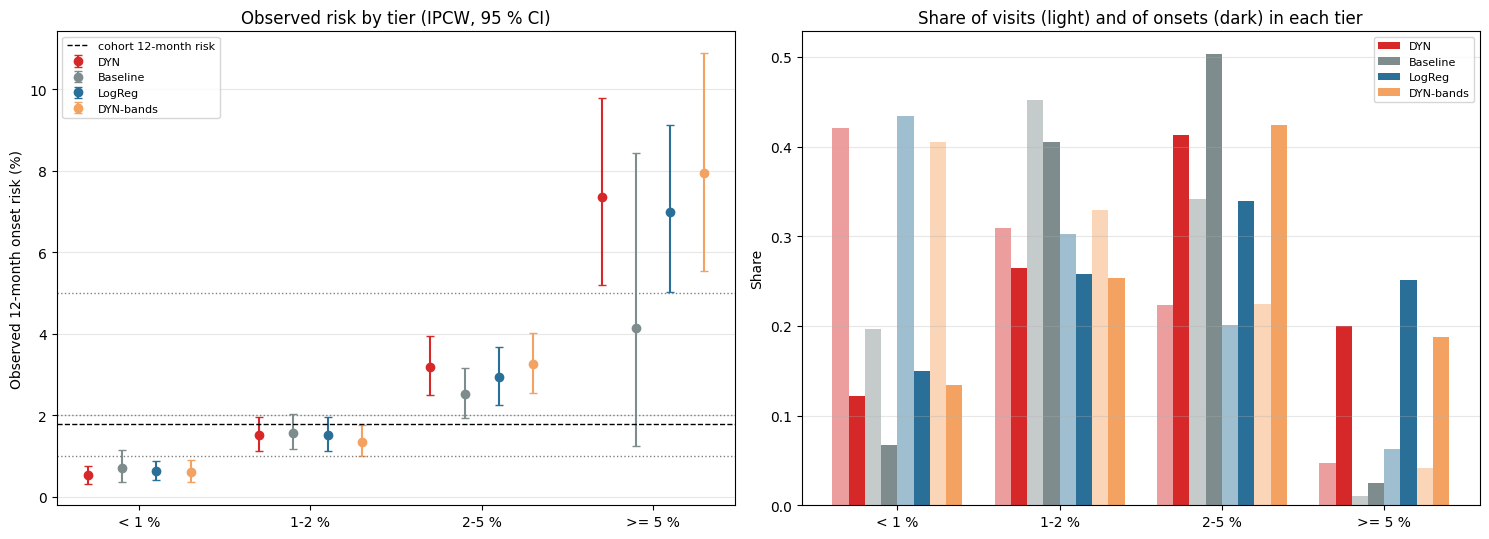

In [22]:
"""Risk tiers by visit and the rule-out tiers."""
TIER_MODELS = [m for m in KEY_MODELS + [DYN_BANDS] if m in MODELS_RUN]
TIER_NAMES = [n for _, _, n in RISK_TIERS]
rows = []
for m in TIER_MODELS:
    for name in TIER_NAMES:
        k = (m, "visit", H, "tier", name)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits": f"{ci(k + ('share_visits',))[0]:.1%}",
                     "Share of patients ever in tier": f"{ci(k + ('share_patients',))[0]:.1%}",
                     "Mean predicted": f"{ci(k + ('mean_pred',))[0]:.3f}",
                     "Observed (IPCW)": fmtk(k + ("observed",)), "Share of onsets": fmtk(k + ("share_onsets",))})
TIERS = pd.DataFrame(rows)
display(TIERS.set_index(["Model", "Tier"]))
TIERS.to_csv(f"objective1_risk_tiers_{TAG}.csv", index=False)

rows = []
for m in TIER_MODELS:
    for _, _, name in RULE_OUT_TIERS:
        k = (m, "visit", H, "tier", name)
        rows.append({"Model": short_label(m), "Rule-out tier": name,
                     "Visits covered": f"{ci(k + ('share_visits',))[0]:.1%}",
                     "Observed 12-month risk (1 - NPV)": fmtk(k + ("observed",)),
                     "Onsets missed (share of all)": fmtk(k + ("share_onsets",))})
RULE_OUT = pd.DataFrame(rows)
display(RULE_OUT.set_index(["Model", "Rule-out tier"]))
RULE_OUT.to_csv(f"objective1_rule_out_{TAG}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
xx = np.arange(len(TIER_NAMES))
wd = 0.8 / len(TIER_MODELS)
for j, m in enumerate(TIER_MODELS):
    obs = np.array([ci((m, "visit", H, "tier", n, "observed")) for n in TIER_NAMES])
    shv = [ci((m, "visit", H, "tier", n, "share_visits"))[0] for n in TIER_NAMES]
    sho = np.array([ci((m, "visit", H, "tier", n, "share_onsets")) for n in TIER_NAMES])
    off = (j - (len(TIER_MODELS) - 1) / 2) * wd
    axes[0].errorbar(xx + off, 100 * obs[:, 0], yerr=[100 * (obs[:, 0] - obs[:, 1]), 100 * (obs[:, 2] - obs[:, 0])],
                     fmt="o", color=model_color(m), capsize=3, label=short_label(m))
    axes[1].bar(xx + off - wd / 4, shv, wd / 2, color=model_color(m), alpha=0.45)
    axes[1].bar(xx + off + wd / 4, sho[:, 0], wd / 2, color=model_color(m), label=short_label(m))
for t in (1, 2, 5):
    axes[0].axhline(t, color="grey", ls=":", lw=1)
axes[0].axhline(100 * CIF_IPCW[H], color="k", ls="--", lw=1, label="cohort 12-month risk")
axes[0].set_xticks(xx); axes[0].set_xticklabels(TIER_NAMES); axes[0].set_ylabel("Observed 12-month onset risk (%)")
axes[0].set_title("Observed risk by tier (IPCW, 95 % CI)"); axes[0].legend(fontsize=8); axes[0].grid(axis="y", alpha=0.3)
axes[1].set_xticks(xx); axes[1].set_xticklabels(TIER_NAMES); axes[1].set_ylabel("Share")
axes[1].set_title("Share of visits (light) and of onsets (dark) in each tier"); axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_risk_tiers.png", dpi=150, bbox_inches="tight"); plt.show()

Onset patients (12 mo before onset) Patients still working, same dates     Likelihood ratio
Model     Tier                                                                                              
DYN       < 1 %               0.111 (0.070 to 0.156)             0.347 (0.305 to 0.393)  0.32 (0.21 to 0.44)
          1-2 %               0.261 (0.207 to 0.316)             0.335 (0.314 to 0.358)  0.78 (0.61 to 0.95)
          2-5 %               0.443 (0.381 to 0.505)             0.270 (0.239 to 0.302)  1.64 (1.40 to 1.91)
          >= 5 %              0.185 (0.133 to 0.237)             0.047 (0.036 to 0.060)  3.92 (2.80 to 5.45)
Baseline  < 1 %               0.071 (0.040 to 0.105)             0.107 (0.078 to 0.140)  0.66 (0.41 to 0.96)
          1-2 %               0.399 (0.328 to 0.466)             0.417 (0.379 to 0.456)  0.96 (0.81 to 1.11)
          2-5 %               0.506 (0.434 to 0.578)             0.464 (0.412 to 0.511)  1.09 (0.94 to 1.25)
          >= 5 %              0.024 (0.009 to 0.043)             0.013 (0.007 to 0.020)  1.91 (0.75 to 3.56)
LogReg    < 1 %               0.139 (0.094 to 0.187)             0.389 (0.348 to 0.433)  0.36 (0.25 to 0.47)
          1-2 %               0.248 (0.196 to 0.305)             0.324 (0.304 to 0.346)  0.77 (0.61 to 0.94)
          2-5 %               0.372 (0.301 to 0.437)             0.225 (0.201 to 0.252)  1.65 (1.34 to 1.96)
          >= 5 %              0.241 (0.181 to 0.302)             0.061 (0.048 to 0.077)  3.93 (2.92 to 5.14)
DYN-bands < 1 %               0.122 (0.080 to 0.167)             0.309 (0.268 to 0.355)  0.39 (0.27 to 0.52)
          1-2 %               0.256 (0.202 to 0.311)             0.373 (0.352 to 0.395)  0.69 (0.54 to 0.84)
          2-5 %               0.453 (0.393 to 0.523)             0.276 (0.243 to 0.309)  1.64 (1.42 to 1.91)
          >= 5 %              0.170 (0.120 to 0.220)             0.041 (0.030 to 0.055)  4.11 (2.89 to 5.74)

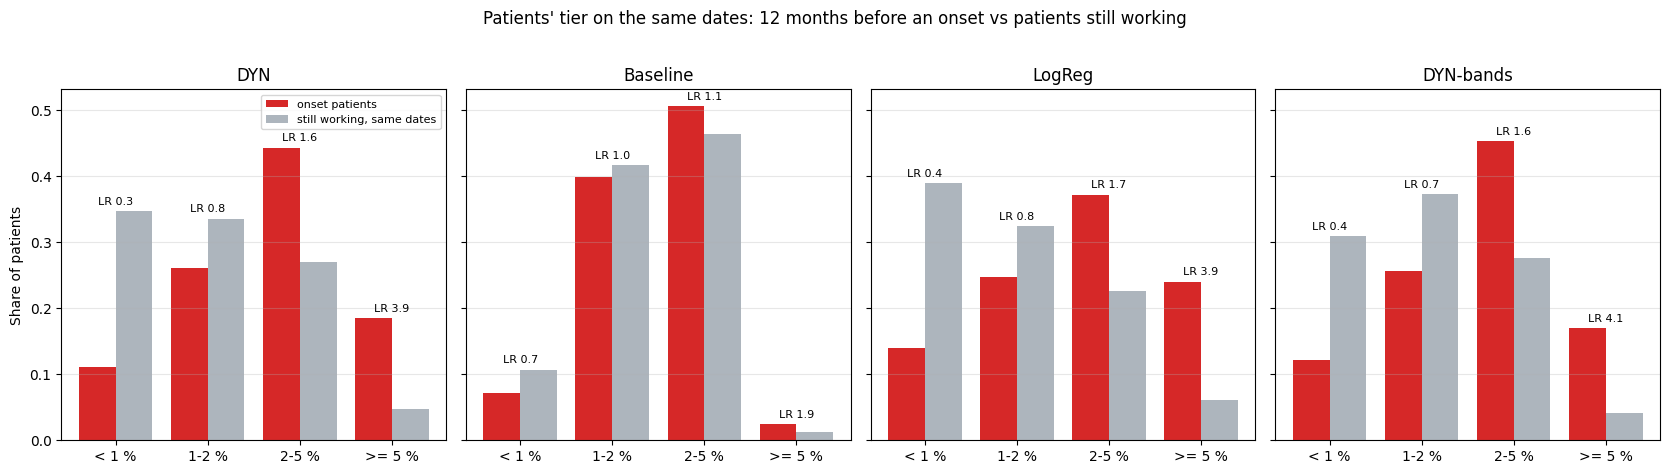

Tier at the next visit,< 1 %,1-2 %,2-5 %,>= 5 %
Tier at a visit,,,,
< 1 %,0.915,0.078,0.007,0.000
1-2 %,0.195,0.678,0.122,0.005
2-5 %,0.016,0.251,0.657,0.076
>= 5 %,0.003,0.019,0.418,0.561


DYN: the tier stays the same at 77% of consecutive visits and moves by more than one tier at 0.9%. Patients ever in the >= 5 % tier: 20%; of them, 33% have an onset (vs 10% of the others).
Recent era (landmarks from 2012 on):


Share of visits (labelled, IPCW)         Observed (IPCW)         Share of onsets
Model     Tier                                                                                      
DYN       < 1 %               0.604 (0.572 to 0.635)  0.005 (0.002 to 0.007)  0.245 (0.126 to 0.379)
          1-2 %               0.257 (0.239 to 0.276)  0.013 (0.008 to 0.020)  0.297 (0.196 to 0.408)
          2-5 %               0.123 (0.105 to 0.142)  0.029 (0.016 to 0.045)  0.324 (0.213 to 0.445)
          >= 5 %              0.015 (0.010 to 0.022)  0.098 (0.038 to 0.172)  0.134 (0.059 to 0.226)
          below 1 %           0.604 (0.572 to 0.635)  0.005 (0.002 to 0.007)  0.245 (0.126 to 0.379)
          below 2 %           0.861 (0.838 to 0.882)  0.007 (0.004 to 0.010)  0.542 (0.398 to 0.697)
Baseline  < 1 %               0.346 (0.317 to 0.374)  0.006 (0.003 to 0.010)  0.189 (0.093 to 0.310)
          1-2 %               0.565 (0.539 to 0.590)  0.011 (0.007 to 0.016)  0.559 (0.408 to 0.694)
          2-5 %               0.089 (0.071 to 0.107)  0.032 (0.013 to 0.055)  0.250 (0.116 to 0.396)
          >= 5 %              0.001 (0.000 to 0.003)  0.019 (0.000 to 1.000)  0.002 (0.000 to 0.008)
          below 1 %           0.346 (0.317 to 0.374)  0.006 (0.003 to 0.010)  0.189 (0.093 to 0.310)
          below 2 %           0.910 (0.892 to 0.928)  0.009 (0.006 to 0.013)  0.748 (0.602 to 0.883)
LogReg    < 1 %               0.576 (0.544 to 0.607)  0.005 (0.002 to 0.009)  0.282 (0.147 to 0.422)
          1-2 %               0.265 (0.246 to 0.285)  0.010 (0.006 to 0.015)  0.232 (0.148 to 0.328)
          2-5 %               0.132 (0.115 to 0.149)  0.027 (0.014 to 0.042)  0.315 (0.203 to 0.432)
          >= 5 %              0.027 (0.020 to 0.035)  0.071 (0.031 to 0.121)  0.171 (0.080 to 0.277)
          below 1 %           0.576 (0.544 to 0.607)  0.005 (0.002 to 0.009)  0.282 (0.147 to 0.422)
          below 2 %           0.841 (0.819 to 0.862)  0.007 (0.004 to 0.010)  0.514 (0.370 to 0.665)
DYN-bands < 1 %               0.613 (0.583 to 0.640)  0.005 (0.002 to 0.008)  0.278 (0.155 to 0.420)
          1-2 %               0.276 (0.258 to 0.294)  0.012 (0.007 to 0.018)  0.299 (0.199 to 0.412)
          2-5 %               0.101 (0.085 to 0.117)  0.035 (0.019 to 0.055)  0.316 (0.202 to 0.437)
          >= 5 %              0.010 (0.006 to 0.015)  0.125 (0.044 to 0.222)  0.106 (0.037 to 0.193)
          below 1 %           0.613 (0.583 to 0.640)  0.005 (0.002 to 0.008)  0.278 (0.155 to 0.420)
          below 2 %           0.888 (0.869 to 0.907)  0.007 (0.004 to 0.010)  0.578 (0.434 to 0.728)

Risk tiers (DYN): the < 1 % tier covers 42% of visits with an observed 12-month risk of 0.005 (0.003 to 0.008) and
misses 0.122 (0.077 to 0.169) of the onsets; the >= 5 % tier covers 5% of visits with an observed risk of 0.074 (0.052
to 0.098) and holds 0.200 (0.150 to 0.255) of the onsets. On the same dates, onset patients are in the >= 5 % tier 18%
of the time vs 5% of patients still working (LR 3.9); in the < 1 % tier 11% vs 35% (LR 0.32).


In [23]:
"""Risk tiers by patient on the same dates (time-matched), tier movement and the recent era."""


def tm_tiers(m):
    """Per tier: share of onset patients and of time-matched controls (each onset's controls weighted equally), and
    the likelihood ratio; repeat means of the bootstrap arrays (point = first entry)."""
    d = TM["main"]
    Wc = _BOTH[:, d["case_pid"]]
    acc = {n: [] for n in TIER_NAMES}
    for r in REPEATS:
        p_ = _expit(np.asarray(d["mat"] @ np.nan_to_num(zpred(m, r))).ravel())
        for lo, hi, n in RISK_TIERS:
            inn = (p_ >= lo) & (p_ < hi)
            case = (Wc @ inn[d["cases"]].astype(np.float32)) / Wc.sum(1)
            Kc = sparse.coo_matrix((d["w"] * inn[d["pk"]], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
            ctrl = _pair_sum_fast(_BOTH, Kc) / d["wden"]
            acc[n].append((case, ctrl))
    out = {}
    for n in TIER_NAMES:
        case = np.mean([a for a, _ in acc[n]], 0); ctrl = np.mean([b for _, b in acc[n]], 0)
        lr = case / np.where(ctrl > 0, ctrl, np.nan)
        out[n] = {k_: (v[0], np.nanpercentile(v[1:], 2.5), np.nanpercentile(v[1:], 97.5))
                  for k_, v in [("case", case), ("ctrl", ctrl), ("lr", lr)]}
    return out


TM_TIERS = {m: tm_tiers(m) for m in TIER_MODELS}
rows = [{"Model": short_label(m), "Tier": n, "Onset patients (12 mo before onset)": fmt(*v["case"]),
         "Patients still working, same dates": fmt(*v["ctrl"]), "Likelihood ratio": fmt(*v["lr"], nd=2)}
        for m, t_ in TM_TIERS.items() for n, v in t_.items()]
TM_TIER_TABLE = pd.DataFrame(rows)
display(TM_TIER_TABLE.set_index(["Model", "Tier"]))
TM_TIER_TABLE.to_csv(f"objective1_tiers_time_matched_{TAG}.csv", index=False)

fig, axes = plt.subplots(1, len(TIER_MODELS), figsize=(4.2 * len(TIER_MODELS), 4.6), sharey=True)
for ax, m in zip(np.atleast_1d(axes), TIER_MODELS):
    t_ = TM_TIERS[m]
    ax.bar(xx - 0.2, [t_[n]["case"][0] for n in TIER_NAMES], 0.4, color="#d62828", label="onset patients")
    ax.bar(xx + 0.2, [t_[n]["ctrl"][0] for n in TIER_NAMES], 0.4, color="#adb5bd", label="still working, same dates")
    for x_, n in zip(xx, TIER_NAMES):
        ax.text(x_, max(t_[n]["case"][0], t_[n]["ctrl"][0]) + 0.01, f"LR {t_[n]['lr'][0]:.1f}", ha="center", fontsize=8)
    ax.set_xticks(xx); ax.set_xticklabels(TIER_NAMES); ax.set_title(short_label(m)); ax.grid(axis="y", alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("Share of patients"); np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle("Patients' tier on the same dates: 12 months before an onset vs patients still working", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_risk_tiers_time_matched.png", dpi=150, bbox_inches="tight"); plt.show()

# tier movement between consecutive visits (main model, mean over repeats)
_tier_of = lambda p_: np.digitize(p_, [lo for lo, _, _ in RISK_TIERS[1:]])
_tz = _tier_of(_expit(mean_z(MAIN_MODEL)))
_a, _b = [], []
for pid, li in PT_ROWS.items():
    if len(li) > 1:
        _a.append(_tz[li[:-1]]); _b.append(_tz[li[1:]])
_a, _b = np.concatenate(_a), np.concatenate(_b)
MOVE = pd.crosstab(pd.Categorical(np.array(TIER_NAMES)[_a], TIER_NAMES), pd.Categorical(np.array(TIER_NAMES)[_b], TIER_NAMES),
                   normalize="index", rownames=["Tier at a visit"], colnames=["Tier at the next visit"])
display(MOVE.round(3))
MOVE.to_csv(f"objective1_tier_movement_{TAG}.csv")
_ever_hi = pd.Series(_tz == 3).groupby(PID_ALL).max()
_ev_pt = pd.Series(land["pt_event"].values).groupby(PID_ALL).max()
print(f"{short_label(MAIN_MODEL)}: the tier stays the same at {np.mean(_a == _b):.0%} of consecutive visits and moves "
      f"by more than one tier at {np.mean(np.abs(_a - _b) > 1):.1%}. Patients ever in the >= 5 % tier: "
      f"{_ever_hi.mean():.0%}; of them, {_ev_pt[_ever_hi].mean():.0%} have an onset (vs "
      f"{_ev_pt[~_ever_hi].mean():.0%} of the others).")

rows = []
for m in TIER_MODELS:
    for _, _, name in RISK_TIERS + RULE_OUT_TIERS:
        k = (m, "visit", H, "tier_recent", name)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits (labelled, IPCW)": fmtk(k + ("share_visits",)),
                     "Observed (IPCW)": fmtk(k + ("observed",)), "Share of onsets": fmtk(k + ("share_onsets",))})
TIERS_RECENT = pd.DataFrame(rows)
print(f"Recent era (landmarks from {TIER_RECENT_FROM} on):")
display(TIERS_RECENT.set_index(["Model", "Tier"]))
TIERS_RECENT.to_csv(f"objective1_risk_tiers_recent_{TAG}.csv", index=False)
_lo = ci((MAIN_MODEL, "visit", H, "tier", "below 1 %", "observed")); _lo_m = ci((MAIN_MODEL, "visit", H, "tier", "below 1 %", "share_onsets"))
_hi = ci((MAIN_MODEL, "visit", H, "tier", ">= 5 %", "observed")); _hi_o = ci((MAIN_MODEL, "visit", H, "tier", ">= 5 %", "share_onsets"))
TIER_SUMMARY = (f"Risk tiers ({short_label(MAIN_MODEL)}): the < 1 % tier covers "
                f"{ci((MAIN_MODEL, 'visit', H, 'tier', 'below 1 %', 'share_visits'))[0]:.0%} of visits with an observed "
                f"12-month risk of {fmt(*_lo)} and misses {fmt(*_lo_m)} of the onsets; the >= 5 % tier covers "
                f"{ci((MAIN_MODEL, 'visit', H, 'tier', '>= 5 %', 'share_visits'))[0]:.0%} of visits with an observed "
                f"risk of {fmt(*_hi)} and holds {fmt(*_hi_o)} of the onsets. On the same dates, onset patients are in "
                f"the >= 5 % tier {TM_TIERS[MAIN_MODEL]['>= 5 %']['case'][0]:.0%} of the time vs "
                f"{TM_TIERS[MAIN_MODEL]['>= 5 %']['ctrl'][0]:.0%} of patients still working (LR "
                f"{TM_TIERS[MAIN_MODEL]['>= 5 %']['lr'][0]:.1f}); in the < 1 % tier {TM_TIERS[MAIN_MODEL]['< 1 %']['case'][0]:.0%}"
                f" vs {TM_TIERS[MAIN_MODEL]['< 1 %']['ctrl'][0]:.0%} (LR {TM_TIERS[MAIN_MODEL]['< 1 %']['lr'][0]:.2f}).")
print(textwrap.fill(TIER_SUMMARY, 118))

## 13.6 Calibration and discrimination by calendar era

Visit AUROC, patient AUROC and visit O/E within each calendar era (landmark year; for patients, the year of the
window's last landmark). The pooled AUROC also reflects differences between eras (pre-2000 onset risk was higher);
the within-era values are the ones a clinic would see today.

In [24]:
"""Discrimination and calibration by era."""
rows = []
for m in MODELS_RUN:
    row = {"Model": short_label(m)}
    for _, _, e in ERA_BANDS:
        row[f"Visit AUROC {e}"] = fmtk((m, "visit", H, "sub", f"Era: {e}", "auroc"))
    for _, _, e in ERA_BANDS:
        row[f"Patient AUROC {e}"] = fmtk((m, "patient", H, "sub", f"Era: {e}", "auroc"))
    for _, _, e in ERA_BANDS:
        row[f"Visit O/E {e}"] = f"{ci((m, 'visit', H, 'sub', f'Era: {e}', 'oe'))[0]:.2f}"
    rows.append(row)
ERA_TABLE = pd.DataFrame(rows).set_index("Model")
_era = ERA_TABLE.columns.str.startswith("Visit AUROC") | ERA_TABLE.columns.str.startswith("Patient AUROC")
display(ERA_TABLE.loc[:, _era]); display(ERA_TABLE.loc[:, ~_era])
ERA_TABLE.to_csv(f"objective1_by_era_{TAG}.csv")
_ey = LAND_SUB["era"].values
print("Landmarks with a known 12-month status / onsets by era: " + ", ".join(
    f"{e} {int((_ey[ROWS_IPCW] == e).sum()):,} / {int(Y_IPCW[_ey[ROWS_IPCW] == e].sum())}" for _, _, e in ERA_BANDS))

,Visit AUROC < 2000,Visit AUROC 2000-05,Visit AUROC 2006-11,Visit AUROC >= 2012,Patient AUROC < 2000,Patient AUROC 2000-05,Patient AUROC 2006-11,Patient AUROC >= 2012
Model,,,,,,,,
S0 v8-main,0.801 (0.730 to 0.869),0.667 (0.581 to 0.760),0.620 (0.531 to 0.704),0.728 (0.624 to 0.824),0.760 (0.641 to 0.866),0.710 (0.601 to 0.802),0.642 (0.533 to 0.752),0.797 (0.716 to 0.878)
S1 no-pool,0.794 (0.725 to 0.858),0.704 (0.619 to 0.787),0.626 (0.534 to 0.716),0.745 (0.646 to 0.836),0.768 (0.656 to 0.868),0.736 (0.631 to 0.822),0.634 (0.521 to 0.743),0.811 (0.726 to 0.892)
S2 bands,0.796 (0.722 to 0.862),0.710 (0.627 to 0.791),0.621 (0.537 to 0.707),0.726 (0.620 to 0.825),0.772 (0.655 to 0.874),0.744 (0.637 to 0.829),0.619 (0.505 to 0.728),0.787 (0.705 to 0.868)
DYN-bands,0.799 (0.734 to 0.859),0.703 (0.614 to 0.789),0.633 (0.538 to 0.724),0.717 (0.611 to 0.813),0.787 (0.670 to 0.882),0.744 (0.641 to 0.828),0.630 (0.519 to 0.737),0.781 (0.696 to 0.863)
DYN,0.798 (0.734 to 0.854),0.699 (0.609 to 0.784),0.642 (0.558 to 0.728),0.740 (0.644 to 0.828),0.782 (0.670 to 0.879),0.741 (0.637 to 0.825),0.641 (0.527 to 0.746),0.813 (0.727 to 0.891)
Two-part,0.719 (0.630 to 0.806),0.678 (0.587 to 0.766),0.599 (0.490 to 0.706),0.703 (0.606 to 0.789),0.661 (0.523 to 0.775),0.722 (0.615 to 0.811),0.651 (0.538 to 0.755),0.799 (0.720 to 0.873)
Reg-DYN,0.794 (0.727 to 0.856),0.707 (0.615 to 0.796),0.634 (0.542 to 0.719),0.708 (0.608 to 0.803),0.775 (0.659 to 0.875),0.758 (0.647 to 0.844),0.640 (0.522 to 0.747),0.783 (0.698 to 0.866)
LogReg,0.778 (0.710 to 0.839),0.718 (0.626 to 0.799),0.643 (0.563 to 0.718),0.704 (0.602 to 0.801),0.756 (0.632 to 0.856),0.759 (0.652 to 0.843),0.649 (0.535 to 0.756),0.786 (0.700 to 0.868)
Reg-v7,0.802 (0.726 to 0.873),0.690 (0.601 to 0.781),0.629 (0.538 to 0.709),0.728 (0.625 to 0.822),0.754 (0.632 to 0.861),0.732 (0.626 to 0.818),0.646 (0.531 to 0.755),0.785 (0.708 to 0.867)


,Visit O/E < 2000,Visit O/E 2000-05,Visit O/E 2006-11,Visit O/E >= 2012
Model,,,,
S0 v8-main,0.96,1.04,1.06,0.91
S1 no-pool,0.95,1.04,1.09,0.94
S2 bands,0.93,1.01,1.09,1.04
DYN-bands,0.97,1.03,1.10,1.00
DYN,0.98,1.04,1.08,0.94
Two-part,0.97,1.11,1.04,0.95
Reg-DYN,0.88,1.05,1.12,0.89
LogReg,0.90,1.01,1.09,0.84
Reg-v7,0.98,1.05,1.13,0.82


Landmarks with a known 12-month status / onsets by era: < 2000 2,004 / 55, 2000-05 2,763 / 78, 2006-11 4,084 / 83, >= 2012 7,329 / 85


## 13.7 Performance by subgroup (sex, race, age, calendar era)

Visit and patient AUROC of the main model, the Baseline and LogReg within each subgroup (95 % CI).

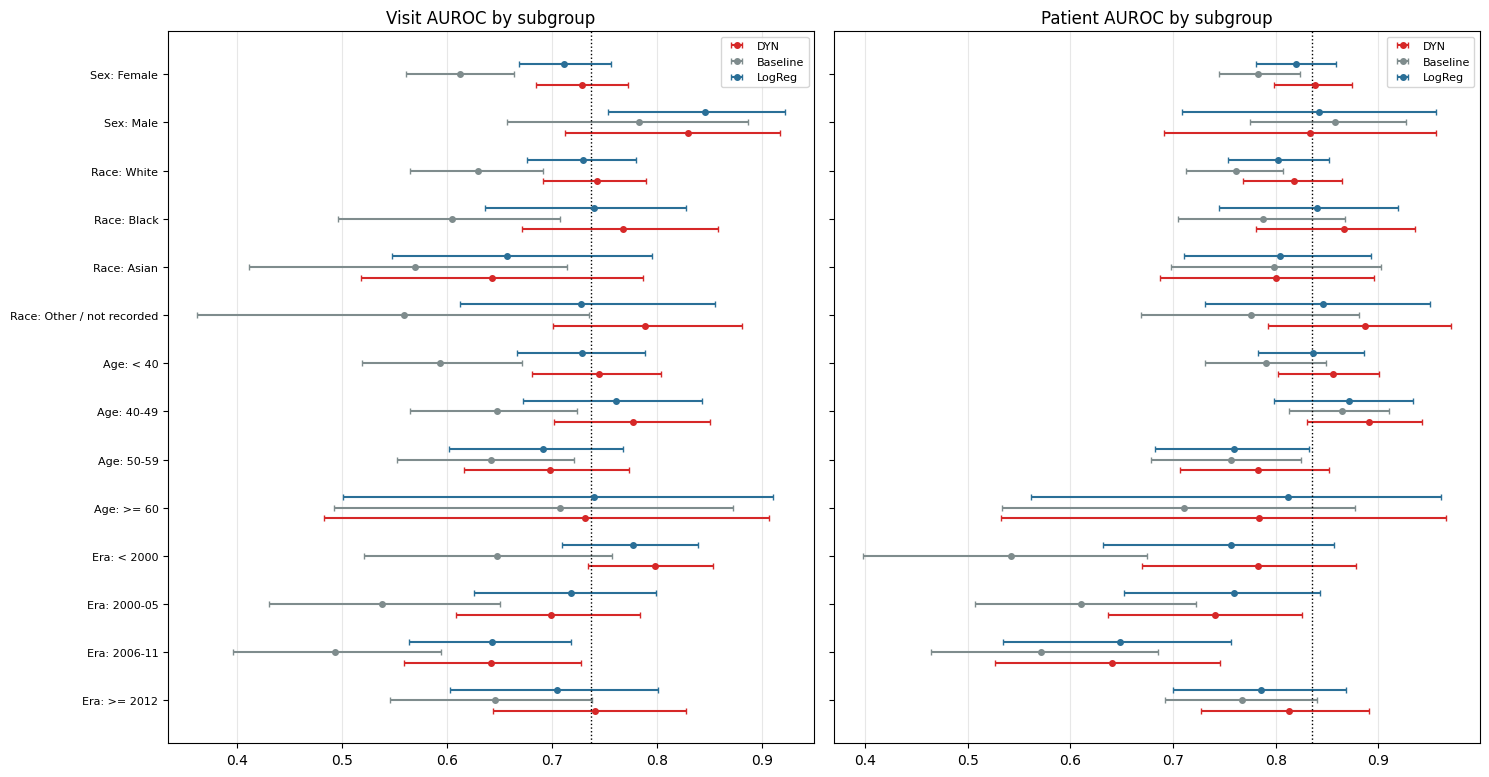

,DYN visit,DYN patient,Baseline visit,Baseline patient,LogReg visit,LogReg patient
Subgroup,,,,,,
Sex: Female,0.728 (0.685 to 0.772),0.838 (0.799 to 0.875),0.612 (0.560 to 0.663),0.783 (0.744 to 0.824),0.711 (0.668 to 0.756),0.820 (0.781 to 0.858)
Sex: Male,0.829 (0.713 to 0.917),0.834 (0.691 to 0.956),0.783 (0.657 to 0.887),0.858 (0.775 to 0.927),0.846 (0.753 to 0.922),0.843 (0.709 to 0.956)
Race: White,0.742 (0.691 to 0.790),0.817 (0.768 to 0.864),0.629 (0.565 to 0.692),0.761 (0.713 to 0.807),0.729 (0.676 to 0.780),0.802 (0.753 to 0.852)
Race: Black,0.767 (0.672 to 0.859),0.867 (0.781 to 0.936),0.605 (0.496 to 0.708),0.788 (0.704 to 0.867),0.740 (0.636 to 0.828),0.840 (0.745 to 0.919)
Race: Asian,0.643 (0.517 to 0.787),0.800 (0.688 to 0.896),0.569 (0.411 to 0.715),0.798 (0.698 to 0.902),0.657 (0.548 to 0.795),0.804 (0.710 to 0.893)
Race: Other / not recorded,0.788 (0.701 to 0.881),0.887 (0.792 to 0.970),0.558 (0.362 to 0.736),0.776 (0.669 to 0.881),0.728 (0.612 to 0.855),0.846 (0.731 to 0.951)
Age: < 40,0.745 (0.681 to 0.804),0.855 (0.802 to 0.901),0.593 (0.519 to 0.671),0.791 (0.731 to 0.849),0.728 (0.666 to 0.788),0.836 (0.782 to 0.886)
Age: 40-49,0.777 (0.702 to 0.850),0.890 (0.831 to 0.942),0.648 (0.565 to 0.724),0.864 (0.813 to 0.911),0.761 (0.673 to 0.843),0.872 (0.798 to 0.934)
Age: 50-59,0.698 (0.616 to 0.773),0.783 (0.707 to 0.852),0.641 (0.552 to 0.721),0.756 (0.678 to 0.824),0.691 (0.602 to 0.767),0.759 (0.682 to 0.832)


In [25]:
"""Subgroup AUROC forest."""
_sub_names = [n for n in SUBGROUPS if n.split(":")[0] in ("Sex", "Race", "Age", "Era")]
fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(_sub_names) + 2), sharey=True)
yy = np.arange(len(_sub_names))[::-1]
for ax, lev in zip(axes, ["visit", "patient"]):
    for j, m in enumerate(KEY_MODELS):
        if m not in MODELS_RUN:
            continue
        for y_, n in zip(yy, _sub_names):
            a = ci((m, lev, H, "sub", n, "auroc"))
            if np.isnan(a[0]):
                continue
            ax.errorbar(a[0], y_ + (j - 1) * 0.22, xerr=[[a[0] - a[1]], [a[2] - a[0]]], fmt="o", ms=4,
                        color=model_color(m), capsize=2, label=short_label(m) if y_ == yy[0] else None)
    ax.axvline(ci((MAIN_MODEL,) + (K_VIS if lev == "visit" else K_PT))[0], color="k", ls=":", lw=1)
    ax.set_yticks(yy); ax.set_yticklabels(_sub_names, fontsize=8); ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"{lev.capitalize()} AUROC by subgroup"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_subgroups.png", dpi=150, bbox_inches="tight"); plt.show()
SUB_TABLE = pd.DataFrame([{"Subgroup": n, **{f"{short_label(m)} {lev}": fmtk((m, lev, H, "sub", n, "auroc"))
                                             for m in KEY_MODELS if m in MODELS_RUN
                                             for lev in ["visit", "patient"]}} for n in _sub_names]).set_index("Subgroup")
display(SUB_TABLE)
SUB_TABLE.to_csv(f"objective1_subgroups_{TAG}.csv")

## 13.8 Patient windows (update_v7/v8's rule) — all models

Every patient-level metric (12 months, 24-month windows), both threshold rules and both patient rules.

In [26]:
"""Patient-level table of every model."""
rows = []
for m in MODELS_RUN:
    for c in THRESHOLD_RULES:
        rows.append({"Model": short_label(m), "Rule": PATIENT_RULE_LABELS["meanlogit"], "Threshold": THRESHOLD_LABELS[c],
                     "AUROC": fmtk((m, "patient", H, "auroc")),
                     **{METRIC_LABELS[x]: fmtk((m, "patient", H, c, x)) for x in CONF_METRICS}})
    rows.append({"Model": short_label(m), "Rule": PATIENT_RULE_LABELS["run2"], "Threshold": THRESHOLD_LABELS["cost"],
                 "AUROC": fmtk((m, "patient", H, "run2", "auroc")),
                 **{METRIC_LABELS[x]: fmtk((m, "patient", H, "run2", x)) for x in CONF_METRICS}})
PATIENT_TABLE = pd.DataFrame(rows)
display(PATIENT_TABLE)
PATIENT_TABLE.to_csv(f"objective1_patient_level_{TAG}.csv", index=False)
rows = []
for m in MODELS_RUN:
    for c in THRESHOLD_RULES:
        rows.append({"Model": short_label(m), "Threshold": THRESHOLD_LABELS[c],
                     "Threshold (12-month risk)": f"{100 * ci((m, 'visit', H, c, 'threshold'))[0]:.1f} %",
                     **{METRIC_LABELS[x]: fmtk((m, "visit", H, c, x)) for x in CONF_METRICS}})
VISIT_TABLE = pd.DataFrame(rows)
print("Visit level (IPCW), both threshold rules:")
display(VISIT_TABLE)
VISIT_TABLE.to_csv(f"objective1_visit_level_{TAG}.csv", index=False)

,Model,Rule,Threshold,AUROC,Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,S0 v8-main,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.825 (0.789 to 0.863),0.731 (0.667 to 0.798),0.774 (0.747 to 0.800),0.337 (0.286 to 0.390),0.949 (0.934 to 0.963),0.753 (0.717 to 0.789),0.294 (0.269 to 0.321)
1,S0 v8-main,mean logit over the window,Max PPV (sensitivity >= 25%),0.825 (0.789 to 0.863),0.301 (0.227 to 0.377),0.959 (0.946 to 0.970),0.537 (0.435 to 0.637),0.898 (0.878 to 0.917),0.630 (0.595 to 0.667),0.076 (0.061 to 0.092)
2,S0 v8-main,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.824 (0.789 to 0.861),0.730 (0.662 to 0.799),0.772 (0.744 to 0.797),0.335 (0.283 to 0.388),0.948 (0.933 to 0.963),0.751 (0.715 to 0.788),0.296 (0.269 to 0.324)
3,S1 no-pool,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.833 (0.797 to 0.869),0.710 (0.641 to 0.775),0.799 (0.773 to 0.824),0.356 (0.299 to 0.412),0.946 (0.932 to 0.962),0.755 (0.719 to 0.791),0.269 (0.244 to 0.297)
4,S1 no-pool,mean logit over the window,Max PPV (sensitivity >= 25%),0.833 (0.797 to 0.869),0.293 (0.227 to 0.364),0.963 (0.950 to 0.973),0.551 (0.445 to 0.651),0.897 (0.877 to 0.916),0.628 (0.594 to 0.663),0.072 (0.058 to 0.087)
5,S1 no-pool,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.827 (0.790 to 0.864),0.747 (0.679 to 0.809),0.756 (0.728 to 0.781),0.324 (0.273 to 0.376),0.950 (0.935 to 0.965),0.751 (0.716 to 0.786),0.312 (0.285 to 0.339)
6,S2 bands,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.827 (0.788 to 0.865),0.725 (0.657 to 0.790),0.772 (0.744 to 0.796),0.334 (0.283 to 0.388),0.947 (0.932 to 0.962),0.749 (0.713 to 0.785),0.295 (0.271 to 0.322)
7,S2 bands,mean logit over the window,Max PPV (sensitivity >= 25%),0.827 (0.788 to 0.865),0.302 (0.232 to 0.377),0.967 (0.955 to 0.977),0.589 (0.482 to 0.691),0.899 (0.879 to 0.918),0.635 (0.599 to 0.673),0.069 (0.056 to 0.085)
8,S2 bands,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.821 (0.784 to 0.859),0.715 (0.647 to 0.780),0.768 (0.740 to 0.792),0.327 (0.275 to 0.379),0.945 (0.929 to 0.960),0.741 (0.704 to 0.779),0.298 (0.273 to 0.325)
9,DYN-bands,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.827 (0.790 to 0.865),0.739 (0.672 to 0.801),0.747 (0.719 to 0.771),0.319 (0.269 to 0.368),0.949 (0.933 to 0.963),0.743 (0.707 to 0.777),0.319 (0.295 to 0.346)


Visit level (IPCW), both threshold rules:


,Model,Threshold,Threshold (12-month risk),Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,S0 v8-main,"Max Youden (cost-weighted, R = (1 - pi) / pi)",2.1 %,0.630 (0.553 to 0.709),0.708 (0.682 to 0.735),0.038 (0.030 to 0.047),0.991 (0.988 to 0.993),0.669 (0.632 to 0.708),0.298 (0.271 to 0.325)
1,S0 v8-main,Max PPV (sensitivity >= 25%),4.1 %,0.291 (0.218 to 0.373),0.920 (0.904 to 0.935),0.063 (0.045 to 0.084),0.986 (0.983 to 0.989),0.606 (0.568 to 0.646),0.084 (0.068 to 0.100)
2,S1 no-pool,"Max Youden (cost-weighted, R = (1 - pi) / pi)",1.9 %,0.645 (0.576 to 0.720),0.700 (0.674 to 0.726),0.038 (0.030 to 0.046),0.991 (0.988 to 0.993),0.673 (0.637 to 0.708),0.306 (0.280 to 0.332)
3,S1 no-pool,Max PPV (sensitivity >= 25%),4.7 %,0.262 (0.200 to 0.330),0.938 (0.924 to 0.949),0.071 (0.051 to 0.092),0.986 (0.983 to 0.989),0.600 (0.569 to 0.633),0.066 (0.054 to 0.080)
4,S2 bands,"Max Youden (cost-weighted, R = (1 - pi) / pi)",2.0 %,0.612 (0.542 to 0.689),0.721 (0.697 to 0.747),0.039 (0.031 to 0.048),0.990 (0.988 to 0.993),0.667 (0.630 to 0.704),0.285 (0.260 to 0.309)
5,S2 bands,Max PPV (sensitivity >= 25%),4.5 %,0.273 (0.206 to 0.349),0.938 (0.923 to 0.950),0.074 (0.052 to 0.098),0.986 (0.983 to 0.989),0.605 (0.573 to 0.642),0.066 (0.054 to 0.081)
6,DYN-bands,"Max Youden (cost-weighted, R = (1 - pi) / pi)",1.8 %,0.644 (0.576 to 0.713),0.682 (0.659 to 0.705),0.036 (0.029 to 0.044),0.991 (0.988 to 0.993),0.663 (0.628 to 0.698),0.324 (0.301 to 0.347)
7,DYN-bands,Max PPV (sensitivity >= 25%),4.3 %,0.274 (0.210 to 0.341),0.936 (0.922 to 0.947),0.073 (0.052 to 0.096),0.986 (0.983 to 0.989),0.605 (0.574 to 0.638),0.068 (0.056 to 0.081)
8,DYN,"Max Youden (cost-weighted, R = (1 - pi) / pi)",1.8 %,0.678 (0.609 to 0.747),0.673 (0.649 to 0.698),0.037 (0.030 to 0.044),0.991 (0.989 to 0.994),0.676 (0.641 to 0.709),0.333 (0.308 to 0.358)
9,DYN,Max PPV (sensitivity >= 25%),4.5 %,0.255 (0.195 to 0.315),0.940 (0.928 to 0.950),0.072 (0.052 to 0.094),0.986 (0.983 to 0.989),0.597 (0.569 to 0.628),0.064 (0.053 to 0.076)


## 13.9 Conclusion — Objective 1

In [27]:
"""Objective 1 conclusion."""
_m = MAIN_MODEL
_h1 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H1")]
txt = (f"Main model ({model_label(_m)}): time-matched patient AUROC {fmtk((_m,) + K_TM)} (Baseline "
       f"{fmtk((BASELINE,) + K_TM)}, LogReg {fmtk((LOGREG,) + K_TM)}). It flags "
       f"{ci((_m, 'tm', 'main', 'sensitivity'))[0]:.0%} of patients in the 12 months before their onset and "
       f"{1 - ci((_m, 'tm', 'main', 'specificity'))[0]:.0%} of the patients still working on the same dates. Visit AUROC "
       f"(12 months) {fmtk((_m,) + K_VIS)}; calibration slope {ci((_m, 'visit', H, 'cal_slope'))[0]:.2f}, O/E "
       f"{ci((_m, 'visit', H, 'oe'))[0]:.2f}. Hypotheses: " + "; ".join(
           f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: {r_.get('Verdict') or ('met' if r_['Met'] else 'not met')}"
           for r_ in _h1) + ". " + TIER_SUMMARY)
OBJ_CONCLUSIONS["Objective 1"] = txt
print(textwrap.fill(txt, 118))

Main model (Dynamic LSTM: S1 + change from the patient's own baseline, one hazard [MAIN]): time-matched patient AUROC
0.742 (0.702 to 0.783) (Baseline 0.582 (0.531 to 0.633), LogReg 0.734 (0.694 to 0.773)). It flags 62% of patients in
the 12 months before their onset and 31% of the patients still working on the same dates. Visit AUROC (12 months)
0.737 (0.696 to 0.778); calibration slope 1.06, O/E 1.04. Hypotheses: H1a (primary) (DYN - Baseline, time-matched
patient AUROC) 0.161 (0.109 to 0.214): superior; H1b (DYN - LogReg, time-matched patient AUROC) 0.009 (-0.006 to
0.024): inconclusive; H1d (post hoc) (DYN - DYN-bands, time-matched patient AUROC) 0.016 (0.002 to 0.029): superior;
H1c (Main: visit calibration slope / intercept) 1.056 (0.878 to 1.257) / 0.011 (-0.188 to 0.201): met. Risk tiers
(DYN): the < 1 % tier covers 42% of visits with an observed 12-month risk of 0.005 (0.003 to 0.008) and misses 0.122
(0.077 to 0.169) of the onsets; the >= 5 % tier covers 5% of visits with an 

---
# 14. Objective 2 — The risk is higher the closer a patient is to reporting work disability

## 14.1 Discrimination by time before the onset

The time-matched patient AUROC (Section 11.8) with the case window moved back from the onset: the patients'
scores 0-6, 6-12, 12-24, 24-36 and 36-48 months before their onset against everyone still working on the onset
date, scored over the same calendar window. If the risk rises as the onset approaches, the AUROC falls with the
distance from the onset. **H2a**: the main model's AUROC in the 12 months before the onset minus its AUROC 24-36
months before it; lower 95 % bound > 0. Also: does the main model's advantage over the Baseline and LogReg grow
near the onset?

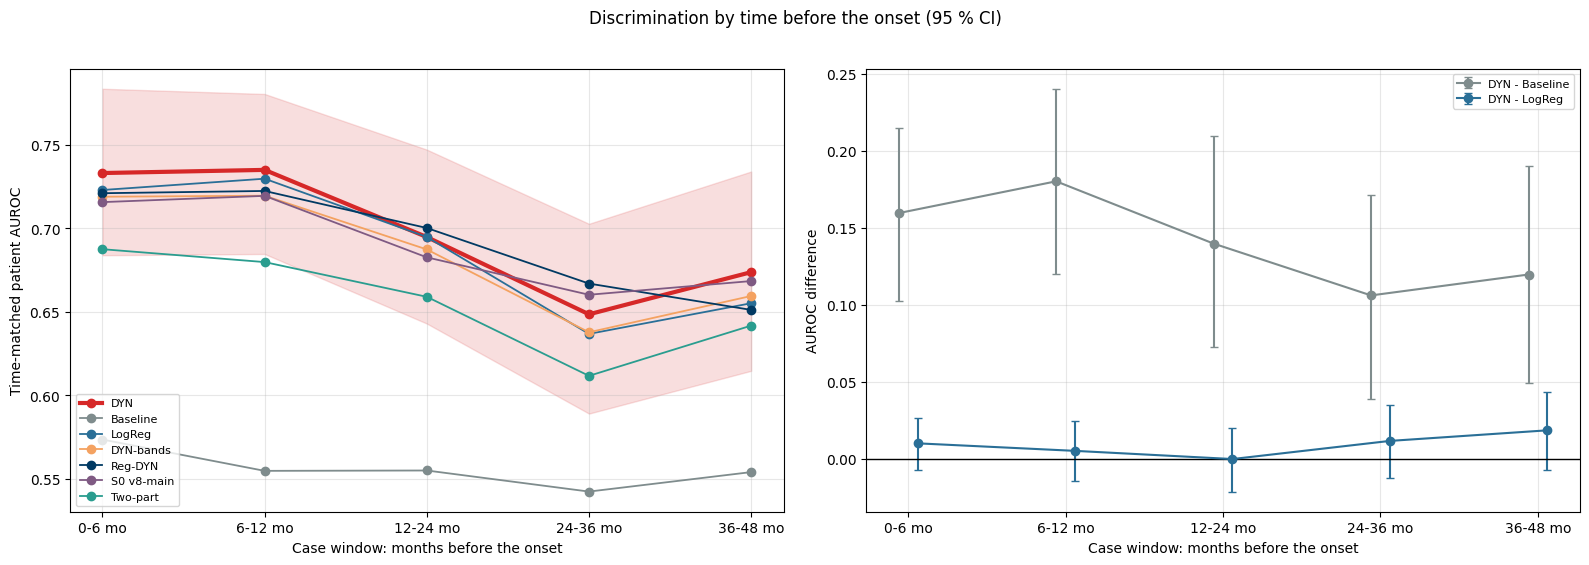

,0-6 mo before,6-12 mo before,12-24 mo before,24-36 mo before,36-48 mo before,0-12 mo (main window)
Model,,,,,,
DYN,0.733 (0.684 to 0.783),0.735 (0.684 to 0.780),0.695 (0.643 to 0.747),0.648 (0.589 to 0.703),0.674 (0.615 to 0.734),0.742 (0.702 to 0.783)
Baseline,0.573 (0.513 to 0.634),0.555 (0.499 to 0.615),0.555 (0.492 to 0.618),0.542 (0.476 to 0.615),0.554 (0.483 to 0.627),0.582 (0.531 to 0.633)
LogReg,0.723 (0.673 to 0.773),0.730 (0.683 to 0.775),0.695 (0.643 to 0.744),0.637 (0.577 to 0.694),0.655 (0.589 to 0.717),0.734 (0.694 to 0.773)
DYN-bands,0.719 (0.669 to 0.770),0.719 (0.672 to 0.769),0.687 (0.636 to 0.736),0.638 (0.578 to 0.695),0.659 (0.598 to 0.718),0.726 (0.688 to 0.769)
Reg-DYN,0.721 (0.671 to 0.775),0.722 (0.671 to 0.769),0.700 (0.649 to 0.748),0.667 (0.609 to 0.721),0.651 (0.584 to 0.714),0.729 (0.687 to 0.770)
S0 v8-main,0.716 (0.668 to 0.767),0.719 (0.671 to 0.767),0.682 (0.630 to 0.731),0.660 (0.597 to 0.720),0.668 (0.609 to 0.727),0.719 (0.678 to 0.760)
Two-part,0.687 (0.636 to 0.741),0.680 (0.628 to 0.731),0.659 (0.606 to 0.711),0.612 (0.552 to 0.675),0.642 (0.574 to 0.706),0.694 (0.652 to 0.738)


,AUROC 0-12 mo before minus 24-36 mo before,Met (lower bound > 0)
Model,,
DYN,0.094 (0.045 to 0.144),True
Baseline,0.039 (-0.004 to 0.086),False
LogReg,0.097 (0.042 to 0.152),True
DYN-bands,0.089 (0.034 to 0.140),True
Reg-DYN,0.062 (0.007 to 0.115),True
S0 v8-main,0.059 (0.012 to 0.104),True
Two-part,0.082 (0.029 to 0.136),True


Onsets / pairs per window: main: 158 / 44,009, 0-6: 115 / 32,231, 6-12: 111 / 29,349, 12-24: 104 / 26,797, 24-36: 86 / 19,426, 36-48: 77 / 16,520


In [28]:
"""Time-matched AUROC by time before the onset; H2a."""
_tto = [k for k in TM_WINDOWS if k != "main"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
rows = []
for m in [m for m in FIG_MODELS if m in MODELS_RUN]:
    v = np.array([ci((m, "tm", k, "auroc")) for k in _tto])
    axes[0].plot(range(len(_tto)), v[:, 0], "o-", color=model_color(m), lw=3 if m == MAIN_MODEL else 1.3,
                 label=short_label(m))
    if m == MAIN_MODEL:
        axes[0].fill_between(range(len(_tto)), v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    rows.append({"Model": short_label(m), **{f"{k} mo before": fmt(*v_) for k, v_ in zip(_tto, v)},
                 "0-12 mo (main window)": fmtk((m,) + K_TM)})
for j, b_ in enumerate([BASELINE, LOGREG]):
    d = np.array([diff(MAIN_MODEL, b_, ("tm", k, "auroc"))[:3] for k in _tto])
    xs = np.arange(len(_tto)) + (j - 0.5) * 0.12
    axes[1].errorbar(xs, d[:, 0], yerr=[d[:, 0] - d[:, 1], d[:, 2] - d[:, 0]], fmt="o-", capsize=3,
                     color=model_color(b_), label=f"DYN - {short_label(b_)}")
for ax in axes:
    ax.set_xticks(range(len(_tto))); ax.set_xticklabels([f"{k} mo" for k in _tto])
    ax.set_xlabel("Case window: months before the onset"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel("Time-matched patient AUROC"); axes[1].axhline(0, color="k", lw=1)
axes[1].set_ylabel("AUROC difference")
fig.suptitle("Discrimination by time before the onset (95 % CI)", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_by_time_to_onset.png", dpi=150, bbox_inches="tight"); plt.show()
TTO_TABLE = pd.DataFrame(rows).set_index("Model")
display(TTO_TABLE)
TTO_TABLE.to_csv(f"objective2_by_time_to_onset_{TAG}.csv")
_near, _far = ("tm", "main", "auroc"), ("tm", f"{H2A_FAR[0]}-{H2A_FAR[1]}", "auroc")
rows = []
for m in [m for m in FIG_MODELS if m in MODELS_RUN]:
    d = _diff_summary(STATS[(m,) + _near][0] - STATS[(m,) + _far][0], STATS[(m,) + _near][1] - STATS[(m,) + _far][1])
    rows.append({"Model": short_label(m), "AUROC 0-12 mo before minus 24-36 mo before": fmt(*d[:3]),
                 "Met (lower bound > 0)": d[1] > 0})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H2a", "Estimand": "Main: time-matched AUROC 0-12 minus 24-36 months before onset",
                         "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0", "Met": d[1] > 0})
display(pd.DataFrame(rows).set_index("Model"))
print("Onsets / pairs per window: " + ", ".join(f"{k}: {TM[k]['n_onsets']} / {len(TM[k]['pc']):,}" for k in TM))

## 14.2 Does each patient's risk rise as the onset approaches?

Each model's 12-month logit is **centred on the calendar year** (minus the mean logit of every landmark in the same
year), so the downward calendar trend in the risk does not look like a fall within patients. Then:

* **Onset-aligned trajectories**: the centred logit of patients with an onset by 6-month bins before the onset,
  against patients who never have an onset, aligned at their last landmark (mean and 95 % CI over patients).
* **H2b**: a linear mixed model of the centred logit on time (years, −4 to 0 before the anchor) with a random
  intercept per patient, onset patients and never-onset patients together: the **interaction** (how much faster the
  risk rises in onset patients than in never-onset patients over the same 4 years) > 0 for the main model (lower
  95 % bound > 0). Slopes reported for every key model.
* **Within-patient C** (centred): the same onset patient's landmarks ≤ 12 months before the onset scored against
  those > 24 months before (0.5 = no rise).

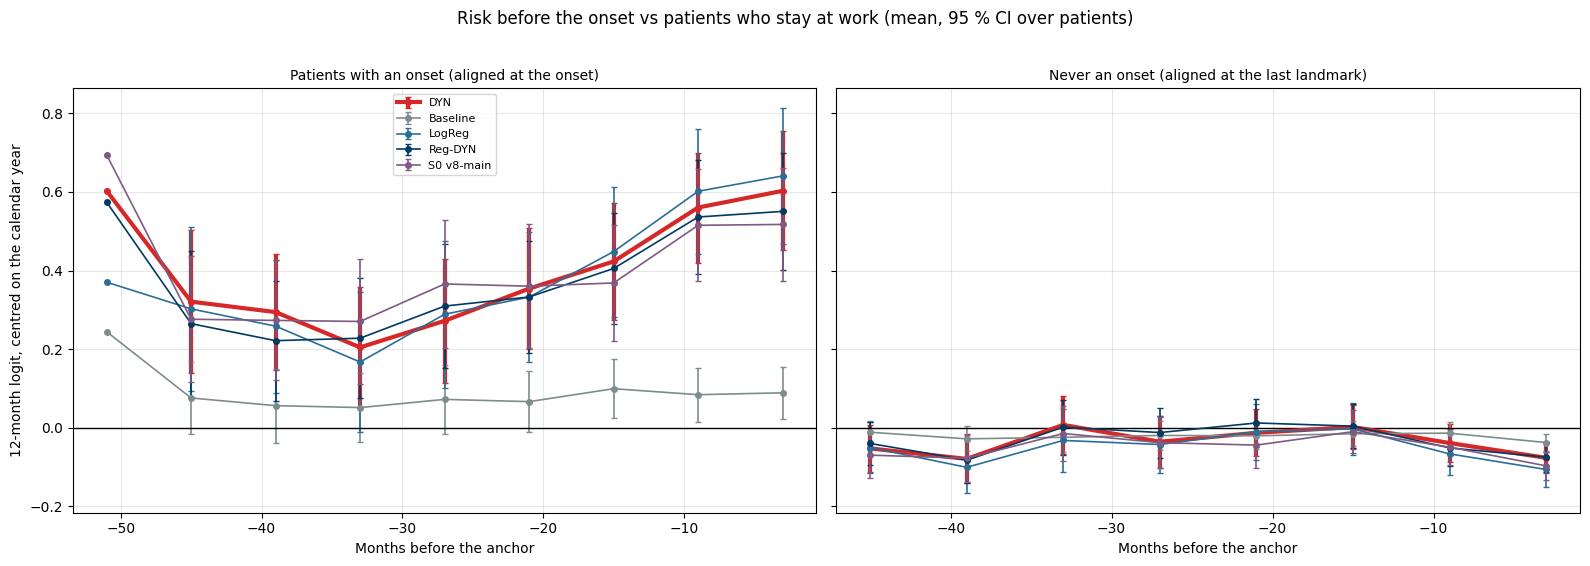

,"Slope per year, never-onset","Extra slope per year, onset patients (interaction)","Slope per year, onset patients",Level difference at the anchor (onset - never)
Model,,,,
DYN,-0.029 (-0.036 to -0.021),0.092 (0.069 to 0.116),0.064,0.648
Baseline,0.000 (-0.000 to 0.001),-0.003 (-0.005 to -0.001),-0.002,0.129
LogReg,-0.026 (-0.036 to -0.016),0.091 (0.060 to 0.121),0.065,0.701
Reg-DYN,-0.011 (-0.019 to -0.003),0.074 (0.049 to 0.099),0.063,0.606
S0 v8-main,-0.030 (-0.034 to -0.025),0.073 (0.058 to 0.087),0.043,0.627


Within-patient C: 79 onset patients with landmarks <= 12 and > 24 months before the onset


,Within-patient C (year-centred),Minus Baseline
Model,,
S0 v8-main,0.606 (0.527 to 0.682),0.168 (0.079 to 0.264)
S1 no-pool,0.613 (0.541 to 0.678),0.175 (0.089 to 0.268)
S2 bands,0.616 (0.544 to 0.679),0.178 (0.086 to 0.269)
DYN-bands,0.643 (0.573 to 0.712),0.205 (0.122 to 0.295)
DYN,0.629 (0.566 to 0.697),0.191 (0.106 to 0.282)
Two-part,0.590 (0.513 to 0.659),0.152 (0.064 to 0.243)
Reg-DYN,0.621 (0.554 to 0.693),0.183 (0.091 to 0.276)
LogReg,0.619 (0.549 to 0.684),0.180 (0.092 to 0.270)
Reg-v7,0.586 (0.503 to 0.667),0.147 (0.048 to 0.245)


In [29]:
"""Year-centred risk: trajectories, mixed model (H2b) and within-patient C."""
import statsmodels.formula.api as smf

_YR = np.floor(land["CAL_YEAR"].values).astype(int)


def centred(m):
    out = []
    for r in REPEATS:
        z = zpred(m, r)
        yrm = pd.Series(z).groupby(_YR).transform("mean").values
        out.append(z - yrm)
    return out                                        # one array per repeat


ZC = {m: centred(m) for m in MODELS_RUN}
_anchor = {p: FIRST_ONSET[p].value / 8.64e13 for p in EVER_ONSET}
_ctrl = [p for p in PT_ROWS if p not in EVER_ONSET]
_anchor.update({p: _LAND_T[PT_ROWS[p]].max() + 1 for p in _ctrl})


def aligned(m):
    """Long table: patient, onset patient or not, months before the anchor, centred logit (mean over repeats)."""
    zc = np.mean(ZC[m], 0)
    recs = []
    for pid, li in PT_ROWS.items():
        mo = (_anchor[pid] - _LAND_T[li]) / MONTH_DAYS
        k = (mo > 0) & (mo <= TRAJ_MAX_MONTHS)
        recs.append(pd.DataFrame({"pid": pid, "event": int(pid in EVER_ONSET), "mo": mo[k], "zc": zc[li][k]}))
    return pd.concat(recs, ignore_index=True)


ALIGNED = {m: aligned(m) for m in KEY_MODELS + [REG_DYN, V8_MAIN] if m in MODELS_RUN}
_bins = np.arange(0, TRAJ_MAX_MONTHS + 1, 6)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, ev, ttl in zip(axes, [1, 0], ["Patients with an onset (aligned at the onset)",
                                     "Never an onset (aligned at the last landmark)"]):
    for m, A in ALIGNED.items():
        a = A[A["event"] == ev].copy()
        a["bin"] = np.digitize(a["mo"], _bins)
        g = a.groupby(["bin", "pid"])["zc"].mean().groupby("bin").agg(["mean", "sem"])
        xs = -(_bins[g.index.values - 1] + 3)
        ax.errorbar(xs, g["mean"], yerr=1.96 * g["sem"], fmt="o-", ms=4, capsize=2, color=model_color(m),
                    lw=3 if m == MAIN_MODEL else 1.2, label=short_label(m))
    ax.axhline(0, color="k", lw=1); ax.grid(alpha=0.3); ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("Months before the anchor")
axes[0].set_ylabel("12-month logit, centred on the calendar year"); axes[0].legend(fontsize=8)
fig.suptitle("Risk before the onset vs patients who stay at work (mean, 95 % CI over patients)", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_trajectories.png", dpi=150, bbox_inches="tight"); plt.show()

rows = []
for m, A in ALIGNED.items():
    A = A.assign(t=-A["mo"] / 12.0)
    fit = smf.mixedlm("zc ~ t * event", A, groups=A["pid"]).fit(reml=True)
    ci_ = fit.conf_int()
    sl0 = (fit.params["t"], *ci_.loc["t"])
    it = (fit.params["t:event"], *ci_.loc["t:event"])
    rows.append({"Model": short_label(m), "Slope per year, never-onset": fmt(*sl0),
                 "Extra slope per year, onset patients (interaction)": fmt(*it),
                 "Slope per year, onset patients": f"{sl0[0] + it[0]:.3f}",
                 "Level difference at the anchor (onset - never)": f"{fit.params['event']:.3f}"})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H2b", "Estimand": "Main: extra rise per year before onset vs never-onset "
                         "(mixed model, year-centred logit)", "Estimate (95% CI)": fmt(*it),
                         "Criterion": "lower bound > 0", "Met": it[1] > 0})
MIXED = pd.DataFrame(rows).set_index("Model")
display(MIXED)
MIXED.to_csv(f"objective2_mixed_model_{TAG}.csv")

# within-patient C on the centred logits
_pn, _pf, _pp, _pw = [], [], [], []
for pid in EVER_ONSET:
    li = PT_ROWS[pid]
    mo = (_anchor[pid] - _LAND_T[li]) / MONTH_DAYS
    near, far = li[(mo > 0) & (mo <= WITHIN_NEAR_MONTHS)], li[mo > WITHIN_FAR_MONTHS]
    if len(near) and len(far):
        a_, b_ = np.meshgrid(near, far, indexing="ij")
        _pn.append(a_.ravel()); _pf.append(b_.ravel())
        _pp.append(np.full(a_.size, PID_INDEX[pid])); _pw.append(np.full(a_.size, 1.0 / a_.size))
W_NEAR, W_FAR, W_PIDX, W_WT = (np.concatenate(x) for x in (_pn, _pf, _pp, _pw))
for m in MODELS_RUN:
    vals = []
    for zc in ZC[m]:
        conc = (zc[W_NEAR] > zc[W_FAR]) + 0.5 * (zc[W_NEAR] == zc[W_FAR])
        Wb = _BOTH[:, W_PIDX] * W_WT[None, :]
        vals.append((Wb @ conc) / Wb.sum(1))
    v = np.mean(vals, 0)
    STATS[(m, "within", H, "c")] = (float(v[0]), v[1:])
WITHIN_T = pd.DataFrame([{"Model": short_label(m), "Within-patient C (year-centred)": fmtk((m, "within", H, "c")),
                          "Minus Baseline": fmt(*diff(m, BASELINE, ("within", H, "c"))[:3])} for m in MODELS_RUN]
                        ).set_index("Model")
print(f"Within-patient C: {len(np.unique(W_PIDX))} onset patients with landmarks <= {WITHIN_NEAR_MONTHS} and > "
      f"{WITHIN_FAR_MONTHS} months before the onset")
display(WITHIN_T)
WITHIN_T.to_csv(f"objective2_within_patient_{TAG}.csv")

## 14.3 Alarms before the onset: lead time, re-assessment and alarm rules

**Lead time** (patient windows, update_v7/v8's rule at 12 months): from the landmark at which the running mean
first reaches the patient threshold to the onset (criterion of **H2c**: lower 95 % bound ≥ 3 months). Then every
assessment scored as it would be in a clinic (re-assessed at every landmark visit, every 6 months or every 12 months;
the latest landmark score carried forward while the patient is at risk), with four alarm rules whose thresholds are
learned on the training fold's out-of-fold scores (max Youden on the 12-month label): **level** (risk above the
threshold), **confirmed** (twice in a row), **rise** (the risk minus the patient's own usual risk, an EWMA of their
earlier scores, above a threshold) and **level or rise**. An alarm is true if an onset follows within 12 months,
false if the patient is known to be onset-free for 12 months after it. Reported: alarms per patient-year, the share
of resolved alarms that are false, the PPV of an alarm, alarms per patient-year in patients who never have an onset,
**the share of onsets with an alarm in the 12 months before them**, and the flip rate. Descriptive.

In [30]:
"""Lead time (H2c)."""
rows = []
for m in MODELS_RUN:
    lm = ci((m, "patient", H, "lead_median"))
    rows.append({"Model": short_label(m), "Median lead time (months)": fmt(*lm, nd=1),
                 "Event patients flagged (windows)": fmtk((m, "patient", H, MAIN_THRESHOLD, "sensitivity")),
                 f"Flagged >= {LEAD_TIME_MIN_MONTHS} months ahead": fmtk((m, "patient", H, "lead_ge6"))})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H2c", "Estimand": "Main: median lead time, flagged event patients (months)",
                         "Estimate (95% CI)": fmt(*lm, nd=1), "Criterion": f"lower bound >= {LEAD_TIME_MIN_MONTHS}",
                         "Met": lm[1] >= LEAD_TIME_MIN_MONTHS})
LEAD = pd.DataFrame(rows).set_index("Model")
display(LEAD)
LEAD.to_csv(f"objective2_lead_time_{TAG}.csv")

,Median lead time (months),Event patients flagged (windows),Flagged >= 3 months ahead
Model,,,
S0 v8-main,9.2 (8.9 to 9.8),0.731 (0.667 to 0.798),0.689 (0.620 to 0.759)
S1 no-pool,9.2 (8.8 to 9.6),0.710 (0.641 to 0.775),0.684 (0.611 to 0.752)
S2 bands,9.2 (8.8 to 9.6),0.725 (0.657 to 0.790),0.689 (0.617 to 0.761)
DYN-bands,9.1 (8.8 to 9.7),0.739 (0.672 to 0.801),0.702 (0.633 to 0.772)
DYN,9.0 (8.6 to 9.5),0.740 (0.676 to 0.802),0.705 (0.639 to 0.777)
Two-part,9.1 (8.7 to 9.6),0.759 (0.697 to 0.820),0.715 (0.642 to 0.788)
Reg-DYN,9.0 (8.6 to 9.4),0.715 (0.649 to 0.781),0.684 (0.615 to 0.756)
LogReg,9.0 (8.7 to 9.6),0.711 (0.645 to 0.779),0.693 (0.623 to 0.763)
Reg-v7,9.2 (8.9 to 9.9),0.708 (0.639 to 0.778),0.670 (0.602 to 0.744)


Assessments per patient-year at risk: visit 2.01, 6 months 1.85, 12 months 0.96


Alarms per patient-year  Share of assessments alarming  False alarms, share of resolved alarms  PPV of an alarm (onset within 12 months)  \
Model    Alarm rule                                                                                                                                                
DYN      level                            0.645                          0.321                                   0.962                                     0.038   
         confirmed                        0.494                          0.246                                   0.962                                     0.038   
         rise                             0.444                          0.221                                   0.970                                     0.030   
         level_or_rise                    0.812                          0.404                                   0.968                                     0.032   
Reg-DYN  level                            0.608                          0.303                                   0.963                                     0.037   
         confirmed                        0.451                          0.224                                   0.962                                     0.038   
         rise                             0.422                          0.210                                   0.971                                     0.029   
         level_or_rise                    0.769                          0.383                                   0.968                                     0.032   
LogReg   level                            0.619                          0.308                                   0.963                                     0.037   
         confirmed                        0.443                          0.220                                   0.961                                     0.039   
         rise                             0.405                          0.202                                   0.970                                     0.030   
         level_or_rise                    0.756                          0.376                                   0.968                                     0.032   
Baseline level                            0.835                          0.415                                   0.974                                     0.026   
         confirmed                        0.773                          0.385                                   0.976                                     0.024   
         rise                             0.746                          0.371                                   0.975                                     0.025   
         level_or_rise                    1.098                          0.546                                   0.975                                     0.025   

                        Alarms per patient-year, never-onset patients  Onsets with an alarm in the 12 months before  Flip rate (alarm, then no alarm next)  
Model    Alarm rule                                                                                                                                         
DYN      level                                                  0.562                                         0.655                                  0.199  
         confirmed                                              0.423                                         0.492                                  0.152  
         rise                                                   0.412                                         0.463                                  0.492  
         level_or_rise                                          0.736                                         0.703                                  0.258  
Reg-DYN  level                                                  0.534                                         0.600              

Alarms per patient-year  Share of assessments alarming  False alarms, share of resolved alarms  PPV of an alarm (onset within 12 months)  \
Re-assessment Alarm rule                                                                                                                                                
visit         level                            0.645                          0.321                                   0.962                                     0.038   
              confirmed                        0.494                          0.246                                   0.962                                     0.038   
              rise                             0.444                          0.221                                   0.970                                     0.030   
              level_or_rise                    0.812                          0.404                                   0.968                                     0.032   
6 months      level                            0.536                          0.290                                   0.972                                     0.028   
              confirmed                        0.409                          0.221                                   0.974                                     0.026   
              rise                             0.357                          0.193                                   0.982                                     0.018   
              level_or_rise                    0.687                          0.371                                   0.977                                     0.023   
12 months     level                            0.285                          0.297                                   0.969                                     0.031   
              confirmed                        0.181                          0.189                                   0.973                                     0.027   
              rise                             0.172                          0.179                                   0.983                                     0.017   
              level_or_rise                    0.360                          0.375                                   0.975                                     0.025   

                             Alarms per patient-year, never-onset patients  Onsets with an alarm in the 12 months before  Flip rate (alarm, then no alarm next)  
Re-assessment Alarm rule                                                                                                                                         
visit         level                                                  0.562                                         0.655                                  0.199  
              confirmed                                              0.423                                         0.492                                  0.152  
              rise                                                   0.412                                         0.463                                  0.492  
              level_or_rise                                          0.736                                         0.703                                  0.258  
6 months      level                                                  0.481                                         0.607                                  0.192  
              confirmed                                              0.364                                         0.404                                  0.171  
              rise                                                   0.343                                         0.301                                  0.441  
              level_or_rise                                          0.638                                         0.649                                  0.237  
12 months     level                       

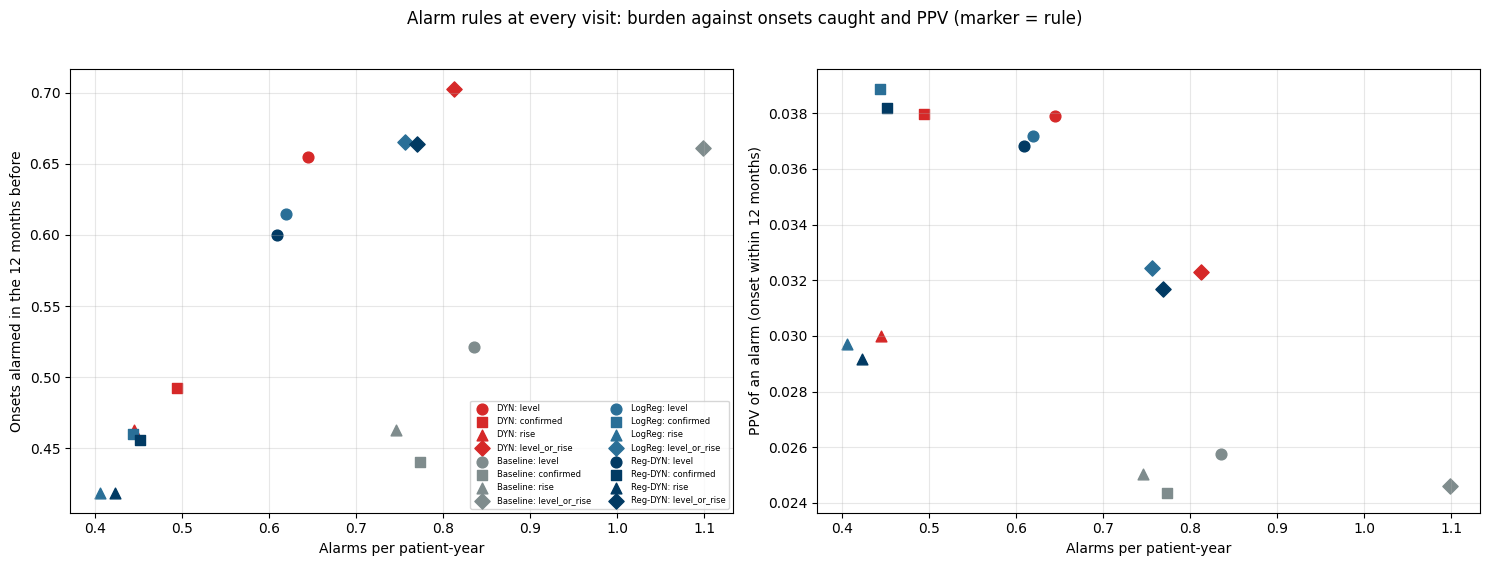

In [31]:
"""Alarm burden and false alarms by re-assessment schedule and alarm rule."""


def ewma_rise(z, rows):
    """Score at each row minus the EWMA of the same patient's EARLIER scores (rows in date order within patient)."""
    s_ = pd.Series(z[rows])
    prev = s_.groupby(PID_ALL[rows]).transform(lambda x: x.ewm(alpha=EWMA_LAMBDA, adjust=False).mean().shift(1))
    out = np.full(N_LAND, np.nan)
    out[rows] = (s_ - prev).values
    return out


THR_RISE, RISE = {}, {}
for m in MODELS_RUN:
    for r in REPEATS:
        thr = np.full(N_LAND, np.nan)
        for f in range(CV_N_SPLITS):
            tr, zo = OOF_H[(m, r, f)]
            zf = np.full(N_LAND, np.nan); zf[tr] = zo
            ro = ewma_rise(zf, np.sort(tr))[tr]
            lab = LABEL_H[H][tr]
            k = ~np.isnan(lab) & ~np.isnan(ro)
            thr[rows_of(OUTER[r][f][1])] = choose_thresholds(lab[k], ro[k])["cost"]
        THR_RISE[(m, r)] = thr
        RISE[(m, r)] = ewma_rise(zpred(m, r), np.arange(N_LAND))


def assessment_schedule(every_months):
    """Assessments of every patient: (latest landmark row, date in days, position within the patient)."""
    lr_, tau_, seq_ = [], [], []
    for pid, li in PT_ROWS.items():
        t = _LAND_T[li]
        if every_months == 0:
            tau, lr = t, li
        else:
            tau = np.arange(t[0], t[-1] + 1e-6, every_months * MONTH_DAYS)
            lr = li[np.searchsorted(t, tau, side="right") - 1]
            ok = tau < INT_END[lr]                       # still at risk since the latest landmark
            tau, lr = tau[ok], lr[ok]
        lr_.append(lr); tau_.append(tau); seq_.append(np.arange(len(lr)))
    lr, tau, sq = np.concatenate(lr_), np.concatenate(tau_), np.concatenate(seq_)
    rem = _END[lr] - tau                                 # follow-up left after the assessment
    true = (C_ALL[lr] == 1) & (rem <= HORIZON_DAYS)
    false = ~true & ((rem > HORIZON_DAYS) | (C_ALL[lr] >= 2))
    fo = pd.Series(PID_ALL[lr]).map(FIRST_ONSET).values.astype("datetime64[ns]")
    fo_d = (fo - np.datetime64("1970-01-01")) / np.timedelta64(1, "D")
    pre_onset = (tau < fo_d) & (tau >= fo_d - H * MONTH_DAYS)
    return {"lr": lr, "tau": tau, "seq": sq, "pid": PID_ALL[lr], "true": true, "false": false, "pre_onset": pre_onset}


ASSESS = {k: assessment_schedule(v) for k, v in ASSESS_SCHEDULES.items()}
_PY_ALL = INT_YRS.sum()
_never = ~np.isin(PID_ALL, list(EVER_ONSET))
_PY_NEVER = INT_YRS[_never].sum()
print("Assessments per patient-year at risk: " + ", ".join(f"{k} {len(a['lr']) / _PY_ALL:.2f}" for k, a in ASSESS.items()))


def alarm_stats(m, r, sched, rule):
    A = ASSESS[sched]
    lr = A["lr"]
    level = zpred(m, r)[lr] >= THR_V[m][r][H][MAIN_THRESHOLD][lr]
    rise = np.nan_to_num(RISE[(m, r)][lr], nan=-np.inf) >= THR_RISE[(m, r)][lr]
    if rule == "level":
        on = level
    elif rule == "confirmed":
        on = level & np.r_[False, level[:-1]] & (A["seq"] > 0)
    elif rule == "rise":
        on = rise
    else:
        on = level | rise
    has_next = np.r_[A["seq"][1:] > 0, False]
    resolved = on & (A["true"] | A["false"])
    ev_alarmed = pd.Series(on & A["pre_onset"]).groupby(A["pid"]).max()
    ev_alarmed = ev_alarmed.reindex(list(EVER_ONSET)).fillna(False).astype(float)
    never_on = on & ~np.isin(A["pid"], list(EVER_ONSET))
    return {"Alarms per patient-year": on.sum() / _PY_ALL, "Share of assessments alarming": on.mean(),
            "False alarms, share of resolved alarms": (on & A["false"]).sum() / max(resolved.sum(), 1),
            "PPV of an alarm (onset within 12 months)": (on & A["true"]).sum() / max(resolved.sum(), 1),
            "Alarms per patient-year, never-onset patients": never_on.sum() / _PY_NEVER,
            "Onsets with an alarm in the 12 months before": float(ev_alarmed.mean()),
            "Flip rate (alarm, then no alarm next)": (on & np.r_[~on[1:], True] & has_next).sum()
            / max((on & has_next).sum(), 1)}


rows = []
for m in MODELS_RUN:
    for sched in ASSESS_SCHEDULES:
        for rule in ALARM_RULE_LABELS:
            vals = pd.DataFrame([alarm_stats(m, r, sched, rule) for r in REPEATS]).mean()
            rows.append({"Model": short_label(m), "Re-assessment": sched, "Alarm rule": rule, **vals.to_dict()})
ALARMS = pd.DataFrame(rows)
ALARMS.to_csv(f"objective1_alarms_{TAG}.csv", index=False)
_am = [m for m in KEY_MODELS + [REG_DYN] if m in MODELS_RUN]
display(ALARMS[(ALARMS["Model"].isin([short_label(m) for m in _am])) & (ALARMS["Re-assessment"] == "visit")]
        .set_index(["Model", "Alarm rule"]).drop(columns="Re-assessment").round(3))
display(ALARMS[(ALARMS["Model"] == short_label(MAIN_MODEL))].set_index(["Re-assessment", "Alarm rule"])
        .drop(columns="Model").round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
_v = ALARMS[ALARMS["Re-assessment"] == "visit"]
for m in _am:
    d = _v[_v["Model"] == short_label(m)].set_index("Alarm rule")
    for rule, mk in zip(ALARM_RULE_LABELS, ["o", "s", "^", "D"]):
        axes[0].scatter(d.loc[rule, "Alarms per patient-year"], d.loc[rule, "Onsets with an alarm in the 12 months before"],
                        color=model_color(m), marker=mk, s=60, label=f"{short_label(m)}: {rule}")
        axes[1].scatter(d.loc[rule, "Alarms per patient-year"], d.loc[rule, "PPV of an alarm (onset within 12 months)"],
                        color=model_color(m), marker=mk, s=60)
axes[0].set_xlabel("Alarms per patient-year"); axes[0].set_ylabel("Onsets alarmed in the 12 months before")
axes[1].set_xlabel("Alarms per patient-year"); axes[1].set_ylabel("PPV of an alarm (onset within 12 months)")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=6, ncol=2)
fig.suptitle("Alarm rules at every visit: burden against onsets caught and PPV (marker = rule)", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_alarms.png", dpi=150, bbox_inches="tight"); plt.show()

## 14.4 Conclusion — Objective 2

In [32]:
"""Objective 2 conclusion."""
_h2 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H2")]
_a = ALARMS.set_index(["Model", "Re-assessment", "Alarm rule"])
txt = (f"Time-matched AUROC of the main model by months before the onset: " + ", ".join(
    f"{k} {ci((MAIN_MODEL, 'tm', k, 'auroc'))[0]:.3f}" for k in _tto) + ". Within-patient C (year-centred): "
       f"{fmtk((MAIN_MODEL, 'within', H, 'c'))}. At every visit, the level alarm catches "
       f"{_a.loc[(short_label(MAIN_MODEL), 'visit', 'level'), 'Onsets with an alarm in the 12 months before']:.0%} of "
       f"onsets in the 12 months before them (level or rise: "
       f"{_a.loc[(short_label(MAIN_MODEL), 'visit', 'level_or_rise'), 'Onsets with an alarm in the 12 months before']:.0%}). "
       "Hypotheses: " + "; ".join(f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: "
                                  f"{'met' if r_['Met'] else 'not met'}" for r_ in _h2) + ".")
OBJ_CONCLUSIONS["Objective 2"] = txt
print(textwrap.fill(txt, 118))

Time-matched AUROC of the main model by months before the onset: 0-6 0.733, 6-12 0.735, 12-24 0.695, 24-36 0.648,
36-48 0.674. Within-patient C (year-centred): 0.629 (0.566 to 0.697). At every visit, the level alarm catches 65% of
onsets in the 12 months before them (level or rise: 70%). Hypotheses: H2a (Main: time-matched AUROC 0-12 minus 24-36
months before onset) 0.094 (0.045 to 0.144): met; H2b (Main: extra rise per year before onset vs never-onset (mixed
model, year-centred logit)) 0.092 (0.069 to 0.116): met; H2c (Main: median lead time, flagged event patients (months))
9.0 (8.6 to 9.5): met.


---
# 15. Objective 3 — Patients who stay at work, especially healthy-looking ones, score low

## 15.1 Risk in healthy-looking patients who never have an onset

**Healthy-looking** at a visit: low disease activity (modified LLDAS), no damage (SDI 0), prednisone ≤ 5 mg/day and
none of fatigue, arthralgia, dyspnoea or fibromyalgia recorded. Three groups of landmark visits: **before an onset**
(an onset within 12 months), and visits of patients who **never have an onset**, healthy-looking or not. For each
model: the mean predicted 12-month risk and the share of visits flagged (fold threshold) in each group, and the
time-matched patient AUROC against **healthy-looking controls only** and against the **other controls** (whether
the control's window ends at a healthy-looking visit). Hypotheses:

* **H3a**: the main model flags fewer healthy-looking stayers than other stayers (difference in share flagged, upper
  95 % bound < 0);
* **H3b**: DYN − Baseline, time-matched AUROC against healthy-looking controls, lower bound > 0;
* **H3c**: DYN − LogReg, the same.

Landmark visits / patients per group: Before an onset (within 12 months): 301 / 133, Never an onset: healthy-looking: 2,223 / 303, Never an onset: other: 12,834 / 855
Healthy-looking visits among all landmarks: 14%; among those before an onset: 3%


Model,S0 v8-main,S1 no-pool,S2 bands,DYN-bands,DYN,Two-part,Reg-DYN,LogReg,Reg-v7,Baseline,Average
Mean 12-mo risk: Before an onset (within 12 months),0.035 (0.030 to 0.040),0.036 (0.031 to 0.041),0.035 (0.030 to 0.040),0.034 (0.030 to 0.040),0.036 (0.031 to 0.042),0.030 (0.026 to 0.034),0.037 (0.032 to 0.043),0.041 (0.035 to 0.047),0.036 (0.031 to 0.041),0.023 (0.021 to 0.025),0.036 (0.031 to 0.041)
Mean 12-mo risk: Never an onset: healthy-looking,0.008 (0.007 to 0.008),0.007 (0.006 to 0.007),0.007 (0.007 to 0.007),0.008 (0.007 to 0.008),0.007 (0.007 to 0.007),0.009 (0.008 to 0.009),0.007 (0.006 to 0.007),0.006 (0.006 to 0.007),0.007 (0.006 to 0.007),0.013 (0.012 to 0.013),0.007 (0.007 to 0.007)
Mean 12-mo risk: Never an onset: other,0.018 (0.017 to 0.019),0.017 (0.016 to 0.019),0.017 (0.016 to 0.018),0.017 (0.016 to 0.018),0.017 (0.016 to 0.018),0.017 (0.016 to 0.018),0.018 (0.017 to 0.019),0.019 (0.018 to 0.020),0.018 (0.017 to 0.020),0.018 (0.017 to 0.019),0.017 (0.016 to 0.019)
Flagged: Before an onset (within 12 months),0.630 (0.554 to 0.710),0.646 (0.577 to 0.720),0.613 (0.541 to 0.689),0.645 (0.577 to 0.714),0.678 (0.609 to 0.746),0.629 (0.559 to 0.699),0.618 (0.549 to 0.689),0.629 (0.562 to 0.697),0.669 (0.597 to 0.742),0.599 (0.524 to 0.672),0.611 (0.543 to 0.682)
Flagged: Never an onset: healthy-looking,0.017 (0.011 to 0.025),0.014 (0.010 to 0.021),0.011 (0.007 to 0.016),0.033 (0.026 to 0.041),0.022 (0.016 to 0.029),0.049 (0.036 to 0.063),0.006 (0.003 to 0.011),0.016 (0.010 to 0.023),0.015 (0.009 to 0.022),0.185 (0.145 to 0.224),0.008 (0.004 to 0.014)
Flagged: Never an onset: other,0.293 (0.265 to 0.321),0.303 (0.277 to 0.331),0.278 (0.251 to 0.305),0.320 (0.295 to 0.345),0.330 (0.305 to 0.356),0.329 (0.304 to 0.355),0.316 (0.289 to 0.345),0.322 (0.298 to 0.347),0.325 (0.298 to 0.354),0.420 (0.392 to 0.447),0.284 (0.259 to 0.311)
"Flagged, healthy minus other stayers",-0.276 (-0.306 to -0.246),-0.289 (-0.317 to -0.262),-0.267 (-0.294 to -0.239),-0.287 (-0.314 to -0.259),-0.308 (-0.335 to -0.280),-0.280 (-0.308 to -0.251),-0.310 (-0.339 to -0.282),-0.306 (-0.332 to -0.280),-0.310 (-0.339 to -0.281),-0.235 (-0.283 to -0.183),-0.276 (-0.304 to -0.249)
Time-matched AUROC vs healthy-looking controls,0.910 (0.878 to 0.939),0.925 (0.893 to 0.954),0.908 (0.874 to 0.938),0.902 (0.867 to 0.937),0.926 (0.895 to 0.954),0.895 (0.862 to 0.927),0.936 (0.907 to 0.961),0.929 (0.897 to 0.956),0.937 (0.912 to 0.958),0.766 (0.712 to 0.822),0.938 (0.908 to 0.964)
Time-matched AUROC vs other controls,0.684 (0.641 to 0.728),0.701 (0.655 to 0.748),0.689 (0.644 to 0.735),0.695 (0.654 to 0.740),0.709 (0.667 to 0.752),0.658 (0.614 to 0.703),0.691 (0.645 to 0.738),0.699 (0.656 to 0.741),0.689 (0.643 to 0.734),0.548 (0.498 to 0.602),0.706 (0.664 to 0.753)


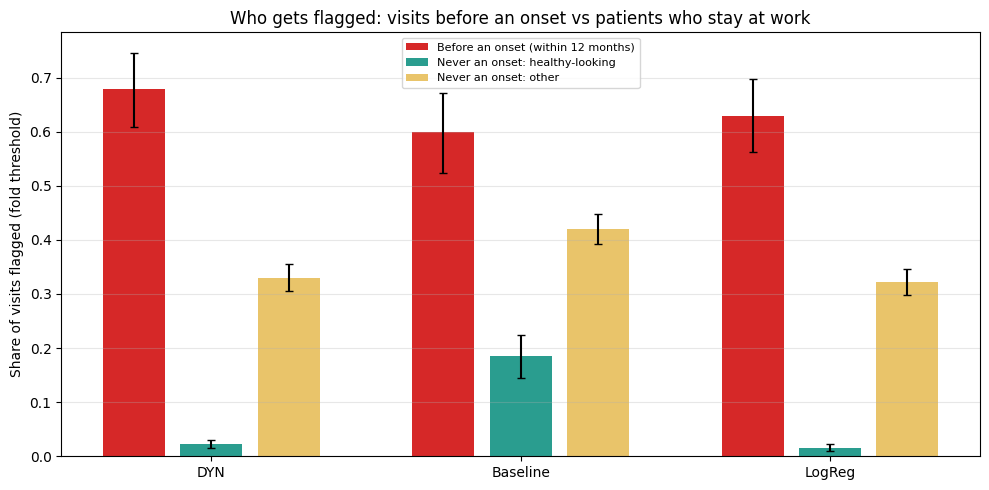

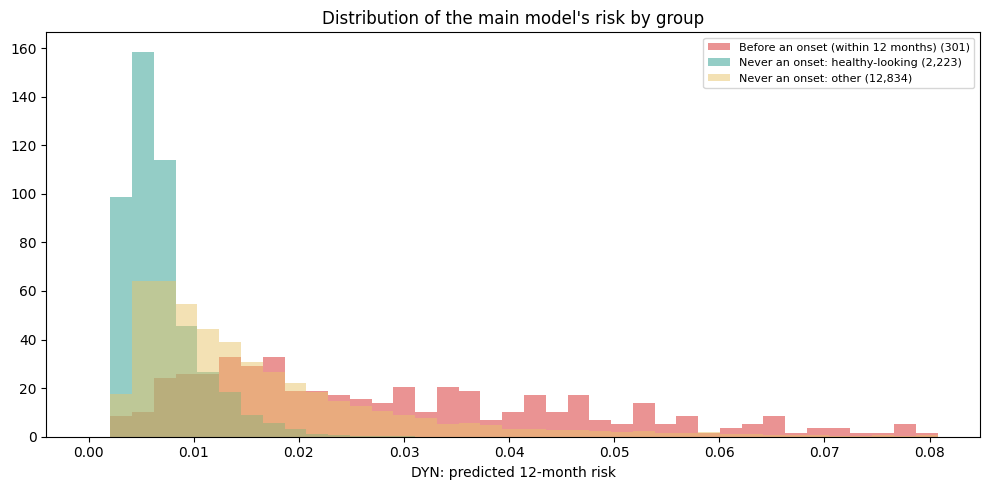

In [33]:
"""Healthy-looking stayers: risk, flags and time-matched AUROC."""
_v = visits.loc[LAND_VROW]
HEALTHY = ((_v["LLDAS_NOW"].values == 1) & (_v["score_n"].fillna(0).values == 0)
           & (_v["STERAVER_0"].values <= HEALTHY_PRED_MAX)
           & ~(_v[["FATIGUE", "ARTHRALGIA", "DYSPNOEA", "FIBROMYALGIA"]].fillna(0).values > 0).any(1))
NEVER = ~np.isin(PID_ALL, list(EVER_ONSET))
NEAR = (C_ALL == 1) & (T_ALL <= HORIZON_DAYS)
GROUPS = {"Before an onset (within 12 months)": NEAR, "Never an onset: healthy-looking": NEVER & HEALTHY,
          "Never an onset: other": NEVER & ~HEALTHY}
print("Landmark visits / patients per group: " + ", ".join(
    f"{k}: {int(v.sum()):,} / {len(np.unique(PID_ALL[v]))}" for k, v in GROUPS.items()))
print(f"Healthy-looking visits among all landmarks: {HEALTHY.mean():.0%}; among those before an onset: "
      f"{HEALTHY[NEAR].mean():.0%}")
_d = TM["main"]
_hk = HEALTHY[_d["last"][_d["pk"]]]
for lab_, mk in [("healthy", _hk), ("other", ~_hk)]:
    _d[f"den_{lab_}"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(mk.sum()), (_d["ppc"][mk], _d["ppk"][mk])),
                                                                 shape=(P_, P_)).toarray())
for m in MODELS_RUN:
    acc = {}
    for r in REPEATS:
        z = zpred(m, r)
        p = _expit(z)
        thr = THR_V[m][r][H][MAIN_THRESHOLD]
        flag = (z >= thr).astype(np.float32)
        for g, mask in GROUPS.items():
            Wg = _W_ALL[:, mask]
            acc.setdefault(("mean_risk", g), []).append((Wg @ p[mask]) / Wg.sum(1))
            acc.setdefault(("flagged", g), []).append((Wg @ flag[mask]) / Wg.sum(1))
        s = np.asarray(_d["mat"] @ np.nan_to_num(z)).ravel()
        for lab_, mk in [("healthy", _hk), ("other", ~_hk)]:
            a, b_ = s[_d["pc"][mk]], s[_d["pk"][mk]]
            K = sparse.coo_matrix(((a > b_) + 0.5 * (a == b_), (_d["ppc"][mk], _d["ppk"][mk])), shape=(P_, P_)).toarray()
            acc.setdefault(("tm_auroc", lab_), []).append(_pair_sum_fast(_BOTH, K) / _d[f"den_{lab_}"])
    for k, v in acc.items():
        v = np.mean(v, 0)
        STATS[(m, "obj3") + k] = (float(v[0]), v[1:])
    fh = STATS[(m, "obj3", "flagged", "Never an onset: healthy-looking")]
    fo = STATS[(m, "obj3", "flagged", "Never an onset: other")]
    STATS[(m, "obj3", "flag_diff")] = (fh[0] - fo[0], fh[1] - fo[1])
rows = []
for m in MODELS_RUN:
    row = {"Model": short_label(m)}
    for g in GROUPS:
        row[f"Mean 12-mo risk: {g}"] = fmtk((m, "obj3", "mean_risk", g))
    for g in GROUPS:
        row[f"Flagged: {g}"] = fmtk((m, "obj3", "flagged", g))
    row["Flagged, healthy minus other stayers"] = fmtk((m, "obj3", "flag_diff"))
    row["Time-matched AUROC vs healthy-looking controls"] = fmtk((m, "obj3", "tm_auroc", "healthy"))
    row["Time-matched AUROC vs other controls"] = fmtk((m, "obj3", "tm_auroc", "other"))
    rows.append(row)
OBJ3 = pd.DataFrame(rows).set_index("Model")
display(OBJ3.T)
OBJ3.to_csv(f"objective3_healthy_{TAG}.csv")
_fd = ci((MAIN_MODEL, "obj3", "flag_diff"))
HYP_ROWS.append({"Hypothesis": "H3a", "Estimand": "Main: share flagged, healthy-looking minus other stayers",
                 "Estimate (95% CI)": fmt(*_fd), "Criterion": "upper bound < 0", "Met": _fd[2] < 0})
for hyp, b_ in [("H3b", BASELINE), ("H3c", LOGREG)]:
    d = diff(MAIN_MODEL, b_, ("obj3", "tm_auroc", "healthy"))
    HYP_ROWS.append({"Hypothesis": hyp, "Estimand": f"DYN - {short_label(b_)}, time-matched AUROC vs healthy-looking "
                     "controls", "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0", "Met": d[1] > 0,
                     "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})
fig, ax = plt.subplots(figsize=(10, 5))
_gcol = ["#d62828", "#2a9d8f", "#e9c46a"]
_km = [m for m in KEY_MODELS if m in MODELS_RUN]
for j, m in enumerate(_km):
    for k, g in enumerate(GROUPS):
        a = ci((m, "obj3", "flagged", g))
        ax.bar(j * 4 + k, a[0], color=_gcol[k], yerr=[[a[0] - a[1]], [a[2] - a[0]]], capsize=3,
               label=g if j == 0 else None)
ax.set_xticks([j * 4 + 1 for j in range(len(_km))]); ax.set_xticklabels([short_label(m) for m in _km])
ax.set_ylabel("Share of visits flagged (fold threshold)"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
ax.set_title("Who gets flagged: visits before an onset vs patients who stay at work")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_healthy_flags.png", dpi=150, bbox_inches="tight"); plt.show()
fig, ax = plt.subplots(figsize=(10, 5))
pz = _expit(np.mean([zpred(MAIN_MODEL, r) for r in REPEATS], 0))
bins = np.linspace(0, np.percentile(pz, 99), 40)
for (g, mask), c in zip(GROUPS.items(), _gcol):
    ax.hist(pz[mask], bins=bins, density=True, alpha=0.5, color=c, label=f"{g} ({int(mask.sum()):,})")
ax.set_xlabel(f"{short_label(MAIN_MODEL)}: predicted 12-month risk"); ax.legend(fontsize=8)
ax.set_title("Distribution of the main model's risk by group")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_healthy_hist.png", dpi=150, bbox_inches="tight"); plt.show()

## 15.2 Who are the false positives?

Visits of patients who never have an onset that the main model flags, against those it does not flag, and against
visits before an onset: the mean of key variables and the standardised mean difference (SMD) of flagged vs not
flagged stayers. Shows what makes a stayer look high-risk.

In [34]:
"""Profile of the main model's false positives."""
_zm = np.mean([zpred(MAIN_MODEL, r) for r in REPEATS], 0)
_tm = np.nanmean([THR_V[MAIN_MODEL][r][H][MAIN_THRESHOLD] for r in REPEATS], 0)
FP = NEVER & (_zm >= _tm)
TN = NEVER & (_zm < _tm)
rows = []
for c in FP_PROFILE_VARS:
    x = _v[c].astype(float).values
    a, b_, n_ = np.nanmean(x[FP]), np.nanmean(x[TN]), np.nanmean(x[NEAR])
    sd = np.sqrt((np.nanvar(x[FP]) + np.nanvar(x[TN])) / 2)
    rows.append({"Variable": DISPLAY_NAMES.get(c, c), "Flagged stayers (false positives)": round(a, 2),
                 "Unflagged stayers": round(b_, 2), "Before an onset": round(n_, 2),
                 "SMD flagged vs unflagged": round((a - b_) / sd if sd > 0 else np.nan, 2)})
FPT = pd.DataFrame(rows).set_index("Variable").sort_values("SMD flagged vs unflagged", key=np.abs, ascending=False)
print(f"Stayer visits flagged: {int(FP.sum()):,} of {int(NEVER.sum()):,} ({FP.sum() / NEVER.sum():.0%}); healthy-looking "
      f"among them: {HEALTHY[FP].mean():.0%} (among unflagged: {HEALTHY[TN].mean():.0%})")
display(FPT)
FPT.to_csv(f"objective3_false_positives_{TAG}.csv")

Stayer visits flagged: 4,190 of 15,057 (28%); healthy-looking among them: 1% (among unflagged: 20%)


,Flagged stayers (false positives),Unflagged stayers,Before an onset,SMD flagged vs unflagged
Variable,,,,
Calendar year (adjustment),2006.73,2013.24,2007.32,-0.92
"Prednisone, average dose since last visit (mg/day)",9.36,2.28,10.00,0.88
Fibromyalgia tender points (0-18),4.98,0.68,4.11,0.84
"Acute visits, last 12 months",0.72,0.19,0.68,0.80
Fibromyalgia,0.29,0.03,0.23,0.77
SLEDAI-2K,5.15,2.82,5.37,0.57
"Clinic visits per year, last 12 mo",3.86,3.17,3.82,0.56
Arthralgia,0.41,0.18,0.39,0.55
Fatigue,0.21,0.04,0.21,0.52


## 15.3 Conclusion — Objective 3

In [35]:
"""Objective 3 conclusion."""
_h3 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H3")]
_m = MAIN_MODEL
txt = (f"Main model: mean 12-month risk {ci((_m, 'obj3', 'mean_risk', 'Before an onset (within 12 months)'))[0]:.3f} "
       f"before an onset, {ci((_m, 'obj3', 'mean_risk', 'Never an onset: other'))[0]:.3f} in other stayers and "
       f"{ci((_m, 'obj3', 'mean_risk', 'Never an onset: healthy-looking'))[0]:.3f} in healthy-looking stayers; share "
       f"flagged {ci((_m, 'obj3', 'flagged', 'Before an onset (within 12 months)'))[0]:.0%} / "
       f"{ci((_m, 'obj3', 'flagged', 'Never an onset: other'))[0]:.0%} / "
       f"{ci((_m, 'obj3', 'flagged', 'Never an onset: healthy-looking'))[0]:.0%}. Time-matched AUROC against "
       f"healthy-looking controls {fmtk((_m, 'obj3', 'tm_auroc', 'healthy'))}, against other controls "
       f"{fmtk((_m, 'obj3', 'tm_auroc', 'other'))}. Largest differences of flagged vs unflagged stayers: " + ", ".join(
           f"{i} (SMD {r_['SMD flagged vs unflagged']:+.2f})" for i, r_ in FPT.head(4).iterrows()) + ". Hypotheses: " +
       "; ".join(f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: {'met' if r_['Met'] else 'not met'}"
                 for r_ in _h3) + ".")
OBJ_CONCLUSIONS["Objective 3"] = txt
print(textwrap.fill(txt, 118))

Main model: mean 12-month risk 0.036 before an onset, 0.017 in other stayers and 0.007 in healthy-looking stayers;
share flagged 68% / 33% / 2%. Time-matched AUROC against healthy-looking controls 0.926 (0.895 to 0.954), against
other controls 0.709 (0.667 to 0.752). Largest differences of flagged vs unflagged stayers: Calendar year (adjustment)
(SMD -0.92), Prednisone, average dose since last visit (mg/day) (SMD +0.88), Fibromyalgia tender points (0-18) (SMD
+0.84), Acute visits, last 12 months (SMD +0.80). Hypotheses: H3a (Main: share flagged, healthy-looking minus other
stayers) -0.308 (-0.335 to -0.280): met; H3b (DYN - Baseline, time-matched AUROC vs healthy-looking controls) 0.160
(0.110 to 0.218): met; H3c (DYN - LogReg, time-matched AUROC vs healthy-looking controls) -0.002 (-0.018 to 0.013):
not met.


---
# 16. Objective 4 — What drives the main model's risk (SHAP)

## 16.1 SHAP values of the dynamic LSTM

The main model is refitted on the five outer folds of CV repeat 1 exactly as in the cross-validation (same training
patients, preprocessing and seeds; 5 networks per fold), keeping the networks. Each fold's ensemble explains **its
own test patients** (patients it never saw): every test landmark of a patient within 48 months before an onset plus a
random sample of the other test landmarks, landmarks with a full 2-year window (5 grid points). Output explained: the
**onset log-hazard** (ensemble mean; the one-hazard model's 12-month risk rises with it). Method: expected
gradients (`shap.GradientExplainer`) with a background of training-fold landmarks. Each value is attributed to an
input **at a grid point** (t − 24, t − 18, ..., t months), so SHAP shows both *which* inputs and *when*.

Two passes per fold:
* **All eras**: test landmarks of every calendar year against a background of training landmarks of every year.
* **Recent era** (landmarks from 2012 on, the period closest to how the model would be used): recent test landmarks
  against a background of recent training landmarks. The calendar year then barely differs from the background, so
  the attribution goes to the clinical inputs.

**Calendar year is an adjustment, not a risk driver.** Its two inputs (linear and spline) are kept in the model
(they set the risk level of each era), but they are left out of the importance rankings, domain shares and plots
below; their share of the attribution is reported on its own line ("calendar adjustment"). SHAP values are additive,
so leaving them out does not change the other inputs' values. The calendar year can still interact with the clinical
inputs inside the network; the recent-era pass shows the drivers with the era held almost fixed.

In [36]:
"""Refit the main model on the outer folds of repeat 1 (networks kept); SHAP for its test patients, all eras and recent."""
import shap


_BAND_MAIN = is_band(MAIN_MODEL)


class NearOnsetEnsemble(nn.Module):
    """The fold's ensemble on dense full windows (n, T, F): the onset log-hazard (one-hazard model) or the mean onset
    log-hazard of bands 1-2 (months 0-12, band model)."""

    def __init__(self, states, n_in):
        super().__init__()
        self.nets = nn.ModuleList()
        for st_ in states:
            net = GridNet(n_in, SEQ_CFG["hidden"], SEQ_CFG["dropout"], n_out=2 * N_BANDS if _BAND_MAIN else 2)
            net.load_state_dict(st_); net.eval()
            self.nets.append(net)

    def forward(self, x):
        outs = []
        for net in self.nets:
            _, (h, _) = net.rnn(x)
            z = net.head(torch.cat([h[-1], x[:, -1]], -1))
            outs.append(z[:, :2].mean(1) if _BAND_MAIN else z[:, 0])
        return torch.stack(outs, 1).mean(1, keepdim=True)


SHAP_RECENT_FROM = ERA_BANDS[-1][0]                  # the recent era: landmarks from 2012 on
_d_main = parse_model(MAIN_MODEL)
_st, _ln = grid_window(_d_main["lookback"])
T_SH = lookback_points(_d_main["lookback"])
FULL = LG_LEN >= T_SH
RECENT = land["CAL_YEAR"].values >= SHAP_RECENT_FROM
SHAP_RES = _load(SHAP_PATH, {})


def _shap_pass(model, VX, te_rows, tr_rows, seed):
    """SHAP of `model` for the near-onset test landmarks + a sample of the others, against a training background."""
    rng = np.random.RandomState(seed)
    mo_before = np.array([(FIRST_ONSET[PID_ALL[i]].value / 8.64e13 - _LAND_T[i]) / MONTH_DAYS
                          if PID_ALL[i] in EVER_ONSET else np.nan for i in te_rows])
    near = te_rows[(mo_before > 0) & (mo_before <= TRAJ_MAX_MONTHS)]
    other = np.setdiff1d(te_rows, near)
    n_other = max(0, SHAP_N_EXPLAIN - len(near))
    ex_rows = np.sort(np.r_[near, rng.choice(other, min(n_other, len(other)), replace=False)])
    bg_rows = rng.choice(tr_rows, min(SHAP_N_BACKGROUND, len(tr_rows)), replace=False)
    dense = lambda rows: np.stack([VX[_st[i]:_st[i] + T_SH] for i in rows]).astype(np.float32)
    Xe, Xb = dense(ex_rows), dense(bg_rows)
    expl = shap.GradientExplainer(model, torch.from_numpy(Xb))
    sv = expl.shap_values(torch.from_numpy(Xe), nsamples=SHAP_SAMPLES)
    sv = np.asarray(sv[0] if isinstance(sv, list) else sv)
    if sv.ndim == 4:
        sv = sv[..., 0]
    with torch.no_grad():
        out = model(torch.from_numpy(Xe)).numpy().ravel()
    return {"rows": ex_rows, "sv": sv.astype(np.float32), "X": Xe, "out": out, "n_near": len(near)}


for f in range(CV_N_SPLITS):
    if f in SHAP_RES and ("recent", f) in SHAP_RES:
        continue
    t0 = time.time()
    r = SHAP_REPEAT
    tr_p, te_p = OUTER[r][f]
    prep = GridPrep(grid_cols_of(MAIN_MODEL)).fit(rows_of(tr_p))
    VX = prep.transform(GRID_RAW)
    res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")(
        delayed(fit_grid)(SEQ_CFG, VX, _st, _ln, tr_p, SEED + 1000 * CV_INNER_SPLITS + 31 * s + 7 * r + f, te_p,
                          _d_main["hazard"], False, None, True) for s in range(SEQ_SEEDS_FINAL))
    model = NearOnsetEnsemble([x[2] for x in res], VX.shape[1])
    te_rows = rows_of(te_p); te_rows = te_rows[FULL[te_rows]]
    tr_rows = rows_of(tr_p); tr_rows = tr_rows[FULL[tr_rows]]
    torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
    if f not in SHAP_RES:
        SHAP_RES[f] = {**_shap_pass(model, VX, te_rows, tr_rows, SEED + f), "names": prep.names}
    SHAP_RES[("recent", f)] = {**_shap_pass(model, VX, te_rows[RECENT[te_rows]], tr_rows[RECENT[tr_rows]],
                                            SEED + 100 + f), "names": prep.names}
    _save(SHAP_RES, SHAP_PATH)
    print(f"  fold {f + 1}: all eras {len(SHAP_RES[f]['rows'])} landmarks ({SHAP_RES[f]['n_near'] if 'n_near' in SHAP_RES[f] else '-'}"
          f" within 48 months before an onset) | recent era {len(SHAP_RES[('recent', f)]['rows'])} "
          f"({SHAP_RES[('recent', f)]['n_near']}) | {(time.time() - t0) / 60:.1f} min", flush=True)


def _stack(key):
    parts = [SHAP_RES[key(f)] for f in range(CV_N_SPLITS)]
    return (np.concatenate([p["rows"] for p in parts]), np.concatenate([p["sv"] for p in parts]),
            np.concatenate([p["X"] for p in parts]), np.concatenate([p["out"] for p in parts]),
            np.concatenate([np.full(len(p["rows"]), f) for f, p in enumerate(parts)]))


SH_ROWS, SV, SX, SH_OUT, SH_FOLD = _stack(lambda f: f)                     # SV: (n, T, F)
SH_ROWS_R, SV_R, SX_R, SH_OUT_R, SH_FOLD_R = _stack(lambda f: ("recent", f))
SH_NAMES = SHAP_RES[0]["names"]
SV_SUM, SV_SUM_R = SV.sum(1), SV_R.sum(1)                                  # per input, over the grid points


def sh_display(c):
    if c.endswith("__MISSING"):
        return f"{DISPLAY_NAMES.get(c[:-9], c[:-9])}: missing"
    return DISPLAY_NAMES.get(c, c)


def sh_domain(c):
    if c.endswith("__MISSING"):
        return "Missing-value indicators"
    return FEATURE_GROUP.get(c, FEATURE_GROUP.get(c.split("__")[0], "Other"))


SH_DISPLAY = np.array([sh_display(c) for c in SH_NAMES])
SH_DOMAIN = np.array([sh_domain(c) for c in SH_NAMES])
IS_CAL = np.array([c.split("__")[0] in YEAR_COLS for c in SH_NAMES])     # the calendar adjustment
CLIN = ~IS_CAL                                                             # every other input: the risk drivers
CLIN_NAMES = [c for c, k in zip(SH_NAMES, CLIN) if k]


def cal_share(sv_sum):
    """Calendar adjustment's share of the total mean |SHAP| (all inputs)."""
    a = np.abs(sv_sum).mean(0)
    return a[IS_CAL].sum() / a.sum()


for lab_, rows_, sv_, out_ in [("All eras", SH_ROWS, SV, SH_OUT), (f"Recent era ({SHAP_RECENT_FROM} on)", SH_ROWS_R,
                                                                     SV_R, SH_OUT_R)]:
    print(f"SHAP, {lab_}: {len(rows_):,} test landmarks from {len(np.unique(PID_ALL[rows_]))} patients; "
          f"{sv_.shape[1]} grid points x {sv_.shape[2]} inputs ({CLIN.sum()} clinical + {IS_CAL.sum()} calendar). "
          f"Additivity: corr(sum of SHAP, output) = {np.corrcoef(sv_.sum((1, 2)), out_)[0, 1]:.3f}. "
          f"Calendar adjustment: {cal_share(sv_.sum(1)):.0%} of the total |SHAP|")

SHAP, All eras: 7,500 test landmarks from 782 patients; 5 grid points x 67 inputs (65 clinical + 2 calendar). Additivity: corr(sum of SHAP, output) = 0.993. Calendar adjustment: 12% of the total |SHAP|
SHAP, Recent era (2012 on): 6,742 test landmarks from 629 patients; 5 grid points x 67 inputs (65 clinical + 2 calendar). Additivity: corr(sum of SHAP, output) = 0.994. Calendar adjustment: 8% of the total |SHAP|


## 16.2 Global importance: inputs, domains, and current status vs history

Mean |SHAP| of each **clinical** input summed over its grid points (log-hazard units); shares are of the clinical
total. The calendar adjustment is printed on its own line. The beeswarm shows the direction (colour = the input's
standardised value at the landmark). Then each domain's share and each grid point's share (the landmark visit itself
vs the 6-24 months before it), clinical inputs only.

,Input,Domain,Mean |SHAP|,Mean SHAP,Share of clinical total
score_n,SDI damage score,Damage,0.1537,0.0057,0.0519
age_at_record,Age,Demographics,0.1519,-0.0011,0.0513
SLEDAI2_I,SLEDAI-2K,Disease activity,0.1229,0.0096,0.0415
score_n__DEV,SDI: now minus own usual,Change from own baseline,0.1189,0.0119,0.0401
AM_CLASS,Antimalarial (HCQ; chloroquine in earlier years),Era of care,0.1129,-0.0014,0.0381
EDU_HIGHER,Education: higher,Work,0.1118,0.0014,0.0377
STERAVER_0,"Prednisone, average dose since last visit (mg/...",Treatment,0.1107,0.0123,0.0374
TENDER_POINTS,Fibromyalgia tender points (0-18),Pain,0.1101,-0.0033,0.0372
SMOKER,Current smoker,Smoking,0.0951,0.0087,0.0321
VISIT_RATE_1Y,"Clinic visits per year, last 12 mo",Care pattern,0.0909,0.0059,0.0307


Calendar adjustment (all eras; calendar year, linear + spline): mean |SHAP| 0.403, 12% of all attribution; not a risk driver, left out of the rankings


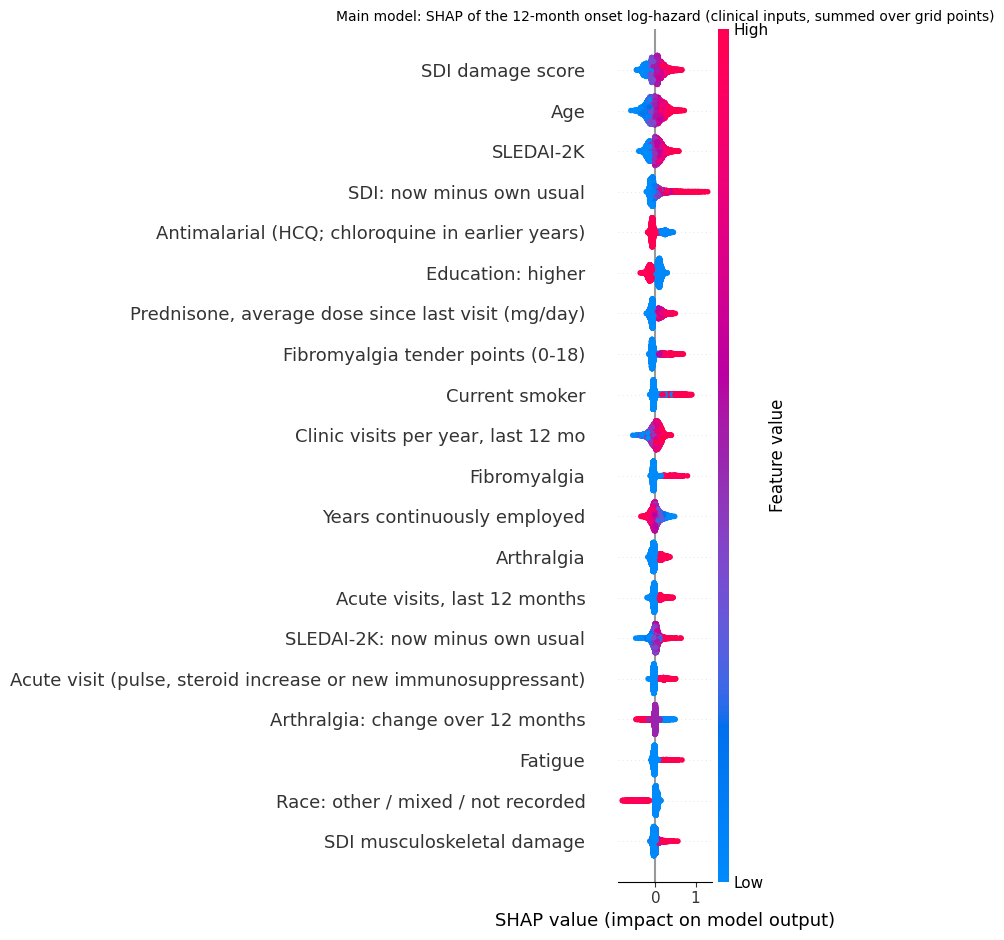

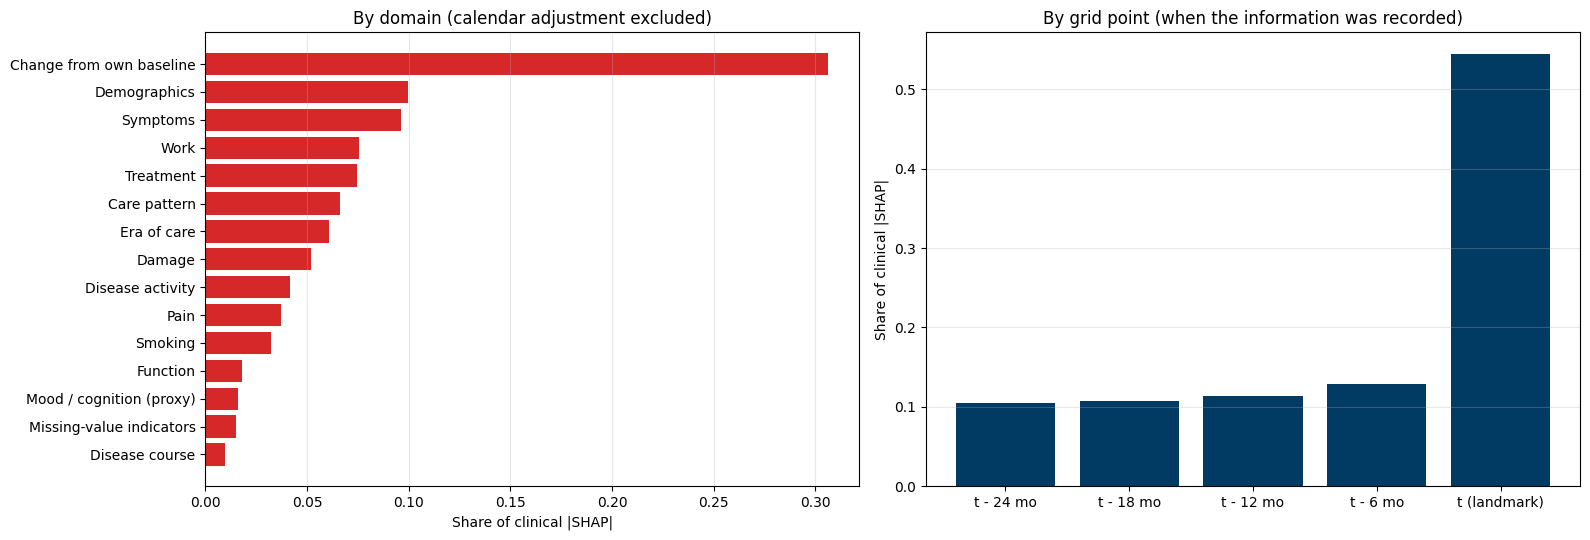

,Share of clinical |SHAP|
Domain,
Change from own baseline,0.306
Demographics,0.100
Symptoms,0.096
Work,0.075
Treatment,0.074
Care pattern,0.066
Era of care,0.061
Damage,0.052
Disease activity,0.041


,Share of clinical |SHAP|
t - 24 mo,0.105
t - 18 mo,0.107
t - 12 mo,0.114
t - 6 mo,0.129
t (landmark),0.545


Change-from-own-baseline inputs: 31% of the clinical |SHAP|; the landmark grid point: 54%


In [37]:
"""Global SHAP importance (clinical inputs; the calendar adjustment separately)."""


def importance(sv_sum):
    imp = pd.DataFrame({"Input": SH_DISPLAY[CLIN], "Domain": SH_DOMAIN[CLIN],
                        "Mean |SHAP|": np.abs(sv_sum[:, CLIN]).mean(0), "Mean SHAP": sv_sum[:, CLIN].mean(0)},
                       index=CLIN_NAMES).sort_values("Mean |SHAP|", ascending=False)
    imp["Share of clinical total"] = imp["Mean |SHAP|"] / imp["Mean |SHAP|"].sum()
    return imp


def cal_line(sv_sum, label):
    a = np.abs(sv_sum).mean(0)
    return (f"Calendar adjustment ({label}; calendar year, linear + spline): mean |SHAP| {a[IS_CAL].sum():.3f}, "
            f"{a[IS_CAL].sum() / a.sum():.0%} of all attribution; not a risk driver, left out of the rankings")


IMP = importance(SV_SUM)
display(IMP.head(25).round(4))
print(cal_line(SV_SUM, "all eras"))
IMP.to_csv(f"objective4_shap_importance_{TAG}.csv")
plt.figure()
shap.summary_plot(SV_SUM[:, CLIN], SX[:, -1, CLIN], feature_names=list(SH_DISPLAY[CLIN]), max_display=20, show=False)
plt.title("Main model: SHAP of the 12-month onset log-hazard (clinical inputs, summed over grid points)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()


def domain_shares(imp):
    d = imp.groupby("Domain")["Mean |SHAP|"].sum().sort_values(ascending=False)
    return (d / d.sum()).rename("Share of clinical |SHAP|")


def time_shares(sv):
    a = np.abs(sv[:, :, CLIN]).sum(2).mean(0)
    return pd.Series(a / a.sum(), index=[f"t - {6 * (T_SH - 1 - k)} mo" if k < T_SH - 1 else "t (landmark)"
                                         for k in range(T_SH)], name="Share of clinical |SHAP|")


DOMS, TIME_SHARE = domain_shares(IMP), time_shares(SV)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].barh(DOMS.index[::-1], DOMS.values[::-1], color="#d62828"); axes[0].set_xlabel("Share of clinical |SHAP|")
axes[0].set_title("By domain (calendar adjustment excluded)"); axes[0].grid(axis="x", alpha=0.3)
axes[1].bar(TIME_SHARE.index, TIME_SHARE.values, color="#013a63"); axes[1].set_ylabel("Share of clinical |SHAP|")
axes[1].set_title("By grid point (when the information was recorded)"); axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_shap_domains_time.png", dpi=150, bbox_inches="tight"); plt.show()
display(DOMS.to_frame().round(3)); display(TIME_SHARE.to_frame().round(3))
_chg = IMP.loc[IMP["Domain"] == "Change from own baseline", "Share of clinical total"].sum()
print(f"Change-from-own-baseline inputs: {_chg:.0%} of the clinical |SHAP|; the landmark grid point: "
      f"{TIME_SHARE.iloc[-1]:.0%}")

## 16.3 How the top inputs act (dependence)

The SHAP value of each of the six most important clinical inputs (summed over grid points) against the input's
value at the landmark (original units), coloured by whether the landmark is within 12 months before an onset.

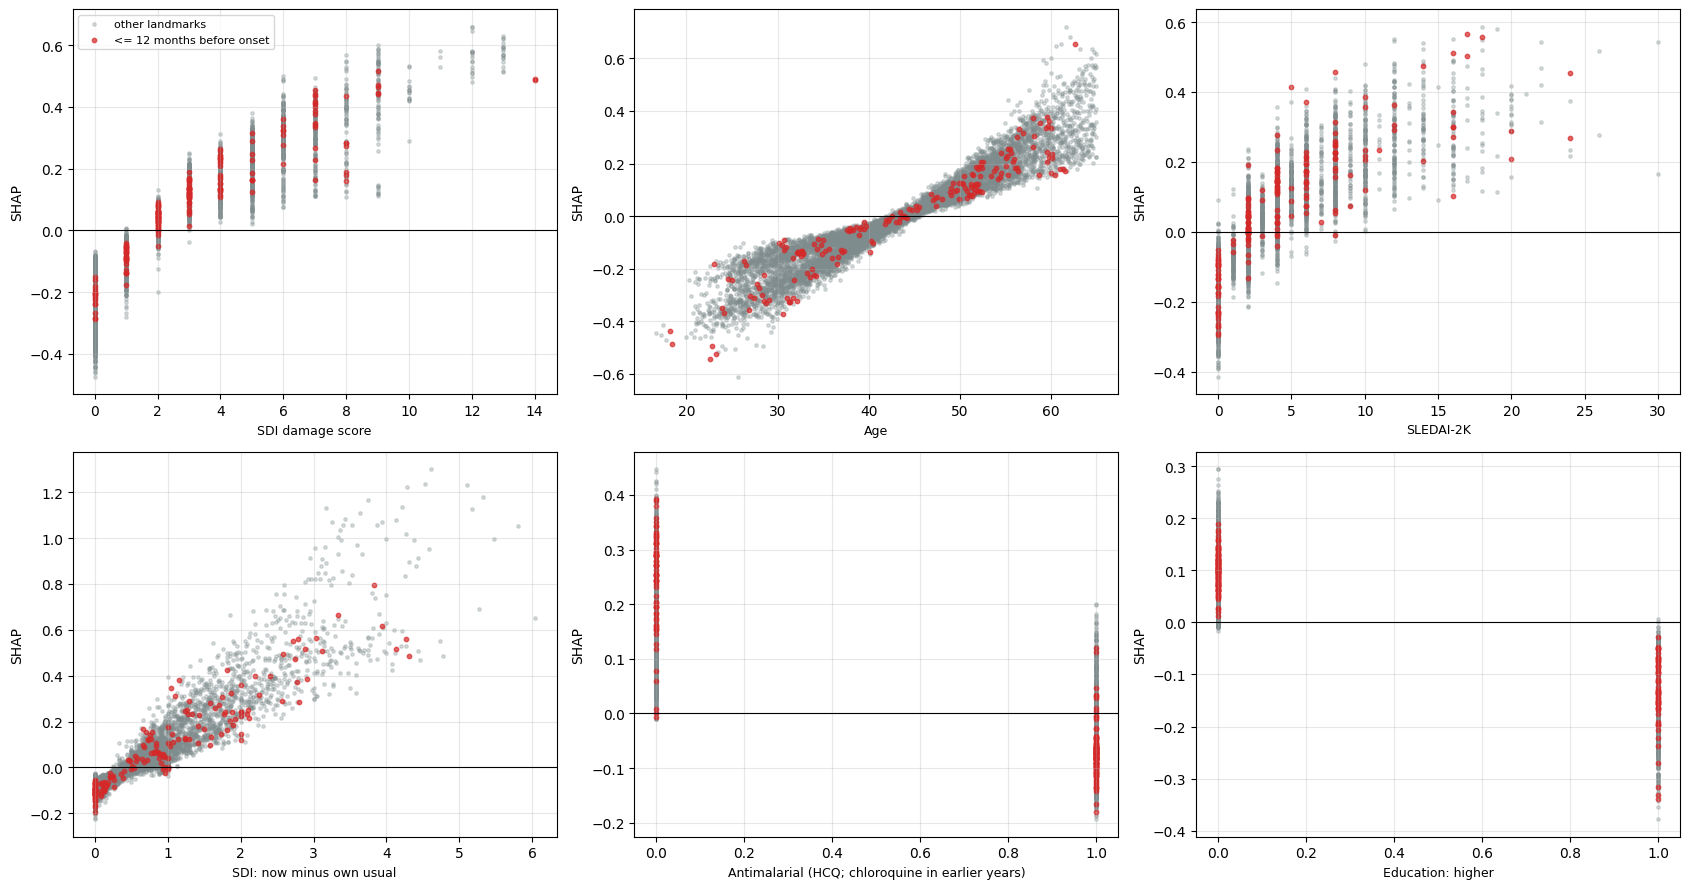

In [38]:
"""Dependence plots of the six most important clinical inputs."""
_raw_last = GRID_RAW[LG_START[SH_ROWS] + LG_LEN[SH_ROWS] - 1]
_near12 = np.array([(PID_ALL[i] in EVER_ONSET) and 0 < (FIRST_ONSET[PID_ALL[i]].value / 8.64e13 - _LAND_T[i])
                    / MONTH_DAYS <= 12 for i in SH_ROWS])
top6 = [c for c in IMP.index if not c.endswith("__MISSING")][:6]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), top6):
    j = SH_NAMES.index(c)
    x = _raw_last[:, GRID_COLS.index(c)] if c in GRID_COLS else SX[:, -1, j]
    ax.scatter(x[~_near12], SV_SUM[~_near12, j], s=6, alpha=0.3, color="#7f8c8d", label="other landmarks")
    ax.scatter(x[_near12], SV_SUM[_near12, j], s=10, alpha=0.7, color="#d62828", label="<= 12 months before onset")
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(sh_display(c), fontsize=9); ax.set_ylabel("SHAP")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_shap_dependence.png", dpi=150, bbox_inches="tight"); plt.show()

## 16.4 What drives the rise before the onset, and what keeps healthy-looking stayers low

Mean signed SHAP per clinical domain (summed over its inputs and grid points) in landmarks of onset patients by
months before the onset, and in landmarks of patients who never have an onset (healthy-looking or not). Positive =
pushes the risk up relative to the background. The calendar adjustment is a separate column, not in the clinical
total; in the plot it is the grey dashed line.

,Change from own baseline,Demographics,Symptoms,Work,Treatment,Care pattern,Era of care,Damage,Disease activity,Pain,Smoking,Function,Mood / cognition (proxy),Missing-value indicators,Disease course,"Total, clinical",Calendar adjustment,Landmarks
group,,,,,,,,,,,,,,,,,,
Onset in 36-48 mo,0.180,0.022,0.225,0.043,0.072,0.013,0.024,0.050,0.028,0.073,0.056,0.011,0.007,-0.004,-0.006,0.792,0.312,138
Onset in 24-36 mo,0.010,0.036,0.202,0.054,0.062,0.012,0.028,0.068,0.046,0.046,0.047,0.022,0.008,-0.009,-0.010,0.624,0.278,139
Onset in 12-24 mo,0.140,0.035,0.193,0.033,0.064,0.009,0.043,0.070,0.058,0.048,0.048,0.026,0.002,-0.003,-0.007,0.757,0.277,174
Onset in 6-12 mo,0.241,0.021,0.247,0.036,0.140,-0.001,0.063,0.107,0.077,0.067,0.040,0.023,0.011,0.005,-0.007,1.072,0.245,106
Onset in 0-6 mo,0.278,0.022,0.196,0.058,0.130,0.017,0.059,0.091,0.080,0.059,0.056,0.020,0.016,0.003,-0.012,1.072,0.193,79
Never: other,0.055,0.009,0.002,0.008,0.043,0.005,0.002,0.032,0.012,-0.005,0.003,0.011,0.011,0.001,0.001,0.189,-0.030,5371
Never: healthy-looking,-0.168,-0.062,-0.165,-0.004,-0.101,-0.007,-0.026,-0.226,-0.038,-0.058,-0.009,-0.022,-0.019,0.004,0.005,-0.899,-0.088,910


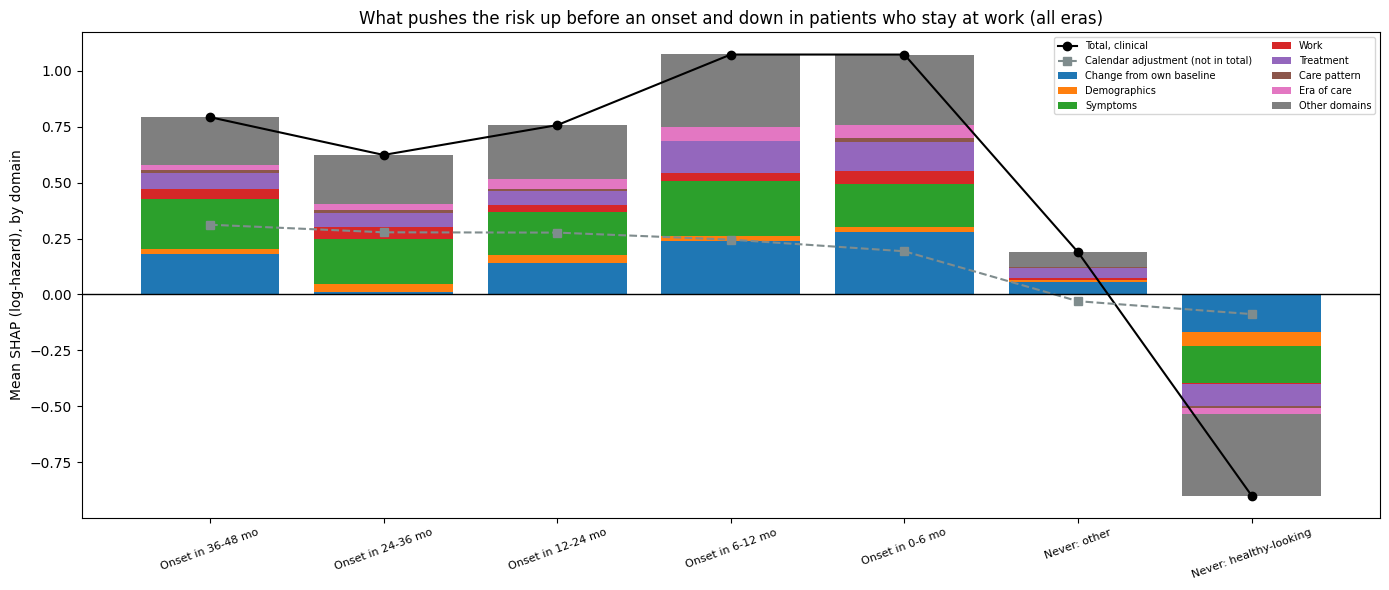

In [39]:
"""SHAP by time before the onset and in stayers."""
G_ORDER = [f"Onset in {a}-{b_} mo" for a, b_ in TTO_BINS][::-1] + ["Never: other", "Never: healthy-looking"]


def shap_by_group(rows, sv_sum, doms):
    mo = np.array([(FIRST_ONSET[PID_ALL[i]].value / 8.64e13 - _LAND_T[i]) / MONTH_DAYS if PID_ALL[i] in EVER_ONSET
                   else np.nan for i in rows])
    g = np.full(len(rows), None, object)
    for a, b_ in TTO_BINS:
        g[(mo > a) & (mo <= b_)] = f"Onset in {a}-{b_} mo"
    nev = ~np.isin(PID_ALL[rows], list(EVER_ONSET))
    g[nev & HEALTHY[rows]] = "Never: healthy-looking"
    g[nev & ~HEALTHY[rows]] = "Never: other"
    d = pd.DataFrame({k: sv_sum[:, CLIN & (SH_DOMAIN == k)].sum(1) for k in doms.index})
    d["Calendar adjustment"] = sv_sum[:, IS_CAL].sum(1)
    d["group"] = g
    out = d.dropna(subset=["group"]).groupby("group").mean().reindex(G_ORDER)
    out.insert(len(doms), "Total, clinical", out[list(doms.index)].sum(1))
    out["Landmarks"] = d.groupby("group").size().reindex(G_ORDER)
    return out


BYGRP = shap_by_group(SH_ROWS, SV_SUM, DOMS)
display(BYGRP.round(3))
BYGRP.to_csv(f"objective4_shap_by_group_{TAG}.csv")


def plot_by_group(bygrp, doms, title, path):
    top_d = list(doms.index[:7])
    fig, ax = plt.subplots(figsize=(14, 6))
    bottom_p, bottom_n = np.zeros(len(G_ORDER)), np.zeros(len(G_ORDER))
    cmap = plt.get_cmap("tab10")
    for k, d in enumerate(top_d + ["Other domains"]):
        v = bygrp[d].values if d != "Other domains" else bygrp[[c for c in doms.index if c not in top_d]].sum(1).values
        v = np.nan_to_num(v)
        pos, neg = np.clip(v, 0, None), np.clip(v, None, 0)
        ax.bar(range(len(G_ORDER)), pos, bottom=bottom_p, color=cmap(k), label=d)
        ax.bar(range(len(G_ORDER)), neg, bottom=bottom_n, color=cmap(k))
        bottom_p += pos; bottom_n += neg
    ax.plot(range(len(G_ORDER)), bygrp["Total, clinical"].values, "ko-", label="Total, clinical")
    ax.plot(range(len(G_ORDER)), bygrp["Calendar adjustment"].values, "s--", color="#7f8c8d",
            label="Calendar adjustment (not in total)")
    ax.axhline(0, color="k", lw=1); ax.set_xticks(range(len(G_ORDER)))
    ax.set_xticklabels(G_ORDER, rotation=20, fontsize=8)
    ax.set_ylabel("Mean SHAP (log-hazard), by domain"); ax.legend(fontsize=7, ncol=2); ax.set_title(title)
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show()


plot_by_group(BYGRP, DOMS, "What pushes the risk up before an onset and down in patients who stay at work (all eras)",
              f"{OUT_DIR}/{TAG}_shap_by_group.png")

## 16.5 Stability across folds

Each fold's ensemble explains different patients: the share of folds in which each clinical input is among the ten
most important, and the rank correlation of the folds' importance vectors (clinical inputs).

In [40]:
"""SHAP stability across folds (clinical inputs)."""


def stability(sv_sum, fold, imp):
    imp_f = pd.DataFrame({f"Fold {f + 1}": np.abs(sv_sum[fold == f][:, CLIN]).mean(0) for f in range(CV_N_SPLITS)},
                         index=CLIN_NAMES)
    top10 = (imp_f.rank(ascending=False) <= 10)
    stab = pd.DataFrame({"Input": SH_DISPLAY[CLIN],
                         "Overall rank": imp["Mean |SHAP|"].rank(ascending=False).reindex(CLIN_NAMES).values,
                         "Folds in top 10": top10.sum(1).values}, index=CLIN_NAMES).sort_values("Overall rank")
    rho = imp_f.corr(method="spearman").values[np.triu_indices(CV_N_SPLITS, 1)]
    return stab.head(20), rho


STAB, _rho = stability(SV_SUM, SH_FOLD, IMP)
display(STAB)
STAB.to_csv(f"objective4_shap_stability_{TAG}.csv")
print(f"Rank correlation of the folds' importance vectors: median {np.median(_rho):.2f} (range {_rho.min():.2f} to "
      f"{_rho.max():.2f})")

,Input,Overall rank,Folds in top 10
score_n,SDI damage score,1.0,5
age_at_record,Age,2.0,5
SLEDAI2_I,SLEDAI-2K,3.0,4
score_n__DEV,SDI: now minus own usual,4.0,4
AM_CLASS,Antimalarial (HCQ; chloroquine in earlier years),5.0,4
EDU_HIGHER,Education: higher,6.0,4
STERAVER_0,"Prednisone, average dose since last visit (mg/...",7.0,3
TENDER_POINTS,Fibromyalgia tender points (0-18),8.0,4
SMOKER,Current smoker,9.0,3
VISIT_RATE_1Y,"Clinic visits per year, last 12 mo",10.0,3


Rank correlation of the folds' importance vectors: median 0.76 (range 0.69 to 0.80)


## 16.6 Recent era: the drivers where the model would be used

The same analyses on the recent-era pass (test landmarks from 2012 on, explained against recent training
landmarks). The calendar year varies little here, so its share should be small and the clinical ranking is the one
that applies to current patients. Side by side with the all-era ranking; then the domains, the beeswarm, the groups
(near-onset groups are smaller: fewer onsets in recent years) and the fold stability.

Calendar adjustment (recent era, 2012 on; calendar year, linear + spline): mean |SHAP| 0.237, 8% of all attribution; not a risk driver, left out of the rankings
Calendar adjustment (all eras, for comparison; calendar year, linear + spline): mean |SHAP| 0.403, 12% of all attribution; not a risk driver, left out of the rankings


,Input,Domain,Recent: rank,Recent: share,Recent: mean SHAP,All eras: rank,All eras: share
age_at_record,Age,Demographics,1,0.056,0.005,2,0.051
score_n,SDI damage score,Damage,2,0.051,-0.006,1,0.052
score_n__DEV,SDI: now minus own usual,Change from own baseline,3,0.044,0.006,4,0.040
SLEDAI2_I,SLEDAI-2K,Disease activity,4,0.041,0.001,3,0.041
EDU_HIGHER,Education: higher,Work,5,0.041,0.001,6,0.038
STERAVER_0,"Prednisone, average dose since last visit (mg/...",Treatment,6,0.034,0.000,7,0.037
TENDER_POINTS,Fibromyalgia tender points (0-18),Pain,7,0.034,0.003,8,0.037
VISIT_RATE_1Y,"Clinic visits per year, last 12 mo",Care pattern,8,0.031,0.006,10,0.031
AM_CLASS,Antimalarial (HCQ; chloroquine in earlier years),Era of care,9,0.031,-0.001,5,0.038
YRS_CONT_EMPLOYED,Years continuously employed,Work,10,0.030,0.005,12,0.029


Rank correlation, recent vs all eras (clinical inputs): 0.98; top-10 overlap 9/10


,Recent era,All eras
Domain,,
Change from own baseline,0.312,0.306
Demographics,0.115,0.100
Work,0.083,0.075
Symptoms,0.082,0.096
Care pattern,0.074,0.066
Treatment,0.071,0.074
Era of care,0.054,0.061
Damage,0.051,0.052
Disease activity,0.041,0.041


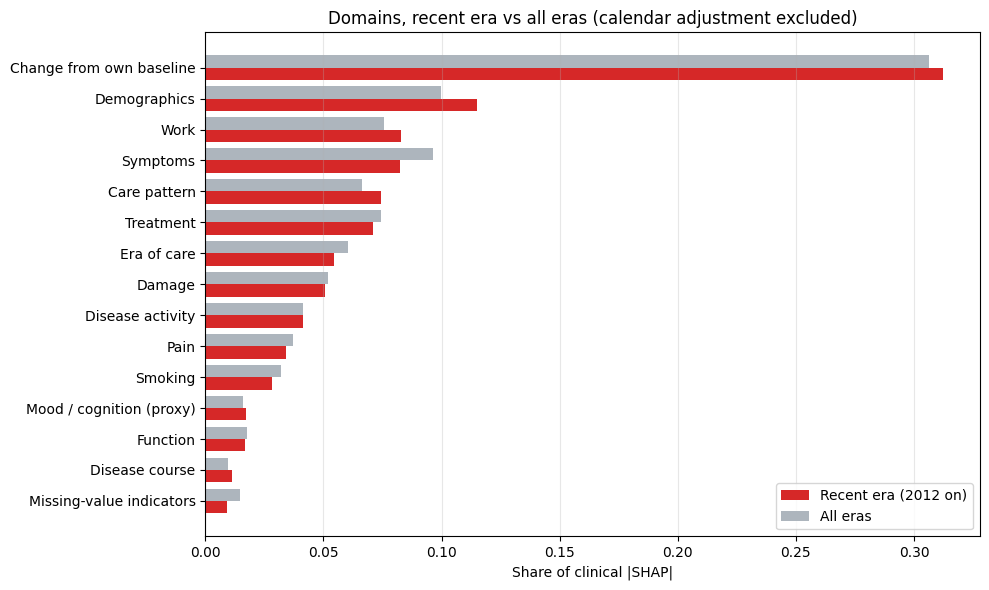

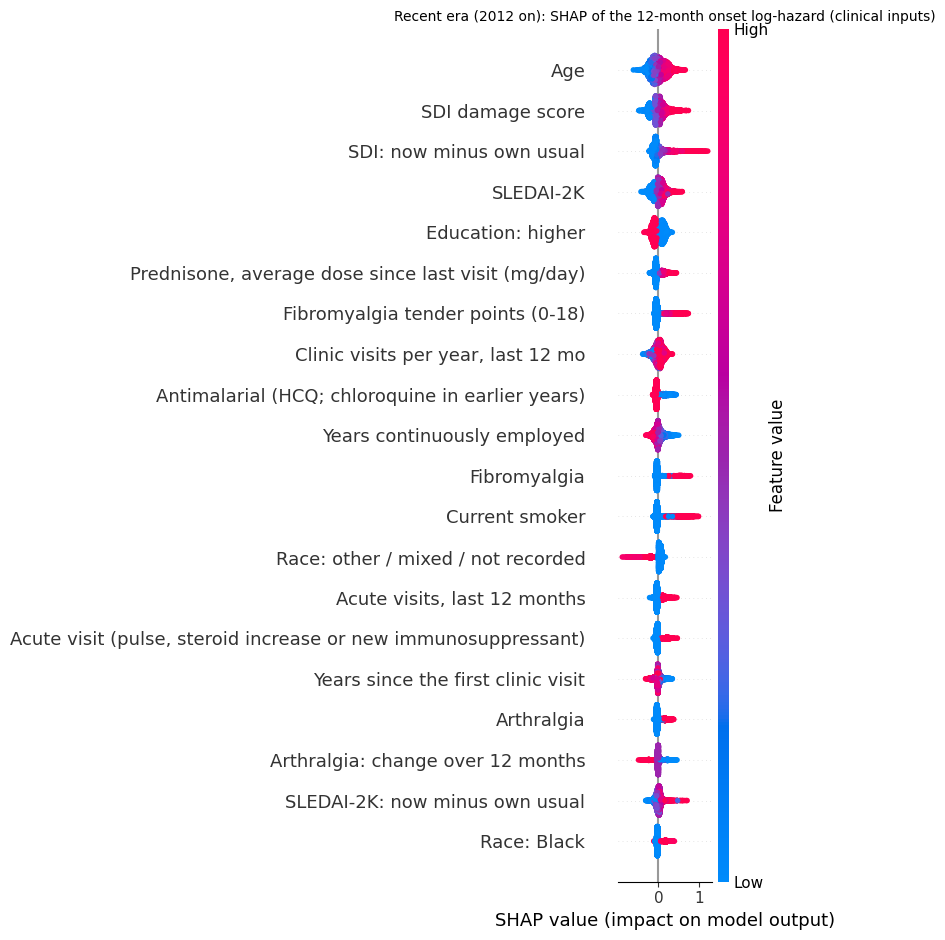

,Change from own baseline,Demographics,Work,Symptoms,Care pattern,Treatment,Era of care,Damage,Disease activity,Pain,Smoking,Mood / cognition (proxy),Function,Disease course,Missing-value indicators,"Total, clinical",Calendar adjustment,Landmarks
group,,,,,,,,,,,,,,,,,,
Onset in 36-48 mo,0.090,0.132,0.078,0.186,-0.016,0.059,0.016,0.081,0.030,0.053,0.018,0.023,-0.024,-0.002,-0.022,0.702,0.248,26
Onset in 24-36 mo,0.005,0.054,0.095,0.085,-0.058,0.000,-0.028,0.045,0.048,0.078,0.014,0.009,-0.020,0.014,-0.012,0.328,0.307,36
Onset in 12-24 mo,0.005,0.029,0.042,0.153,-0.052,-0.035,-0.006,-0.033,0.067,0.078,0.050,-0.022,-0.020,0.011,-0.015,0.252,0.173,38
Onset in 6-12 mo,0.179,0.045,0.035,0.270,-0.037,0.093,-0.023,0.028,0.069,0.137,0.076,0.016,-0.010,-0.010,-0.004,0.862,0.155,28
Onset in 0-6 mo,0.097,0.060,0.096,0.263,-0.014,0.031,0.010,0.061,0.078,0.061,0.142,0.020,-0.003,-0.018,0.001,0.886,0.202,28
Never: other,0.044,0.024,0.009,0.031,0.009,0.016,0.005,0.021,0.005,0.005,0.001,0.000,0.006,0.003,0.001,0.181,0.007,5319
Never: healthy-looking,-0.193,-0.053,0.001,-0.102,0.016,-0.087,-0.018,-0.200,-0.033,-0.034,-0.003,-0.025,-0.016,0.009,-0.001,-0.738,-0.011,975


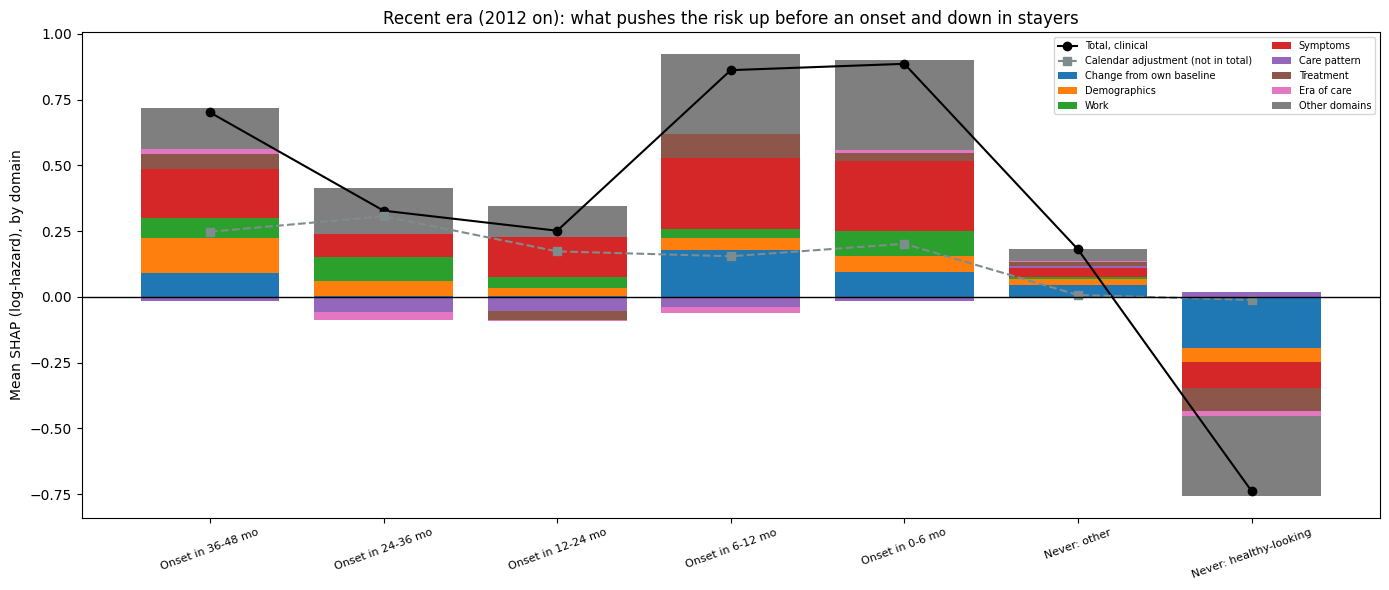

Recent era, rank correlation of the folds' importance vectors: median 0.77 (range 0.69 to 0.82)


In [41]:
"""SHAP in the recent era vs all eras."""
IMP_R = importance(SV_SUM_R)
print(cal_line(SV_SUM_R, f"recent era, {SHAP_RECENT_FROM} on"))
print(cal_line(SV_SUM, "all eras, for comparison"))
CMP = pd.DataFrame({"Input": IMP_R["Input"], "Domain": IMP_R["Domain"],
                    "Recent: rank": np.arange(1, len(IMP_R) + 1),
                    "Recent: share": IMP_R["Share of clinical total"],
                    "Recent: mean SHAP": IMP_R["Mean SHAP"],
                    "All eras: rank": IMP["Mean |SHAP|"].rank(ascending=False).reindex(IMP_R.index).astype(int),
                    "All eras: share": IMP["Share of clinical total"].reindex(IMP_R.index)})
display(CMP.head(25).round(3))
CMP.to_csv(f"objective4_shap_recent_vs_all_{TAG}.csv")
from scipy.stats import spearmanr
_rho_era = spearmanr(IMP_R["Mean |SHAP|"], IMP["Mean |SHAP|"].reindex(IMP_R.index)).correlation
_top10_overlap = len(set(IMP_R.index[:10]) & set(IMP.index[:10]))
print(f"Rank correlation, recent vs all eras (clinical inputs): {_rho_era:.2f}; top-10 overlap {_top10_overlap}/10")

DOMS_R = domain_shares(IMP_R)
_dcmp = pd.DataFrame({"Recent era": DOMS_R, "All eras": DOMS}).sort_values("Recent era", ascending=False)
display(_dcmp.round(3))
fig, ax = plt.subplots(figsize=(10, 6))
_y = np.arange(len(_dcmp))
ax.barh(_y + 0.2, _dcmp["Recent era"].values, 0.4, color="#d62828", label=f"Recent era ({SHAP_RECENT_FROM} on)")
ax.barh(_y - 0.2, _dcmp["All eras"].values, 0.4, color="#adb5bd", label="All eras")
ax.set_yticks(_y); ax.set_yticklabels(_dcmp.index); ax.invert_yaxis(); ax.set_xlabel("Share of clinical |SHAP|")
ax.legend(); ax.grid(axis="x", alpha=0.3); ax.set_title("Domains, recent era vs all eras (calendar adjustment excluded)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_shap_domains_recent.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure()
shap.summary_plot(SV_SUM_R[:, CLIN], SX_R[:, -1, CLIN], feature_names=list(SH_DISPLAY[CLIN]), max_display=20,
                  show=False)
plt.title(f"Recent era ({SHAP_RECENT_FROM} on): SHAP of the 12-month onset log-hazard (clinical inputs)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_shap_beeswarm_recent.png", dpi=150, bbox_inches="tight"); plt.show()

BYGRP_R = shap_by_group(SH_ROWS_R, SV_SUM_R, DOMS_R)
display(BYGRP_R.round(3))
BYGRP_R.to_csv(f"objective4_shap_by_group_recent_{TAG}.csv")
plot_by_group(BYGRP_R, DOMS_R, f"Recent era ({SHAP_RECENT_FROM} on): what pushes the risk up before an onset and down "
              f"in stayers", f"{OUT_DIR}/{TAG}_shap_by_group_recent.png")
STAB_R, _rho_r = stability(SV_SUM_R, SH_FOLD_R, IMP_R)
print(f"Recent era, rank correlation of the folds' importance vectors: median {np.median(_rho_r):.2f} "
      f"(range {_rho_r.min():.2f} to {_rho_r.max():.2f})")

## 16.7 Conclusion — Objective 4

In [42]:
"""Objective 4 conclusion."""
_near_tot = BYGRP.loc["Onset in 0-6 mo", "Total, clinical"]
_near_tot_r = BYGRP_R.loc["Onset in 0-6 mo", "Total, clinical"]
_chg_r = IMP_R.loc[IMP_R["Domain"] == "Change from own baseline", "Share of clinical total"].sum()
txt = ("Calendar year is treated as an adjustment, not a driver: it carries "
       f"{cal_share(SV_SUM):.0%} of all attribution across eras and {cal_share(SV_SUM_R):.0%} within the recent era "
       f"({SHAP_RECENT_FROM} on). Largest clinical inputs, all eras: " + ", ".join(
           f"{r_['Input']} ({r_['Share of clinical total']:.0%})" for _, r_ in IMP.head(8).iterrows())
       + f". Recent era: " + ", ".join(
           f"{r_['Input']} ({r_['Share of clinical total']:.0%})" for _, r_ in IMP_R.head(8).iterrows())
       + f" (rank correlation with all eras {_rho_era:.2f}, top-10 overlap {_top10_overlap}/10). Domains (all eras): "
       + ", ".join(f"{d} {v:.0%}" for d, v in DOMS.head(5).items()) + "; recent era: "
       + ", ".join(f"{d} {v:.0%}" for d, v in DOMS_R.head(5).items())
       + f". Change-from-own-baseline inputs carry {_chg:.0%} of the clinical attribution (recent era {_chg_r:.0%}); "
       f"the landmark grid point {TIME_SHARE.iloc[-1]:.0%}. Mean clinical SHAP: onset in 0-6 months {_near_tot:+.2f} "
       f"(recent era {_near_tot_r:+.2f}), healthy-looking stayers "
       f"{BYGRP.loc['Never: healthy-looking', 'Total, clinical']:+.2f} (recent era "
       f"{BYGRP_R.loc['Never: healthy-looking', 'Total, clinical']:+.2f}). Fold agreement (rank correlation) median "
       f"{np.median(_rho):.2f} (recent era {np.median(_rho_r):.2f}).")
OBJ_CONCLUSIONS["Objective 4"] = txt
print(textwrap.fill(txt, 118))

Calendar year is treated as an adjustment, not a driver: it carries 12% of all attribution across eras and 8% within
the recent era (2012 on). Largest clinical inputs, all eras: SDI damage score (5%), Age (5%), SLEDAI-2K (4%), SDI: now
minus own usual (4%), Antimalarial (HCQ; chloroquine in earlier years) (4%), Education: higher (4%), Prednisone,
average dose since last visit (mg/day) (4%), Fibromyalgia tender points (0-18) (4%). Recent era: Age (6%), SDI damage
score (5%), SDI: now minus own usual (4%), SLEDAI-2K (4%), Education: higher (4%), Prednisone, average dose since last
visit (mg/day) (3%), Fibromyalgia tender points (0-18) (3%), Clinic visits per year, last 12 mo (3%) (rank correlation
with all eras 0.98, top-10 overlap 9/10). Domains (all eras): Change from own baseline 31%, Demographics 10%, Symptoms
10%, Work 8%, Treatment 7%; recent era: Change from own baseline 31%, Demographics 11%, Work 8%, Symptoms 8%, Care
pattern 7%. Change-from-own-baseline inputs carry 31% of the 

---
# 17. Summary of the objectives

Every hypothesis with its estimate, 95 % CI and whether its criterion is met (H = objectives 1-3; S = secondary
analyses, Section 18). No hypothesis
gatekeeps another. Then the three conclusions.

In [43]:
"""Hypothesis table and conclusions."""
HYP = pd.DataFrame(HYP_ROWS)
HYP["Met"] = HYP["Met"].map({True: "yes", False: "no"})
if "Verdict" in HYP:
    HYP["Verdict"] = HYP["Verdict"].fillna("")
display(HYP.set_index("Hypothesis"))
HYP.to_csv(f"hypotheses_{TAG}.csv", index=False)
for k, v in OBJ_CONCLUSIONS.items():
    print(f"\n{k}:\n" + textwrap.fill(v, 118))

,Estimand,Estimate (95% CI),Criterion,Met,Verdict
Hypothesis,,,,,
H1a (primary),"DYN - Baseline, time-matched patient AUROC",0.161 (0.109 to 0.214),lower bound > 0 (equivalence +/-0.02),yes,superior
H1b,"DYN - LogReg, time-matched patient AUROC",0.009 (-0.006 to 0.024),lower bound > 0 (equivalence +/-0.02),no,inconclusive
H1d (post hoc),"DYN - DYN-bands, time-matched patient AUROC",0.016 (0.002 to 0.029),lower bound > 0 (equivalence +/-0.02),yes,superior
H1c,Main: visit calibration slope / intercept,1.056 (0.878 to 1.257) / 0.011 (-0.188 to 0.201),"slope in [0.8, 1.2], intercept CI includes 0",yes,
H2a,Main: time-matched AUROC 0-12 minus 24-36 mont...,0.094 (0.045 to 0.144),lower bound > 0,yes,
H2b,Main: extra rise per year before onset vs neve...,0.092 (0.069 to 0.116),lower bound > 0,yes,
H2c,"Main: median lead time, flagged event patients...",9.0 (8.6 to 9.5),lower bound >= 3,yes,
H3a,"Main: share flagged, healthy-looking minus oth...",-0.308 (-0.335 to -0.280),upper bound < 0,yes,
H3b,"DYN - Baseline, time-matched AUROC vs healthy-...",0.160 (0.110 to 0.218),lower bound > 0,yes,superior



Objective 1:
Main model (Dynamic LSTM: S1 + change from the patient's own baseline, one hazard [MAIN]): time-matched patient AUROC
0.742 (0.702 to 0.783) (Baseline 0.582 (0.531 to 0.633), LogReg 0.734 (0.694 to 0.773)). It flags 62% of patients in
the 12 months before their onset and 31% of the patients still working on the same dates. Visit AUROC (12 months)
0.737 (0.696 to 0.778); calibration slope 1.06, O/E 1.04. Hypotheses: H1a (primary) (DYN - Baseline, time-matched
patient AUROC) 0.161 (0.109 to 0.214): superior; H1b (DYN - LogReg, time-matched patient AUROC) 0.009 (-0.006 to
0.024): inconclusive; H1d (post hoc) (DYN - DYN-bands, time-matched patient AUROC) 0.016 (0.002 to 0.029): superior;
H1c (Main: visit calibration slope / intercept) 1.056 (0.878 to 1.257) / 0.011 (-0.188 to 0.201): met. Risk tiers
(DYN): the < 1 % tier covers 42% of visits with an observed 12-month risk of 0.005 (0.003 to 0.008) and misses 0.122
(0.077 to 0.169) of the onsets; the >= 5 % tier covers 5% of v

---
# 18. Secondary analyses

Visit-level discrimination at every horizon; the design steps from update_v8's model to the main model; the
evaluation rules compared; stability across calendar time; restricted risk sets. Hypotheses here are labelled S
and are secondary.

## 18.1 Every horizon from 6 to 48 months: visit and patient level

One fit gives the risk at every horizon (Section 11.6): each horizon has its own censoring-weighted label, its own
recalibration and its own thresholds inside the training folds. Patient level: windows of min(24, *h*) months
(Section 9.2). Left: AUROC by horizon, every model (main bold, 95 % band); right: the patient level.

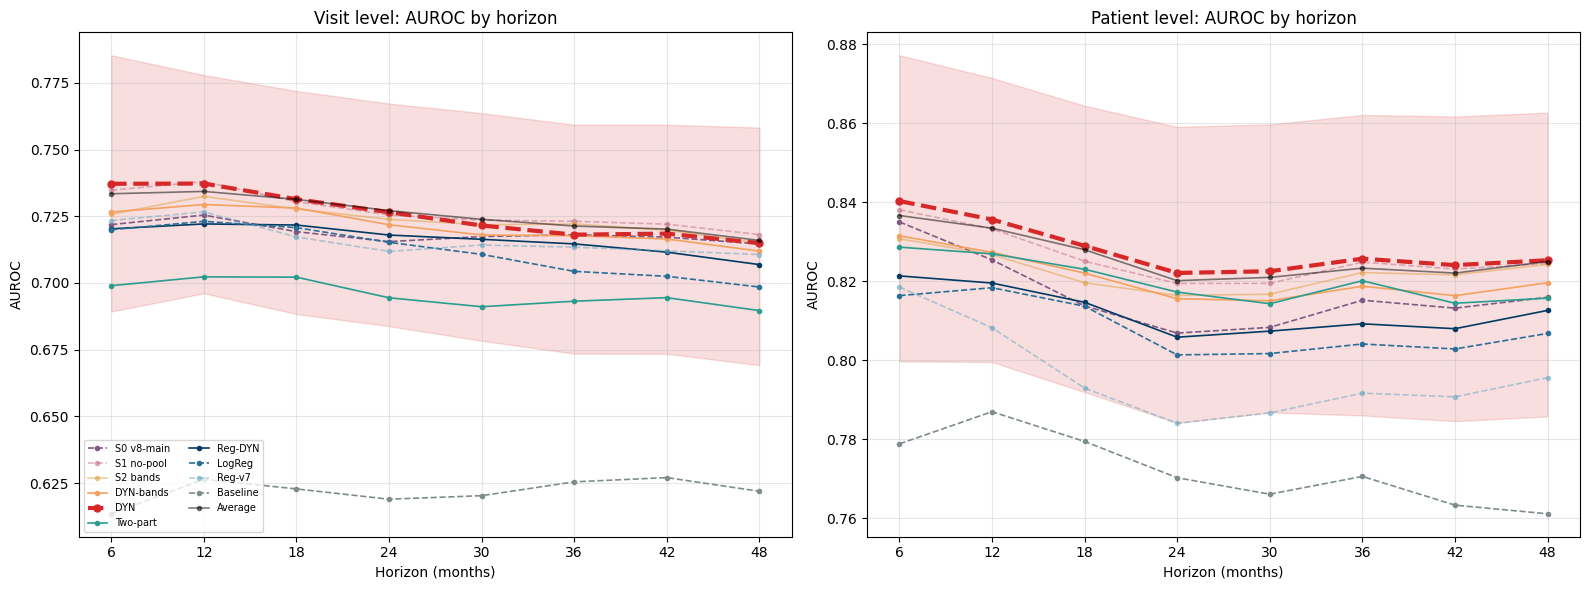

Dynamic LSTM: S1 + change from the patient's own baseline, one hazard [MAIN]


,Landmarks (known status),Observed cumulative risk (IPCW),Patients / with onset,Visit AUROC,Patient AUROC,Visit calibration slope,Visit O/E,Visit sens / spec,Patient sens / spec,Patient PPV
Horizon (months),,,,,,,,,,
6,16836,0.008,986 / 110,0.737 (0.689 to 0.785),0.840 (0.800 to 0.877),1.05,1.04 (0.84 to 1.25),0.64 / 0.70,0.76 / 0.77,0.29
12,16180,0.018,970 / 131,0.737 (0.696 to 0.778),0.836 (0.800 to 0.871),1.06,1.04 (0.85 to 1.23),0.68 / 0.67,0.74 / 0.77,0.33
18,15619,0.027,943 / 136,0.731 (0.688 to 0.772),0.829 (0.792 to 0.864),1.05,1.03 (0.86 to 1.23),0.65 / 0.69,0.73 / 0.76,0.34
24,15179,0.035,904 / 136,0.727 (0.684 to 0.767),0.822 (0.784 to 0.859),1.05,1.03 (0.86 to 1.23),0.65 / 0.69,0.71 / 0.78,0.37
30,14796,0.042,877 / 135,0.722 (0.678 to 0.764),0.823 (0.787 to 0.860),1.04,1.03 (0.85 to 1.22),0.63 / 0.69,0.71 / 0.78,0.37
36,14471,0.048,854 / 132,0.718 (0.674 to 0.759),0.826 (0.786 to 0.862),1.04,1.02 (0.84 to 1.21),0.65 / 0.67,0.71 / 0.78,0.38
42,14122,0.054,830 / 131,0.718 (0.673 to 0.759),0.824 (0.785 to 0.862),1.04,1.01 (0.83 to 1.20),0.64 / 0.67,0.72 / 0.78,0.38
48,13609,0.061,801 / 130,0.715 (0.669 to 0.758),0.825 (0.786 to 0.863),1.05,1.00 (0.82 to 1.19),0.64 / 0.68,0.72 / 0.79,0.39


,Model,Level,6 mo,12 mo,18 mo,24 mo,30 mo,36 mo,42 mo,48 mo
0,S0 v8-main,visit,0.722 (0.672 to 0.773),0.725 (0.683 to 0.770),0.719 (0.674 to 0.764),0.716 (0.667 to 0.761),0.717 (0.665 to 0.763),0.718 (0.668 to 0.765),0.717 (0.667 to 0.763),0.715 (0.663 to 0.762)
1,S1 no-pool,visit,0.735 (0.687 to 0.781),0.738 (0.695 to 0.780),0.730 (0.687 to 0.773),0.725 (0.680 to 0.770),0.724 (0.676 to 0.767),0.723 (0.674 to 0.767),0.722 (0.672 to 0.767),0.718 (0.667 to 0.765)
2,S2 bands,visit,0.726 (0.678 to 0.775),0.732 (0.690 to 0.777),0.728 (0.683 to 0.771),0.724 (0.679 to 0.769),0.722 (0.673 to 0.768),0.722 (0.673 to 0.769),0.720 (0.670 to 0.767),0.715 (0.664 to 0.764)
3,DYN-bands,visit,0.727 (0.679 to 0.775),0.729 (0.687 to 0.774),0.728 (0.685 to 0.772),0.722 (0.678 to 0.766),0.718 (0.671 to 0.764),0.718 (0.671 to 0.766),0.716 (0.668 to 0.764),0.712 (0.663 to 0.761)
4,DYN,visit,0.737 (0.689 to 0.785),0.737 (0.696 to 0.778),0.731 (0.688 to 0.772),0.727 (0.684 to 0.767),0.722 (0.678 to 0.764),0.718 (0.674 to 0.759),0.718 (0.673 to 0.759),0.715 (0.669 to 0.758)
5,Two-part,visit,0.699 (0.652 to 0.747),0.702 (0.657 to 0.748),0.702 (0.658 to 0.747),0.694 (0.650 to 0.742),0.691 (0.645 to 0.738),0.693 (0.647 to 0.742),0.694 (0.646 to 0.744),0.690 (0.640 to 0.741)
6,Reg-DYN,visit,0.720 (0.671 to 0.771),0.722 (0.680 to 0.768),0.722 (0.679 to 0.765),0.718 (0.675 to 0.761),0.716 (0.673 to 0.760),0.715 (0.670 to 0.759),0.712 (0.665 to 0.756),0.707 (0.658 to 0.753)
7,LogReg,visit,0.720 (0.670 to 0.771),0.723 (0.682 to 0.765),0.721 (0.680 to 0.762),0.715 (0.673 to 0.754),0.711 (0.669 to 0.751),0.704 (0.662 to 0.746),0.702 (0.659 to 0.744),0.698 (0.653 to 0.744)
8,Reg-v7,visit,0.723 (0.673 to 0.774),0.727 (0.684 to 0.770),0.717 (0.671 to 0.760),0.712 (0.665 to 0.757),0.714 (0.664 to 0.760),0.713 (0.663 to 0.760),0.712 (0.663 to 0.759),0.711 (0.660 to 0.759)
9,Baseline,visit,0.613 (0.565 to 0.664),0.626 (0.580 to 0.676),0.623 (0.574 to 0.675),0.619 (0.566 to 0.672),0.620 (0.567 to 0.673),0.625 (0.571 to 0.679),0.627 (0.573 to 0.680),0.622 (0.567 to 0.677)


In [44]:
"""AUROC by horizon, every model; the main model's metrics by horizon."""
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, lev in zip(axes, ["visit", "patient"]):
    for m in MODELS_RUN:
        v = np.array([ci((m, lev, h, "auroc")) for h in HORIZONS])
        main = m == MAIN_MODEL
        ax.plot(HORIZONS, v[:, 0], "o-", color=model_color(m), ls=model_ls(m), lw=3 if main else 1.2,
                ms=5 if main else 3, label=short_label(m), alpha=1 if m in FIG_MODELS else 0.5)
        if main:
            ax.fill_between(HORIZONS, v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    ax.set_xticks(HORIZONS); ax.set_xlabel("Horizon (months)"); ax.set_ylabel("AUROC"); ax.grid(alpha=0.3)
    ax.set_title(f"{lev.capitalize()} level: AUROC by horizon")
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_horizons_auroc.png", dpi=150, bbox_inches="tight"); plt.show()

rows = []
for h in HORIZONS:
    rows.append({"Horizon (months)": h, "Landmarks (known status)": len(IPCW_H[h][0]),
                 "Observed cumulative risk (IPCW)": round(CIF_IPCW[h], 3),
                 "Patients / with onset": f"{len(PTW[h]['pids'])} / {int(PTW[h]['event'].sum())}",
                 "Visit AUROC": fmtk((MAIN_MODEL, "visit", h, "auroc")),
                 "Patient AUROC": fmtk((MAIN_MODEL, "patient", h, "auroc")),
                 "Visit calibration slope": f"{ci((MAIN_MODEL, 'visit', h, 'cal_slope'))[0]:.2f}",
                 "Visit O/E": fmtk((MAIN_MODEL, "visit", h, "oe"), 2),
                 "Visit sens / spec": f"{ci((MAIN_MODEL, 'visit', h, MAIN_THRESHOLD, 'sensitivity'))[0]:.2f} / "
                                      f"{ci((MAIN_MODEL, 'visit', h, MAIN_THRESHOLD, 'specificity'))[0]:.2f}",
                 "Patient sens / spec": f"{ci((MAIN_MODEL, 'patient', h, MAIN_THRESHOLD, 'sensitivity'))[0]:.2f} / "
                                        f"{ci((MAIN_MODEL, 'patient', h, MAIN_THRESHOLD, 'specificity'))[0]:.2f}",
                 "Patient PPV": f"{ci((MAIN_MODEL, 'patient', h, MAIN_THRESHOLD, 'ppv'))[0]:.2f}"})
HORIZON_MAIN = pd.DataFrame(rows).set_index("Horizon (months)")
print(model_label(MAIN_MODEL))
display(HORIZON_MAIN)
HORIZON_MAIN.to_csv(f"objective2_horizons_main_{TAG}.csv")
HORIZON_ALL = pd.DataFrame([{"Model": short_label(m), "Level": lev,
                             **{f"{h} mo": fmtk((m, lev, h, "auroc")) for h in HORIZONS}}
                            for lev in ["visit", "patient"] for m in MODELS_RUN])
display(HORIZON_ALL)
HORIZON_ALL.to_csv(f"objective2_horizons_all_{TAG}.csv", index=False)

## 18.2 The comparators minus the main model, by horizon

Paired differences in AUROC at every horizon (95 % CI): where does the dynamic model gain or lose against each
alternative: at short or at long horizons?

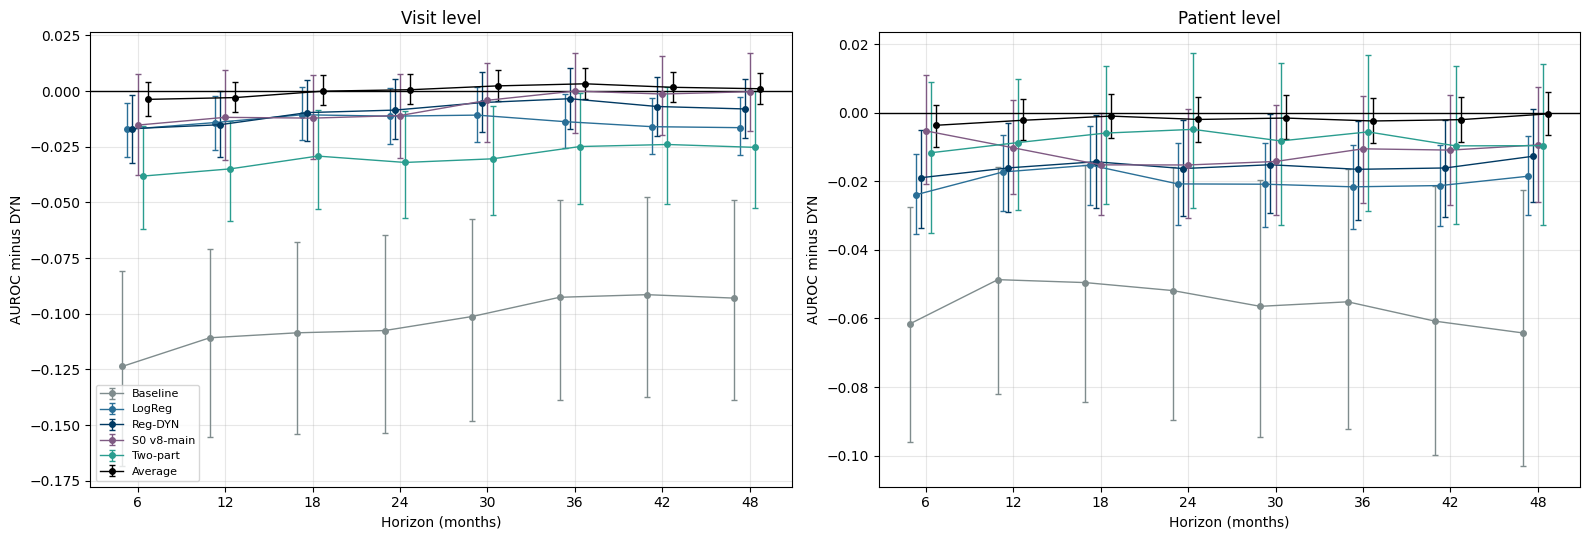

Horizon                                    6                          12                         18                         24                         30                         36  \
Level   Model                                                                                                                                                                          
patient Average      -0.004 (-0.010 to 0.002)   -0.002 (-0.008 to 0.004)   -0.001 (-0.007 to 0.005)   -0.002 (-0.008 to 0.005)   -0.002 (-0.008 to 0.005)   -0.002 (-0.009 to 0.004)   
        Baseline    -0.061 (-0.096 to -0.027)  -0.049 (-0.082 to -0.016)  -0.050 (-0.084 to -0.015)  -0.052 (-0.090 to -0.016)  -0.056 (-0.095 to -0.019)  -0.055 (-0.092 to -0.016)   
        LogReg      -0.024 (-0.035 to -0.012)  -0.017 (-0.029 to -0.006)  -0.015 (-0.027 to -0.004)  -0.021 (-0.033 to -0.009)  -0.021 (-0.033 to -0.009)  -0.022 (-0.034 to -0.010)   
        Reg-DYN     -0.019 (-0.033 to -0.005)  -0.016 (-0.029 to -0.003)  -0.014 (-0.028 to -0.001)  -0.016 (-0.030 to -0.002)  -0.015 (-0.029 to -0.000)  -0.016 (-0.031 to -0.002)   
        S0 v8-main   -0.005 (-0.021 to 0.011)   -0.010 (-0.024 to 0.004)  -0.015 (-0.030 to -0.000)   -0.015 (-0.031 to 0.001)   -0.014 (-0.030 to 0.002)   -0.011 (-0.026 to 0.005)   
        Two-part     -0.012 (-0.035 to 0.009)   -0.009 (-0.028 to 0.010)   -0.006 (-0.027 to 0.014)   -0.005 (-0.028 to 0.017)   -0.008 (-0.033 to 0.014)   -0.006 (-0.029 to 0.017)   
visit   Average      -0.004 (-0.011 to 0.004)   -0.003 (-0.010 to 0.004)   -0.000 (-0.006 to 0.007)    0.001 (-0.006 to 0.008)    0.002 (-0.004 to 0.010)    0.003 (-0.003 to 0.010)   
        Baseline    -0.124 (-0.168 to -0.081)  -0.111 (-0.156 to -0.071)  -0.109 (-0.154 to -0.068)  -0.108 (-0.154 to -0.065)  -0.101 (-0.148 to -0.057)  -0.093 (-0.139 to -0.049)   
        LogReg      -0.017 (-0.030 to -0.005)  -0.014 (-0.026 to -0.002)   -0.011 (-0.022 to 0.002)   -0.011 (-0.024 to 0.001)   -0.011 (-0.023 to 0.002)  -0.014 (-0.026 to -0.001)   
        Reg-DYN     -0.017 (-0.032 to -0.002)  -0.015 (-0.029 to -0.000)   -0.010 (-0.023 to 0.005)   -0.009 (-0.022 to 0.005)   -0.005 (-0.019 to 0.009)   -0.003 (-0.017 to 0.010)   
        S0 v8-main   -0.015 (-0.038 to 0.008)   -0.012 (-0.031 to 0.009)   -0.012 (-0.031 to 0.007)   -0.011 (-0.030 to 0.008)   -0.004 (-0.023 to 0.013)   -0.000 (-0.019 to 0.017)   
        Two-part    -0.038 (-0.062 to -0.016)  -0.035 (-0.058 to -0.013)  -0.029 (-0.053 to -0.008)  -0.032 (-0.057 to -0.009)  -0.030 (-0.056 to -0.007)  -0.025 (-0.051 to -0.001)   

Horizon                                    42                         48  
Level   Model                                                             
patient Average      -0.002 (-0.009 to 0.005)   -0.000 (-0.007 to 0.006)  
        Baseline    -0.061 (-0.100 to -0.021)  -0.064 (-0.103 to -0.022)  
        LogReg      -0.021 (-0.033 to -0.009)  -0.019 (-0.030 to -0.007)  
        Reg-DYN     -0.016 (-0.030 to -0.002)   -0.013 (-0.026 to 0.001)  
        S0 v8-main   -0.011 (-0.027 to 0.005)   -0.009 (-0.026 to 0.008)  
        Two-part     -0.010 (-0.032 to 0.013)   -0.010 (-0.033 to 0.014)  
visit   Average       0.002 (-0.005 to 0.009)    0.001 (-0.006 to 0.008)  
        Baseline    -0.091 (-0.138 to -0.048)  -0.093 (-0.139 to -0.049)  
        LogReg      -0.016 (-0.028 to -0.003)  -0.016 (-0.029 to -0.003)  
        Reg-DYN      -0.007 (-0.020 to 0.006)   -0.008 (-0.021 to 0.005)  
        S0 v8-main   -0.001 (-0.020 to 0.016)   -0.000 (-0.018 to 0.017)  
        Two-part     -0.024 (-0.051 to 0.002)   -0.025 (-0.052 to 0.000)

In [45]:
"""Differences from the main model by horizon."""
_cmp = [m for m in [BASELINE, LOGREG, REG_DYN, V8_MAIN, TWO_PART, AVG_MODEL] if m in MODELS_RUN]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
rows = []
for ax, lev in zip(axes, ["visit", "patient"]):
    for j, m in enumerate(_cmp):
        d = np.array([diff(m, MAIN_MODEL, (lev, h, "auroc"))[:3] for h in HORIZONS])
        xs = np.array(HORIZONS) + (j - len(_cmp) / 2) * 0.35
        ax.errorbar(xs, d[:, 0], yerr=[d[:, 0] - d[:, 1], d[:, 2] - d[:, 0]], fmt="o-", ms=4, capsize=2,
                    color=model_color(m), label=short_label(m), lw=1)
        rows += [{"Level": lev, "Model": short_label(m), "Horizon": h, "Difference (95% CI)": fmt(*d_)}
                 for h, d_ in zip(HORIZONS, d)]
    ax.axhline(0, color="k", lw=1); ax.set_xticks(HORIZONS); ax.set_xlabel("Horizon (months)")
    ax.set_ylabel(f"AUROC minus {short_label(MAIN_MODEL)}"); ax.set_title(f"{lev.capitalize()} level"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_horizons_vs_main.png", dpi=150, bbox_inches="tight"); plt.show()
HOR_DIFF = pd.DataFrame(rows)
display(HOR_DIFF.pivot_table(index=["Level", "Model"], columns="Horizon", values="Difference (95% CI)", aggfunc="first"))
HOR_DIFF.to_csv(f"objective2_horizons_vs_main_{TAG}.csv", index=False)

## 18.3 Exclusive 12-month intervals (S3): is accuracy higher close to the visit than further ahead?

AUROC for an onset in months 0-12, 12-24, 24-36 and 36-48 **among the landmarks still at risk at the start of the
interval**, each with its own censoring-weighted label and recalibration. Unlike the cumulative horizons, the
intervals do not share onsets, so they show how accuracy changes with the time ahead. **S3**: the main model's
AUROC in months 0-12 minus months 36-48, lower 95 % bound > 0. Also the slope per year over the four intervals.

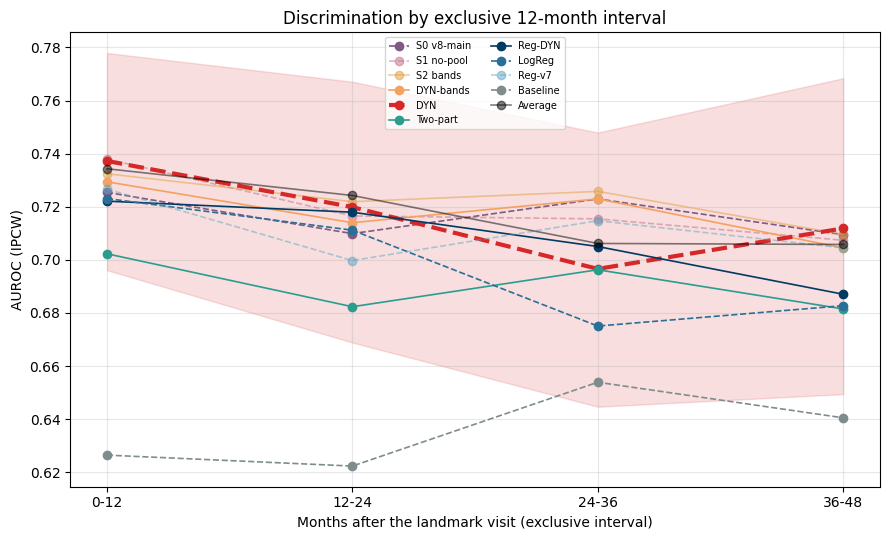

Landmarks at risk with a known status / onsets: 0-12 mo 16,180 / 301, 12-24 mo 14,502 / 263, 24-36 mo 13,218 / 193, 36-48 mo 11,885 / 182


,0-12 mo,12-24 mo,24-36 mo,36-48 mo,0-12 minus 36-48,Slope per year
Model,,,,,,
S0 v8-main,0.725 (0.683 to 0.770),0.710 (0.656 to 0.760),0.723 (0.665 to 0.777),0.709 (0.644 to 0.769),0.016 (-0.034 to 0.068),-0.0035 (-0.0207 to 0.0136)
S1 no-pool,0.738 (0.695 to 0.780),0.717 (0.664 to 0.766),0.715 (0.658 to 0.769),0.707 (0.641 to 0.766),0.031 (-0.019 to 0.081),-0.0093 (-0.0259 to 0.0076)
S2 bands,0.732 (0.690 to 0.777),0.722 (0.670 to 0.770),0.726 (0.670 to 0.783),0.710 (0.649 to 0.768),0.023 (-0.024 to 0.074),-0.0065 (-0.0233 to 0.0104)
DYN-bands,0.729 (0.687 to 0.774),0.714 (0.662 to 0.764),0.723 (0.667 to 0.777),0.704 (0.643 to 0.761),0.025 (-0.024 to 0.077),-0.0066 (-0.0239 to 0.0105)
DYN,0.737 (0.696 to 0.778),0.720 (0.669 to 0.767),0.697 (0.645 to 0.748),0.712 (0.649 to 0.768),0.025 (-0.020 to 0.071),-0.0099 (-0.0262 to 0.0060)
Two-part,0.702 (0.657 to 0.748),0.682 (0.630 to 0.733),0.696 (0.639 to 0.751),0.682 (0.614 to 0.743),0.021 (-0.032 to 0.078),-0.0048 (-0.0251 to 0.0134)
Reg-DYN,0.722 (0.680 to 0.768),0.718 (0.671 to 0.766),0.705 (0.649 to 0.760),0.687 (0.620 to 0.751),0.035 (-0.019 to 0.092),-0.0118 (-0.0302 to 0.0065)
LogReg,0.723 (0.682 to 0.765),0.711 (0.664 to 0.757),0.675 (0.618 to 0.730),0.683 (0.619 to 0.748),0.040 (-0.013 to 0.094),-0.0157 (-0.0338 to 0.0028)
Reg-v7,0.727 (0.684 to 0.770),0.700 (0.644 to 0.751),0.715 (0.658 to 0.771),0.705 (0.640 to 0.764),0.022 (-0.031 to 0.078),-0.0051 (-0.0238 to 0.0128)


In [46]:
"""Exclusive intervals; H2c."""
_x = np.array([(a + b) / 24 for a, b in INTERVALS])
rows = []
fig, ax = plt.subplots(figsize=(9, 5.5))
for m in MODELS_RUN:
    v = np.array([ci((m, "interval", iv, "auroc")) for iv in INTERVALS])
    main = m == MAIN_MODEL
    ax.plot(range(len(INTERVALS)), v[:, 0], "o-", color=model_color(m), ls=model_ls(m), lw=3 if main else 1.2,
            label=short_label(m), alpha=1 if m in FIG_MODELS else 0.5)
    if main:
        ax.fill_between(range(len(INTERVALS)), v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    p0, b0 = STATS[(m, "interval", INTERVALS[0], "auroc")]
    p3, b3 = STATS[(m, "interval", INTERVALS[-1], "auroc")]
    dd = _diff_summary(p0 - p3, b0 - b3)
    xc = _x - _x.mean()
    pts = np.array([STATS[(m, "interval", iv, "auroc")][0] for iv in INTERVALS])
    bts = np.vstack([STATS[(m, "interval", iv, "auroc")][1] for iv in INTERVALS])
    sl = _diff_summary(float(xc @ pts / (xc @ xc)), xc @ bts / (xc @ xc))
    rows.append({"Model": short_label(m), **{f"{a}-{b} mo": fmt(*v_) for (a, b), v_ in zip(INTERVALS, v)},
                 "0-12 minus 36-48": fmt(*dd[:3]), "Slope per year": fmt(*sl[:3], nd=4)})
    if main:
        HYP_ROWS.append({"Hypothesis": "S3", "Estimand": "Main: AUROC months 0-12 minus 36-48",
                         "Estimate (95% CI)": fmt(*dd[:3]), "Criterion": "lower bound > 0", "Met": dd[1] > 0})
ax.set_xticks(range(len(INTERVALS))); ax.set_xticklabels([f"{a}-{b}" for a, b in INTERVALS])
ax.set_xlabel("Months after the landmark visit (exclusive interval)"); ax.set_ylabel("AUROC (IPCW)")
ax.set_title("Discrimination by exclusive 12-month interval"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_intervals.png", dpi=150, bbox_inches="tight"); plt.show()
INTERVAL_TABLE = pd.DataFrame(rows).set_index("Model")
print("Landmarks at risk with a known status / onsets: " + ", ".join(
    f"{a}-{b} mo {len(IPCW_INT[(a, b)][0]):,} / {int(IPCW_INT[(a, b)][1].sum())}" for a, b in INTERVALS))
display(INTERVAL_TABLE)
INTERVAL_TABLE.to_csv(f"objective2_h2c_intervals_{TAG}.csv")

## 18.4 Cumulative horizons: every metric at 6 minus 48 months (main model, descriptive)

The cumulative horizons share onsets (every onset by 6 months is also an onset by 48 months), so this contrast is
descriptive; S3 (Section 18.3) is the test.

In [47]:
"""6 minus 48 months, main model."""
rows = []
for lev in ["visit", "patient"]:
    for lab_, key in [("AUROC", ("auroc",)), ("Sensitivity", (MAIN_THRESHOLD, "sensitivity")),
                      ("Specificity", (MAIN_THRESHOLD, "specificity")), ("PPV", (MAIN_THRESHOLD, "ppv")),
                      ("Balanced accuracy", (MAIN_THRESHOLD, "balanced_accuracy"))]:
        k6, k48 = (MAIN_MODEL, lev, HORIZONS[0]) + key, (MAIN_MODEL, lev, HORIZONS[-1]) + key
        d = _diff_summary(STATS[k6][0] - STATS[k48][0], STATS[k6][1] - STATS[k48][1])
        rows.append({"Level": lev, "Metric": lab_, f"{HORIZONS[0]} months": fmtk(k6), f"{HORIZONS[-1]} months": fmtk(k48),
                     "Difference (95% CI)": fmt(*d[:3])})
CUM = pd.DataFrame(rows)
display(CUM)
CUM.to_csv(f"objective2_cumulative_6_48_{TAG}.csv", index=False)

,Level,Metric,6 months,48 months,Difference (95% CI)
0,visit,AUROC,0.737 (0.689 to 0.785),0.715 (0.669 to 0.758),0.022 (-0.012 to 0.062)
1,visit,Sensitivity,0.638 (0.553 to 0.720),0.636 (0.568 to 0.705),0.002 (-0.062 to 0.067)
2,visit,Specificity,0.704 (0.681 to 0.728),0.677 (0.650 to 0.704),0.028 (0.018 to 0.037)
3,visit,PPV,0.017 (0.014 to 0.022),0.114 (0.091 to 0.138),-0.096 (-0.118 to -0.076)
4,visit,Balanced accuracy,0.671 (0.630 to 0.712),0.656 (0.620 to 0.693),0.015 (-0.018 to 0.048)
5,patient,AUROC,0.840 (0.800 to 0.877),0.825 (0.786 to 0.863),0.015 (-0.010 to 0.038)
6,patient,Sensitivity,0.756 (0.685 to 0.825),0.715 (0.649 to 0.788),0.041 (-0.014 to 0.096)
7,patient,Specificity,0.769 (0.743 to 0.794),0.787 (0.759 to 0.814),-0.018 (-0.042 to 0.005)
8,patient,PPV,0.292 (0.240 to 0.343),0.395 (0.334 to 0.453),-0.103 (-0.142 to -0.068)
9,patient,Balanced accuracy,0.763 (0.726 to 0.799),0.751 (0.714 to 0.789),0.012 (-0.018 to 0.040)


## 18.5 The design steps: the dynamic LSTM against update_v8's main model (S1)

**S1**: the dynamic LSTM (no pooling, a hazard per 6-month band, change from the patient's own baseline)
discriminates the **12-month** risk at the visit level better than update_v8's main model (24-month pool, one
hazard, current status only). Estimand: DYN − S0, visit AUROC at 12 months (IPCW, every landmark with a known
12-month status). Verdict: **superior** if the lower 95 % bound > 0; **inferior** if the upper bound < 0;
**equivalent** if the CI lies within ±0.02; otherwise **inconclusive**. Secondary: the same contrast on the 6- and
30-month visit AUROC, the risk-set C and the patient-window AUROC. The difference in each CV repeat is shown.

In [48]:
"""Primary test."""


def repeat_diffs(a, b, key=K_VIS):
    """Point estimate of a - b in each CV repeat (visit AUROC at a horizon, or patient AUROC)."""
    out = []
    for r in REPEATS:
        if key[0] == "visit" and key[-1] == "auroc":
            rows, y, w = IPCW_H[key[1]]
            f_ = lambda m: wauc(y, zpred(m, r, key[1])[rows], (_BOTH[:1, ROW_PIDX[rows]] * w[None, :]))[0]
        elif key == K_PT:
            f_ = lambda m: wauc(PTW[H]["event"], patient_z(m, r), _BOTH[:1, PTW_PIDX[H]])[0]
        else:
            return []
        out.append(f_(a) - f_(b))
    return out


PRIM_KEYS = [("Visit AUROC, 12 months (primary)", K_VIS), ("Visit AUROC, 6 months", ("visit", 6, "auroc")),
             ("Visit AUROC, 30 months", ("visit", 30, "auroc")), ("Risk-set C", K_RS),
             ("Patient AUROC (windows)", K_PT)]
PRIMARY_S = []
for lab_, key in PRIM_KEYS:
    d = diff(MAIN_MODEL, V8_MAIN, key)
    rd = repeat_diffs(MAIN_MODEL, V8_MAIN, key)
    PRIMARY_S.append({"Metric": lab_, short_label(MAIN_MODEL): fmtk((MAIN_MODEL,) + key),
                    short_label(V8_MAIN): fmtk((V8_MAIN,) + key), "Difference (95% CI)": fmt(*d[:3]),
                    "p (bootstrap)": round(d[3], 3), "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN),
                    "Per repeat": ", ".join(f"{x:+.3f}" for x in rd) if rd else "-"})
PRIMARY_S = pd.DataFrame(PRIMARY_S).set_index("Metric")
display(PRIMARY_S)
PRIMARY_S.to_csv(f"secondary_design_steps_{TAG}.csv")
_d = diff(MAIN_MODEL, V8_MAIN, K_VIS)
HYP_ROWS.append({"Hypothesis": "S1", "Estimand": "Dynamic LSTM - v8 main, visit AUROC 12 months",
                    "Estimate (95% CI)": fmt(*_d[:3]), "Criterion": "lower bound > 0 (equivalence +/-0.02)",
                    "Met": _d[1] > 0, "Verdict": verdict_superiority(_d[1], _d[2], EQUIV_MARGIN)})

,DYN,S0 v8-main,Difference (95% CI),p (bootstrap),Verdict,Per repeat
Metric,,,,,,
"Visit AUROC, 12 months (primary)",0.737 (0.696 to 0.778),0.725 (0.683 to 0.770),0.012 (-0.009 to 0.031),0.270,inconclusive,"+0.014, +0.015, +0.006, +0.002, +0.021"
"Visit AUROC, 6 months",0.737 (0.689 to 0.785),0.722 (0.672 to 0.773),0.015 (-0.008 to 0.038),0.194,inconclusive,"+0.010, +0.020, +0.012, +0.004, +0.030"
"Visit AUROC, 30 months",0.722 (0.678 to 0.764),0.717 (0.665 to 0.763),0.004 (-0.013 to 0.023),0.696,inconclusive,"+0.005, +0.007, -0.001, -0.003, +0.014"
Risk-set C,0.748 (0.707 to 0.787),0.726 (0.686 to 0.768),0.021 (-0.005 to 0.047),0.104,inconclusive,-
Patient AUROC (windows),0.836 (0.800 to 0.871),0.825 (0.789 to 0.863),0.010 (-0.004 to 0.024),0.154,inconclusive,"+0.007, +0.015, +0.006, +0.005, +0.018"


## 18.6 One change at a time (S2), and the alternatives

| Pair | What it isolates |
|---|---|
| S1 − S0 | removing the 24-month pool (each visit's own score; and 2 years of grid instead of all, which update_v8 showed does not matter) |
| DYN − S1 | the change-from-own-baseline inputs (one hazard; the new main model) |
| S2 − S1 | a hazard per 6-month band (near-term risk can differ from long-term) |
| DYN-bands − S2 | the change-from-own-baseline inputs (band hazards; update_v10's main model) |
| DYN-bands − DYN | the bands, with the change inputs |
| Two-part − DYN | separating the trait (fixed Baseline offset) from the change (LSTM on change only) |
| DYN − Reg-DYN | the network, on the same inputs and target |
| Reg-DYN − Reg-v7 | the dynamic design in a regression (vs update_v7's regression) |
| Average − DYN | combining the LSTM and the regression |

Criterion: lower 95 % bound > 0 per metric; equivalence (±0.02) reported. Secondary to the primary test.

Metric,Visit AUROC 12 mo,Visit AUROC 6 mo,Risk-set C,Patient AUROC,Visit AUROC 30 mo
Comparison,,,,,
S1 no-pool - S0 v8-main,0.013 (-0.002 to 0.027),0.013 (-0.005 to 0.030),0.015 (-0.002 to 0.032),0.008 (-0.002 to 0.017),0.006 (-0.005 to 0.018)
DYN - S1 no-pool,-0.001 (-0.012 to 0.012),0.002 (-0.010 to 0.014),0.006 (-0.012 to 0.023),0.002 (-0.007 to 0.012),-0.002 (-0.014 to 0.010)
S2 bands - S1 no-pool,-0.006 (-0.015 to 0.004),-0.009 (-0.020 to 0.002),-0.013 (-0.023 to -0.003),-0.007 (-0.015 to 0.002),-0.002 (-0.017 to 0.013)
DYN-bands - S2 bands,-0.003 (-0.017 to 0.010),0.001 (-0.011 to 0.012),0.004 (-0.012 to 0.018),0.001 (-0.008 to 0.009),-0.004 (-0.014 to 0.007)
DYN-bands - DYN,-0.008 (-0.020 to 0.004),-0.011 (-0.022 to 0.001),-0.015 (-0.028 to -0.001),-0.008 (-0.019 to 0.002),-0.004 (-0.019 to 0.013)
Two-part - DYN,-0.035 (-0.058 to -0.013),-0.038 (-0.062 to -0.016),-0.049 (-0.076 to -0.022),-0.009 (-0.028 to 0.010),-0.030 (-0.056 to -0.007)
DYN - Reg-DYN,0.015 (0.000 to 0.029),0.017 (0.002 to 0.032),0.018 (0.000 to 0.037),0.016 (0.003 to 0.029),0.005 (-0.009 to 0.019)
Reg-DYN - Reg-v7,-0.005 (-0.033 to 0.021),-0.003 (-0.033 to 0.026),-0.005 (-0.034 to 0.022),0.011 (-0.009 to 0.030),0.002 (-0.019 to 0.023)
Average - DYN,-0.003 (-0.010 to 0.004),-0.004 (-0.011 to 0.004),-0.003 (-0.011 to 0.006),-0.002 (-0.008 to 0.004),0.002 (-0.004 to 0.010)


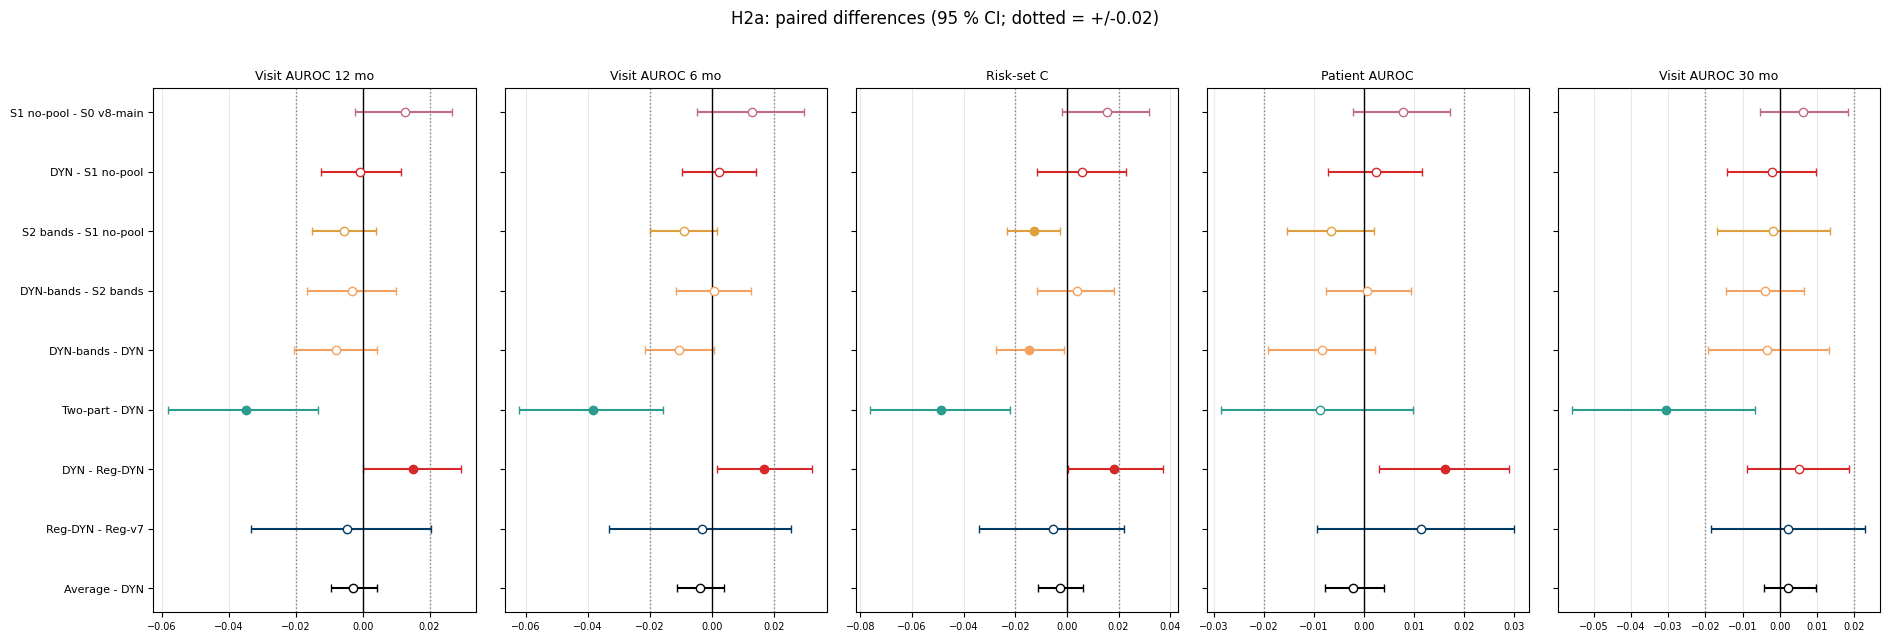

In [49]:
"""H2a pairs."""
H2A_PAIRS = [("S1_P0", V8_MAIN), (MAIN_MODEL, "S1_P0"), ("S2_BAND", "S1_P0"), (DYN_BANDS, "S2_BAND"),
             (DYN_BANDS, MAIN_MODEL), (TWO_PART, MAIN_MODEL),
             (MAIN_MODEL, REG_DYN), (REG_DYN, REG_MODEL), (AVG_MODEL, MAIN_MODEL)]
CMP_KEYS = [("Visit AUROC 12 mo", K_VIS), ("Visit AUROC 6 mo", ("visit", 6, "auroc")), ("Risk-set C", K_RS),
            ("Patient AUROC", K_PT), ("Visit AUROC 30 mo", ("visit", 30, "auroc"))]
H2A = compare(H2A_PAIRS, keys=CMP_KEYS)
H2A["Equivalent (+/-0.02)"] = (H2A["Lower"] > -EQUIV_MARGIN) & (H2A["Upper"] < EQUIV_MARGIN)
show_cmp(H2A)
H2A.to_csv(f"objective2_h2a_{TAG}.csv", index=False)
_col = {f"{short_label(a)} - {short_label(b)}": model_color(a) for a, b in H2A_PAIRS}
forest(H2A, "Comparison", [k for k, _ in CMP_KEYS], "H2a: paired differences (95 % CI; dotted = +/-0.02)", "h2a",
       color_of=_col.get, margin=EQUIV_MARGIN)
for a, b in H2A_PAIRS:
    d = diff(a, b, K_VIS)
    HYP_ROWS.append({"Hypothesis": "S2", "Estimand": f"{short_label(a)} - {short_label(b)}, visit AUROC 12 months",
                     "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0", "Met": d[1] > 0,
                     "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})

## 18.7 The evaluation rules side by side

Every model under each way of scoring it:

| Rule | Question it answers | Comparison made on |
|---|---|---|
| **E0: patient windows** (update_v7/v8) | do the patients who go on to an onset score higher? | 24 months before onset vs the last 24 months of event-free follow-up (different calendar times) |
| **E1: risk-set C** (incident case / dynamic control) | on the date of each onset, does that patient score higher than everyone else at risk that day? | same date |
| **E2: time-dependent visit AUROC** (cumulative case / dynamic control, IPCW) at 6, 12 and 24 months | at a visit, does the risk separate onsets in the next *h* months from the rest? | every visit (primary: 12 months) |
| **E3: prospective alarms** | if the model ran in the clinic, how many onsets get an alarm in the 12 months before, how many alarms are true, how many alarms per patient-year? | every assessment (Section 13.6; at every visit, level rule) |
| Within-patient C | does a patient's risk rise before their onset? | the same patient, near vs far from onset |

Then: how well the rules agree across models (rank correlation), and whether the main conclusion (DYN − S0) changes
with the rule.

,E0 patient windows,E0b time-matched patient AUROC,E1 risk-set C,E2 visit AUROC 6 mo,E2 visit AUROC 12 mo,E2 visit AUROC 24 mo,Within-patient C,E3 onsets alarmed (level),E3 alarm PPV (level),E3 alarms / patient-year (level),E3 onsets alarmed (level or rise),E3 alarm PPV (level or rise)
Model,,,,,,,,,,,,
S0 v8-main,0.825 (0.789 to 0.863),0.719 (0.678 to 0.760),0.726 (0.686 to 0.768),0.722 (0.672 to 0.773),0.725 (0.683 to 0.770),0.716 (0.667 to 0.761),0.606 (0.527 to 0.682),0.56,0.039,0.57,0.69,0.031
S1 no-pool,0.833 (0.797 to 0.869),0.735 (0.695 to 0.778),0.742 (0.702 to 0.785),0.735 (0.687 to 0.781),0.738 (0.695 to 0.780),0.725 (0.680 to 0.770),0.613 (0.541 to 0.678),0.61,0.040,0.59,0.69,0.033
S2 bands,0.827 (0.788 to 0.865),0.722 (0.683 to 0.765),0.729 (0.688 to 0.773),0.726 (0.678 to 0.775),0.732 (0.690 to 0.777),0.724 (0.679 to 0.769),0.616 (0.544 to 0.679),0.59,0.040,0.55,0.67,0.033
DYN-bands,0.827 (0.790 to 0.865),0.726 (0.688 to 0.769),0.733 (0.692 to 0.774),0.727 (0.679 to 0.775),0.729 (0.687 to 0.774),0.722 (0.678 to 0.766),0.643 (0.573 to 0.712),0.61,0.037,0.63,0.69,0.032
DYN,0.836 (0.800 to 0.871),0.742 (0.702 to 0.783),0.748 (0.707 to 0.787),0.737 (0.689 to 0.785),0.737 (0.696 to 0.778),0.727 (0.684 to 0.767),0.629 (0.566 to 0.697),0.65,0.038,0.64,0.70,0.032
Two-part,0.827 (0.791 to 0.862),0.694 (0.652 to 0.738),0.699 (0.659 to 0.743),0.699 (0.652 to 0.747),0.702 (0.657 to 0.748),0.694 (0.650 to 0.742),0.590 (0.513 to 0.659),0.60,0.035,0.65,0.68,0.030
Reg-DYN,0.820 (0.780 to 0.858),0.729 (0.687 to 0.770),0.729 (0.686 to 0.772),0.720 (0.671 to 0.771),0.722 (0.680 to 0.768),0.718 (0.675 to 0.761),0.621 (0.554 to 0.693),0.60,0.037,0.61,0.66,0.032
LogReg,0.818 (0.781 to 0.855),0.734 (0.694 to 0.773),0.729 (0.688 to 0.769),0.720 (0.670 to 0.771),0.723 (0.682 to 0.765),0.715 (0.673 to 0.754),0.619 (0.549 to 0.684),0.61,0.037,0.62,0.67,0.032
Reg-v7,0.808 (0.769 to 0.847),0.726 (0.685 to 0.768),0.735 (0.693 to 0.776),0.723 (0.673 to 0.774),0.727 (0.684 to 0.770),0.712 (0.665 to 0.757),0.586 (0.503 to 0.667),0.61,0.039,0.63,0.70,0.030


Rank correlation across models between the rules (Spearman):


,E0 patient windows,E0b time-matched patient AUROC,E1 risk-set C,E2 visit AUROC 6 mo,E2 visit AUROC 12 mo,E2 visit AUROC 24 mo,Within-patient C,E3 onsets alarmed,E3 alarm PPV
E0 patient windows,1.00,0.58,0.65,0.80,0.75,0.83,0.65,0.32,0.45
E0b time-matched patient AUROC,0.58,1.00,0.92,0.74,0.72,0.76,0.64,0.63,0.39
E1 risk-set C,0.65,0.92,1.00,0.87,0.82,0.78,0.61,0.62,0.47
E2 visit AUROC 6 mo,0.80,0.74,0.87,1.00,0.97,0.90,0.59,0.42,0.72
E2 visit AUROC 12 mo,0.75,0.72,0.82,0.97,1.00,0.88,0.50,0.37,0.82
E2 visit AUROC 24 mo,0.83,0.76,0.78,0.90,0.88,1.00,0.75,0.25,0.69
Within-patient C,0.65,0.64,0.61,0.59,0.50,0.75,1.00,0.46,0.22
E3 onsets alarmed,0.32,0.63,0.62,0.42,0.37,0.25,0.46,1.00,-0.05
E3 alarm PPV,0.45,0.39,0.47,0.72,0.82,0.69,0.22,-0.05,1.00


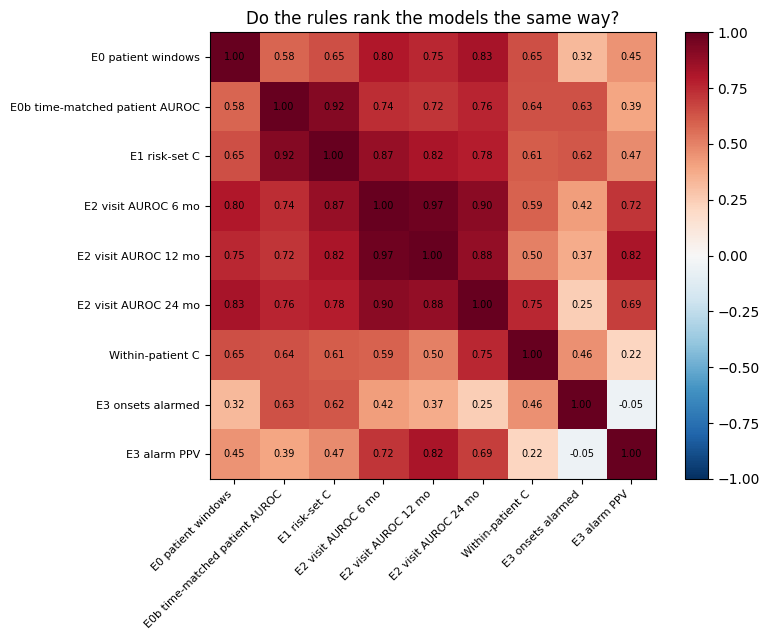

In [50]:
"""Every model under every evaluation rule."""
_al = ALARMS[(ALARMS["Re-assessment"] == "visit") & (ALARMS["Alarm rule"] == "level")].set_index("Model")
_alr = ALARMS[(ALARMS["Re-assessment"] == "visit") & (ALARMS["Alarm rule"] == "level_or_rise")].set_index("Model")
FRAME_KEYS = [("E0 patient windows", K_PT), ("E0b time-matched patient AUROC", K_TM), ("E1 risk-set C", K_RS), ("E2 visit AUROC 6 mo", ("visit", 6, "auroc")),
              ("E2 visit AUROC 12 mo", K_VIS), ("E2 visit AUROC 24 mo", ("visit", 24, "auroc")),
              ("Within-patient C", ("within", H, "c"))]
rows, num = [], []
for m in MODELS_RUN:
    row = {"Model": short_label(m), **{lab_: fmtk((m,) + k) for lab_, k in FRAME_KEYS}}
    a_, b_ = _al.loc[short_label(m)], _alr.loc[short_label(m)]
    row.update({"E3 onsets alarmed (level)": f"{a_['Onsets with an alarm in the 12 months before']:.2f}",
                "E3 alarm PPV (level)": f"{a_['PPV of an alarm (onset within 12 months)']:.3f}",
                "E3 alarms / patient-year (level)": f"{a_['Alarms per patient-year']:.2f}",
                "E3 onsets alarmed (level or rise)": f"{b_['Onsets with an alarm in the 12 months before']:.2f}",
                "E3 alarm PPV (level or rise)": f"{b_['PPV of an alarm (onset within 12 months)']:.3f}"})
    rows.append(row)
    num.append({"Model": short_label(m), **{lab_: ci((m,) + k)[0] for lab_, k in FRAME_KEYS},
                "E3 onsets alarmed": a_["Onsets with an alarm in the 12 months before"],
                "E3 alarm PPV": a_["PPV of an alarm (onset within 12 months)"]})
FRAMES = pd.DataFrame(rows).set_index("Model")
display(FRAMES)
FRAMES.to_csv(f"objective3_evaluation_rules_{TAG}.csv")
NUM = pd.DataFrame(num).set_index("Model")
RHO = NUM.corr(method="spearman")
print("Rank correlation across models between the rules (Spearman):")
display(RHO.round(2))
RHO.to_csv(f"objective3_rule_agreement_{TAG}.csv")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(RHO.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(RHO))); ax.set_xticklabels(RHO.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(RHO))); ax.set_yticklabels(RHO.index, fontsize=8)
for i in range(len(RHO)):
    for j in range(len(RHO)):
        ax.text(j, i, f"{RHO.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Do the rules rank the models the same way?")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_rule_agreement.png", dpi=150, bbox_inches="tight"); plt.show()

## 18.8 Does the rule change the conclusion?

The key contrasts under every rule with a bootstrap CI: DYN − Baseline (primary), DYN − LogReg (secondary),
DYN − S0 (update_v8's model) and DYN − Reg-DYN.

In [51]:
"""Key contrasts under every rule."""
rows = []
for a, b in [(MAIN_MODEL, BASELINE), (MAIN_MODEL, LOGREG), (MAIN_MODEL, V8_MAIN), (MAIN_MODEL, REG_DYN)]:
    if a not in MODELS_RUN or b not in MODELS_RUN:
        continue
    row = {"Contrast": f"{short_label(a)} - {short_label(b)}"}
    for lab_, k in FRAME_KEYS:
        d = diff(a, b, k)
        row[lab_] = f"{fmt(*d[:3])} {verdict_superiority(d[1], d[2], EQUIV_MARGIN)[:5]}"
    rows.append(row)
RULE_CMP = pd.DataFrame(rows).set_index("Contrast")
display(RULE_CMP.T)
RULE_CMP.to_csv(f"objective3_contrasts_by_rule_{TAG}.csv")

Contrast,DYN - Baseline,DYN - LogReg,DYN - S0 v8-main,DYN - Reg-DYN
E0 patient windows,0.049 (0.016 to 0.082) super,0.017 (0.006 to 0.029) super,0.010 (-0.004 to 0.024) incon,0.016 (0.003 to 0.029) super
E0b time-matched patient AUROC,0.161 (0.109 to 0.214) super,0.009 (-0.006 to 0.024) incon,0.024 (-0.001 to 0.047) incon,0.014 (-0.003 to 0.032) incon
E1 risk-set C,0.165 (0.113 to 0.218) super,0.019 (0.005 to 0.034) super,0.021 (-0.005 to 0.047) incon,0.018 (0.000 to 0.037) super
E2 visit AUROC 6 mo,0.124 (0.081 to 0.168) super,0.017 (0.005 to 0.030) super,0.015 (-0.008 to 0.038) incon,0.017 (0.002 to 0.032) super
E2 visit AUROC 12 mo,0.111 (0.071 to 0.156) super,0.014 (0.002 to 0.026) super,0.012 (-0.009 to 0.031) incon,0.015 (0.000 to 0.029) super
E2 visit AUROC 24 mo,0.108 (0.065 to 0.154) super,0.011 (-0.001 to 0.024) incon,0.011 (-0.008 to 0.030) incon,0.009 (-0.005 to 0.022) incon
Within-patient C,0.191 (0.106 to 0.282) super,0.011 (-0.019 to 0.039) incon,0.023 (-0.031 to 0.075) incon,0.008 (-0.031 to 0.045) incon


## 18.9 Is discrimination stable across calendar time?

Visit AUROC (12 months, IPCW) of the main model, the Baseline and LogReg in overlapping 4-year windows of
landmark dates (step 1 year; windows with ≥ 10 onsets), from the same CV predictions, against each model's overall
AUROC. With many overlapping windows and few onsets in each, some windows fall outside the overall value by chance
alone: the share of windows whose 95 % CI excludes the overall AUROC shows how much a single window can be trusted.
Not a temporal validation (every model was trained on every era).

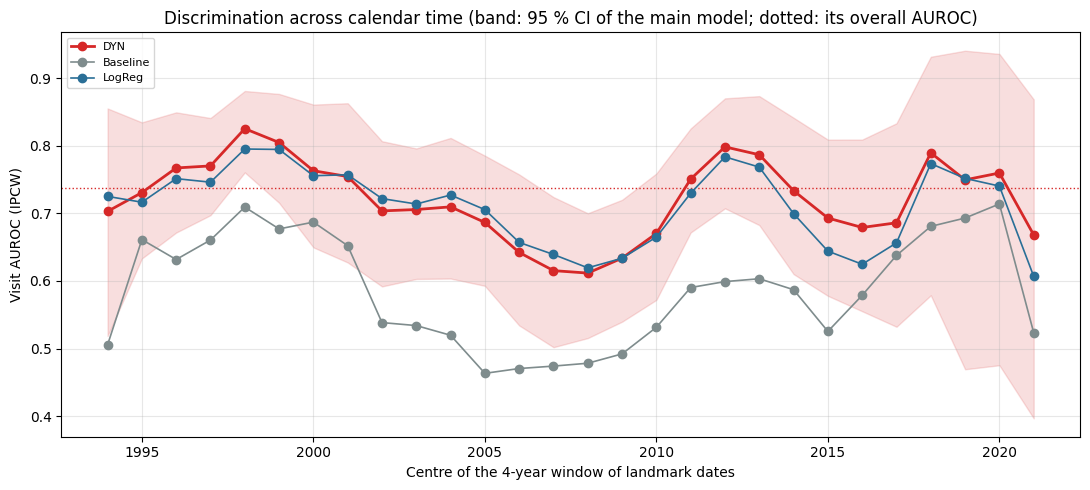

,windows,below,above,lowest,highest
Model,,,,,
Baseline,28,0.179,0.000,0.463,0.714
DYN,28,0.107,0.036,0.612,0.825
LogReg,28,0.071,0.000,0.607,0.795


In [52]:
"""Discrimination in rolling calendar windows."""
_yr_l = land["CAL_YEAR"].values
_y0, _y1 = int(np.floor(_yr_l[ROWS_IPCW].min())), int(np.ceil(_yr_l[ROWS_IPCW].max()))
_wins = [(a, a + CAL_WINDOW_YEARS) for a in range(_y0, _y1 - CAL_WINDOW_YEARS + 1, CAL_WINDOW_STEP)]
rows = []
for m in [m for m in KEY_MODELS if m in MODELS_RUN]:
    overall = ci((m,) + K_VIS)[0]
    for a, b in _wins:
        k = (_yr_l[ROWS_IPCW] >= a) & (_yr_l[ROWS_IPCW] < b)
        if Y_IPCW[k].sum() < CAL_WINDOW_MIN_ONSETS:
            continue
        rr = ROWS_IPCW[k]
        Wr = _BOTH[:, ROW_PIDX[rr]] * WI_IPCW[k][None, :]
        v = np.mean([wauc(Y_IPCW[k], zpred(m, r)[rr], Wr) for r in REPEATS], 0)
        lo, hi = np.nanpercentile(v[1:], [2.5, 97.5])
        rows.append({"Model": short_label(m), "Window": f"{a}-{b - 1}", "Start": a, "Landmarks": int(k.sum()),
                     "Onsets": int(Y_IPCW[k].sum()), "AUROC": v[0], "Lower": lo, "Upper": hi, "Overall": overall,
                     "CI below overall": hi < overall, "CI above overall": lo > overall})
CALWIN = pd.DataFrame(rows)
CALWIN.to_csv(f"objective1_calendar_windows_{TAG}.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 5))
for m in KEY_MODELS:
    d = CALWIN[CALWIN["Model"] == short_label(m)]
    if len(d):
        x = d["Start"] + CAL_WINDOW_YEARS / 2
        ax.plot(x, d["AUROC"], "o-", color=model_color(m), lw=2 if m == MAIN_MODEL else 1.2, label=short_label(m))
        if m == MAIN_MODEL:
            ax.fill_between(x, d["Lower"], d["Upper"], color=model_color(m), alpha=0.15)
            ax.axhline(d["Overall"].iloc[0], color=model_color(m), ls=":", lw=1)
ax.set_xlabel(f"Centre of the {CAL_WINDOW_YEARS}-year window of landmark dates"); ax.set_ylabel("Visit AUROC (IPCW)")
ax.set_title("Discrimination across calendar time (band: 95 % CI of the main model; dotted: its overall AUROC)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_calendar_windows.png", dpi=150, bbox_inches="tight"); plt.show()
_s = CALWIN.groupby("Model").agg(windows=("Window", "size"), below=("CI below overall", "mean"),
                                 above=("CI above overall", "mean"), lowest=("AUROC", "min"), highest=("AUROC", "max"))
display(_s.round(3))

## 18.10 Patient-level discrimination with restricted risk sets

The patient AUROC compares the 24 months before an onset with the last 24 months of event-free follow-up, so the
two groups are scored at different calendar times; the risk-set C compares patients on the same date. This keeps
the risk-set design (each onset's last landmark against every control's latest landmark on the onset date) and
restricts the controls: patients known to be onset-free for 12 months; patients who never have an onset; and those
with the same time in clinic (first visit within 2 years of the case's). update_v6 found that matching on time in
clinic brings the risk-set C to about 0.77, so most of the gap to the patient AUROC is between-patient separation
and the rest is the difference in scoring time.

In [53]:
"""Restricted risk sets."""
_FIRST_DAY = pd.Series({pid: _VDAYS[_VIDX[pid][0]] for pid in PT_ROWS})
_first_row = _FIRST_DAY.reindex(PID_ALL).values
_ever = np.isin(PID_ALL, list(EVER_ONSET))
_rem = _END[RS_CTRL] - INT_END[RS_CASE]
RS_VARIANTS = {"All at risk (main)": np.ones(len(RS_CASE), bool),
               "Onset-free 12 months": (_rem > HORIZON_DAYS) | (C_ALL[RS_CTRL] >= 2),
               "Never an onset": ~_ever[RS_CTRL],
               "Never an onset, matched time in clinic": ~_ever[RS_CTRL]
               & (np.abs(_first_row[RS_CTRL] - _first_row[RS_CASE]) <= 2 * 365.25)}
rows = []
for m in [m for m in FIG_MODELS if m in MODELS_RUN]:
    row = {"Model": short_label(m), "Patient AUROC (windows)": fmtk((m,) + K_PT)}
    for lab_, mk in RS_VARIANTS.items():
        den = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(mk.sum()), (RS_PC[mk], RS_PK[mk])),
                                                      shape=(P_, P_)).toarray())
        vals = []
        for r in REPEATS:
            ps = patient_score_rs(m, zpred(m, r))
            a, b = ps[RS_CASE[mk]], ps[RS_CTRL[mk]]
            K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (RS_PC[mk], RS_PK[mk])), shape=(P_, P_)).toarray()
            vals.append(_pair_sum_fast(_BOTH, K) / den)
        v = np.mean(vals, 0)
        row[lab_] = fmt(v[0], *np.nanpercentile(v[1:], [2.5, 97.5]))
    rows.append(row)
RS_RESTRICTED = pd.DataFrame(rows).set_index("Model")
display(RS_RESTRICTED)
RS_RESTRICTED.to_csv(f"sensitivity_riskset_restricted_{TAG}.csv")
_pa = [ci((m,) + K_PT)[0] for m in MODELS_RUN]
_rc = [ci((m,) + K_RS)[0] for m in MODELS_RUN]
print(f"Rank correlation across models, patient AUROC vs risk-set C: {stats.spearmanr(_pa, _rc).correlation:.2f}")

,Patient AUROC (windows),All at risk (main),Onset-free 12 months,Never an onset,"Never an onset, matched time in clinic"
Model,,,,,
DYN,0.836 (0.800 to 0.871),0.748 (0.707 to 0.787),0.758 (0.718 to 0.799),0.761 (0.718 to 0.803),0.775 (0.733 to 0.813)
Baseline,0.787 (0.750 to 0.824),0.583 (0.532 to 0.635),0.585 (0.533 to 0.639),0.589 (0.531 to 0.646),0.608 (0.552 to 0.666)
LogReg,0.818 (0.781 to 0.855),0.729 (0.688 to 0.769),0.742 (0.701 to 0.782),0.739 (0.693 to 0.782),0.762 (0.720 to 0.802)
DYN-bands,0.827 (0.790 to 0.865),0.733 (0.692 to 0.774),0.744 (0.704 to 0.787),0.744 (0.700 to 0.789),0.762 (0.720 to 0.802)
Reg-DYN,0.820 (0.780 to 0.858),0.729 (0.686 to 0.772),0.741 (0.700 to 0.786),0.739 (0.693 to 0.786),0.764 (0.722 to 0.805)
S0 v8-main,0.825 (0.789 to 0.863),0.726 (0.686 to 0.768),0.733 (0.692 to 0.777),0.741 (0.697 to 0.788),0.763 (0.721 to 0.803)
Two-part,0.827 (0.791 to 0.862),0.699 (0.659 to 0.743),0.713 (0.671 to 0.755),0.710 (0.664 to 0.756),0.722 (0.677 to 0.766)


Rank correlation across models, patient AUROC vs risk-set C: 0.65


## 18.11 What changed from update_v9

* **Objectives restructured around the patients**: (1) patients who go on to work disability score higher than those
  still working on the same dates; (2) the risk is higher the closer the onset; (3) patients who stay at work,
  especially healthy-looking ones, score low; (4) what drives the LSTM's risk (SHAP).
* **Primary metric: the time-matched patient AUROC** (Section 11.8): each patient's mean 12-month risk over the 12
  months before the onset against every patient still working on the onset date, scored over the same calendar
  window. Primary comparison DYN − Baseline; secondary DYN − LogReg (logistic regression of the 12-month label on
  the same inputs, new in this version).
* Objective 2: the time-matched AUROC by months before the onset; year-centred trajectories, a mixed model and the
  within-patient C (centring removes the calendar trend that pushed v9's within-patient C below 0.5).
* Objective 3: risk and flags in healthy-looking stayers; the profile of the false positives.
* Objective 4: SHAP (expected gradients) of the LSTM on test patients, by input, domain, grid point and time before
  onset; the linear surrogate is dropped. Calendar year is reported as a separate adjustment line, not ranked as a
  driver; a recent-era pass (2012 on, recent background) shows the drivers for current patients.
* update_v9's primary test (DYN − update_v8's model), the one-change-at-a-time comparisons, the horizons and the
  evaluation rules are kept as secondary analyses (Section 18). The model fits are update_v9's.

---
# 19. TRIPOD+AI reporting

The items of the TRIPOD+AI checklist (Collins et al., BMJ 2024) that need analysis, then the checklist itself with
where each item is reported (Section 19.7):

* **19.1** Data sources, dates and participant flow (items 5b, 20a).
* **19.2** Participant characteristics and missing data (items 7, 11, 20b).
* **19.3** Sample size (item 10).
* **19.4** Fairness: discrimination, calibration and alarms by sex, race, age and education (items 14, 23a).
* **19.5** Performance by length of clinic history, and what happens for a new patient (item 27a).
* **19.6** Temporal hold-out: develop on the years before 2012, evaluate on 2012 onwards (items 12c, 16, 20c, 23a).

## 19.1 Data sources, dates and participant flow

One centre (the Toronto Lupus Clinic), routinely collected visit data. Dates of the first and last visits, of the
first and last landmarks and of the end of follow-up; then the flow from the extract to the analysed landmarks, with
the number of patients and landmarks at each step and the outcomes.

In [54]:
"""Dates and participant flow (TRIPOD+AI 5b, 20a)."""
_vd = visits["ASSDT"]
_ld = land["visit_date"]
DATES = pd.Series({
    "First visit in the extract": _vd.min().date(), "Last visit in the extract (end of follow-up)": _vd.max().date(),
    "First landmark": _ld.min().date(), "Last landmark": _ld.max().date(),
    "Median landmark date": _ld.sort_values().iloc[len(_ld) // 2].date()}, name="Date")
display(DATES.to_frame())
_n_ev_pt = land.loc[land["event"] == 1, "pid"].nunique()
_fu_yrs = land.groupby("pid")["time_days"].first().values / 365.25        # first landmark to the end of follow-up
_last_cause = land.groupby("pid")["cause"].last()
_ever_ev = land.groupby("pid")["pt_event"].max()
FLOW = pd.DataFrame([
    ("Patients in the extract", load_audit["raw_patients"], None, ""),
    ("Usable records (valid identifiers and dates)", load_audit["usable_patients"], None,
     f"excluded {load_audit['raw_patients'] - load_audit['usable_patients']:,}"),
    (f"Employed at >= 1 visit before age {AGE_CAP_YEARS}", int(patients_df["ever_employed"].sum()), None,
     f"excluded {load_audit['usable_patients'] - int(patients_df['ever_employed'].sum()):,} never employed before "
     f"{AGE_CAP_YEARS}"),
    (">= 1 landmark (an employed visit before 65 that is not the last visit)", land["pid"].nunique(), len(land),
     f"excluded {int(patients_df['ever_employed'].sum()) - land['pid'].nunique():,} (only one employed visit, or "
     f"their only employed visit was their last)"),
    ("  ... with a work-disability onset", _n_ev_pt, int(land["pt_event"].sum()), ""),
    ("  ... no onset, follow-up ends in a competing exit (retirement, other exit)",
     int(((_ever_ev == 0) & (_last_cause >= 2)).sum()), None, ""),
    ("  ... no onset, censored", int(((_ever_ev == 0) & (_last_cause == 0)).sum()), None, ""),
    ("Landmarks with a known 12-month status", int(LABELLED.sum()), None,
     f"unresolved {int((~LABELLED).sum()):,} (follow-up < 12 months without an event)"),
], columns=["Step", "Patients", "Landmarks", "Note"])
display(FLOW.set_index("Step"))
FLOW.to_csv(f"tripod_flow_{TAG}.csv", index=False)
print(f"Onsets (first per patient): {len(FIRST_ONSET)}; onsets in at-risk intervals: {int(D_ONSET.sum())}; competing "
      f"exits: {int(D_COMP.sum())}. Follow-up from the first landmark: median {np.median(_fu_yrs):.1f} years (IQR "
      f"{np.percentile(_fu_yrs, 25):.1f}-{np.percentile(_fu_yrs, 75):.1f}); landmarks per patient: median "
      f"{land.groupby('pid').size().median():.0f} (IQR {land.groupby('pid').size().quantile(.25):.0f}-"
      f"{land.groupby('pid').size().quantile(.75):.0f}).")

,Date
First visit in the extract,1973-04-04
Last visit in the extract (end of follow-up),2024-04-08
First landmark,1983-02-28
Last landmark,2024-01-22
Median landmark date,2011-06-30


,Patients,Landmarks,Note
Step,,,
Patients in the extract,1898,NaN,
Usable records (valid identifiers and dates),1898,NaN,excluded 0
Employed at >= 1 visit before age 65,1112,NaN,excluded 786 never employed before 65
>= 1 landmark (an employed visit before 65 that is not the last visit),1059,17338.0,"excluded 53 (only one employed visit, or their..."
... with a work-disability onset,150,2281.0,
"... no onset, follow-up ends in a competing exit (retirement, other exit)",133,NaN,
"... no onset, censored",776,NaN,
Landmarks with a known 12-month status,16174,NaN,"unresolved 1,164 (follow-up < 12 months withou..."


Onsets (first per patient): 150; onsets in at-risk intervals: 158; competing exits: 237. Follow-up from the first landmark: median 5.4 years (IQR 2.0-10.4); landmarks per patient: median 11 (IQR 5-24).


## 19.2 Participant characteristics (Table 1) and missing data

**Table 1**: each patient at their **first landmark**, by whether they later have a work-disability onset;
continuous variables as median (IQR), binary as n (%), with the standardised mean difference (SMD). **Missing data**
(item 11): the model inputs are not imputed before modelling; each training fold imputes the median and adds a
missing-value indicator (Section 11.4), so no landmark is dropped for missing inputs. The table below gives the share
missing per input over all landmarks, by outcome group, by sex and by race (item 7: is missingness similar across
groups?).

In [55]:
"""Table 1 and missing data (TRIPOD+AI 7, 11, 20b)."""
_first = land.groupby("pid").head(1).index.values
_T1 = LAND_X.iloc[_first].reset_index(drop=True).copy()
_T1["SEX_FEMALE"] = land["SEX_FEMALE"].values[_first]
_T1["CAL_YEAR"] = land["CAL_YEAR"].values[_first]
for g_ in ["White", "Black", "Asian", "Other / not recorded"]:
    _T1[f"Race: {g_}"] = (land["RACE_GROUP"].values[_first] == g_).astype(float)
_grp = land["pt_event"].values[_first] == 1
T1_CONT = ["age_at_record", "disease_duration_yrs", "SLEDAI2_I", "score_n", "STERAVER_0", "TENDER_POINTS",
           "CAL_YEAR"]          # years in clinic, visit rate and years employed are ~0 / not yet defined at the first one
T1_BIN = ["SEX_FEMALE", "Race: White", "Race: Black", "Race: Asian", "Race: Other / not recorded", "EDU_HIGHER",
          "SMOKER", "AM_CLASS", "IS_CLASS", "ADV_CLASS", "FATIGUE", "ARTHRALGIA", "FIBROMYALGIA", "DYSPNOEA"]
_lab = lambda c: {"SEX_FEMALE": "Female", "CAL_YEAR": "Calendar year of the first landmark"}.get(c, DISPLAY_NAMES.get(c, c))


def _smd(a, b):
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    sd = np.sqrt((np.var(a) + np.var(b)) / 2)
    return (np.mean(a) - np.mean(b)) / sd if sd > 0 else np.nan


rows = []
for c in T1_CONT + T1_BIN:
    if c not in _T1:
        continue
    x = _T1[c].astype(float).values
    row = {"Variable": _lab(c)}
    for nm, k in [("All", np.ones(len(x), bool)), ("Later onset", _grp), ("No onset", ~_grp)]:
        v = x[k]
        if c in T1_CONT:
            row[f"{nm} (n={k.sum()})"] = (f"{np.nanmedian(v):.1f} ({np.nanpercentile(v, 25):.1f}-"
                                          f"{np.nanpercentile(v, 75):.1f})")
        else:
            row[f"{nm} (n={k.sum()})"] = f"{int(np.nansum(v))} ({np.nanmean(v):.0%})"
    row["SMD"] = round(_smd(x[_grp], x[~_grp]), 2)
    row["Missing"] = f"{np.mean(np.isnan(x)):.0%}"
    rows.append(row)
TABLE1 = pd.DataFrame(rows).set_index("Variable")
display(TABLE1)
TABLE1.to_csv(f"tripod_table1_{TAG}.csv")

_MX = LAND_X[[c for c in V2_VARS if c in LAND_X]].astype(float).isna()
_ev_l = land["pt_event"].values == 1
_sex = LAND_SUB["sex"].values; _race = LAND_SUB["race"].values
MISS = pd.DataFrame({"All landmarks": _MX.mean(), "Later onset": _MX[_ev_l].mean(), "No onset": _MX[~_ev_l].mean(),
                     "Female": _MX[_sex == "Female"].mean(), "Male": _MX[_sex == "Male"].mean(),
                     **{f"Race: {g_}": _MX[_race == g_].mean() for g_ in ["White", "Black", "Asian",
                                                                           "Other / not recorded"]}})
MISS.index = [DISPLAY_NAMES.get(c, c) for c in MISS.index]
MISS = MISS[MISS["All landmarks"] > 0].sort_values("All landmarks", ascending=False)
print(f"Model inputs with any missing value at the landmark visit: {len(MISS)} of {_MX.shape[1]} "
      f"(the others are complete). Landmarks with >= 1 missing input: {_MX.any(axis=1).mean():.0%}.")
display((100 * MISS).round(1))
MISS.to_csv(f"tripod_missing_{TAG}.csv")
_maxdiff = (MISS.drop(columns=["All landmarks"]).max(1) - MISS.drop(columns=["All landmarks"]).min(1)).max()
print(f"Largest difference in the share missing between any two groups, over the inputs: {100 * _maxdiff:.1f} "
      f"percentage points.")

,All (n=1059),Later onset (n=150),No onset (n=909),SMD,Missing
Variable,,,,,
Age,34.5 (27.3-43.8),38.8 (29.3-47.0),33.9 (27.2-43.0),0.25,0%
Disease duration (yrs),5.3 (0.8-11.3),6.5 (0.8-14.2),5.2 (0.8-11.1),0.19,0%
SLEDAI-2K,4.0 (2.0-8.0),6.0 (2.0-10.0),4.0 (2.0-8.0),0.21,0%
SDI damage score,1.0 (0.0-2.0),1.0 (0.0-2.0),1.0 (0.0-1.0),0.39,0%
"Prednisone, average dose since last visit (mg/day)",0.0 (0.0-7.5),2.8 (0.0-10.0),0.0 (0.0-7.5),0.22,0%
Fibromyalgia tender points (0-18),0.0 (0.0-2.0),0.0 (0.0-8.0),0.0 (0.0-0.0),0.31,44%
Calendar year of the first landmark,2008.2 (1999.8-2016.0),2001.4 (1995.6-2007.7),2009.7 (2001.0-2016.7),-0.74,0%
Female,933 (88%),138 (92%),795 (88%),0.15,0%
Race: White,611 (58%),99 (66%),512 (56%),0.20,0%


Model inputs with any missing value at the landmark visit: 10 of 27 (the others are complete). Landmarks with >= 1 missing input: 28%.


,All landmarks,Later onset,No onset,Female,Male,Race: White,Race: Black,Race: Asian,Race: Other / not recorded
Fibromyalgia tender points (0-18),12.5,6.5,13.4,12.4,13.5,8.9,17.8,13.3,27.7
Education: higher,12.1,7.2,12.9,12.1,12.4,15.1,10.3,5.6,5.4
Fibromyalgia,6.4,13.2,5.4,6.4,6.3,7.0,6.9,5.3,3.2
Current smoker,0.5,0.1,0.6,0.5,0.9,0.7,0.3,0.3,0.1
Fatigue,0.2,0.3,0.2,0.3,0.1,0.1,0.1,0.8,0.4
Arthralgia,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.1,0.1
Dyspnoea,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0
SLEDAI-2K,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Age,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1
Disease duration (yrs),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1


Largest difference in the share missing between any two groups, over the inputs: 21.2 percentage points.


## 19.3 Sample size

Riley et al.'s criteria (BMJ 2020; Stat Med 2019) for a model of a binary outcome (here the 12-month onset at a
visit), for the **regression on the main model's inputs** (LogReg; the number of parameters P = its columns):
(i) expected shrinkage ≥ 0.9; (ii) optimism in Nagelkerke R² ≤ 0.05; (iii) the overall risk estimated within ± 0.05.
The anticipated Cox-Snell R² is derived from the observed AUROC and outcome rate (binormal model with equal
variances, Riley et al., Stat Med 2021). Calculated at two units, because landmarks are clustered within patients:
**landmarks** (optimistic: they are not independent) and **patients** (conservative: each patient's onset or not).
For the **LSTM**, whose parameters are not regression coefficients, these criteria do not apply directly; its number
of parameters is reported, and overfitting is controlled by a fixed configuration (nothing tuned), dropout, weight
decay, early stopping on held-out patients and recalibration inside each training fold; the CV calibration slope
(H1c) is the empirical check.

In [56]:
"""Sample size (TRIPOD+AI 10): Riley et al.'s criteria."""
from scipy.stats import norm as _norm


def r2cs_from_c(c, phi, n_sim=2_000_000, seed=SEED):
    """Cox-Snell R2 of a model with AUROC c at outcome rate phi (binormal, equal variances; exact log-odds)."""
    rng_ = np.random.RandomState(seed)
    mu = np.sqrt(2) * _norm.ppf(c)
    y = rng_.rand(n_sim) < phi
    x = rng_.randn(n_sim) + mu * y
    lp = np.log(phi / (1 - phi)) + mu * x - mu ** 2 / 2
    ll1 = np.sum(y * -np.logaddexp(0, -lp) + (~y) * -np.logaddexp(0, lp))
    ll0 = n_sim * (phi * np.log(phi) + (1 - phi) * np.log(1 - phi))
    return 1 - np.exp(2 * (ll0 - ll1) / n_sim)


def riley(P, phi, r2, S=0.9, delta=0.05, margin=0.05):
    maxr2 = 1 - np.exp(2 * (phi * np.log(phi) + (1 - phi) * np.log(1 - phi)))
    n1 = P / ((S - 1) * np.log(1 - r2 / S))
    s2 = r2 / (r2 + delta * maxr2)
    n2 = P / ((s2 - 1) * np.log(1 - r2 / s2))
    n3 = (1.96 / margin) ** 2 * phi * (1 - phi)
    return {"max R2 (Cox-Snell)": maxr2, "n (i) shrinkage >= 0.9": n1, "n (ii) optimism <= 0.05": n2,
            "n (iii) overall risk +/- 0.05": n3, "n required": max(n1, n2, n3)}


_coef = next(v["coef"] for k, v in ALL_FOLDS.items() if k[0] == LOGREG and v.get("coef"))
P_LOGREG = len(_coef["names"])
_F_IN = len(GridPrep(grid_cols_of(MAIN_MODEL)).names)                  # inputs per grid point, incl. indicators
_h = SEQ_CFG["hidden"]
P_LSTM = 4 * _h * (_F_IN + _h) + 8 * _h + (_h + _F_IN) * 2 + 2
_lab12 = LABELLED
_phi_l = float(np.nanmean(Y_ALL[_lab12]))
_n_l = int(_lab12.sum())
_pt_ev = land.loc[_lab12].groupby("pid")["pt_event"].max()
_phi_p, _n_p = float(_pt_ev.mean()), len(_pt_ev)
rows = []
for unit, n_avail, phi, c_obs in [("Landmarks", _n_l, _phi_l, ci((LOGREG,) + K_VIS)[0]),
                                  ("Patients", _n_p, _phi_p, ci((LOGREG,) + K_PT)[0])]:
    r2 = r2cs_from_c(c_obs, phi)
    rr = riley(P_LOGREG, phi, r2)
    p_max = n_avail * (0.9 - 1) * np.log(1 - r2 / 0.9)
    rows.append({"Unit": unit, "Available n": n_avail, "Outcome rate": round(phi, 4), "Events": int(round(phi * n_avail)),
                 "Observed AUROC (LogReg, CV)": round(c_obs, 3), "Anticipated R2 (Cox-Snell)": round(r2, 4),
                 **{k: (round(v, 4) if k.startswith("max") else int(np.ceil(v))) for k, v in rr.items()},
                 "Parameters P (LogReg)": P_LOGREG, "Events per parameter": round(phi * n_avail / P_LOGREG, 1),
                 "Max P for shrinkage >= 0.9": int(np.floor(p_max)), "Criteria met": n_avail >= rr["n required"]})
SAMPLE_SIZE = pd.DataFrame(rows).set_index("Unit").T
display(SAMPLE_SIZE)
SAMPLE_SIZE.to_csv(f"tripod_sample_size_{TAG}.csv")
print(f"LSTM (main model): {P_LSTM:,} parameters ({_F_IN} inputs per grid point, {_h} hidden units, a linear head on "
      f"the hidden state and the landmark point); {int(D_ONSET.sum())} onsets. CV calibration slope "
      f"{fmtk((MAIN_MODEL, 'visit', H, 'cal_slope'))} (a slope well below 1 would show overfitting).")

Unit,Landmarks,Patients
Available n,16174,988
Outcome rate,0.0185,0.1508
Events,299,149
"Observed AUROC (LogReg, CV)",0.723,0.818
Anticipated R2 (Cox-Snell),0.0124,0.1715
max R2 (Cox-Snell),0.1682,0.5718
n (i) shrinkage >= 0.9,47635,3122
n (ii) optimism <= 0.05,7766,2069
n (iii) overall risk +/- 0.05,28,197
n required,47635,3122


LSTM (main model): 13,128 parameters (67 inputs per grid point, 32 hidden units, a linear head on the hidden state and the landmark point); 158 onsets. CV calibration slope 1.056 (0.878 to 1.257) (a slope well below 1 would show overfitting).


## 19.4 Fairness: performance by sex, race, age and education

For the main model and LogReg, at the visit level (12 months, IPCW, mean over the CV repeats, 95 % CI from the
patient bootstrap): AUROC, **O/E** (observed / expected onsets: calibration-in-the-large; > 1 = the model
under-predicts the group), the **share of stayers' visits alarmed** (false-alarm rate at the fold's visit threshold)
and the **share of onset visits alarmed** (sensitivity). Groups with fewer than 10 onset landmarks are shown but not
interpreted. Race and education are model inputs (social determinants of work disability); their inclusion is
discussed in Section 10.

Landmarks  Onset landmarks                   AUROC                     O/E Stayers' visits alarmed    Onset visits alarmed
Model  Group                                                                                                                                                 
DYN    Sex: Female                     14482              275  0.728 (0.685 to 0.772)  1.033 (0.846 to 1.233)  0.328 (0.301 to 0.353)  0.663 (0.593 to 0.736)
       Sex: Male                        1698               26  0.829 (0.713 to 0.917)  0.823 (0.346 to 1.432)  0.318 (0.251 to 0.404)  0.839 (0.589 to 0.983)
       Race: White                      9999              186  0.742 (0.691 to 0.790)  0.988 (0.774 to 1.229)  0.336 (0.303 to 0.368)  0.707 (0.625 to 0.783)
       Race: Black                      2452               64  0.767 (0.672 to 0.859)  1.153 (0.747 to 1.620)  0.435 (0.370 to 0.499)  0.809 (0.672 to 0.927)
       Race: Asian                      2556               40  0.643 (0.517 to 0.787)  1.020 (0.490 to 1.683)  0.253 (0.195 to 0.313)  0.414 (0.234 to 0.658)
       Race: Other / not recorded       1173               11  0.788 (0.701 to 0.881)  0.752 (0.174 to 1.564)  0.184 (0.128 to 0.244)  0.386 (0.123 to 0.746)
       Age: < 40                        7255              132  0.745 (0.681 to 0.804)  1.038 (0.756 to 1.326)  0.305 (0.276 to 0.335)  0.665 (0.567 to 0.762)
       Age: 40-49                       4926               66  0.777 (0.702 to 0.850)  0.712 (0.451 to 1.020)  0.341 (0.297 to 0.385)  0.735 (0.594 to 0.858)
       Age: 50-59                       3352               86  0.698 (0.616 to 0.773)  1.318 (0.913 to 1.751)  0.351 (0.303 to 0.400)  0.646 (0.503 to 0.776)
       Age: >= 60                        647               17  0.731 (0.483 to 0.907)  1.347 (0.445 to 2.428)  0.337 (0.253 to 0.427)  0.716 (0.421 to 0.934)
       Education: higher                6688              112  0.746 (0.672 to 0.813)  1.122 (0.796 to 1.478)  0.233 (0.202 to 0.266)  0.576 (0.455 to 0.697)
       Education: not higher            7445              160  0.741 (0.686 to 0.799)  1.058 (0.801 to 1.334)  0.388 (0.352 to 0.426)  0.753 (0.664 to 0.836)
LogReg Sex: Female                     14482              275  0.711 (0.668 to 0.756)  0.976 (0.796 to 1.167)  0.311 (0.286 to 0.334)  0.608 (0.538 to 0.682)
       Sex: Male                        1698               26  0.846 (0.753 to 0.922)  0.763 (0.321 to 1.320)  0.316 (0.256 to 0.389)  0.847 (0.680 to 0.956)
       Race: White                      9999              186  0.729 (0.676 to 0.780)  0.950 (0.742 to 1.184)  0.308 (0.279 to 0.337)  0.642 (0.563 to 0.724)
       Race: Black                      2452               64  0.740 (0.636 to 0.828)  1.060 (0.682 to 1.496)  0.432 (0.369 to 0.492)  0.772 (0.625 to 0.896)
       Race: Asian                      2556               40  0.657 (0.548 to 0.795)  0.954 (0.466 to 1.563)  0.250 (0.200 to 0.303)  0.410 (0.220 to 0.668)
       Race: Other / not recorded       1173               11  0.728 (0.612 to 0.855)  0.622 (0.143 to 1.281)  0.222 (0.163 to 0.293)  0.367 (0.121 to 0.669)
       Age: < 40                        7255              132  0.728 (0.666 to 0.788)  0.933 (0.679 to 1.196)  0.312 (0.283 to 0.342)  0.615 (0.520 to 0.715)
       Age: 40-49                       4926               66  0.761 (0.673 to 0.843)  0.679 (0.436 to 0.964)  0.323 (0.284 to 0.361)  0.696 (0.531 to 0.837)
       Age: 50-59                       3352               86  0.691 (0.602 to 0.767)  1.325 (0.915 to 1.773)  0.299 (0.257 to 0.344)  0.591 (0.451 to 0.715)
       Age: >= 60                        647               17  0.740 (0.500 to 0.910)  1.396 (0.481 to 2.513)  0.283 (0.205 to 0.368)  0.669 (0.398 to 0.910)
       Education: higher                6688              112  0.728 (0.655 to 0.797)  0.983 (0.697 to 1.302)  0.255 (0.223 to 0.289)  0.552 (0.424 to 0.677)
       Education: not higher            7445              160  0.728 (0.670 to 0.790)

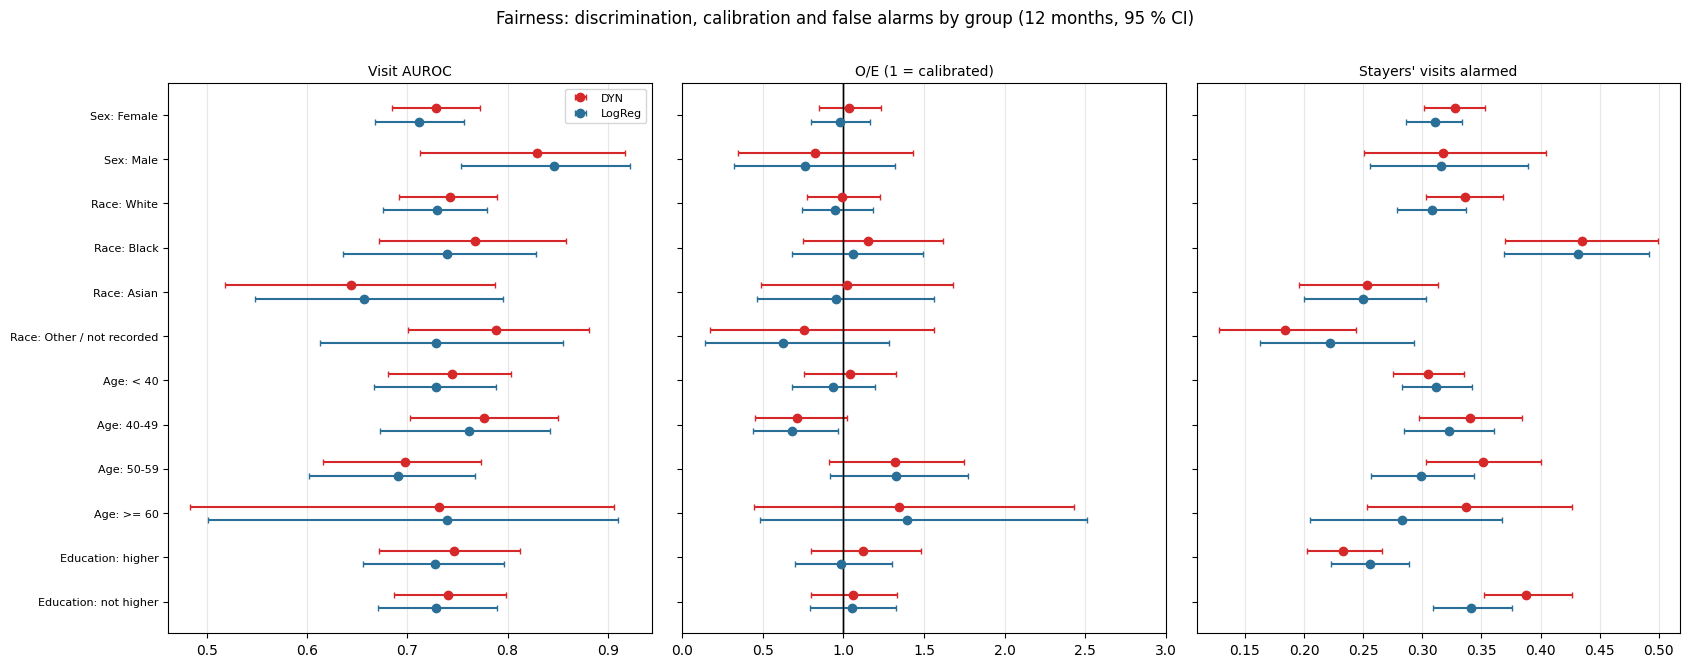

Groups whose O/E 95 % CI excludes 1 (main model): none


In [57]:
"""Fairness (TRIPOD+AI 14, 23a)."""
_rows_h, _y_h, _w_h = IPCW_H[H]
_Wr_h = _BOTH[:, ROW_PIDX[_rows_h]] * _w_h[None, :]
_edu = LAND_X["EDU_HIGHER"].values
FAIR_GROUPS = {f"Sex: {v_}": LAND_SUB["sex"].values == v_ for v_ in ["Female", "Male"]}
FAIR_GROUPS.update({f"Race: {v_}": LAND_SUB["race"].values == v_ for v_ in ["White", "Black", "Asian",
                                                                             "Other / not recorded"]})
FAIR_GROUPS.update({f"Age: {v_}": LAND_SUB["age_band"].values == v_ for _, _, v_ in AGE_BANDS})
FAIR_GROUPS.update({"Education: higher": _edu == 1, "Education: not higher": _edu == 0})


def _rmean(arrs):
    return np.nanmean(np.vstack(arrs), 0)


def group_metrics(m, mask_rows):
    k = mask_rows[_rows_h]
    y, Wr = _y_h[k], _Wr_h[:, k]
    out = {"auroc": [], "oe": [], "sens": [], "fpr": []}
    for r in REPEATS:
        z = zpred(m, r)[_rows_h][k]
        out["auroc"].append(wauc(y, z, Wr))
        out["oe"].append((Wr @ y) / (Wr @ _expit(z)))
        cs = confusion_stats(y, z >= THR_V[m][r][H][MAIN_THRESHOLD][_rows_h][k], Wr)
        out["sens"].append(cs["sensitivity"]); out["fpr"].append(1 - cs["specificity"])
    return {k_: _rmean(v) for k_, v in out.items()}, int(y.sum()), int(k.sum())


_f = lambda a: fmt(a[0], *np.nanpercentile(a[1:], [2.5, 97.5]))
rows = []
FAIR_RAW = {}
for m in [MAIN_MODEL, LOGREG]:
    for g_, mask in FAIR_GROUPS.items():
        res_, n_ev, n_l = group_metrics(m, mask)
        FAIR_RAW[(m, g_)] = res_
        rows.append({"Model": short_label(m), "Group": g_, "Landmarks": n_l, "Onset landmarks": n_ev,
                     "AUROC": _f(res_["auroc"]), "O/E": _f(res_["oe"]),
                     "Stayers' visits alarmed": _f(res_["fpr"]), "Onset visits alarmed": _f(res_["sens"])})
FAIRNESS = pd.DataFrame(rows).set_index(["Model", "Group"])
display(FAIRNESS)
FAIRNESS.to_csv(f"tripod_fairness_{TAG}.csv")

_gl = list(FAIR_GROUPS)
fig, axes = plt.subplots(1, 3, figsize=(17, 0.38 * len(_gl) + 2), sharey=True)
yy = np.arange(len(_gl))[::-1]
for j, m in enumerate([MAIN_MODEL, LOGREG]):
    off = 0.15 * (1 - 2 * j)
    for ax, (met, lab_, ref) in zip(axes, [("auroc", "Visit AUROC", None), ("oe", "O/E (1 = calibrated)", 1.0),
                                          ("fpr", "Stayers' visits alarmed", None)]):
        v = np.array([[FAIR_RAW[(m, g_)][met][0], *np.nanpercentile(FAIR_RAW[(m, g_)][met][1:], [2.5, 97.5])]
                      for g_ in _gl])
        ax.errorbar(v[:, 0], yy + off, xerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="o", color=model_color(m),
                    capsize=2, label=short_label(m))
        if ref:
            ax.axvline(ref, color="k", lw=1)
        ax.set_title(lab_, fontsize=10); ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(yy); axes[0].set_yticklabels(_gl, fontsize=8); axes[0].legend(fontsize=8)
axes[1].set_xlim(0, 3)
fig.suptitle("Fairness: discrimination, calibration and false alarms by group (12 months, 95 % CI)", y=1.01)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_fairness.png", dpi=150, bbox_inches="tight"); plt.show()
_oe_main = {g_: FAIR_RAW[(MAIN_MODEL, g_)]["oe"] for g_ in _gl}
_mis = [g_ for g_, a in _oe_main.items() if np.nanpercentile(a[1:], 2.5) > 1 or np.nanpercentile(a[1:], 97.5) < 1]
print("Groups whose O/E 95 % CI excludes 1 (main model): " + (", ".join(_mis) if _mis else "none"))

## 19.5 Performance by length of clinic history; a new patient

The main model reads up to 2 years of history on the 6-month grid; a patient new to the clinic has fewer grid
points (one at their first visit) and their change-from-own-baseline inputs are 0 (no earlier visit). Performance
by the history available at the landmark: < 6 months (the first grid point only), 6-24 months, the full 2 years
with < 10 years in the clinic, and ≥ 10 years. How a new patient is handled is stated in Section 19.7 (item 27a).

In [58]:
"""Performance by length of history (TRIPOD+AI 27a)."""
_yrs_hist = (LG_LEN - 1) * GRID_STEP_MONTHS / 12
HIST_GROUPS = {"< 6 months of history (first grid point only)": LG_LEN == 1,
               "6-24 months": (LG_LEN >= 2) & (LG_LEN < 5),
               "Full 2 years, < 10 years in clinic": (LG_LEN >= 5) & (land["YRS_IN_CLINIC"].values < 10),
               ">= 10 years in clinic": (LG_LEN >= 5) & (land["YRS_IN_CLINIC"].values >= 10)}
rows = []
for m in [MAIN_MODEL, LOGREG, BASELINE]:
    for g_, mask in HIST_GROUPS.items():
        res_, n_ev, n_l = group_metrics(m, mask)
        rows.append({"Model": short_label(m), "History": g_, "Landmarks": n_l, "Onset landmarks": n_ev,
                     "AUROC": _f(res_["auroc"]) if n_ev >= 5 else "-", "O/E": _f(res_["oe"]),
                     "Onset visits alarmed": _f(res_["sens"])})
HISTORY = pd.DataFrame(rows).set_index(["Model", "History"])
display(HISTORY)
HISTORY.to_csv(f"tripod_history_length_{TAG}.csv")
print(f"Landmarks by history: " + ", ".join(f"{g_}: {mask.mean():.0%}" for g_, mask in HIST_GROUPS.items()))

Landmarks  Onset landmarks                   AUROC                     O/E    Onset visits alarmed
Model    History                                                                                                                                          
DYN      < 6 months of history (first grid point only)       1353               44  0.621 (0.529 to 0.716)  1.264 (0.823 to 1.739)  0.763 (0.653 to 0.876)
         6-24 months                                         2415               60  0.743 (0.663 to 0.817)  1.044 (0.700 to 1.455)  0.817 (0.707 to 0.914)
         Full 2 years, < 10 years in clinic                  7849              146  0.740 (0.674 to 0.801)  1.054 (0.781 to 1.321)  0.650 (0.544 to 0.747)
         >= 10 years in clinic                               4563               51  0.710 (0.605 to 0.805)  0.764 (0.475 to 1.101)  0.520 (0.341 to 0.695)
LogReg   < 6 months of history (first grid point only)       1353               44  0.624 (0.529 to 0.718)  1.077 (0.697 to 1.471)  0.714 (0.588 to 0.833)
         6-24 months                                         2415               60  0.737 (0.656 to 0.814)  1.048 (0.705 to 1.461)  0.740 (0.615 to 0.856)
         Full 2 years, < 10 years in clinic                  7849              146  0.730 (0.669 to 0.788)  0.990 (0.736 to 1.244)  0.608 (0.505 to 0.703)
         >= 10 years in clinic                               4563               51  0.671 (0.540 to 0.775)  0.727 (0.451 to 1.051)  0.486 (0.295 to 0.651)
Baseline < 6 months of history (first grid point only)       1353               44  0.556 (0.460 to 0.669)  1.482 (0.955 to 2.055)  0.618 (0.474 to 0.767)
         6-24 months                                         2415               60  0.614 (0.523 to 0.705)  1.137 (0.752 to 1.570)  0.691 (0.550 to 0.826)
         Full 2 years, < 10 years in clinic                  7849              146  0.633 (0.553 to 0.711)  0.936 (0.690 to 1.174)  0.645 (0.531 to 0.746)
         >= 10 years in clinic                               4563               51  0.602 (0.516 to 0.693)  0.711 (0.430 to 1.031)  0.345 (0.195 to 0.517)

Landmarks by history: < 6 months of history (first grid point only): 8%, 6-24 months: 15%, Full 2 years, < 10 years in clinic: 48%, >= 10 years in clinic: 29%


## 19.6 Temporal hold-out: develop before 2012, evaluate from 2012

Every modelling choice in this notebook was made after earlier versions had been evaluated on the same
cross-validation folds (more than 40 notebook versions: revised_v1-v31 and update_v1-v12), so the CV estimates are
optimistic by an unknown amount (item 12c). The temporal hold-out is the least optimistic estimate available:

* **Development**: landmarks before 1 January 2012, with every follow-up **truncated at that date** (onsets,
  competing exits and time at risk after it are not seen; the 12-month label is resolved only if known by then).
* **Evaluation**: landmarks from 1 January 2012 (the recent era of Sections 13.5 and 16.6), outcomes as in the main
  analysis. Patients seen in both periods contribute to both, with no information from after 2012 in development.
* **Models**: the main model (5 seeds, its fixed configuration), LogReg (its most-chosen CV penalty) and the
  Baseline (its most-chosen CV penalty). The calendar year is clipped to the development years, as in use.
* **No recalibration**: the risks are the models' own, so O/E and the calibration intercept show how the risk
  transports to later years. The CV estimates on the same landmarks (recalibrated) are shown alongside.
* Metrics: visit AUROC, O/E, calibration slope and intercept (12 months, IPCW), the time-matched patient AUROC
  (onsets from 2013 whose 12-month window and controls lie entirely in the evaluation period), and the risk tiers.

Development: 9,052 landmarks, 660 patients, 110 onsets seen before 2012-01-01 | evaluation: 8,286 landmarks, 747 patients, 45 onsets | in both periods: 348 patients


,Development (mean),Evaluation (mean),SMD
Age,41.016,42.866,0.174
SLEDAI-2K,3.807,3.252,-0.144
SDI damage score,1.951,1.921,-0.014
"Prednisone, average dose since last visit (mg/day)",5.650,3.277,-0.312
Antimalarial (HCQ; chloroquine in earlier years),0.683,0.808,0.290
"Conventional immunosuppressant (AZA, MTX, MMF)",0.381,0.550,0.344
Fatigue,0.121,0.071,-0.171
Fibromyalgia,0.142,0.077,-0.208
Current smoker,0.119,0.064,-0.191
Education: higher,0.436,0.513,0.155


Evaluation: 7,329 landmarks with a known 12-month status (85 onset landmarks); time-matched: 44 onsets, 15,050 pairs


Model,DYN,LogReg,Baseline
Visit AUROC: temporal,0.711 (0.612 to 0.806),0.685 (0.589 to 0.774),0.608 (0.504 to 0.708)
"Visit AUROC: CV, same landmarks",0.740 (0.644 to 0.828),0.704 (0.602 to 0.801),0.645 (0.546 to 0.738)
O/E: temporal,0.703 (0.473 to 0.941),0.467 (0.314 to 0.628),0.487 (0.324 to 0.659)
"O/E: CV, same landmarks",0.944 (0.638 to 1.260),0.842 (0.566 to 1.128),0.881 (0.592 to 1.189)
Calibration slope: temporal,1.035,1.626,1.118
"Calibration slope: CV, same landmarks",1.242,1.014,1.134
Calibration intercept: temporal,-0.361,-0.776,-0.732
"Calibration intercept: CV, same landmarks",-0.060,-0.176,-0.129
Time-matched patient AUROC: temporal,0.732 (0.648 to 0.809),0.705 (0.623 to 0.780),0.625 (0.539 to 0.714)
"Time-matched patient AUROC: CV, same landmarks",0.757 (0.672 to 0.832),0.720 (0.637 to 0.798),0.627 (0.545 to 0.710)


Difference (95% CI)       Verdict
Comparison     Metric                                                           
DYN - LogReg   Visit AUROC                  0.027 (0.001 to 0.054)      superior
               Time-matched patient AUROC  0.027 (-0.003 to 0.058)  inconclusive
DYN - Baseline Visit AUROC                 0.104 (-0.013 to 0.224)  inconclusive
               Time-matched patient AUROC   0.106 (0.002 to 0.216)      superior

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


Share of visits Mean predicted         Observed (IPCW)         Share of onsets
Model    Tier                                                                                 
DYN      < 1 %            45.4%          0.007  0.005 (0.002 to 0.009)  0.211 (0.094 to 0.344)
         1-2 %            32.3%          0.014  0.008 (0.004 to 0.013)  0.237 (0.140 to 0.350)
         2-5 %            18.9%          0.030  0.022 (0.012 to 0.033)  0.364 (0.237 to 0.495)
         >= 5 %            3.4%          0.076  0.062 (0.024 to 0.109)  0.188 (0.084 to 0.312)
LogReg   < 1 %             0.0%          0.009  0.000 (0.000 to 0.000)  0.000 (0.000 to 0.000)
         1-2 %            46.2%          0.017  0.007 (0.003 to 0.011)  0.270 (0.139 to 0.408)
         2-5 %            50.6%          0.028  0.013 (0.008 to 0.018)  0.577 (0.446 to 0.707)
         >= 5 %            3.2%          0.063  0.053 (0.023 to 0.094)  0.153 (0.070 to 0.253)
Baseline < 1 %             0.0%              -                       -  0.000 (0.000 to 0.000)
         1-2 %             6.0%          0.019  0.004 (0.000 to 0.015)  0.024 (0.000 to 0.082)
         2-5 %            94.0%          0.023  0.012 (0.008 to 0.016)  0.976 (0.918 to 1.000)
         >= 5 %            0.0%              -                       -  0.000 (0.000 to 0.000)

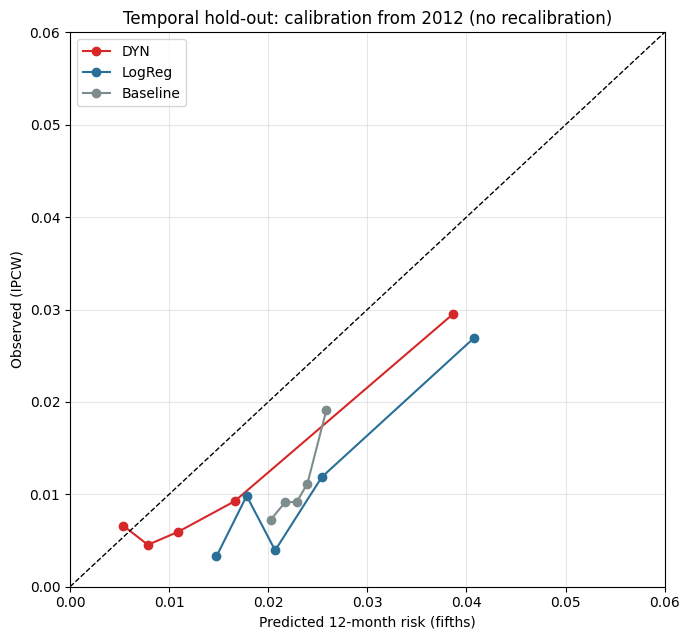

Temporal hold-out (develop < 2012, evaluate >= 2012), DYN: visit AUROC 0.711 (0.612 to 0.806), time-matched patient
AUROC 0.732 (0.648 to 0.809), O/E 0.703 (0.473 to 0.941), calibration slope 1.04. DYN - LogReg Visit AUROC: 0.027
(0.001 to 0.054) (superior); DYN - LogReg Time-matched patient AUROC: 0.027 (-0.003 to 0.058) (inconclusive); DYN -
Baseline Visit AUROC: 0.104 (-0.013 to 0.224) (inconclusive); DYN - Baseline Time-matched patient AUROC: 0.106 (0.002
to 0.216) (superior).


In [59]:
"""Temporal hold-out (TRIPOD+AI 12c, 16, 20c)."""
TEMPORAL_CUT = pd.Timestamp("2012-01-01")
TEMPORAL_MODELS = [MAIN_MODEL, LOGREG, BASELINE]
_cut = float((TEMPORAL_CUT - pd.Timestamp("1970-01-01")).days)
DEV = _LAND_T < _cut
VAL = ~DEV
_seen = T_ALL <= _cut - _LAND_T
_ydev = np.where((C_ALL == 1) & _seen & (T_ALL <= HORIZON_DAYS), 1.0,
                 np.where((np.minimum(T_ALL, _cut - _LAND_T) > HORIZON_DAYS)
                          | ((C_ALL >= 2) & _seen & (T_ALL <= HORIZON_DAYS)), 0.0, np.nan))
_ydev[np.isnan(Y_ALL) & (_ADMIN < HORIZON_DAYS)] = np.nan
_ydev[~DEV] = np.nan
A_DEV = {"D1": (D_ONSET * (INT_END <= _cut)).astype(np.float32), "D2": (D_COMP * (INT_END <= _cut)).astype(np.float32),
         "DT": np.clip((np.minimum(INT_END, _cut) - INT_START) / 365.25, 1e-6, None).astype(np.float32),
         "Y": _ydev, "LAB": ~np.isnan(_ydev), "USE": DEV}
dev_p, val_p = np.unique(PID_ALL[DEV]), np.unique(PID_ALL[VAL])
print(f"Development: {int(DEV.sum()):,} landmarks, {len(dev_p)} patients, {int(A_DEV['D1'][DEV].sum())} onsets seen "
      f"before {TEMPORAL_CUT.date()} | evaluation: {int(VAL.sum()):,} landmarks, {len(val_p)} patients, "
      f"{int(D_ONSET[VAL].sum())} onsets | in both periods: {len(np.intersect1d(dev_p, val_p))} patients")

# the development-period comparison of the inputs (item 20c)
_cmp_vars = ["age_at_record", "SLEDAI2_I", "score_n", "STERAVER_0", "AM_CLASS", "IS_CLASS", "FATIGUE", "FIBROMYALGIA",
             "SMOKER", "EDU_HIGHER", "VISIT_RATE_1Y", "YRS_IN_CLINIC"]
DEV_VS_VAL = pd.DataFrame({"Development (mean)": LAND_X.loc[DEV, _cmp_vars].astype(float).mean(),
                           "Evaluation (mean)": LAND_X.loc[VAL, _cmp_vars].astype(float).mean(),
                           "SMD": [_smd(LAND_X.loc[VAL, c].astype(float).values, LAND_X.loc[DEV, c].astype(float).values)
                                   for c in _cmp_vars]})
DEV_VS_VAL.index = [DISPLAY_NAMES.get(c, c) for c in DEV_VS_VAL.index]
DEV_VS_VAL.loc["12-month onset rate (resolved landmarks)"] = [np.nanmean(Y_ALL[DEV]), np.nanmean(Y_ALL[VAL]), np.nan]
display(DEV_VS_VAL.round(3))

TEMPORAL_PATH = f"temporal_state_{TAG}{'_smoke' if SMOKE else ''}.pkl"
TEMP = _load(TEMPORAL_PATH, {})
for m in TEMPORAL_MODELS:
    if m in TEMP:
        continue
    t0 = time.time()
    vrows = rows_of(val_p)
    if is_reg(m):
        cfg = model_grid(m)[pd.Series(BEST_CFG[m]).value_counts().index[0]]
        frows = rows_of(dev_p)
        prep_rows = frows[DEV[frows] & (A_DEV["LAB"][frows] if parse_model(m)["target"] == "BIN" else True)]
        eta, _ = fit_reg(m, cfg, prep_rows, frows, vrows, arrs=A_DEV)
    else:
        d_ = parse_model(m)
        st_, ln_ = grid_window(d_["lookback"])
        VX = GridPrep(grid_cols_of(m)).fit(np.flatnonzero(DEV)).transform(GRID_RAW)
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")(
            delayed(fit_grid)(SEQ_CFG, VX, st_, ln_, dev_p, SEED + 500 + 31 * s, val_p, d_["hazard"], False, None,
                              False, A_DEV) for s in range(SEQ_SEEDS_FINAL))
        z = np.zeros((N_LAND, 2)); cnt = np.zeros(N_LAND)
        for rows_, zz in res:
            z[rows_] += zz; cnt[rows_] += 1
        eta = z[vrows] / np.maximum(cnt[vrows], 1)[:, None]
    zf = np.full(N_LAND, np.nan); zf[vrows] = raw_logit(eta, H)
    zf[~VAL] = np.nan
    TEMP[m] = zf
    _save(TEMP, TEMPORAL_PATH)
    print(f"  {short_label(m)} fitted on the development period ({(time.time() - t0) / 60:.1f} min)")

_vr = VAL[_rows_h]
_rows_v, _y_v, _w_v = _rows_h[_vr], _y_h[_vr], _w_h[_vr]
_Wv = _BOTH[:, ROW_PIDX[_rows_v]] * _w_v[None, :]
_dtm = TM["main"]
_ent_val = np.asarray(_dtm["mat"] @ (~VAL).astype(float)).ravel() == 0          # every row of the entity is >= cut
_pm = _ent_val[_dtm["pc"]] & _ent_val[_dtm["pk"]]
_tm_den = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(_pm.sum()), (_dtm["ppc"][_pm], _dtm["ppk"][_pm])),
                                                  shape=(P_, P_)).toarray())


def temporal_metrics(z):
    zv = z[_rows_v]
    out = {"Visit AUROC": wauc(_y_v, zv, _Wv),
           "O/E": (_Wv @ _y_v) / (_Wv @ _expit(zv))}
    sl, ic = wcalibration(_y_v, zv, _w_v)
    out["Calibration slope"], out["Calibration intercept"] = np.array([sl]), np.array([ic])
    s = np.asarray(_dtm["mat"] @ np.nan_to_num(z)).ravel()
    a, b = s[_dtm["pc"][_pm]], s[_dtm["pk"][_pm]]
    K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (_dtm["ppc"][_pm], _dtm["ppk"][_pm])), shape=(P_, P_)).toarray()
    out["Time-matched patient AUROC"] = _pair_sum_fast(_BOTH, K) / _tm_den
    return out


_ff = lambda a: fmt(a[0], *np.nanpercentile(a[1:], [2.5, 97.5])) if len(a) > 1 else f"{a[0]:.3f}"
rows, TEMP_MET = [], {}
for m in TEMPORAL_MODELS:
    mt = temporal_metrics(TEMP[m])
    cv = [temporal_metrics(zpred(m, r)) for r in REPEATS]
    TEMP_MET[m] = mt
    row = {"Model": short_label(m)}
    for k_ in mt:
        row[f"{k_}: temporal"] = _ff(mt[k_])
        row[f"{k_}: CV, same landmarks"] = _ff(np.mean([c_[k_] for c_ in cv], 0))
    rows.append(row)
TEMPORAL = pd.DataFrame(rows).set_index("Model").T
print(f"Evaluation: {len(_rows_v):,} landmarks with a known 12-month status ({int(_y_v.sum())} onset landmarks); "
      f"time-matched: {len(np.unique(_dtm['pc'][_pm]))} onsets, {int(_pm.sum()):,} pairs")
display(TEMPORAL)
TEMPORAL.to_csv(f"tripod_temporal_{TAG}.csv")
rows = []
for a_, b_ in [(MAIN_MODEL, LOGREG), (MAIN_MODEL, BASELINE)]:
    for k_ in ["Visit AUROC", "Time-matched patient AUROC"]:
        dlt = TEMP_MET[a_][k_] - TEMP_MET[b_][k_]
        lo, hi = np.nanpercentile(dlt[1:], [2.5, 97.5])
        rows.append({"Comparison": f"{short_label(a_)} - {short_label(b_)}", "Metric": k_, "Difference (95% CI)":
                     fmt(dlt[0], lo, hi), "Verdict": verdict_superiority(lo, hi, EQUIV_MARGIN)})
TEMPORAL_CMP = pd.DataFrame(rows).set_index(["Comparison", "Metric"])
display(TEMPORAL_CMP)
TEMPORAL_CMP.to_csv(f"tripod_temporal_contrasts_{TAG}.csv")

# risk tiers in the evaluation period, the models' own risks
_y1v = (_y_v == 1).astype(np.float32)
rows = []
for m in TEMPORAL_MODELS:
    p_ = _expit(TEMP[m][_rows_v])
    for lo, hi, name in RISK_TIERS:
        inn = ((p_ >= lo) & (p_ < hi)).astype(np.float32)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits": f"{(_w_v @ inn) / _w_v.sum():.1%}",
                     "Mean predicted": f"{p_[inn > 0].mean():.3f}" if inn.any() else "-",
                     "Observed (IPCW)": _ff(_ratio(_Wv @ (_y1v * inn), _Wv @ inn)),
                     "Share of onsets": _ff(_ratio(_Wv @ (_y1v * inn), _Wv @ _y1v))})
TEMPORAL_TIERS = pd.DataFrame(rows).set_index(["Model", "Tier"])
display(TEMPORAL_TIERS)
TEMPORAL_TIERS.to_csv(f"tripod_temporal_tiers_{TAG}.csv")

fig, ax = plt.subplots(figsize=(7, 6.5))
for m in TEMPORAL_MODELS:
    p_ = _expit(TEMP[m][_rows_v])
    qs = np.quantile(p_, np.linspace(0, 1, 6))
    b_ = np.clip(np.searchsorted(qs, p_, side="right") - 1, 0, 4)
    pr = [p_[b_ == j].mean() for j in range(5)]
    ob = [np.sum(_w_v[b_ == j] * _y_v[b_ == j]) / np.sum(_w_v[b_ == j]) for j in range(5)]
    ax.plot(pr, ob, "o-", color=model_color(m), label=short_label(m))
_mx = 0.06
ax.plot([0, _mx], [0, _mx], "k--", lw=1); ax.set_xlim(0, _mx); ax.set_ylim(0, _mx)
ax.set_xlabel("Predicted 12-month risk (fifths)"); ax.set_ylabel("Observed (IPCW)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f"Temporal hold-out: calibration from {TEMPORAL_CUT.year} (no recalibration)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{TAG}_temporal_calibration.png", dpi=150, bbox_inches="tight"); plt.show()
_t = TEMP_MET[MAIN_MODEL]
TEMPORAL_SUMMARY = (f"Temporal hold-out (develop < {TEMPORAL_CUT.year}, evaluate >= {TEMPORAL_CUT.year}), "
                    f"{short_label(MAIN_MODEL)}: visit AUROC {_ff(_t['Visit AUROC'])}, time-matched patient AUROC "
                    f"{_ff(_t['Time-matched patient AUROC'])}, O/E {_ff(_t['O/E'])}, calibration slope "
                    f"{_t['Calibration slope'][0]:.2f}. " + "; ".join(
                        f"{i[0]} {i[1]}: {r_['Difference (95% CI)']} ({r_['Verdict']})"
                        for i, r_ in TEMPORAL_CMP.iterrows()) + ".")
print(textwrap.fill(TEMPORAL_SUMMARY, 118))

## 19.7 TRIPOD+AI checklist

Each item, whether it is reported, and where (N = notebook section; M = manuscript only). "Partly" means the
notebook gives what it can and the manuscript must complete it.

In [60]:
"""TRIPOD+AI checklist."""
_tm_t = _ff(TEMP_MET[MAIN_MODEL]["Time-matched patient AUROC"])
CHECKLIST = pd.DataFrame([
    ("1", "Title", "Identify as developing/evaluating a prediction model, target population, outcome", "M", "Manuscript"),
    ("2", "Abstract", "TRIPOD+AI for Abstracts", "M", "Manuscript"),
    ("3a", "Background", "Healthcare context, rationale, intended use", "Partly", "N1 (motivation); M"),
    ("3b", "Background", "Intended users and place in the care pathway", "Partly",
     "N13.5 (risk tiers: rheumatologist at a routine visit, to target vocational support); M"),
    ("3c", "Background", "Known health inequalities between groups", "M", "Manuscript (work disability by race, "
     "education, sex in SLE)"),
    ("4", "Objectives", "Objectives, development and/or evaluation", "Yes", "N0, N8 (objectives, hypotheses)"),
    ("5a", "Data", "Data sources, rationale, representativeness", "Partly", "N2, N19.1; M (single centre)"),
    ("5b", "Data", "Dates of data collection, follow-up end", "Yes", "N19.1"),
    ("6a", "Participants", "Setting, number and location of centres", "Partly", "N2, N19.1 (one centre); M"),
    ("6b", "Participants", "Eligibility criteria", "Yes", "N2, N4, N19.1 (flow)"),
    ("6c", "Participants", "Treatments received", "Yes", "N19.2 (Table 1: prednisone, antimalarial, immunosuppressants)"),
    ("7", "Data preparation", "Pre-processing, quality checks, consistency across groups", "Yes",
     "N11.3b, N11.4 (grid, preprocessing in training folds), N19.2 (missingness by group)"),
    ("8a", "Outcome", "Definition, horizon, how assessed, rationale", "Yes", "N2-N4"),
    ("8b", "Outcome", "Qualifications / demographics of outcome assessors", "M",
     "Manuscript (employment status recorded at clinic visits)"),
    ("8c", "Outcome", "Blinding of outcome assessment", "M", "Manuscript (not blinded: routine clinic data)"),
    ("9a", "Predictors", "Choice of initial predictors, pre-selection", "Partly",
     "N5 (update_v2's 27 + change variables); M (literature basis)"),
    ("9b", "Predictors", "Definition, how and when measured", "Yes", "N5, N11.3b (on or before the landmark only)"),
    ("9c", "Predictors", "Assessor qualifications / blinding", "M", "Manuscript"),
    ("10", "Sample size", "How the sample size was arrived at; justification", "Yes", "N19.3 (Riley criteria)"),
    ("11", "Missing data", "How handled; reasons for omitting", "Yes", "N11.4, N19.2"),
    ("12a", "Analysis", "How the data were used (development / evaluation), splitting", "Yes",
     "N8, N11.5 (5x5 patient-grouped CV), N19.6 (temporal hold-out)"),
    ("12b", "Analysis", "Predictor handling (functional form, rescaling)", "Yes", "N11.3b, N11.4"),
    ("12c", "Analysis", "Model type, building steps, tuning, internal validation", "Yes",
     f"N6, N11.5, N12; post-hoc selection over >40 versions disclosed (N0, N19.6)"),
    ("12d", "Analysis", "Heterogeneity across clusters", "Partly", "N13.6 (by era); single centre"),
    ("12e", "Analysis", "Performance measures and rationale", "Yes", "N9, N11.7, N11.8"),
    ("12f", "Analysis", "Model updating after evaluation", "Yes", "N7 (recalibration in each training fold)"),
    ("12g", "Analysis", "For evaluation: how predictions were calculated", "Yes", "N11 (code); N19.6"),
    ("13", "Class imbalance", "Methods and recalibration", "Yes",
     "No resampling or weighting; recalibration inside each training fold (N7)"),
    ("14", "Fairness", "Methods to address fairness", "Yes", "N19.4 (by sex, race, age, education)"),
    ("15", "Model output", "Output form, thresholds and how chosen", "Yes", "N9, N11.6, N13.5 (risk tiers)"),
    ("16", "Training vs evaluation", "Differences between development and evaluation data", "Yes", "N19.6"),
    ("17", "Ethics", "Ethics approval, consent", "M", "Manuscript"),
    ("18a", "Open science", "Funding", "M", "Manuscript"),
    ("18b", "Open science", "Conflicts of interest", "M", "Manuscript"),
    ("18c", "Open science", "Protocol", "M", "Manuscript (no published protocol: state it)"),
    ("18d", "Open science", "Registration", "M", "Manuscript (not registered: state it)"),
    ("18e", "Open science", "Data sharing", "M", "Manuscript"),
    ("18f", "Open science", "Code sharing", "Partly", "This notebook and build scripts; M (repository link)"),
    ("19", "Patient and public involvement", "Details or statement of none", "M", "Manuscript (none: state it)"),
    ("20a", "Participants", "Flow, numbers with / without the outcome, follow-up", "Yes", "N19.1"),
    ("20b", "Participants", "Characteristics, key dates, missing data", "Yes", "N19.1, N19.2"),
    ("20c", "Participants", "Evaluation vs development distributions", "Yes", "N19.6"),
    ("21", "Model development", "Participants and events in each analysis", "Yes", "N11.3, N19.1, N19.6"),
    ("22", "Model specification", "Full model to allow predictions; access restrictions", "Partly",
     "Code here; trained weights + preprocessing parameters to be released (M)"),
    ("23a", "Performance", "Performance with CIs, incl. key subgroups", "Yes",
     f"N13-N16, N19.4, N19.5; temporal time-matched AUROC {_tm_t}"),
    ("23b", "Performance", "Heterogeneity across clusters", "Partly", "N13.6 (era)"),
    ("24", "Model updating", "Results of updating", "Yes", "N13.3 (recalibrated CV); N19.6 (without updating)"),
    ("25", "Interpretation", "Overall interpretation incl. fairness", "Partly", "N17 (conclusions); M"),
    ("26", "Limitations", "Limitations, biases, generalisability", "Partly", "N10; M"),
    ("27a", "Usability", "Handling poor quality or unavailable inputs", "Yes",
     "N11.4 (median + missing indicator), N19.5 (new patient: fewer grid points, change inputs 0)"),
    ("27b", "Usability", "User interaction / expertise needed", "M", "Manuscript (no user input beyond routine data)"),
    ("27c", "Usability", "Next steps, applicability, generalisability", "M", "Manuscript (external validation)"),
], columns=["Item", "Section", "Requirement", "Reported", "Where"]).set_index("Item")
display(CHECKLIST)
CHECKLIST.to_csv(f"tripod_ai_checklist_{TAG}.csv")
print(f"Reported in the notebook: {int((CHECKLIST['Reported'] == 'Yes').sum())} items; partly: "
      f"{int((CHECKLIST['Reported'] == 'Partly').sum())}; manuscript only: {int((CHECKLIST['Reported'] == 'M').sum())}.")
OBJ_CONCLUSIONS["TRIPOD+AI"] = TEMPORAL_SUMMARY

,Section,Requirement,Reported,Where
Item,,,,
1,Title,Identify as developing/evaluating a prediction...,M,Manuscript
2,Abstract,TRIPOD+AI for Abstracts,M,Manuscript
3a,Background,"Healthcare context, rationale, intended use",Partly,N1 (motivation); M
3b,Background,Intended users and place in the care pathway,Partly,N13.5 (risk tiers: rheumatologist at a routine...
3c,Background,Known health inequalities between groups,M,"Manuscript (work disability by race, education..."
4,Objectives,"Objectives, development and/or evaluation",Yes,"N0, N8 (objectives, hypotheses)"
5a,Data,"Data sources, rationale, representativeness",Partly,"N2, N19.1; M (single centre)"
5b,Data,"Dates of data collection, follow-up end",Yes,N19.1
6a,Participants,"Setting, number and location of centres",Partly,"N2, N19.1 (one centre); M"


Reported in the notebook: 26 items; partly: 11; manuscript only: 15.
